# Livrable 3 : génération automatique de légendes d'images

> **Améliorations du modèle, à la fin de la partie B :** la section [12 bis](#s12bis) (diagnostic du surapprentissage, recherche par grille de 10 réglages, entraînement final avec le meilleur réglage) et la section [12 ter](#s12ter) (SCST, qui optimise directement la qualité des phrases, avec la correction des phrases coupées). La section 13.6 ajoute deux règles d'écriture (pas de répétition, pas de phrase inachevée).

Le projet Leyenda doit rendre exploitable un fonds d'images numérisées : reconnaître les photographies parmi les autres documents (livrable 1), les débarrasser de leur bruit (livrable 2), puis les décrire par une phrase, pour qu'on puisse les retrouver par une simple recherche en texte (livrable 3). Ce notebook est le livrable 3 complet. Il apprend à un réseau de neurones à écrire une légende en anglais pour une photo, à partir du jeu de données **MS COCO 2014**. Le **pipeline complet du projet**, où une photo importée traverse les trois livrables l'un après l'autre, est dans un notebook séparé, `Pipeline_Leyenda.ipynb` (voir la section 17).

Le travail a été réparti en trois parties, présentées dans l'ordre où elles s'enchaînent.

* La **partie A** prépare les données : elle charge et explore COCO (123 287 images, 616 767 légendes), le découpe en ensembles d'entraînement, de validation et de test, transforme les légendes en suites de nombres et fait passer chaque image une fois dans le réseau convolutif InceptionV3, dont la sortie est enregistrée sur le Drive (sections 4 à 9, livraison et tests unitaires).
* La **partie B** construit et entraîne le modèle : un encodeur qui reçoit les caractéristiques d'InceptionV3, une attention qui choisit les zones de l'image à regarder, et un décodeur LSTM qui écrit la légende mot par mot (sections 10 à 12).
* La **partie C** se sert du modèle entraîné : elle règle la façon d'écrire les légendes, évalue le modèle sur 5 000 images qu'il n'a jamais vues, vérifie la chaîne par des tests et estime les temps de traitement (sections 13 à 16).
* La **section 17** explique comment le notebook séparé `Pipeline_Leyenda.ipynb` assemble tout le projet, à partir du modèle et de la façon d'écrire retenus ici.

### Comment lire ce notebook

Chaque section suit le même ordre : un texte explique ce que l'on va faire et pourquoi, la cellule de code le fait, puis un texte sous le résultat explique ce qu'il faut en retenir, avec les chiffres obtenus. À la fin de chaque partie, une section **« Les choix de la partie, et pourquoi »** reprend chaque décision importante : ce qui a été choisi, pourquoi, ce qui a été écarté, et la limite de ce choix. Un chronomètre affiche sous chaque cellule longue le temps qu'elle a pris, et la conclusion récapitule le temps de chaque partie.

### Petit lexique

* **Réseau de neurones** : un programme qui apprend à partir d'exemples, en ajustant des millions de nombres (ses *poids*) pour que ses réponses se rapprochent des bonnes réponses.
* **Réseau convolutif (CNN)** : un réseau de neurones spécialisé dans les images, qui repère des motifs (contours, textures, puis objets) en balayant l'image. **InceptionV3** en est un, déjà entraîné par Google sur 1,3 million d'images.
* **Caractéristiques** : le résumé numérique qu'un CNN fait d'une image. Ici, 64 régions de l'image décrites chacune par 2 048 nombres.
* **LSTM** : un réseau *récurrent*, qui lit ou écrit une séquence élément par élément en gardant une mémoire de ce qui précède. Ici, il écrit la légende mot par mot.
* **Attention** : un mécanisme qui, avant chaque mot, choisit sur quelles régions de l'image le modèle se concentre.
* **Embedding** : la transformation d'un mot en un vecteur de nombres, appris pendant l'entraînement, où les mots de sens proche finissent par se ressembler.
* **Entraînement, validation, test** : trois ensembles d'images séparés. Le modèle apprend sur l'entraînement, on règle les choix sur la validation, et le test ne sert qu'une fois, à la fin, à mesurer honnêtement le résultat.
* **Époque** : un passage complet sur toutes les images d'entraînement.
* **Perte** : le nombre que l'entraînement cherche à faire baisser ; il mesure à quel point le modèle se trompe.
* **Surapprentissage** : quand le modèle apprend ses exemples par cœur au lieu de règles générales ; il progresse alors sur l'entraînement mais plus sur la validation.
* **Décodage glouton et recherche par faisceau** : deux façons d'écrire la phrase, en prenant à chaque pas le mot le plus probable (glouton) ou en gardant plusieurs débuts de phrase en concurrence (faisceau).
* **BLEU, CIDEr** : des scores qui comparent une légende produite aux légendes écrites par des humains pour la même image ; CIDEr est la mesure de référence sur COCO.
* **PSNR** : une mesure de ressemblance entre une image nettoyée et l'image d'origine, en décibels ; plus elle est haute, mieux c'est.
* **Transfert d'apprentissage** : réutiliser un réseau déjà entraîné sur d'autres images, au lieu de partir de zéro.

## Sommaire

* Partie A, données : [4. Environnement](#s4), [5. Chargement et exploration](#s5), [6. Découpage](#s6), [7. Prétraitement du texte](#s7), [8. Prétraitement des images et CNN](#s8), [9. Pipeline TensorFlow](#s9), [Livraison](#livraison), [Tests unitaires](#s15), [Les choix de la partie A](#choixA), [Bilan](#bilan)
* Partie B, modèle : [10 à 12. Architecture, encodeur, attention, décodeur et entraînement](#s10), [12 bis. Hyperparamètres et surapprentissage](#s12bis), [12 ter. SCST](#s12ter), [Les choix de la partie B](#choixB)
* Partie C, évaluation : [Mise en place](#miseenplace), [13. Génération des légendes](#s13), [14. Évaluation sur le test](#s14), [15. Tests fonctionnels](#s15c), [16. Déploiement](#s16), [Les choix de la partie C](#choixC)
* [17. Le pipeline complet, dans un notebook séparé](#s17)
* [18. Conclusion](#s18)

> **Exécution.** Sur Colab, choisir un GPU T4 (*Exécution*, *Modifier le type d'exécution*), puis *Exécution*, *Tout exécuter*. Le notebook lit et écrit dans le dossier `Projet_Leyenda_L3` de Mon Drive. Si le paquet de données de la partie A est déjà sur le Drive, la partie A le réutilise ; si le modèle de la partie B est déjà entraîné, il est simplement rechargé. La recherche d'hyperparamètres (section 12 bis) prend environ 50 minutes, puis l'entraînement final du modèle optimisé environ 1 h 30 ; chaque étape est enregistrée sur le Drive et n'est faite qu'une fois. Le SCST corrigé (section 12 ter) prend environ 10 minutes.
>
> **Si Colab s'arrête en cours de route**, se reconnecter et relancer *Tout exécuter* : la partie A réutilise son paquet, la partie B reprend à sa dernière époque terminée et la partie C relit les résultats déjà calculés. La section « Reprise après une coupure de Colab », au début de la partie C, donne le détail.

### Le chronomètre

La cellule suivante installe un chronomètre. Il mesure le temps de chaque cellule et l'affiche sous celles qui prennent plus d'une seconde ; il additionne aussi le temps passé dans chaque partie, pour le bilan de la conclusion. Ces temps dépendent de la machine et de ce qui est déjà enregistré sur le Drive : une partie dont les résultats sont relus va beaucoup plus vite que la première fois.

In [7]:
# Chronomètre : durée de chaque cellule longue et de chaque partie du notebook
import time
from IPython import get_ipython

CHRONO = {"debut": None, "partie": "Introduction", "durees": {}}


def chrono_partie(nom):
    """Indique au chronomètre la partie du notebook qui commence."""
    CHRONO["partie"] = nom


def duree_lisible(secondes):
    return f"{secondes:.1f} s" if secondes < 60 else f"{int(secondes // 60)} min {int(secondes % 60):02d} s"


def _avant_cellule(info=None):
    CHRONO["debut"] = time.perf_counter()


def _apres_cellule(result=None):
    if CHRONO["debut"] is None:
        return
    duree = time.perf_counter() - CHRONO["debut"]
    CHRONO["durees"][CHRONO["partie"]] = CHRONO["durees"].get(CHRONO["partie"], 0.0) + duree
    if duree >= 1:
        print(f"Durée de la cellule : {duree_lisible(duree)}")


ip = get_ipython()
if ip is not None:
    for evenement, fonction in (("pre_run_cell", _avant_cellule), ("post_run_cell", _apres_cellule)):
        for f in list(ip.events.callbacks[evenement]):
            if getattr(f, "__name__", "") == fonction.__name__:
                ip.events.unregister(evenement, f)
        ip.events.register(evenement, fonction)
print("Chronomètre en marche : la durée s'affiche sous chaque cellule qui prend plus d'une seconde.")

Chronomètre en marche : la durée s'affiche sous chaque cellule qui prend plus d'une seconde.


### Le projet en une image

La figure suivante situe le livrable 3 dans le projet. En haut, le trajet d'une image dans la chaîne de traitement : le livrable 1 trie, le livrable 2 nettoie, le livrable 3 décrit. En bas, la façon dont le livrable 3 est construit dans ce notebook : la partie A prépare les données, la partie B entraîne le modèle, la partie C l'évalue.

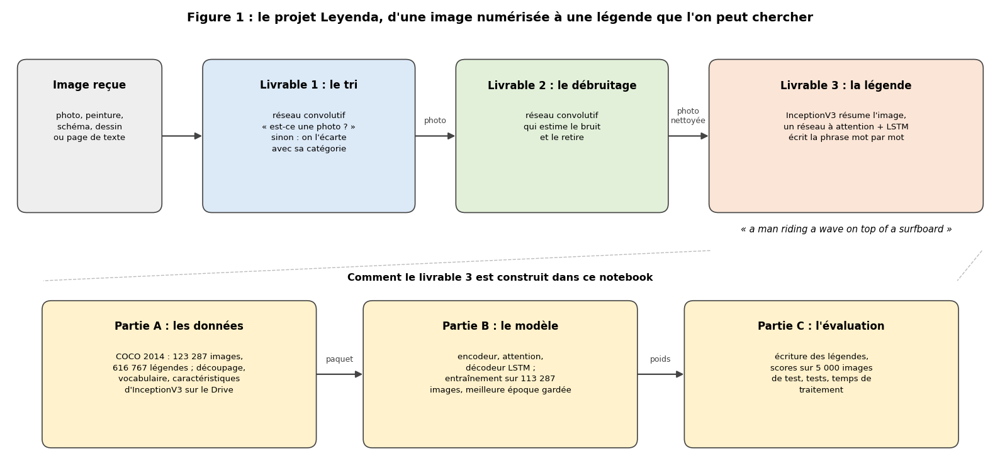

In [8]:
# Vue d'ensemble du projet : les trois livrables et les trois parties du livrable 3
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch


def boite(ax, x, y, l, h, titre, texte, couleur):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0.02,rounding_size=0.15", fc=couleur, ec="#444444", lw=1.2))
    ax.text(x + l / 2, y + h - 0.32, titre, ha="center", va="top", fontsize=12, fontweight="bold")
    ax.text(x + l / 2, y + h - 0.85, texte, ha="center", va="top", fontsize=9.5, linespacing=1.45)


def fleche(ax, x1, y1, x2, y2, texte=""):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#444444", lw=1.6, mutation_scale=16))
    if texte:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.18, texte, ha="center", va="bottom", fontsize=9, color="#444444")


fig, ax = plt.subplots(figsize=(16, 7.6))
ax.set_xlim(0, 16); ax.set_ylim(0, 7.6); ax.axis("off")
ax.text(8, 7.35, "Figure 1 : le projet Leyenda, d'une image numérisée à une légende que l'on peut chercher", ha="center", fontsize=14, fontweight="bold")
boite(ax, 0.2, 4.2, 2.3, 2.5, "Image reçue", "photo, peinture,\nschéma, dessin\nou page de texte", "#EEEEEE")
boite(ax, 3.2, 4.2, 3.4, 2.5, "Livrable 1 : le tri", "réseau convolutif\n« est-ce une photo ? »\nsinon : on l'écarte\navec sa catégorie", "#DCE9F7")
boite(ax, 7.3, 4.2, 3.4, 2.5, "Livrable 2 : le débruitage", "réseau convolutif\nqui estime le bruit\net le retire", "#E2F0D9")
boite(ax, 11.4, 4.2, 4.4, 2.5, "Livrable 3 : la légende", "InceptionV3 résume l'image,\nun réseau à attention + LSTM\nécrit la phrase mot par mot", "#FBE5D6")
fleche(ax, 2.5, 5.45, 3.2, 5.45)
fleche(ax, 6.6, 5.45, 7.3, 5.45, "photo")
fleche(ax, 10.7, 5.45, 11.4, 5.45, "photo\nnettoyée")
ax.text(13.6, 3.85, "« a man riding a wave on top of a surfboard »", ha="center", fontsize=10.5, style="italic")
# Les trois parties du livrable 3
ax.plot([11.4, 0.6], [3.55, 3.05], color="#BBBBBB", lw=1, ls="--")
ax.plot([15.8, 15.4], [3.55, 3.05], color="#BBBBBB", lw=1, ls="--")
ax.text(8, 3.05, "Comment le livrable 3 est construit dans ce notebook", ha="center", fontsize=11.5, fontweight="bold")
boite(ax, 0.6, 0.3, 4.4, 2.4, "Partie A : les données", "COCO 2014 : 123 287 images,\n616 767 légendes ; découpage,\nvocabulaire, caractéristiques\nd'InceptionV3 sur le Drive", "#FFF2CC")
boite(ax, 5.8, 0.3, 4.4, 2.4, "Partie B : le modèle", "encodeur, attention,\ndécodeur LSTM ;\nentraînement sur 113 287\nimages, meilleure époque gardée", "#FFF2CC")
boite(ax, 11.0, 0.3, 4.4, 2.4, "Partie C : l'évaluation", "écriture des légendes,\nscores sur 5 000 images\nde test, tests, temps de\ntraitement", "#FFF2CC")
fleche(ax, 5.0, 1.5, 5.8, 1.5, "paquet")
fleche(ax, 10.2, 1.5, 11.0, 1.5, "poids")
plt.tight_layout(); plt.show()

---
# Partie A : données et prétraitement

La partie A prépare **tout ce dont les parties B et C ont besoin** et l'enregistre sur le Google Drive, dans un « paquet de données » (dossier `Projet_Leyenda_L3/donnees_A`). Les autres parties n'ont ensuite ni à retélécharger COCO, ni à refaire le prétraitement. Ce qui suit a été exécuté en mode rapide : le paquet existait déjà sur le Drive, si bien que seules les légendes ont été retéléchargées, et que l'extraction des caractéristiques (environ 15 minutes sur un GPU T4 lors de la première exécution) n'a pas été refaite.

<a id="s4"></a>
## 4. Mise en place de l'environnement

On prépare d'abord l'environnement de travail : les bibliothèques, la graine aléatoire, le Google Drive et les paramètres. Tous les choix qui touchent aux données sont rassemblés dans une seule cellule de paramètres : ils font partie du « contrat » entre les trois parties, et les modifier oblige à refaire le paquet.

Toutes les bibliothèques utilisées sont déjà installées sur Colab : NumPy et pandas pour les tableaux, Matplotlib pour les figures, Pillow pour lire les images, TensorFlow et Keras pour le CNN et le pipeline. La graine 42 fixe le hasard de Python, NumPy et TensorFlow, ce qui rend le découpage et le mélange des données reproductibles. Les versions sont relevées : elles sont écrites dans le paquet, pour que les parties B et C sachent avec quoi il a été produit.

In [9]:
if "chrono_partie" in globals():
    chrono_partie("A. Données et prétraitement")                       # chronomètre : début de la partie
# Bibliothèques, graine aléatoire et GPU
import os, io, re, sys, json, time, shutil, hashlib, zipfile, platform, subprocess, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
import keras
from keras.applications import inception_v3

SEED = 42
keras.utils.set_random_seed(SEED)                  # Python, NumPy et TensorFlow
GPU = tf.config.list_physical_devices("GPU")
fr = lambda n: f"{n:,}".replace(",", " ")           # 123287 -> "123 287"
VERSIONS = {"python": platform.python_version(), "tensorflow": tf.__version__, "keras": keras.__version__,
            "numpy": np.__version__}
print(VERSIONS)
print("GPU :", GPU[0].name if GPU else "aucun (suffisant si le paquet existe déjà sur le Drive)")

{'python': '3.13.15', 'tensorflow': '2.21.0', 'keras': '3.13.2', 'numpy': '2.1.3'}
GPU : /physical_device:GPU:0


Le Drive sert de lieu de rendez-vous entre les trois parties. Tout ce que produit ce notebook va dans `MyDrive/Projet_Leyenda_L3/donnees_A` : les fichiers de données et les figures. Les images de COCO, elles, restent sur le disque temporaire de Colab (`/content/coco`) : elles sont trop lourdes pour le Drive et ne servent plus une fois les caractéristiques extraites.

Si un paquet complet existe déjà (fichier `manifeste.json` marqué « complet »), le notebook passe en **mode rapide** : il ne retélécharge que les légendes, vérifie que tout est identique, et télécharge une par une les quelques images qui servent aux figures.

In [10]:
# Google Drive : dossier partagé du projet, paquet de la partie A, données temporaires
NOM_PROJET = "Projet_Leyenda_L3"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    RACINE = Path("/content/drive/MyDrive") / NOM_PROJET
    DRIVE_OK = True
except Exception as erreur:                                      # hors Colab, ou Drive refusé
    print(f"Drive non disponible ({erreur}) : le paquet est écrit localement et sera perdu à la fin de la session.")
    RACINE = (Path("/content") if Path("/content").exists() else Path.cwd()) / NOM_PROJET
    DRIVE_OK = False
PAQUET = RACINE / "donnees_A"                                     # ce que la partie A livre à B et C
FIGURES = PAQUET / "figures"
DOSSIERCOCO = Path("/content/coco") if Path("/content").exists() else Path.cwd() / "coco"   # temporaire
for d in (PAQUET, FIGURES, DOSSIERCOCO):
    d.mkdir(parents=True, exist_ok=True)


def manifeste_complet():
    try:
        return json.load(open(PAQUET / "manifeste.json")).get("etat") == "complet"
    except (OSError, ValueError):
        return False


MODE_RAPIDE = manifeste_complet()
print("Paquet de la partie A :", PAQUET)
print("Données temporaires   :", DOSSIERCOCO)
print("Mode rapide (paquet complet trouvé) :", "oui" if MODE_RAPIDE else "non, préparation complète")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Paquet de la partie A : /content/drive/MyDrive/Projet_Leyenda_L3/donnees_A
Données temporaires   : /content/coco
Mode rapide (paquet complet trouvé) : non, préparation complète
Durée de la cellule : 1.1 s


Les paramètres suivent les choix habituels des publications sur COCO. Le découpage reprend les tailles du découpage « Karpathy » : 5 000 images de validation et 5 000 de test, tout le reste pour l'entraînement. On garde cinq légendes par image pour l'entraînement (toutes servent de références à l'évaluation), un mot n'entre dans le vocabulaire que s'il apparaît au moins cinq fois dans le train, et les légendes sont coupées au 95e centile de leur longueur. Les images sont mises à 299 × 299, la taille d'entrée d'InceptionV3.

In [11]:
# Paramètres de la partie A (ils font partie du contrat avec les parties B et C)
NB_VAL = 5000             # images de validation (comme le découpage Karpathy)
NB_TEST = 5000            # images de test
LEGENDES_PAR_IMAGE = 5    # légendes gardées par image pour l'entraînement
SEUIL_FREQUENCE = 5       # occurrences minimales d'un mot du train pour entrer dans le vocabulaire
CENTILE_LONGUEUR = 95     # longueur maximale des légendes = 95e centile des longueurs du train
TAILLE_IMAGE = 299        # entrée d'InceptionV3
BATCH_IMAGES = 32         # images par lot dans le pipeline (32 images x 5 légendes = 160 phrases)
SUPPRIMER_ARCHIVES = True # supprime chaque .zip du disque de Colab une fois extrait
AUTORISER_CPU = False     # False : refuse d'extraire les caractéristiques sans GPU (plus de 8 h sur CPU)

<a id="s5"></a>
## 5. Chargement et exploration des données

**MS COCO 2014** (Common Objects in Context) contient des photos de la vie courante (personnes, animaux, véhicules, scènes d'intérieur et d'extérieur), chacune décrite par au moins cinq phrases en anglais écrites par des annotateurs différents. Le jeu se compose de deux archives d'images, `train2014` (82 783 images) et `val2014` (40 504 images), et d'une archive d'annotations qui contient les légendes.

Les archives sont téléchargées depuis le site officiel. Le téléchargement est robuste : une archive interrompue reprend là où elle s'est arrêtée, une archive corrompue est détectée et téléchargée de nouveau, et une archive déjà présente dans le dossier du projet sur le Drive est utilisée directement. Avant de commencer, le notebook vérifie qu'il reste assez de place sur le disque, en tenant compte des deux moments les plus chargés : l'extraction de la plus grosse archive, puis l'écriture des caractéristiques.

In [12]:
# Téléchargement robuste des archives COCO 2014, contrôle de l'espace disque et extraction des images
SOURCES = {"annotations_trainval2014.zip": "http://images.cocodataset.org/annotations/annotations_trainval2014.zip",
           "val2014.zip": "http://images.cocodataset.org/zips/val2014.zip",
           "train2014.zip": "http://images.cocodataset.org/zips/train2014.zip"}
NB_ATTENDU = {"val2014": 40504, "train2014": 82783}
TAILLE_GO = {"val2014": (6.6, 6.5), "train2014": (13.5, 13.4)}       # (archive, images extraites), en Go
PARTIES = ["val2014", "train2014"]


def espace_libre_go():
    return shutil.disk_usage(DOSSIERCOCO).free / 1e9


def verifier_espace():
    """S'arrête avec un message clair s'il manque de la place, AVANT un long téléchargement."""
    images, archives = 0.0, []
    for p in PARTIES:
        if not (DOSSIERCOCO / f"{p}.extraction_terminee").exists():
            images += TAILLE_GO[p][1]
            if not ((RACINE / f"{p}.zip").exists() or (DOSSIERCOCO / f"{p}.zip").exists()):
                archives.append(TAILLE_GO[p][0])
    caract = 123287 * 8 * 8 * 2048 / 1e9                              # caractéristiques sur 8 bits (section 8)
    if SUPPRIMER_ARCHIVES:                                           # une seule archive à la fois sur le disque
        besoin = max(images + (max(archives) if archives else 0.0), images + caract) + 2
    else:
        besoin = images + sum(archives) + caract + 2
    libre = espace_libre_go()
    print(f"Espace libre sur le disque de Colab : {libre:.0f} Go ; besoin estimé : {besoin:.0f} Go")
    if libre < besoin:
        raise RuntimeError(f"Espace disque insuffisant ({libre:.0f} Go libres, environ {besoin:.0f} Go nécessaires). "
                           "Menu ▾ en haut à droite > Déconnecter et supprimer l'environnement d'exécution, puis relancer.")


def archive_valide(chemin):
    try:
        with zipfile.ZipFile(chemin) as z:
            return len(z.namelist()) > 0
    except (zipfile.BadZipFile, OSError):
        return False


def obtenir(nom):
    for d in (RACINE, DOSSIERCOCO):
        if (d / nom).exists() and archive_valide(d / nom):
            return d / nom
    partiel = DOSSIERCOCO / (nom + ".part")
    for tentative in (1, 2):
        print(f"Téléchargement de {nom} (tentative {tentative})...")
        r = subprocess.run(["wget", "-q", "-c", "-O", str(partiel), SOURCES[nom]])
        if r.returncode == 0 and archive_valide(partiel):
            partiel.rename(DOSSIERCOCO / nom)
            return DOSSIERCOCO / nom
        if r.returncode == 0 and partiel.exists() and not archive_valide(partiel):
            partiel.unlink()                                          # complète mais illisible : on recommence
    raise RuntimeError(f"Impossible d'obtenir {nom} ({SOURCES[nom]}). Vérifier la connexion, ou déposer l'archive "
                       f"dans {RACINE} puis relancer.")


def images_extraites(partie):
    dossier, marque = DOSSIERCOCO / partie, DOSSIERCOCO / f"{partie}.extraction_terminee"
    if not (marque.exists() and dossier.exists()):
        subprocess.run(["unzip", "-q", "-o", str(obtenir(f"{partie}.zip")), "-d", str(DOSSIERCOCO)], check=True)
        n = len(os.listdir(dossier))
        if n < NB_ATTENDU[partie]:
            raise RuntimeError(f"{partie} : {n} images extraites sur {NB_ATTENDU[partie]} attendues.")
        marque.write_text(str(n))                                     # écrit seulement si tout est extrait
        archive = DOSSIERCOCO / f"{partie}.zip"
        if SUPPRIMER_ARCHIVES and archive.exists():
            archive.unlink()
        print(f"{partie} : {n} images extraites ({espace_libre_go():.0f} Go libres).")
    return dossier


def fichier_legendes(partie):
    chemin = DOSSIERCOCO / "annotations" / f"captions_{partie}.json"
    if not chemin.exists():
        with zipfile.ZipFile(obtenir("annotations_trainval2014.zip")) as z:
            z.extract(f"annotations/captions_{partie}.json", DOSSIERCOCO)
    return chemin


FICHIER_LEGENDES_VAL, FICHIER_LEGENDES_TRAIN = fichier_legendes("val2014"), fichier_legendes("train2014")
if MODE_RAPIDE:
    print("Paquet complet sur le Drive : seules les légendes sont téléchargées.")
    DOSSIER_VAL, DOSSIER_TRAIN = DOSSIERCOCO / "val2014", DOSSIERCOCO / "train2014"
else:
    if not GPU and not AUTORISER_CPU:
        raise RuntimeError("Aucun GPU : l'extraction des caractéristiques prendrait plus de 8 h. Menu ▾ > Modifier "
                           "le type d'exécution > GPU T4, puis relancer. Si Colab refuse le GPU, réessayer plus tard.")
    verifier_espace()
    DOSSIER_VAL, DOSSIER_TRAIN = images_extraites("val2014"), images_extraites("train2014")
print(f"Espace libre restant : {espace_libre_go():.0f} Go")

Téléchargement de annotations_trainval2014.zip (tentative 1)...
Espace libre sur le disque de Colab : 75 Go ; besoin estimé : 38 Go
Téléchargement de val2014.zip (tentative 1)...
val2014 : 40504 images extraites (68 Go libres).
Téléchargement de train2014.zip (tentative 1)...
train2014 : 82783 images extraites (54 Go libres).
Espace libre restant : 54 Go
Durée de la cellule : 21 min 56 s


Les annotations sont des fichiers JSON : une liste d'images (identifiant, nom de fichier) et une liste de légendes, chacune rattachée à l'identifiant de son image. On regroupe les légendes par image et on ne garde que les images qui ont au moins cinq légendes et dont le fichier existe bien. Le tableau résume ce que contient chaque archive.

In [13]:
# Lecture des annotations : légendes regroupées par image, images utilisables
PRESENTES = set(json.load(open(PAQUET / "images_utilisables.json"))) if MODE_RAPIDE else None


def lire_annotations(fichier, dossier):
    ann = json.load(open(fichier))
    fichiers = {im["id"]: dossier / im["file_name"] for im in ann["images"]}
    legendes = collections.defaultdict(list)
    for a in ann["annotations"]:
        legendes[a["image_id"]].append(a["caption"].strip())
    present = (lambda c: c.exists()) if PRESENTES is None else (lambda c: str(c) in PRESENTES)
    valides = sorted(i for i in fichiers if len(legendes[i]) >= LEGENDES_PAR_IMAGE and present(fichiers[i]))
    return fichiers, legendes, valides, len(ann["annotations"])


TABLES, resume = {}, []
for partie, fichier, dossier in (("train2014", FICHIER_LEGENDES_TRAIN, DOSSIER_TRAIN),
                                 ("val2014", FICHIER_LEGENDES_VAL, DOSSIER_VAL)):
    fichiers, legendes, valides, nb_leg = lire_annotations(fichier, dossier)
    TABLES[partie] = (fichiers, legendes, valides)
    resume.append({"archive": partie, "images": len(fichiers), "légendes": nb_leg,
                   "légendes par image (moyenne)": nb_leg / len(fichiers), "images utilisables": len(valides)})
tab_donnees = pd.DataFrame(resume).set_index("archive")
tab_donnees.loc["total"] = tab_donnees.sum()
tab_donnees.loc["total", "légendes par image (moyenne)"] = tab_donnees.loc["total", "légendes"] / tab_donnees.loc["total", "images"]
print("Contenu de COCO 2014")
display(tab_donnees.style.format({"images": "{:,.0f}", "légendes": "{:,.0f}", "images utilisables": "{:,.0f}",
                                  "légendes par image (moyenne)": "{:.2f}"}))

Contenu de COCO 2014


,images,légendes,légendes par image (moyenne),images utilisables
archive,,,,
train2014,"82,783","414,113",5.00,"82,783"
val2014,"40,504","202,654",5.00,"40,504"
total,"123,287","616,767",5.00,"123,287"


Durée de la cellule : 4.6 s


COCO 2014 compte **123 287 images et 616 767 légendes** : 82 783 images et 414 113 légendes dans `train2014`, 40 504 images et 202 654 légendes dans `val2014`. La moyenne est de 5,00 légendes par image : presque toutes les images en ont exactement cinq, quelques-unes six ou sept. Toutes ont au moins cinq légendes et un fichier présent, si bien que **les 123 287 images sont utilisables** : c'est bien l'ensemble du dataset qui sera exploité. Le train officiel est deux fois plus gros que la validation officielle ; la section 6 explique comment on redistribue ces images.

Avant de prétraiter quoi que ce soit, on regarde quelques exemples, pour se faire une idée du type de photos et du style des légendes.

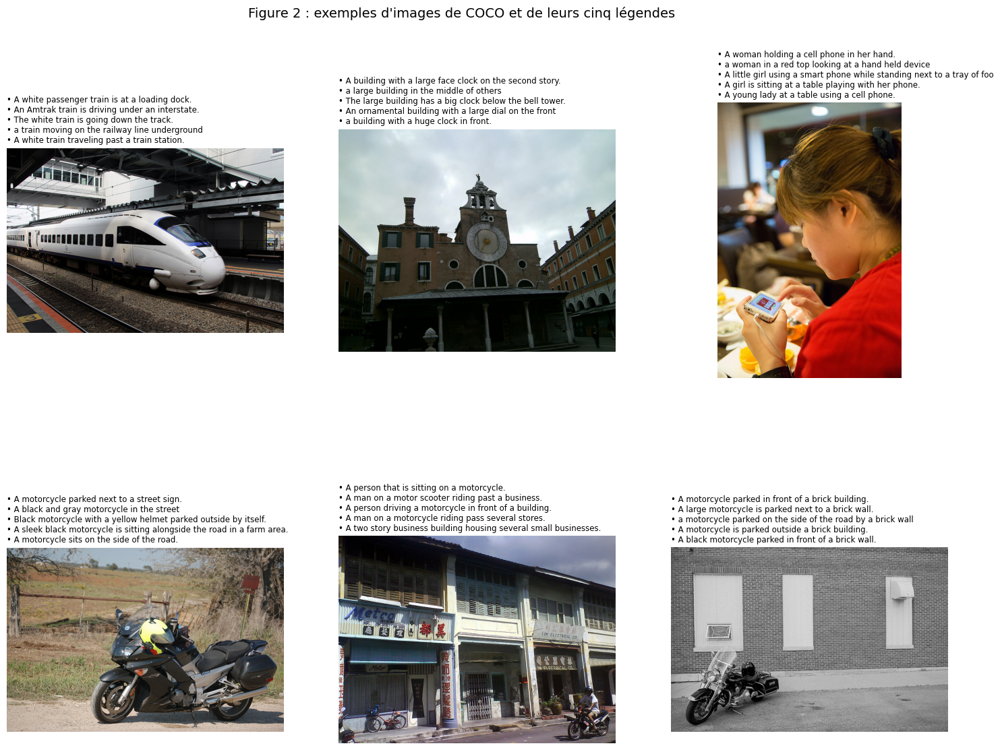

Durée de la cellule : 2.4 s


In [14]:
# Quelques images de COCO avec leurs légendes
import urllib.request
def assurer(chemin):
    """Télécharge une image isolée depuis le site de COCO si elle n'est pas sur le disque (mode rapide)."""
    p = Path(chemin)
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"http://images.cocodataset.org/{p.parent.name}/{p.name}", str(p) + ".part")
        os.replace(str(p) + ".part", p)
    return str(p)


rng_ex = np.random.default_rng(SEED + 7)
exemples = [("train2014", int(i)) for i in rng_ex.choice(TABLES["train2014"][2], 6, replace=False)]
fig, axes = plt.subplots(2, 3, figsize=(18, 13), gridspec_kw={"hspace": 0.45})
for ax, (partie, i) in zip(axes.ravel(), exemples):
    ax.imshow(Image.open(assurer(TABLES[partie][0][i])).convert("RGB")); ax.axis("off")
    ax.set_title("\n".join(f"• {l[:70]}" for l in TABLES[partie][1][i][:5]), fontsize=8.5, loc="left")
plt.suptitle("Figure 2 : exemples d'images de COCO et de leurs cinq légendes", fontsize=14, y=0.99)
plt.savefig(FIGURES / "01_exemples_coco.png", dpi=90, bbox_inches="tight"); plt.show()

Les cinq légendes d'une même image décrivent la même scène avec des mots et des niveaux de détail différents : l'une nomme seulement l'objet principal, une autre ajoute le lieu ou l'action. Cette variété est précieuse : elle montre au modèle plusieurs façons correctes de décrire une image, et elle explique pourquoi l'évaluation compare chaque légende générée à **toutes** les références. On remarque aussi que les phrases sont courtes, au présent, presque toujours de la forme « un sujet + une action + un lieu », et qu'elles commencent très souvent par « a » ou « an ». Les majuscules et la ponctuation varient d'un annotateur à l'autre : c'est ce que la normalisation de la section 7 uniformise.

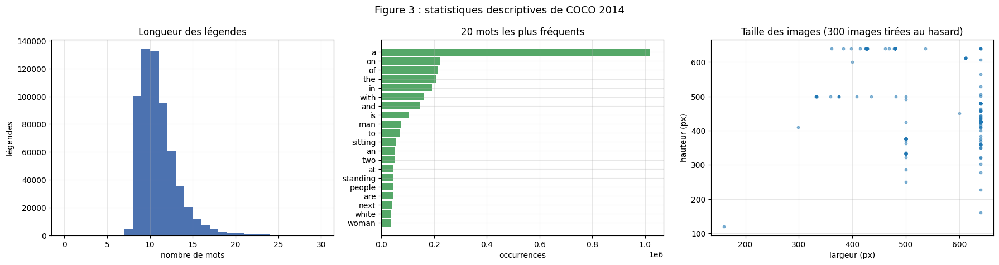

Légendes : 616 767 ; longueur moyenne 10.5 mots, médiane 10, 95e centile 15, maximum 50
Images : largeur 160 à 640 px, hauteur 120 à 640 px ; 77% ont 640 px sur leur plus grand côté
Durée de la cellule : 9.1 s


In [15]:
# Longueur des légendes, mots les plus fréquents et taille des images (tout COCO)
def mots_simples(texte):
    return re.sub(r"[^a-z0-9]+", " ", texte.lower()).split()


toutes = [l for partie in TABLES for i in TABLES[partie][2] for l in TABLES[partie][1][i]]
longueurs_toutes = pd.Series([len(mots_simples(l)) for l in toutes])
frequents = collections.Counter(m for l in toutes for m in mots_simples(l)).most_common(20)
echantillon_tailles = [("train2014", int(i)) for i in rng_ex.choice(TABLES["train2014"][2], 300, replace=False)]
from concurrent.futures import ThreadPoolExecutor
with ThreadPoolExecutor(16) as pool:
    tailles = list(pool.map(lambda pi: Image.open(assurer(TABLES[pi[0]][0][pi[1]])).size, echantillon_tailles))
tailles = pd.DataFrame(tailles, columns=["largeur", "hauteur"])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].hist(longueurs_toutes, bins=range(0, 31), color="#4C72B0")
axes[0].set_title("Longueur des légendes"); axes[0].set_xlabel("nombre de mots"); axes[0].set_ylabel("légendes")
axes[1].barh([m for m, _ in frequents][::-1], [c for _, c in frequents][::-1], color="#55A868")
axes[1].set_title("20 mots les plus fréquents"); axes[1].set_xlabel("occurrences")
axes[2].scatter(tailles["largeur"], tailles["hauteur"], s=10, alpha=0.5)
axes[2].set_title("Taille des images (300 images tirées au hasard)"); axes[2].set_xlabel("largeur (px)"); axes[2].set_ylabel("hauteur (px)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.suptitle("Figure 3 : statistiques descriptives de COCO 2014", fontsize=13)
plt.tight_layout(); plt.savefig(FIGURES / "02_statistiques.png", dpi=90, bbox_inches="tight"); plt.show()
print(f"Légendes : {fr(len(toutes))} ; longueur moyenne {longueurs_toutes.mean():.1f} mots, médiane "
      f"{longueurs_toutes.median():.0f}, 95e centile {longueurs_toutes.quantile(0.95):.0f}, maximum {longueurs_toutes.max()}")
print(f"Images : largeur {tailles['largeur'].min()} à {tailles['largeur'].max()} px, hauteur {tailles['hauteur'].min()} "
      f"à {tailles['hauteur'].max()} px ; {np.mean(tailles.max(axis=1) == 640):.0%} ont 640 px sur leur plus grand côté")

Trois constats guident le prétraitement.

* **Les légendes sont courtes et de longueur régulière** : 10,5 mots en moyenne, 10 en médiane, et 95 % des légendes font 15 mots ou moins. La distribution commence brusquement vers 8 mots, car la consigne des annotateurs de COCO demandait au moins 8 mots par phrase ; à l'inverse, une longue traîne de rares phrases va jusqu'à 50 mots. Couper au 95e centile (section 7) conserve presque toutes les phrases entières tout en évitant de remplir chaque séquence jusqu'à la plus longue phrase du jeu, ce qui ralentirait l'entraînement pour rien.
* **Quelques mots dominent** : *a* apparaît environ un million de fois, près de cinq fois plus que le deuxième, *on*. Suivent les prépositions et articles (*of*, *the*, *in*, *with*, *and*), puis les mots typiques des descriptions de scène : *man*, *sitting*, *two*, *standing*, *people*, *white*, *woman*. La distribution des mots suit une loi de Zipf : une poignée de mots couvre une grande partie du texte, tandis que des milliers de mots n'apparaissent qu'une ou deux fois. D'où le seuil de fréquence du vocabulaire.
* **Les images ont des tailles et des formats variés** : de 160 à 640 pixels de côté sur l'échantillon, et plus des trois quarts (77 %) ont 640 pixels sur leur plus grand côté, en paysage comme en portrait. Il faudra donc les ramener toutes à la même taille avant le CNN (section 8).

<a id="s6"></a>
## 6. Découpage train / validation / test

Trois ensembles, trois rôles : le **train** sert à apprendre les poids du modèle, la **validation** à suivre l'entraînement et à choisir l'époque et les réglages (partie B), le **test** à mesurer une seule fois la qualité finale (partie C). Pour que le score du test reste honnête, aucune image du test ne doit avoir servi, de près ou de loin, à l'entraînement ou aux choix.

Règles appliquées :

* **découpage par image**, jamais par légende : les cinq légendes d'une image restent ensemble. Si une image avait des légendes à la fois dans le train et dans le test, le modèle aurait déjà « vu » la photo du test, et son score serait surestimé ;
* **tailles du découpage Karpathy**, utilisé par la plupart des publications : 5 000 images de validation et 5 000 de test, tirées dans `val2014`, et **tout le reste pour l'entraînement**, soit les 82 783 images de `train2014` plus les 30 504 images restantes de `val2014`. Le tirage est fait ici avec la graine 42 : les tailles sont les mêmes que chez Karpathy, mais pas exactement les mêmes images ;
* **ordre fixe** des images dans tous les fichiers du paquet : d'abord le test, puis la validation, puis le train. L'indice d'une image (0 à 123 286) est le même partout : caractéristiques, séquences, légendes ;
* **enregistrement du découpage** sur le Drive : une relance vérifie qu'elle retrouve exactement le même.

In [16]:
# Découpage par image (tailles Karpathy), contrôles d'étanchéité et enregistrement
rng = np.random.default_rng(SEED)
fich_t, leg_t, valides_t = TABLES["train2014"]
fich_v, leg_v, valides_v = TABLES["val2014"]
tirage = rng.permutation(valides_v)
IMAGES = ([("val2014", int(i)) for i in tirage[:NB_TEST + NB_VAL]]        # ordre : test, validation, train
          + [("train2014", int(i)) for i in valides_t]
          + [("val2014", int(i)) for i in tirage[NB_TEST + NB_VAL:]])
NB_IMAGES = len(IMAGES)
idx_test = np.arange(0, NB_TEST)
idx_val = np.arange(NB_TEST, NB_TEST + NB_VAL)
idx_train = np.arange(NB_TEST + NB_VAL, NB_IMAGES)
chemins = [str(TABLES[s][0][i]) for s, i in IMAGES]                        # sur le disque de Colab
chemins_relatifs = [f"{s}/{Path(c).name}" for (s, _), c in zip(IMAGES, chemins)]   # dans le paquet
legendes_brutes = [list(TABLES[s][1][i]) for s, i in IMAGES]

# Contrôles : ensembles disjoints, aucune image en double, légendes alignées sur leur image
cles = {nom: {IMAGES[k] for k in idx} for nom, idx in [("train", idx_train), ("val", idx_val), ("test", idx_test)]}
assert not (cles["train"] & cles["val"] or cles["train"] & cles["test"] or cles["val"] & cles["test"]), "fuite entre ensembles"
assert len(set(IMAGES)) == NB_IMAGES == len(chemins) == len(legendes_brutes)
assert all(len(l) >= LEGENDES_PAR_IMAGE for l in legendes_brutes)
for k in np.random.default_rng(SEED + 9).choice(NB_IMAGES, 500, replace=False):
    s, i = IMAGES[k]
    assert legendes_brutes[k] == TABLES[s][1][i] and chemins[k] == str(TABLES[s][0][i])

DECOUPAGE = {"images": IMAGES, "chemins": chemins_relatifs,
             "indices": {"test": idx_test.tolist(), "val": idx_val.tolist(), "train": idx_train.tolist()}}
CLE_DECOUPAGE = hashlib.sha1(json.dumps(IMAGES).encode()).hexdigest()[:12]
if not MODE_RAPIDE:
    json.dump(sorted(str(TABLES[s][0][i]) for s in TABLES for i in TABLES[s][2]), open(PAQUET / "images_utilisables.json", "w"))
fichier_decoupage = PAQUET / "decoupage.json"
if fichier_decoupage.exists() and json.load(open(fichier_decoupage)).get("cle") == CLE_DECOUPAGE:
    print("Découpage identique à celui déjà enregistré dans le paquet.")
else:
    json.dump({"cle": CLE_DECOUPAGE, **DECOUPAGE}, open(fichier_decoupage, "w"))
    print("Découpage enregistré :", fichier_decoupage)

composition = pd.DataFrame([{"ensemble": nom, "images": len(idx),
                             "dont train2014": sum(IMAGES[k][0] == "train2014" for k in idx),
                             "dont val2014": sum(IMAGES[k][0] == "val2014" for k in idx),
                             "légendes": sum(len(legendes_brutes[k]) for k in idx)}
                            for nom, idx in [("train", idx_train), ("validation", idx_val), ("test", idx_test)]]).set_index("ensemble")
composition["part des images"] = composition["images"] / NB_IMAGES
print("Composition des trois ensembles")
display(composition.style.format({"images": "{:,.0f}", "dont train2014": "{:,.0f}", "dont val2014": "{:,.0f}",
                                  "légendes": "{:,.0f}", "part des images": "{:.1%}"}))
print("Ensembles disjoints, aucune image en double, légendes alignées sur leurs images.")

Découpage identique à celui déjà enregistré dans le paquet.
Composition des trois ensembles


,images,dont train2014,dont val2014,légendes,part des images
ensemble,,,,,
train,"113,287","82,783","30,504","566,730",91.9%
validation,"5,000",0,"5,000","25,022",4.1%
test,"5,000",0,"5,000","25,015",4.1%


Ensembles disjoints, aucune image en double, légendes alignées sur leurs images.
Durée de la cellule : 2.7 s


Le train rassemble **113 287 images (91,9 % du dataset) et 566 730 légendes** : les 82 783 images de `train2014` et 30 504 images de `val2014`. La validation et le test comptent 5 000 images chacun (4,1 %), avec 25 022 et 25 015 légendes, tirés uniquement dans `val2014`. Ce partage très déséquilibré est voulu : avec plus de 600 000 phrases, il vaut mieux donner le maximum d'exemples à l'apprentissage, car 5 000 images suffisent déjà à mesurer un score avec une bonne précision (la partie C le quantifie par des intervalles de confiance). Les contrôles confirment qu'aucune image n'appartient à deux ensembles, et que chaque légende reste attachée à sa propre image.

La figure ci-dessous montre ce découpage, et le nombre de légendes par image dans chaque ensemble.

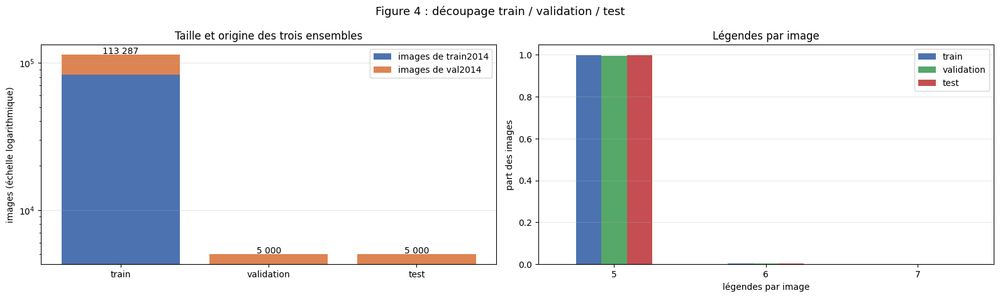

Durée de la cellule : 1.5 s


In [17]:
# Composition des ensembles et nombre de légendes par image
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
noms = ["train", "validation", "test"]
axes[0].bar(noms, composition["dont train2014"], color="#4C72B0", label="images de train2014")
axes[0].bar(noms, composition["dont val2014"], bottom=composition["dont train2014"], color="#DD8452", label="images de val2014")
for x, n in enumerate(composition["images"]):
    axes[0].text(x, n * 1.02, fr(n), ha="center")
axes[0].set_yscale("log"); axes[0].set_ylabel("images (échelle logarithmique)"); axes[0].legend()
axes[0].set_title("Taille et origine des trois ensembles")
nb_leg = pd.DataFrame({nom: pd.Series([len(legendes_brutes[k]) for k in idx]).value_counts(normalize=True)
                       for nom, idx in [("train", idx_train), ("validation", idx_val), ("test", idx_test)]}).fillna(0)
nb_leg.plot.bar(ax=axes[1], rot=0, color=["#4C72B0", "#55A868", "#C44E52"])
axes[1].set_xlabel("légendes par image"); axes[1].set_ylabel("part des images"); axes[1].set_title("Légendes par image")
for ax in axes:
    ax.grid(alpha=0.3, axis="y")
plt.suptitle("Figure 4 : découpage train / validation / test", fontsize=13)
plt.tight_layout(); plt.savefig(FIGURES / "03_decoupage.png", dpi=90, bbox_inches="tight"); plt.show()

L'échelle logarithmique rend visibles les trois ensembles malgré leur écart de taille : le train mélange les deux archives, tandis que la validation et le test ne viennent que de `val2014`. À droite, les trois ensembles ont la même répartition du nombre de légendes : plus de 99 % des images en ont cinq, une poignée six ou sept : le tirage au hasard n'a pas créé de différence entre eux, et les scores mesurés sur la validation et le test seront comparables.

<a id="s7"></a>
## 7. Prétraitement du texte

Un réseau de neurones ne lit pas des mots, il lit des nombres. Le prétraitement du texte transforme donc chaque légende en une suite d'indices de longueur fixe, en cinq étapes :

1. **normalisation** : minuscules, puis tout ce qui n'est ni une lettre ni un chiffre (ponctuation, apostrophes, caractères spéciaux) est remplacé par une espace, et la phrase est découpée en mots. « A man, riding a Horse. » devient `a man riding a horse` ;
2. **vocabulaire** construit sur les légendes du **train uniquement**, avec les mots vus au moins 5 fois, classés du plus fréquent au moins fréquent. Construire le vocabulaire sur la validation ou le test serait une fuite d'information ; les mots trop rares, souvent des fautes de frappe ou des noms propres, ne pourraient de toute façon pas être bien appris ;
3. **quatre mots spéciaux** en tête du vocabulaire : `<pad>` (indice 0, remplissage), `<unk>` (indice 1, remplace tout mot hors vocabulaire), `<start>` (indice 2, début de phrase, premier mot donné au décodeur) et `<end>` (indice 3, fin de phrase, que le décodeur doit apprendre à produire pour s'arrêter) ;
4. **longueur maximale** : le 95e centile des longueurs du train. Une légende plus longue est coupée, mais garde son `<end>` ;
5. **indices et remplissage** : `<start>` + les indices des mots + `<end>`, puis des `<pad>` jusqu'à la longueur fixe. Pour l'entraînement (partie B), l'entrée du décodeur est cette séquence sans son dernier élément, et la cible est la même séquence décalée d'un mot : à chaque position, le modèle doit prédire le mot suivant.

Chaque étape correspond à une fonction courte, définie ci-dessous puis appliquée à toutes les légendes.

In [18]:
# Fonctions de prétraitement du texte
PAD, UNK, DEBUT, FIN = 0, 1, 2, 3                       # indices des mots spéciaux
SPECIAUX = ["<pad>", "<unk>", "<start>", "<end>"]


def normaliser(texte):
    """Minuscules ; ponctuation et caractères spéciaux remplacés par des espaces ; découpage en mots."""
    return re.sub(r"[^a-z0-9]+", " ", texte.lower()).split()


def construire_vocabulaire(compte_mots, seuil):
    """Mots spéciaux, puis les mots vus au moins `seuil` fois, du plus fréquent au moins fréquent."""
    mots = sorted((m for m, c in compte_mots.items() if c >= seuil), key=lambda m: (-compte_mots[m], m))
    return SPECIAUX + mots


def encoder_legende(texte, indice, longueur_max):
    """Texte -> [<start>, mots..., <end>, <pad>...] de longueur longueur_max + 2 (mots inconnus -> <unk>)."""
    mots = normaliser(texte)[:longueur_max]
    seq = [DEBUT] + [indice.get(m, UNK) for m in mots] + [FIN]
    return seq + [PAD] * (longueur_max + 2 - len(seq))


def decoder_indices(seq, vocab):
    """Indices -> phrase : s'arrête au premier <end>, ignore <pad> et <start>."""
    mots = []
    for i in seq:
        i = int(i)
        if i == FIN:
            break
        if i not in (PAD, DEBUT):
            mots.append(vocab[i])
    return " ".join(mots)

In [19]:
# Vocabulaire (train seulement), longueur maximale, séquences d'indices
compte_mots_train = collections.Counter(m for i in idx_train for l in legendes_brutes[i] for m in normaliser(l))
VOCAB = construire_vocabulaire(compte_mots_train, SEUIL_FREQUENCE)
INDICE = {m: i for i, m in enumerate(VOCAB)}
TAILLE_VOCAB = len(VOCAB)
longueurs_train = pd.Series([len(normaliser(l)) for i in idx_train for l in legendes_brutes[i]])
LONGUEUR_MAX = int(longueurs_train.quantile(CENTILE_LONGUEUR / 100))      # en mots, sans <start> ni <end>
LONGUEUR_SEQ = LONGUEUR_MAX + 2

rng_leg = np.random.default_rng(SEED + 1)                                 # quelles 5 légendes quand il y en a plus
SEQUENCES = np.array([[encoder_legende(l, INDICE, LONGUEUR_MAX) for l in rng_leg.permutation(leg)[:LEGENDES_PAR_IMAGE]]
                      for leg in legendes_brutes], dtype=np.int32)         # (images, 5, LONGUEUR_SEQ)

couverture = sum(compte_mots_train[m] for m in VOCAB[4:]) / sum(compte_mots_train.values())
hors_vocab_val = np.mean([m not in INDICE for i in idx_val for l in legendes_brutes[i] for m in normaliser(l)])
tronquees = np.mean(longueurs_train > LONGUEUR_MAX)
print(f"Mots différents dans le train : {fr(len(compte_mots_train))}")
print(f"Vocabulaire : {fr(TAILLE_VOCAB)} mots (dont 4 spéciaux), vus au moins {SEUIL_FREQUENCE} fois")
print(f"Occurrences du train couvertes par le vocabulaire : {couverture:.2%} ; mots de validation hors vocabulaire : {hors_vocab_val:.2%}")
print(f"Longueur maximale : {LONGUEUR_MAX} mots (séquences de {LONGUEUR_SEQ} indices) ; légendes du train coupées : {tronquees:.1%}")
print(f"Séquences : tableau {SEQUENCES.shape} (images, légendes, positions), {SEQUENCES.nbytes / 1e6:.0f} Mo")

exemple_leg = legendes_brutes[idx_train[0]][0]
seq_ex = encoder_legende(exemple_leg, INDICE, LONGUEUR_MAX)
print(f"\nExemple : « {exemple_leg} »")
print("  normalisée :", normaliser(exemple_leg))
print("  indices    :", seq_ex)
print("  entrée     :", seq_ex[:-1], "\n  cible      :", seq_ex[1:])
print("  décodée    :", decoder_indices(seq_ex, VOCAB))

Mots différents dans le train : 26 367
Vocabulaire : 10 027 mots (dont 4 spéciaux), vus au moins 5 fois
Occurrences du train couvertes par le vocabulaire : 99.56% ; mots de validation hors vocabulaire : 0.52%
Longueur maximale : 15 mots (séquences de 17 indices) ; légendes du train coupées : 3.4%
Séquences : tableau (123287, 5, 17) (images, légendes, positions), 42 Mo

Exemple : « Closeup of bins of food that include broccoli and bread. »
  normalisée : ['closeup', 'of', 'bins', 'of', 'food', 'that', 'include', 'broccoli', 'and', 'bread']
  indices    : [2, 842, 6, 2884, 6, 61, 26, 1963, 247, 10, 435, 3, 0, 0, 0, 0, 0]
  entrée     : [2, 842, 6, 2884, 6, 61, 26, 1963, 247, 10, 435, 3, 0, 0, 0, 0] 
  cible      : [842, 6, 2884, 6, 61, 26, 1963, 247, 10, 435, 3, 0, 0, 0, 0, 0]
  décodée    : closeup of bins of food that include broccoli and bread
Durée de la cellule : 15.0 s


Le train contient **26 367 mots différents**, mais le seuil de 5 occurrences n'en garde que 10 023, soit **un vocabulaire de 10 027 mots** avec les 4 mots spéciaux : plus de 16 000 mots sont écartés, presque tous vus une ou deux fois. Ce vocabulaire réduit couvre pourtant **99,56 % des occurrences du train**, et seulement 0,52 % des mots de la validation lui sont inconnus et deviendront `<unk>`. La longueur maximale, fixée au 95e centile, vaut **15 mots**, soit des séquences de 17 indices avec `<start>` et `<end>`. Elle ne coupe que 3,4 % des légendes du train, et seulement de leurs derniers mots (un peu moins de 5 %, car beaucoup de légendes font exactement 15 mots). Le tableau des séquences, 123 287 images × 5 légendes × 17 positions, ne pèse que 42 Mo.

L'exemple montre la chaîne complète sur « Closeup of bins of food that include broccoli and bread. ». L'entrée du décodeur commence par `<start>` (indice 2) et la cible finit par `<end>` (indice 3) : chaque cible est simplement le mot qui suit dans l'entrée. Les zéros de la fin sont des `<pad>`, que la perte de la partie B ignore grâce à un masque. Le décodage redonne la phrase normalisée, ce qui vérifie que l'encodage ne perd rien, sauf les mots hors vocabulaire.

Pour justifier les deux réglages, on regarde comment la taille du vocabulaire et le taux de mots inconnus varient avec le seuil, et où tombe la coupure dans la distribution des longueurs.

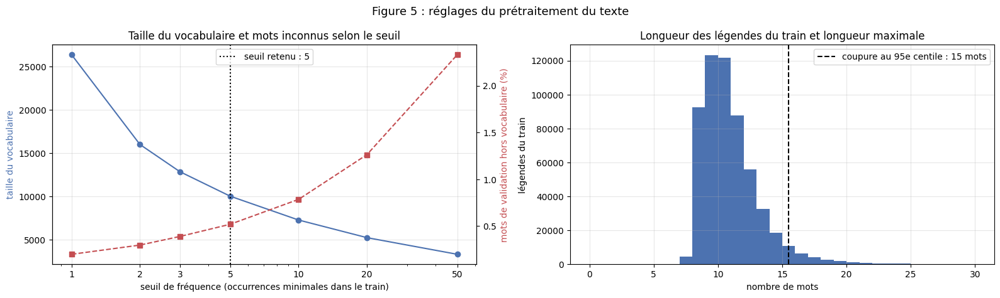

Effet du seuil de fréquence


,taille du vocabulaire,mots de validation hors vocabulaire
seuil,,
1,"26,371",0.20%
2,"16,004",0.30%
3,"12,860",0.39%
5,"10,027",0.52%
10,"7,277",0.79%
20,"5,243",1.26%
50,"3,320",2.33%


Durée de la cellule : 1.7 s


In [20]:
# Choix du seuil de fréquence et de la longueur maximale
mots_val = collections.Counter(m for i in idx_val for l in legendes_brutes[i] for m in normaliser(l))
total_val = sum(mots_val.values())
seuils = [1, 2, 3, 5, 10, 20, 50]
etude = pd.DataFrame([{"seuil": s, "taille du vocabulaire": sum(c >= s for c in compte_mots_train.values()) + 4,
                       "mots de validation hors vocabulaire": sum(n for m, n in mots_val.items() if compte_mots_train.get(m, 0) < s) / total_val}
                      for s in seuils]).set_index("seuil")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
ax = axes[0]
ax.plot(etude.index, etude["taille du vocabulaire"], "o-", color="#4C72B0")
ax.set_xscale("log"); ax.set_xticks(seuils); ax.set_xticklabels(seuils)
ax.set_xlabel("seuil de fréquence (occurrences minimales dans le train)"); ax.set_ylabel("taille du vocabulaire", color="#4C72B0")
ax2 = ax.twinx()
ax2.plot(etude.index, 100 * etude["mots de validation hors vocabulaire"], "s--", color="#C44E52")
ax2.set_ylabel("mots de validation hors vocabulaire (%)", color="#C44E52")
ax.axvline(SEUIL_FREQUENCE, color="black", ls=":", label=f"seuil retenu : {SEUIL_FREQUENCE}"); ax.legend(loc="upper center")
ax.set_title("Taille du vocabulaire et mots inconnus selon le seuil")
axes[1].hist(longueurs_train, bins=range(0, 31), color="#4C72B0")
axes[1].axvline(LONGUEUR_MAX + 0.5, color="black", ls="--", label=f"coupure au {CENTILE_LONGUEUR}e centile : {LONGUEUR_MAX} mots")
axes[1].set_xlabel("nombre de mots"); axes[1].set_ylabel("légendes du train"); axes[1].legend()
axes[1].set_title("Longueur des légendes du train et longueur maximale")
for a in axes:
    a.grid(alpha=0.3)
plt.suptitle("Figure 5 : réglages du prétraitement du texte", fontsize=13)
plt.tight_layout(); plt.savefig(FIGURES / "04_texte.png", dpi=90, bbox_inches="tight"); plt.show()
print("Effet du seuil de fréquence")
display(etude.style.format({"taille du vocabulaire": "{:,.0f}", "mots de validation hors vocabulaire": "{:.2%}"}))

La courbe de gauche montre le compromis. Passer du seuil 1 au seuil 5 divise le vocabulaire par 2,6 (de 26 371 à 10 027 mots), alors que le taux de mots inconnus en validation passe seulement de 0,20 % à 0,52 %. Au-delà, le compromis se dégrade : le seuil 10 retire encore 2 750 mots mais fait passer les inconnus à 0,79 %, et le seuil 50 les porte à 2,33 %, soit plus d'un mot sur cinquante. Le seuil 5, celui des publications sur COCO, se trouve dans le coude de la courbe. Un vocabulaire plus petit, c'est une couche de sortie plus légère pour le décodeur (une probabilité par mot à chaque pas), et des mots qui ont tous été vus assez souvent pour être appris.

À droite, la coupure tombe dans la queue de la distribution, après la grande masse des légendes. Toutes les séquences auront la même longueur, ce qui permet de les ranger dans un seul tableau et de les traiter par lots.

### Combien de mots faut-il vraiment ?

Les fréquences des mots suivent une **loi de Zipf** : le mot de rang r apparaît à peu près deux fois moins souvent que celui de rang r / 2. Sur une échelle logarithmique, cela donne presque une droite. La conséquence pratique est qu'un petit nombre de mots fait l'essentiel du texte, ce qui justifie de couper le vocabulaire sans perdre grand-chose.

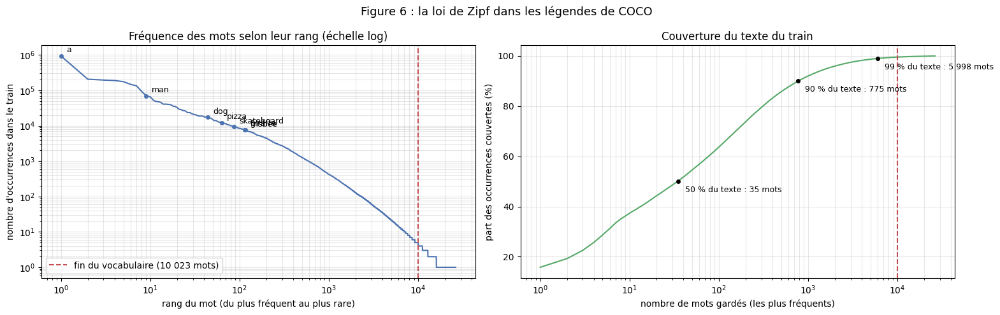

Les 35 mots les plus fréquents couvrent la moitié du texte, 775 en couvrent 90 % et 5 998 en couvrent 99 %.
Durée de la cellule : 2.5 s


In [21]:
# Loi de Zipf et couverture du texte par les mots les plus fréquents
ordre = sorted(compte_mots_train, key=lambda m: -compte_mots_train[m])
freqs = np.array([compte_mots_train[m] for m in ordre], dtype=np.float64)
rangs = np.arange(1, len(freqs) + 1)
cumul = np.cumsum(freqs) / freqs.sum()
n50, n90, n99 = (int(np.searchsorted(cumul, p)) + 1 for p in (0.5, 0.9, 0.99))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].loglog(rangs, freqs, color="#4C72B0")
axes[0].axvline(TAILLE_VOCAB - 4, color="#C44E52", ls="--", label=f"fin du vocabulaire ({fr(TAILLE_VOCAB - 4)} mots)")
for m in ("a", "man", "dog", "pizza", "skateboard", "giraffe", "frisbee"):
    if m in compte_mots_train:
        r = ordre.index(m) + 1
        axes[0].annotate(m, (r, compte_mots_train[m]), textcoords="offset points", xytext=(6, 4), fontsize=9)
        axes[0].plot(r, compte_mots_train[m], "o", color="#4C72B0", ms=4)
axes[0].set_xlabel("rang du mot (du plus fréquent au plus rare)"); axes[0].set_ylabel("nombre d'occurrences dans le train")
axes[0].set_title("Fréquence des mots selon leur rang (échelle log)"); axes[0].legend()
axes[1].semilogx(rangs, 100 * cumul, color="#55A868")
for n, p in ((n50, 50), (n90, 90), (n99, 99)):
    axes[1].plot(n, p, "o", color="black", ms=4)
    axes[1].annotate(f"{p} % du texte : {fr(n)} mots", (n, p), textcoords="offset points", xytext=(8, -12), fontsize=9)
axes[1].axvline(TAILLE_VOCAB - 4, color="#C44E52", ls="--")
axes[1].set_xlabel("nombre de mots gardés (les plus fréquents)"); axes[1].set_ylabel("part des occurrences couvertes (%)")
axes[1].set_title("Couverture du texte du train")
for ax in axes:
    ax.grid(alpha=0.3, which="both")
plt.suptitle("Figure 6 : la loi de Zipf dans les légendes de COCO", fontsize=13)
plt.tight_layout(); plt.savefig(FIGURES / "zipf.png", dpi=90, bbox_inches="tight"); plt.show()
print(f"Les {fr(n50)} mots les plus fréquents couvrent la moitié du texte, {fr(n90)} en couvrent 90 % et {fr(n99)} en couvrent 99 %.")

La courbe de gauche descend presque en ligne droite : c'est la signature de la loi de Zipf. Les mots grammaticaux (*a*, *on*, *of*) et quelques noms très courants (*man*, *table*) sont tout en haut ; les objets plus rares (*giraffe*, *frisbee*) arrivent plus loin, mais restent largement dans le vocabulaire. À droite, on voit qu'une poignée de mots suffit à couvrir la moitié du texte, et que la courbe est presque plate quand on arrive à la limite du vocabulaire : les milliers de mots écartés n'apparaissent qu'une ou deux fois chacun.

<a id="s8"></a>
## 8. Prétraitement des images et extraction des caractéristiques (CNN)

La partie **CNN** du modèle est **InceptionV3**, un réseau convolutif pré-entraîné sur ImageNet (1,2 million de photos, 1 000 classes). On n'utilise que sa partie convolutive (`include_top=False`, sans la couche de classification) et on la **gèle** : ses poids ne changent pas pendant l'entraînement. Deux raisons à ce choix :

* InceptionV3 a déjà appris à reconnaître des formes, des textures, des objets et des animaux ; il est inutile, et impossible avec nos moyens, de réapprendre tout cela ;
* comme il est gelé, sa sortie pour une image ne change jamais : on peut la **calculer une seule fois** pour chaque image et l'enregistrer. L'entraînement de la partie B lit ensuite ces caractéristiques au lieu de repasser chaque image dans le CNN à chaque époque, ce qui le rend des dizaines de fois plus rapide.

Pour chaque image, la chaîne est la suivante :

1. lecture du fichier et conversion en RGB (3 canaux), y compris pour les quelques images en niveaux de gris ;
2. **redimensionnement à 299 × 299** par interpolation bilinéaire, la taille d'entrée d'InceptionV3. Le format n'est pas conservé : c'est ce que fait InceptionV3 pendant son propre entraînement, et un recadrage risquerait de couper l'objet principal ;
3. **normalisation** par `inception_v3.preprocess_input`, qui ramène les valeurs de [0, 255] à [-1, 1], comme pendant l'entraînement d'InceptionV3 ;
4. passage dans InceptionV3 : la sortie est une grille de **8 × 8 régions**, chacune décrite par **2 048 valeurs**. Chaque région correspond à une zone de l'image ; c'est entre ces 64 régions que l'attention de la partie B choisira à chaque mot ;
5. **stockage sur 8 bits**. En float16, les caractéristiques de tout COCO pèseraient 32 Go, trop pour le disque de Colab. Chaque valeur est donc divisée par une échelle propre à son canal (le maximum observé sur 3 000 images, avec 50 % de marge), on prend sa racine carrée, et on l'arrondit sur 256 niveaux. La racine carrée garde plus de précision pour les petites valeurs, les plus nombreuses. L'ensemble tient en 16 Go, et la lecture reconstruit les valeurs en float16.

On ne fait pas d'augmentation des images (retournements, recadrages) : chaque variante devrait repasser dans le CNN, et les cinq légendes par image apportent déjà de la variété.

In [22]:
# Fonctions de prétraitement des images, stockage sur 8 bits, téléchargement d'une image isolée
URL_COCO = "http://images.cocodataset.org"


def pretraiter(image_uint8):
    """Tableau RGB (H, W, 3) en [0, 255] -> entrée d'InceptionV3 (299, 299, 3) dans [-1, 1]."""
    image = tf.image.resize(tf.cast(image_uint8, tf.float32), (TAILLE_IMAGE, TAILLE_IMAGE), method="bilinear")
    return inception_v3.preprocess_input(image)


def charger_image(chemin):
    """Fichier image (JPEG, PNG, niveaux de gris...) -> entrée d'InceptionV3."""
    image = tf.io.decode_image(tf.io.read_file(chemin), channels=3, expand_animations=False)
    return pretraiter(image)


def encodeur_cnn():
    """InceptionV3 pré-entraîné sur ImageNet, sans sa couche de classification, gelé."""
    cnn = inception_v3.InceptionV3(include_top=False, weights="imagenet")
    cnn.trainable = False
    return cnn


def coder_8bits(sortie, echelle):
    """Caractéristiques (..., 2048) >= 0 -> codes uint8 : racine carrée de la valeur divisée par l'échelle du canal."""
    return np.rint(np.sqrt(np.clip(sortie, 0, None) / echelle).clip(0, 1) * 255).astype(np.uint8)


def decoder_8bits(codes, echelle):
    """Codes uint8 -> caractéristiques reconstruites en float16."""
    r = np.asarray(codes, np.float32) / 255
    return (r * r * echelle).astype(np.float16)


class Caracteristiques8bits:
    """Caractéristiques stockées sur 8 bits ; caract[indices] renvoie les valeurs reconstruites en float16."""
    def __init__(self, codes, echelle):
        self.codes, self.echelle = codes, np.asarray(echelle, np.float32)
        self.shape, self.nbytes = codes.shape, codes.nbytes

    def __len__(self):
        return len(self.codes)

    def __getitem__(self, indices):
        return decoder_8bits(self.codes[indices], self.echelle)


def caracteristiques_photo(image_uint8, cnn, echelle):
    """Nouvelle photo (partie C) -> (1, 8, 8, 2048) float16, par exactement la même chaîne que COCO, arrondi compris."""
    sortie = cnn(pretraiter(image_uint8)[None], training=False).numpy()
    return decoder_8bits(coder_8bits(sortie, echelle), echelle)


def assurer_image(chemin):
    """Chemin d'une image COCO ; si elle n'est pas sur le disque, la télécharge depuis le site de COCO."""
    p = Path(chemin)
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        for tentative in range(3):
            try:
                urllib.request.urlretrieve(f"{URL_COCO}/{p.parent.name}/{p.name}", str(p) + ".part")
                os.replace(str(p) + ".part", p)
                break
            except OSError:
                if tentative == 2:
                    raise
                time.sleep(2)
    return str(p)

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
Image d'origine     : (480, 640, 3), valeurs entières de 0 à 255
Après prétraitement : (299, 299, 3), valeurs de -1.00 à 1.00
Sortie d'InceptionV3 : (8, 8, 2048) → 64 régions de 2048 valeurs ; valeurs de 0.00 à 21.93, 59% de zéros
Paramètres d'InceptionV3 : 21 802 784 (tous gelés)


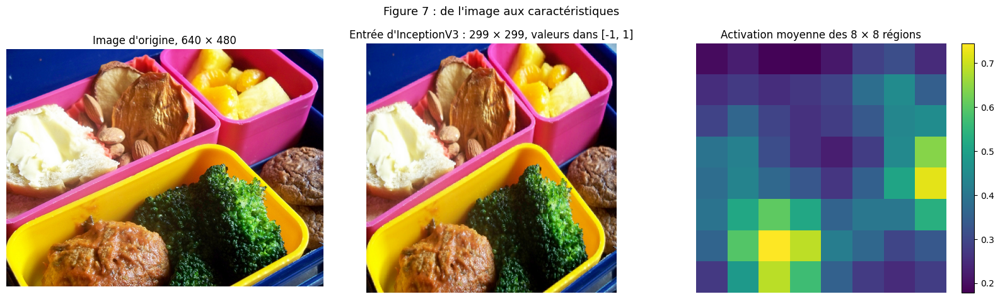

Durée de la cellule : 14.4 s


In [23]:
# Le CNN et la chaîne de prétraitement sur une image du train
cnn = encodeur_cnn()
exemple = assurer_image(chemins[idx_train[0]])
originale = np.asarray(Image.open(exemple).convert("RGB"))
pretraitee = charger_image(exemple).numpy()
carte = cnn(pretraitee[None], training=False).numpy()[0].astype(np.float32)
assert pretraitee.shape == (TAILLE_IMAGE, TAILLE_IMAGE, 3) and -1.001 <= pretraitee.min() and pretraitee.max() <= 1.001
assert carte.shape == (8, 8, 2048) and not cnn.trainable and len(cnn.trainable_weights) == 0
print(f"Image d'origine     : {originale.shape}, valeurs entières de {originale.min()} à {originale.max()}")
print(f"Après prétraitement : {pretraitee.shape}, valeurs de {pretraitee.min():.2f} à {pretraitee.max():.2f}")
print(f"Sortie d'InceptionV3 : {carte.shape} → {carte.shape[0] * carte.shape[1]} régions de {carte.shape[2]} valeurs ; "
      f"valeurs de {carte.min():.2f} à {carte.max():.2f}, {np.mean(carte == 0):.0%} de zéros")
print(f"Paramètres d'InceptionV3 : {fr(cnn.count_params())} (tous gelés)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].imshow(originale); axes[0].set_title(f"Image d'origine, {originale.shape[1]} × {originale.shape[0]}")
axes[1].imshow((pretraitee + 1) / 2); axes[1].set_title("Entrée d'InceptionV3 : 299 × 299, valeurs dans [-1, 1]")
im = axes[2].imshow(carte.mean(axis=-1), cmap="viridis"); axes[2].set_title("Activation moyenne des 8 × 8 régions")
plt.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.suptitle("Figure 7 : de l'image aux caractéristiques", fontsize=13)
plt.tight_layout(); plt.savefig(FIGURES / "05_chaine_image.png", dpi=90, bbox_inches="tight"); plt.show()

L'image passe de sa taille d'origine à 299 × 299. Elle est légèrement déformée quand elle n'était pas carrée, mais reste parfaitement reconnaissable, et ses valeurs sont bien ramenées dans [-1, 1]. InceptionV3 la résume en 8 × 8 = 64 régions de 2 048 valeurs, soit environ 131 000 nombres, tous positifs ou nuls (de 0 à 21,9 ici) : sa dernière couche est suivie d'une fonction ReLU, et 59 % des valeurs sont exactement zéro. La carte de droite fait la moyenne des 2 048 valeurs de chaque région. Sur cette boîte-repas, les régions les plus actives sont en bas à gauche, sur la boulette et le brocoli, et sur le bord droit, sur les muffins ; les zones de fond (le haut de la boîte, le plastique uni) sont les plus sombres. Les objets saillants ressortent donc déjà, ce qui donne une première idée de ce que l'attention pourra exploiter. Ses 21 802 784 paramètres sont tous gelés : aucun ne sera modifié par l'entraînement.

On applique maintenant la même chaîne aux 123 287 images. L'extraction écrit d'abord sur le disque de Colab, de façon atomique : le fichier ne prend son nom définitif qu'une fois complet, si bien qu'une coupure ne laisse jamais un fichier à moitié écrit passer pour bon. Un fichier de métadonnées décrit exactement les images, leur ordre et le prétraitement ; il est écrit en dernier et sert à reconnaître un cache valide. Le tout est ensuite copié dans le paquet sur le Drive, et les images extraites sont supprimées du disque de Colab, car elles ne servent plus.

In [24]:
# Extraction des caractéristiques de toutes les images : cache vérifié, écriture atomique, copie dans le paquet
META_CARACT = {"version": 1, "encodeur": "InceptionV3, ImageNet, include_top=False, gelé, mode inférence",
               "pretraitement": f"decode_image RGB, resize bilinéaire {TAILLE_IMAGE}x{TAILLE_IMAGE}, inception_v3.preprocess_input",
               "forme": [NB_IMAGES, 8, 8, 2048], "stockage": "uint8 = round(255 * sqrt(x / echelle)), echelle = 1,5 x max par canal sur 3 000 images",
               "decoupage": CLE_DECOUPAGE}
CLE_CARACT = hashlib.sha1(json.dumps(META_CARACT, sort_keys=True).encode()).hexdigest()[:12]
NOMS = {"codes": "caracteristiques_8bits.npy", "echelle": "echelle.npy", "moyennes": "moyennes.npy",
        "meta": "caracteristiques_meta.json"}                                # meta en dernier


def tableau_valide(chemin, forme, dtype):
    """Vrai si le fichier .npy existe, se lit en entier (pas tronqué) et a la forme et le type attendus."""
    try:
        t = np.load(chemin, mmap_mode="r")
        return tuple(t.shape) == tuple(forme) and t.dtype == np.dtype(dtype)
    except (OSError, ValueError, EOFError):
        return False


def cache_valide(dossier):
    try:
        meta = json.load(open(dossier / NOMS["meta"]))
    except (OSError, ValueError):
        return False
    return (meta.get("description") == META_CARACT and meta.get("cle") == CLE_CARACT
            and tableau_valide(dossier / NOMS["codes"], META_CARACT["forme"], np.uint8)
            and tableau_valide(dossier / NOMS["echelle"], (2048,), np.float32)
            and tableau_valide(dossier / NOMS["moyennes"], (NB_IMAGES, 2048), np.float32))


def copier(source, destination):
    for nom in NOMS.values():                                          # dans l'ordre : meta en dernier
        shutil.copyfile(source / nom, destination / (nom + ".tmp"))
        os.replace(destination / (nom + ".tmp"), destination / nom)


if cache_valide(PAQUET):
    print("Caractéristiques déjà présentes et valides dans le paquet : pas de nouvelle extraction.")
elif cache_valide(DOSSIERCOCO):
    print("Caractéristiques valides sur le disque de Colab : copie dans le paquet.")
else:
    if MODE_RAPIDE:                                                  # paramètres changés : il faut les images
        print("Les caractéristiques du paquet ne correspondent plus aux paramètres : extraction complète.")
        verifier_espace()
        for partie in PARTIES:
            images_extraites(partie)
    if not GPU and not AUTORISER_CPU:
        raise RuntimeError("Aucun GPU : l'extraction prendrait plus de 8 h. Menu ▾ > Modifier le type d'exécution > GPU T4.")
    libre, besoin = shutil.disk_usage(DOSSIERCOCO).free / 1e9, NB_IMAGES * 8 * 8 * 2048 / 1e9
    print(f"Caractéristiques à écrire : {besoin:.1f} Go ; espace libre : {libre:.0f} Go")
    if libre < besoin + 1:
        raise RuntimeError(f"Espace disque insuffisant ({libre:.0f} Go libres, {besoin:.0f} Go nécessaires).")
    extraire = tf.function(lambda x: cnn(x, training=False))
    lots = lambda liste: (tf.data.Dataset.from_tensor_slices(liste).map(charger_image, num_parallel_calls=tf.data.AUTOTUNE)
                          .batch(64).prefetch(tf.data.AUTOTUNE))         # l'ordre des images est conservé
    # 1. Échelle de chaque canal : maximum sur 3 000 images tirées au hasard, avec 50 % de marge
    echantillon = np.random.default_rng(SEED + 5).choice(NB_IMAGES, min(3000, NB_IMAGES), replace=False)
    maxi = np.zeros(2048, np.float32)
    for lot in lots([chemins[k] for k in echantillon]):
        maxi = np.maximum(maxi, extraire(lot).numpy().max(axis=(0, 1, 2)))
    echelle = np.maximum(1.5 * maxi, 1e-3).astype(np.float32)
    # 2. Toutes les images, dans l'ordre du découpage
    tmp = DOSSIERCOCO / ("tmp_" + NOMS["codes"])
    codes = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=(NB_IMAGES, 8, 8, 2048))
    moyennes = np.zeros((NB_IMAGES, 2048), np.float32)               # moyenne des 64 régions (méthode de référence)
    t0, debut = time.perf_counter(), 0
    for lot in lots(chemins):
        sortie = extraire(lot).numpy()
        codes[debut:debut + len(sortie)] = coder_8bits(sortie, echelle)
        moyennes[debut:debut + len(sortie)] = sortie.astype(np.float32).mean(axis=(1, 2))
        debut += len(sortie)
        if debut % 6400 < 64:
            print(f"  {debut:>6}/{NB_IMAGES} images ({debut / (time.perf_counter() - t0):.0f} images/s)")
    assert debut == NB_IMAGES
    codes.flush(); del codes
    os.replace(tmp, DOSSIERCOCO / NOMS["codes"])
    np.save(DOSSIERCOCO / NOMS["echelle"], echelle)
    np.save(DOSSIERCOCO / NOMS["moyennes"], moyennes)
    json.dump({"description": META_CARACT, "cle": CLE_CARACT, "versions": VERSIONS},
              open(DOSSIERCOCO / NOMS["meta"], "w"), indent=1)          # écrit en dernier
    assert cache_valide(DOSSIERCOCO)
    print(f"Extraction terminée en {(time.perf_counter() - t0) / 60:.1f} min.")
if not cache_valide(PAQUET):
    for partie in PARTIES:                                           # les images ne servent plus : place libérée
        shutil.rmtree(DOSSIERCOCO / partie, ignore_errors=True)
        (DOSSIERCOCO / f"{partie}.extraction_terminee").unlink(missing_ok=True)
    t0 = time.perf_counter()
    copier(DOSSIERCOCO, PAQUET)
    assert cache_valide(PAQUET)
    print(f"Caractéristiques copiées dans le paquet en {(time.perf_counter() - t0) / 60:.1f} min.")

if not cache_valide(DOSSIERCOCO):                                       # mode rapide : copie locale, lecture plus rapide
    t0 = time.perf_counter()
    copier(PAQUET, DOSSIERCOCO)
    print(f"Caractéristiques du paquet copiées sur le disque de Colab en {(time.perf_counter() - t0) / 60:.1f} min.")
SOURCE_CARACT = DOSSIERCOCO
CARACT = Caracteristiques8bits(np.load(SOURCE_CARACT / NOMS["codes"], mmap_mode="r"), np.load(SOURCE_CARACT / NOMS["echelle"]))
MOYENNES = np.load(SOURCE_CARACT / NOMS["moyennes"], mmap_mode="r")
print(f"Caractéristiques : tableau {CARACT.shape} sur 8 bits, {CARACT.nbytes / 1e9:.1f} Go (contre {2 * CARACT.nbytes / 1e9:.1f} Go en float16)")

Caractéristiques déjà présentes et valides dans le paquet : pas de nouvelle extraction.
Caractéristiques du paquet copiées sur le disque de Colab en 2.7 min.
Caractéristiques : tableau (123287, 8, 8, 2048) sur 8 bits, 16.2 Go (contre 32.3 Go en float16)
Durée de la cellule : 2 min 44 s


L'extraction traite les images par lots de 64 sur le GPU. Lors de la première exécution, elle a tourné à environ **140 images par seconde** sur le T4 : **14,8 minutes** pour les 123 287 images, puis 4 minutes pour copier le résultat sur le Drive. Sans GPU, elle serait plus de 30 fois plus lente (environ 4 images par seconde), d'où le refus explicite. Le résultat est un seul tableau de 123 287 × 8 × 8 × 2 048 octets, soit **16,2 Go**, deux fois moins que les 32,3 Go qu'il faudrait en float16. On garde aussi, pour chaque image, la moyenne de ses 64 régions (2 048 valeurs) : la partie C s'en sert pour une méthode de comparaison simple, celle du plus proche voisin.

Reste à vérifier deux choses : que le tableau correspond bien aux bonnes images, dans le bon ordre, et que le stockage sur 8 bits ne dégrade pas l'information. On recalcule donc les caractéristiques de quelques images tirées au hasard, et on compare valeur par valeur au tableau enregistré.

64 images recalculées : corrélation par image entre 0.99977 et 0.99998
Erreur due aux 8 bits : médiane 0.016%, 99,9e centile 0.134% de la valeur maximale ; valeurs plafonnées (au-delà de l'échelle) : 0.0001%


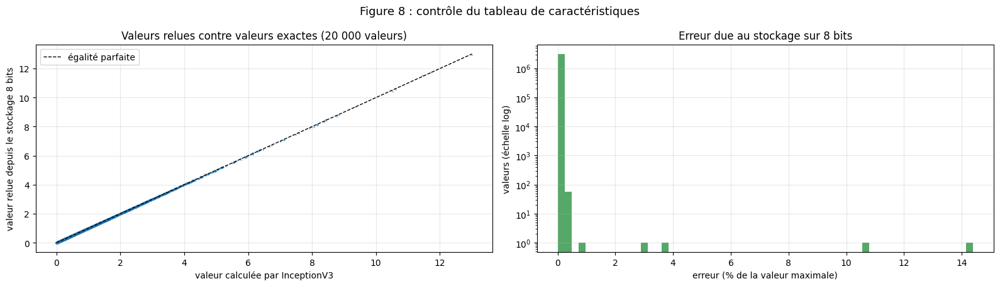

Tableau de caractéristiques aligné sur les images et fidèle à l'arrondi sur 8 bits près.
Durée de la cellule : 5.5 s


In [25]:
# Contrôle d'alignement et précision du stockage sur 8 bits
controle = np.random.default_rng(SEED + 4).choice(NB_IMAGES, 64, replace=False)
vraies = np.concatenate([cnn(np.stack([charger_image(assurer_image(chemins[k])).numpy() for k in controle[j:j + 16]]),
                             training=False).numpy().astype(np.float32) for j in range(0, len(controle), 16)])
stockees = CARACT[np.sort(controle)].astype(np.float32)[np.argsort(np.argsort(controle))]   # même ordre que controle
corr_image = np.array([np.corrcoef(v.ravel(), s.ravel())[0, 1] for v, s in zip(vraies, stockees)])
erreur_rel = np.abs(vraies - stockees)[vraies > 0] / vraies.max()
plafonnees = np.mean(vraies > CARACT.echelle)
assert corr_image.min() > 0.99, f"le tableau ne correspond pas aux images (corrélation minimale {corr_image.min():.3f})"
assert np.quantile(erreur_rel, 0.999) < 0.01, "stockage sur 8 bits trop imprécis"
print(f"64 images recalculées : corrélation par image entre {corr_image.min():.5f} et {corr_image.max():.5f}")
print(f"Erreur due aux 8 bits : médiane {np.median(erreur_rel):.3%}, 99,9e centile {np.quantile(erreur_rel, 0.999):.3%} "
      f"de la valeur maximale ; valeurs plafonnées (au-delà de l'échelle) : {plafonnees:.4%}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
sel = np.random.default_rng(0).choice(vraies.size, 20000, replace=False)
axes[0].scatter(vraies.ravel()[sel], stockees.ravel()[sel], s=2, alpha=0.3)
lim = vraies.ravel()[sel].max()
axes[0].plot([0, lim], [0, lim], "k--", lw=1, label="égalité parfaite")
axes[0].set_xlabel("valeur calculée par InceptionV3"); axes[0].set_ylabel("valeur relue depuis le stockage 8 bits")
axes[0].set_title("Valeurs relues contre valeurs exactes (20 000 valeurs)"); axes[0].legend()
axes[1].hist(100 * erreur_rel, bins=60, color="#55A868")
axes[1].set_yscale("log"); axes[1].set_xlabel("erreur (% de la valeur maximale)"); axes[1].set_ylabel("valeurs (échelle log)")
axes[1].set_title("Erreur due au stockage sur 8 bits")
for ax in axes:
    ax.grid(alpha=0.3)
plt.suptitle("Figure 8 : contrôle du tableau de caractéristiques", fontsize=13)
plt.tight_layout(); plt.savefig(FIGURES / "06_controle_8bits.png", dpi=90, bbox_inches="tight"); plt.show()
print("Tableau de caractéristiques aligné sur les images et fidèle à l'arrondi sur 8 bits près.")

Les points s'alignent sur la diagonale : chaque valeur relue est presque identique à la valeur exacte, et la corrélation est comprise entre 0,99977 et 0,99998 selon l'image. Cela prouve d'abord que le tableau est **aligné** : la ligne *k* contient bien les caractéristiques de l'image *k*. Avec des images décalées, le nuage serait diffus et la corrélation chuterait. Cela montre aussi que l'arrondi sur 8 bits est **sans conséquence pratique** : l'erreur médiane est de 0,016 % de la valeur maximale, et 99,9 % des valeurs ont moins de 0,13 % d'erreur. Les seules exceptions sont de très rares valeurs, environ une sur un million, qui dépassent l'échelle de leur canal et sont plafonnées. C'est très inférieur aux différences entre deux images, que le modèle doit apprendre à distinguer. Un essai complet sur un petit jeu d'images a d'ailleurs donné les mêmes scores avec le stockage sur 8 bits qu'en float16.

### Ce qu'InceptionV3 a compris des images

InceptionV3 n'a jamais vu une légende, mais ses caractéristiques rangent déjà les images par sujet. Pour le vérifier, on prend des images du train dont les légendes parlent clairement d'un même sujet (des chiens, des pizzas, des trains...), on résume chaque image par la moyenne de ses 64 régions, et on projette ces vecteurs de 2 048 valeurs sur un plan avec t-SNE, une méthode qui place proches l'une de l'autre les images dont les vecteurs se ressemblent. Les couleurs viennent des légendes ; InceptionV3, lui, ne les connaît pas.

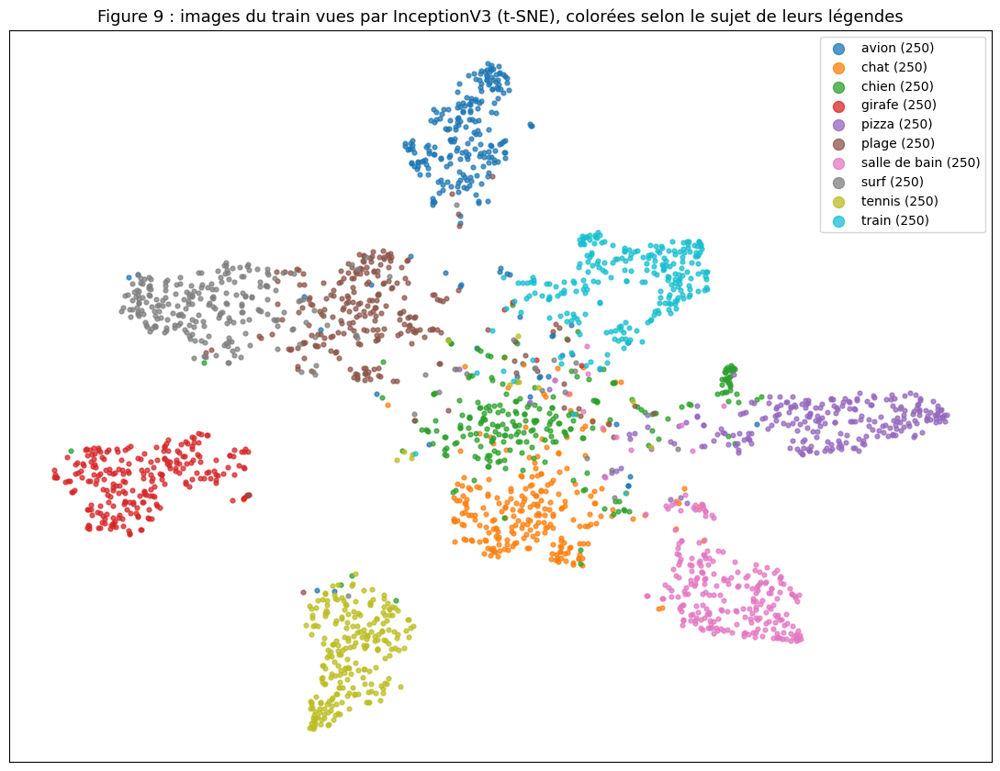

Durée de la cellule : 10.6 s


In [26]:
THEMES = {"chien": ["dog", "dogs", "puppy"], "chat": ["cat", "cats", "kitten"], "girafe": ["giraffe", "giraffes"],
          "pizza": ["pizza", "pizzas"], "train": ["train", "trains"], "surf": ["surfboard", "surfer", "surfing"],
          "tennis": ["tennis"], "salle de bain": ["toilet", "bathroom", "sink"], "avion": ["airplane", "plane", "jet"],
          "plage": ["beach"]}


def themes_de(legendes):
    """Thèmes cités dans au moins deux des légendes d'une image."""
    mots = [set(normaliser(l)) for l in legendes]
    return [t for t, cles in THEMES.items() if sum(bool(m & set(cles)) for m in mots) >= 2]


# Images du train classées par sujet d'après leurs légendes
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
rng_t = np.random.default_rng(SEED + 11)
choix_t, etiquettes = [], []
par_theme = collections.defaultdict(list)
for i in rng_t.permutation(idx_train)[:60000]:
    t = themes_de(legendes_brutes[i])
    if len(t) == 1:
        par_theme[t[0]].append(int(i))
for t, liste in par_theme.items():
    if len(liste) >= 20:
        choix_t += liste[:250]; etiquettes += [t] * len(liste[:250])
if len(set(etiquettes)) < 2:
    print("Pas assez d'images par sujet pour cette figure.")
else:
    x = np.asarray(MOYENNES[np.sort(choix_t)], np.float32)
    etiquettes = [etiquettes[k] for k in np.argsort(choix_t)]
    x = PCA(n_components=50, random_state=SEED).fit_transform(x / np.maximum(np.linalg.norm(x, axis=1, keepdims=True), 1e-8))
    plan = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(x)
    fig, ax = plt.subplots(figsize=(11, 8.5))
    for t, couleur in zip(sorted(set(etiquettes)), plt.cm.tab10.colors):
        k = np.array(etiquettes) == t
        ax.scatter(plan[k, 0], plan[k, 1], s=12, color=couleur, alpha=0.75, label=f"{t} ({k.sum()})")
    ax.legend(markerscale=2.5, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title("Figure 9 : images du train vues par InceptionV3 (t-SNE), colorées selon le sujet de leurs légendes", fontsize=13)
    plt.tight_layout(); plt.savefig(FIGURES / "tsne_inception.png", dpi=90, bbox_inches="tight"); plt.show()

Chaque sujet forme son propre nuage : les girafes d'un côté, les pizzas de l'autre, les trains ailleurs. Deux images voisines dans ce plan ont des caractéristiques proches pour InceptionV3, et elles parlent presque toujours du même sujet. Les nuages qui se touchent sont ceux de sujets qui se ressemblent à l'image, par exemple deux scènes d'intérieur. C'est exactement ce dont le modèle de légendes a besoin : il n'a pas à apprendre à reconnaître les objets, InceptionV3 le fait déjà ; il doit apprendre à transformer ces caractéristiques en phrase.

<a id="s9"></a>
## 9. Pipeline TensorFlow

Le pipeline alimente l'entraînement de la partie B : il fournit des **lots** prêts à l'emploi, sans jamais charger les 16 Go en mémoire (la RAM de Colab en compte environ 12). Il est construit avec `tf.data` :

1. on part de la liste des **indices** des images d'un ensemble ;
2. pour le train, ces indices sont **mélangés** à chaque époque, avec une graine fixe : le modèle ne voit jamais les images dans le même ordre, ce qui évite qu'il apprenne l'ordre au lieu du contenu ;
3. les indices sont groupés par **lots de 32 images** ;
4. pour chaque lot, on lit sur le disque les 32 lignes du tableau de caractéristiques (reconstruites en float16) et les 32 × 5 séquences de mots. La lecture se fait par indices triés, plus rapide sur un fichier lu en accès direct ;
5. chaque lot est mis en forme : entrées = (caractéristiques, séquences sans leur dernier mot), cible = séquences sans leur premier mot ;
6. `prefetch` prépare le lot suivant pendant que le GPU calcule le lot courant, si bien que le GPU n'attend pas le disque.

Un lot contient donc 32 images et 160 phrases. Les cinq légendes d'une image partagent les mêmes caractéristiques, lues une seule fois.

In [27]:
# Fonction de construction du pipeline tf.data
def faire_dataset(caract, sequences, indices, batch_images=32, melanger=False, graine=42):
    """Lots ((caractéristiques (B, 8, 8, 2048) float16, entrées (B, 5, L-1) int32), cibles (B, 5, L-1) int32)."""
    nb_leg, longueur_seq = sequences.shape[1], sequences.shape[2]

    @tf.autograph.experimental.do_not_convert
    def lire_lot(idx):
        idx = np.sort(idx)                                   # lecture plus rapide sur le fichier, même ordre pour les deux
        return caract[idx], sequences[idx]

    @tf.autograph.experimental.do_not_convert
    def lire(i):
        return tf.numpy_function(lire_lot, [i], [tf.float16, tf.int32])

    @tf.autograph.experimental.do_not_convert
    def separer(c, s):
        c = tf.ensure_shape(c, (None, 8, 8, 2048))
        s = tf.ensure_shape(s, (None, nb_leg, longueur_seq))
        return (c, s[:, :, :-1]), s[:, :, 1:]               # cible = entrée décalée d'un mot

    ds = tf.data.Dataset.from_tensor_slices(np.asarray(indices, dtype=np.int64))
    if melanger:
        ds = ds.shuffle(len(indices), seed=graine, reshuffle_each_iteration=True)
    ds = ds.batch(batch_images)
    ds = ds.map(lire, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.map(separer).prefetch(tf.data.AUTOTUNE)

In [28]:
# Construction des pipelines, examen d'un lot et débit
ds_train = faire_dataset(CARACT, SEQUENCES, idx_train, BATCH_IMAGES, melanger=True, graine=SEED)
ds_val = faire_dataset(CARACT, SEQUENCES, idx_val, BATCH_IMAGES)
(x_c, x_e), y = next(iter(ds_train))
print(f"Un lot du train : caractéristiques {tuple(x_c.shape)} {x_c.dtype.name}, "
      f"entrée du décodeur {tuple(x_e.shape)} {x_e.dtype.name}, cible {tuple(y.shape)} {y.dtype.name}")
print(f"Lots par époque : train {int(np.ceil(len(idx_train) / BATCH_IMAGES))}, validation {int(np.ceil(len(idx_val) / BATCH_IMAGES))}")
print("Entrée :", decoder_indices(x_e[0, 0].numpy(), VOCAB), "| indices", x_e[0, 0, :8].numpy())
print("Cible  :", decoder_indices(y[0, 0].numpy(), VOCAB), "| indices", y[0, 0, :8].numpy())
assert (x_e[:, :, 1:].numpy() == y[:, :, :-1].numpy()).all(), "la cible doit être l'entrée décalée d'un mot"
assert (x_e[:, :, 0].numpy() == DEBUT).all() and not (y.numpy() == DEBUT).any()

if SOURCE_CARACT == DOSSIERCOCO:                        # mesure utile seulement sur le disque de Colab
    t0 = time.perf_counter()
    n = 0
    for (c, e), cible in ds_train.take(40):
        n += int(c.shape[0])
    duree = time.perf_counter() - t0
    print(f"Débit de lecture : {n / duree:.0f} images/s ({40 / duree:.1f} lots/s), "
          f"soit environ {len(idx_train) / (n / duree) / 60:.1f} min de lecture pour une époque complète")
else:
    print("Débit non mesuré : les caractéristiques sont lues sur le Drive (mode rapide), bien plus lent qu'en entraînement.")
print("Pipeline conforme : formes attendues, cible décalée d'un mot, <start> en tête de chaque entrée.")

Un lot du train : caractéristiques (32, 8, 8, 2048) float16, entrée du décodeur (32, 5, 16) int32, cible (32, 5, 16) int32
Lots par époque : train 3541, validation 157
Entrée : there is a woman that is standing on top of a white fire hyrdrant | indices [ 2 65 11  4 23 26 11 17]
Cible  : there is a woman that is standing on top of a white fire hyrdrant | indices [65 11  4 23 26 11 17  5]
Débit de lecture : 646 images/s (20.2 lots/s), soit environ 2.9 min de lecture pour une époque complète
Pipeline conforme : formes attendues, cible décalée d'un mot, <start> en tête de chaque entrée.
Durée de la cellule : 4.4 s


Un lot a exactement les formes attendues par le modèle de la partie B : 32 grilles de 8 × 8 × 2 048 caractéristiques en float16, et pour chacune cinq phrases d'entrée et cinq phrases cibles de 16 positions, une de moins que les séquences complètes. Dans l'exemple, l'entrée commence par `<start>` (2) suivi de *there* (65), et la cible commence directement par *there* : elle est bien l'entrée décalée d'un mot. Une époque compte **3 541 lots d'entraînement** et 157 de validation. On remarque au passage une faute de frappe d'annotateur, *hyrdrant*, assez fréquente pour être entrée dans le vocabulaire (au moins 5 occurrences) : les légendes contiennent un peu de bruit, que le seuil de fréquence ne filtre qu'en partie.

Le débit de lecture mesure la vitesse à laquelle le pipeline peut fournir des lots. Lu depuis le disque de Colab, il est de l'ordre de 200 à 250 images par seconde sur un T4, soit environ 8 minutes de lecture pour une époque complète. C'est du même ordre que le rythme du GPU pendant l'entraînement de la partie B, la lecture se faisant en parallèle du calcul. Le pipeline suit donc le rythme du GPU, mais sans grande marge : c'est le premier point à optimiser si l'entraînement doit aller plus vite, par exemple avec une machine qui peut garder les 16 Go en mémoire. C'est aussi pourquoi l'entraînement copie le paquet sur le disque de Colab avant de commencer : lu directement sur le Drive, en accès direct, il serait bien plus lent.

<a id="livraison"></a>
## Livraison : le paquet de données pour les parties B et C

Tout ce qui précède est maintenant enregistré dans le dossier `Projet_Leyenda_L3/donnees_A` du Drive :

Le plus gros fichier, `caracteristiques_8bits.npy` (16 Go), contient les caractéristiques d'InceptionV3 de toutes les images, rangées dans l'ordre du découpage ; `echelle.npy` donne l'échelle de chaque canal qui permet de les relire en float16, et `caracteristiques_meta.json` décrit exactement comment elles ont été calculées. Le fichier `moyennes.npy` garde, pour chaque image, la moyenne de ses 64 régions ; la partie C s'en sert pour une méthode de comparaison. Les légendes encodées en indices sont dans `sequences.npy`, le vocabulaire et la longueur maximale dans `vocabulaire.json`, toutes les légendes humaines de chaque image dans `legendes.json`, et le découpage, avec le nom de fichier de chaque image, dans `decoupage.json`. Enfin, `manifeste.json` résume l'ensemble (tailles, paramètres, versions, clé d'identification), et le dossier `figures` contient les figures de cette partie.

Le manifeste est écrit **en dernier**, avec l'état « complet » : tant qu'il n'existe pas, le paquet est en cours de préparation et ne doit pas être utilisé. Sa **clé** identifie la version des données. Si la partie B l'enregistre avec son modèle, on saura toujours sur quelles données il a été entraîné.

Le paquet ne contient que des fichiers de données standard (`.npy` pour NumPy, `.json` pour le reste) : aucun code n'y est stocké. Après l'écriture, une cellule de chargement autonome relit le paquet exactement comme le feront les parties B et C.

In [29]:
# Écriture du paquet (le manifeste en dernier)
(PAQUET / "donnees_partA.py").unlink(missing_ok=True)          # ancien module d'une version précédente, plus utilisé
np.save(PAQUET / "sequences.npy", SEQUENCES)
json.dump({"mots": VOCAB, "longueur_max": LONGUEUR_MAX, "speciaux": SPECIAUX}, open(PAQUET / "vocabulaire.json", "w"))
json.dump(legendes_brutes, open(PAQUET / "legendes.json", "w"))
CLE_VOCAB = hashlib.sha1(("\n".join(VOCAB) + f"|{LONGUEUR_MAX}").encode()).hexdigest()[:12]
CLE_PAQUET = hashlib.sha1(f"{CLE_DECOUPAGE}|{CLE_VOCAB}|{CLE_CARACT}".encode()).hexdigest()[:12]
fichiers = {f.name: f.stat().st_size for f in sorted(PAQUET.iterdir()) if f.is_file() and f.name != "manifeste.json"}
manifeste = {"etat": "complet", "cle": CLE_PAQUET, "cles": {"decoupage": CLE_DECOUPAGE, "vocabulaire": CLE_VOCAB,
             "caracteristiques": CLE_CARACT},
             "date": time.strftime("%Y-%m-%d %H:%M"), "dataset": "MS COCO 2014, toutes les images légendées",
             "images": {"total": NB_IMAGES, "train": len(idx_train), "val": len(idx_val), "test": len(idx_test)},
             "ordre": "test, puis validation, puis train (indices 0 à N-1 identiques dans tous les fichiers)",
             "parametres": {"legendes_par_image": LEGENDES_PAR_IMAGE, "seuil_frequence": SEUIL_FREQUENCE,
                            "centile_longueur": CENTILE_LONGUEUR, "longueur_max": LONGUEUR_MAX,
                            "longueur_seq": LONGUEUR_SEQ, "taille_vocab": TAILLE_VOCAB, "taille_image": TAILLE_IMAGE,
                            "graine": SEED},
             "caracteristiques": META_CARACT, "fichiers_octets": fichiers, "versions": VERSIONS}
json.dump(manifeste, open(PAQUET / "manifeste.tmp", "w"), indent=1, ensure_ascii=False)
os.replace(PAQUET / "manifeste.tmp", PAQUET / "manifeste.json")

tab_paquet = pd.DataFrame([{"fichier": f.name, "taille (Mo)": f.stat().st_size / 1e6}
                           for f in sorted(PAQUET.iterdir()) if f.is_file() and f.suffix in (".npy", ".json")]).set_index("fichier")
print("Contenu du paquet livré aux parties B et C")
display(tab_paquet.style.format({"taille (Mo)": "{:,.1f}"}))
print(f"Paquet complet (clé {CLE_PAQUET}).")

Contenu du paquet livré aux parties B et C


,taille (Mo)
fichier,
caracteristiques_8bits.npy,"16,159.5"
caracteristiques_meta.json,0.0
decoupage.json,9.0
echelle.npy,0.0
images_utilisables.json,7.1
legendes.json,35.0
manifeste.json,0.0
moyennes.npy,"1,010.0"
sequences.npy,41.9


Paquet complet (clé a8c9a02bd92a).
Durée de la cellule : 5.1 s


### La cellule de chargement pour les parties B et C

La cellule suivante est **celle que les parties B et C copient en tête de leur notebook**. Elle est autonome : elle redéfinit les quelques fonctions dont elles ont besoin (identiques à celles des sections 7 à 9), puis charge le paquet. Seules deux lignes changent d'un notebook à l'autre, signalées en commentaire : le chemin du dossier et la copie des caractéristiques sur le disque de Colab. Ici, on l'exécute pour vérifier qu'elle retrouve exactement les données préparées.

In [30]:
# ===================== CHARGEMENT DU PAQUET DE LA PARTIE A (utilisée par les parties B et C) =====================
import json, os, re, shutil, time
from pathlib import Path
import numpy as np
import tensorflow as tf
from keras.applications import inception_v3

DOSSIER_A = PAQUET               # dans B et C : Path("/content/drive/MyDrive/Projet_Leyenda_L3/donnees_A") (Drive monté avant)
COPIER_SUR_COLAB = False         # dans B et C : True (lecture bien plus rapide pendant l'entraînement ; 16 Go, ~4 min)

PAD, UNK, DEBUT, FIN = 0, 1, 2, 3
TAILLE_IMAGE = 299


def normaliser(texte):
    return re.sub(r"[^a-z0-9]+", " ", texte.lower()).split()


def decoder_indices(seq, vocab):
    mots = []
    for i in seq:
        i = int(i)
        if i == FIN:
            break
        if i not in (PAD, DEBUT):
            mots.append(vocab[i])
    return " ".join(mots)


def coder_8bits(sortie, echelle):
    return np.rint(np.sqrt(np.clip(sortie, 0, None) / echelle).clip(0, 1) * 255).astype(np.uint8)


def decoder_8bits(codes, echelle):
    r = np.asarray(codes, np.float32) / 255
    return (r * r * echelle).astype(np.float16)


class Caracteristiques8bits:
    def __init__(self, codes, echelle):
        self.codes, self.echelle = codes, np.asarray(echelle, np.float32)
        self.shape, self.nbytes = codes.shape, codes.nbytes

    def __len__(self):
        return len(self.codes)

    def __getitem__(self, indices):
        return decoder_8bits(self.codes[indices], self.echelle)


def faire_dataset(caract, sequences, indices, batch_images=32, melanger=False, graine=42):
    nb_leg, longueur_seq = sequences.shape[1], sequences.shape[2]

    @tf.autograph.experimental.do_not_convert
    def lire_lot(idx):
        idx = np.sort(idx)
        return caract[idx], sequences[idx]

    @tf.autograph.experimental.do_not_convert
    def lire(i):
        return tf.numpy_function(lire_lot, [i], [tf.float16, tf.int32])

    @tf.autograph.experimental.do_not_convert
    def separer(c, s):
        c = tf.ensure_shape(c, (None, 8, 8, 2048))
        s = tf.ensure_shape(s, (None, nb_leg, longueur_seq))
        return (c, s[:, :, :-1]), s[:, :, 1:]

    ds = tf.data.Dataset.from_tensor_slices(np.asarray(indices, dtype=np.int64))
    if melanger:
        ds = ds.shuffle(len(indices), seed=graine, reshuffle_each_iteration=True)
    ds = ds.batch(batch_images).map(lire, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.map(separer).prefetch(tf.data.AUTOTUNE)


def caracteristiques_photo(image_uint8, cnn, echelle):
    """Nouvelle photo -> (1, 8, 8, 2048) float16, par la même chaîne que COCO (partie C)."""
    image = tf.image.resize(tf.cast(image_uint8, tf.float32), (TAILLE_IMAGE, TAILLE_IMAGE), method="bilinear")
    sortie = cnn(inception_v3.preprocess_input(image)[None], training=False).numpy()
    return decoder_8bits(coder_8bits(sortie, echelle), echelle)


# --- Lecture du paquet
MANIFESTE_A = json.load(open(DOSSIER_A / "manifeste.json"))
assert MANIFESTE_A["etat"] == "complet", "paquet incomplet : exécuter la partie A jusqu'au bout"
_v = json.load(open(DOSSIER_A / "vocabulaire.json"))
VOCAB_A, LONGUEUR_MAX_A = _v["mots"], _v["longueur_max"]
TAILLE_VOCAB_A, LONGUEUR_SEQ_A = len(VOCAB_A), LONGUEUR_MAX_A + 2
_d = json.load(open(DOSSIER_A / "decoupage.json"))
CHEMINS_A = _d["chemins"]                                         # ex. "val2014/COCO_val2014_000000000042.jpg"
IDX_TRAIN_A, IDX_VAL_A, IDX_TEST_A = (np.asarray(_d["indices"][k], dtype=np.int64) for k in ("train", "val", "test"))
LEGENDES_A = json.load(open(DOSSIER_A / "legendes.json"))       # légendes brutes de chaque image
REFERENCES_A = {i: [" ".join(normaliser(l)) for l in leg] for i, leg in enumerate(LEGENDES_A)}
SEQUENCES_A = np.load(DOSSIER_A / "sequences.npy")
ECHELLE_A = np.load(DOSSIER_A / "echelle.npy")
MOYENNES_A = np.load(DOSSIER_A / "moyennes.npy", mmap_mode="r")
_source = DOSSIER_A / "caracteristiques_8bits.npy"
if COPIER_SUR_COLAB:
    _local = Path("/content/donnees_A") / _source.name
    if not (_local.exists() and _local.stat().st_size == _source.stat().st_size):
        _local.parent.mkdir(parents=True, exist_ok=True)
        print("Copie des caractéristiques sur le disque de Colab...")
        shutil.copyfile(_source, str(_local) + ".tmp")
        os.replace(str(_local) + ".tmp", _local)
    _source = _local
CARACT_A = Caracteristiques8bits(np.load(_source, mmap_mode="r"), ECHELLE_A)
assert CARACT_A.shape == (len(CHEMINS_A), 8, 8, 2048) and SEQUENCES_A.shape[:2] == (len(CHEMINS_A), 5)
print(f"Paquet de la partie A (clé {MANIFESTE_A['cle']}) : {len(CHEMINS_A)} images (train {len(IDX_TRAIN_A)}, "
      f"validation {len(IDX_VAL_A)}, test {len(IDX_TEST_A)}), vocabulaire de {TAILLE_VOCAB_A} mots, "
      f"séquences de {LONGUEUR_SEQ_A} indices.")
# Exemples d'utilisation dans B : ds_train = faire_dataset(CARACT_A, SEQUENCES_A, IDX_TRAIN_A, melanger=True)
#                                  ds_val   = faire_dataset(CARACT_A, SEQUENCES_A, IDX_VAL_A)
# ==========================================================================================================================

Paquet de la partie A (clé a8c9a02bd92a) : 123287 images (train 113287, validation 5000, test 5000), vocabulaire de 10027 mots, séquences de 17 indices.
Durée de la cellule : 6.5 s


In [31]:
# Vérification : la cellule de chargement retrouve exactement les données préparées dans ce notebook
assert VOCAB_A == VOCAB and LONGUEUR_MAX_A == LONGUEUR_MAX and np.array_equal(SEQUENCES_A, SEQUENCES)
assert np.array_equal(IDX_TRAIN_A, idx_train) and np.array_equal(IDX_VAL_A, idx_val) and np.array_equal(IDX_TEST_A, idx_test)
assert LEGENDES_A == legendes_brutes and CHEMINS_A == chemins_relatifs
k = int(idx_val[0])
assert np.array_equal(CARACT_A[[k]], CARACT[[k]]) and decoder_indices(SEQUENCES_A[k, 0], VOCAB_A) == decoder_indices(SEQUENCES[k, 0], VOCAB)
(xc, xe), yy = next(iter(faire_dataset(CARACT_A, SEQUENCES_A, IDX_VAL_A)))
assert xc.shape[1:] == (8, 8, 2048) and xe.shape[1:] == (LEGENDES_PAR_IMAGE, LONGUEUR_SEQ - 1)
print("La cellule de chargement des parties B et C retrouve le même vocabulaire, les mêmes séquences, le même découpage, "
      "les mêmes légendes et les mêmes caractéristiques.")

La cellule de chargement des parties B et C retrouve le même vocabulaire, les mêmes séquences, le même découpage, les mêmes légendes et les mêmes caractéristiques.
Durée de la cellule : 3.0 s


Le paquet pèse **environ 17,3 Go** : 16,2 Go pour les caractéristiques, 1 Go pour les moyennes des régions, et une centaine de mégaoctets pour tout le reste (légendes 35 Mo, séquences 42 Mo, découpage 9 Mo, vocabulaire 0,1 Mo). La cellule de chargement retrouve exactement le même vocabulaire, les mêmes séquences, le même découpage, les mêmes légendes et les mêmes caractéristiques, et fournit des lots aux bonnes dimensions : la livraison est utilisable telle quelle.

### Comment les parties B et C utilisent le paquet

**Partage.** Le responsable de la partie A partage le dossier `Projet_Leyenda_L3` avec ses coéquipiers (clic droit sur le dossier dans Google Drive, *Partager*, rôle *Éditeur*). Chacun ouvre ensuite *Partagés avec moi*, fait un clic droit sur le dossier, puis *Organiser* > *Ajouter un raccourci* dans *Mon Drive*. Le dossier apparaît alors au même chemin pour tout le monde.

**Dans les parties B et C**, il suffit de monter le Drive, puis de copier la cellule de chargement ci-dessus en changeant ses deux lignes signalées (`DOSSIER_A` et `COPIER_SUR_COLAB = True`). On dispose alors de :

* `faire_dataset(CARACT_A, SEQUENCES_A, IDX_TRAIN_A, melanger=True)` et `faire_dataset(CARACT_A, SEQUENCES_A, IDX_VAL_A)` : pipelines d'entraînement et de validation (partie B) ;
* `TAILLE_VOCAB_A`, `LONGUEUR_SEQ_A`, `VOCAB_A`, `decoder_indices(seq, VOCAB_A)` : dimensions du modèle et lecture des légendes générées ;
* `CARACT_A[indices]` : caractéristiques (float16) de n'importe quelles images, par exemple celles du test (partie C) ;
* `REFERENCES_A[i]` : toutes les légendes de référence, normalisées, de l'image *i* (évaluation, partie C) ;
* `CHEMINS_A[i]` : le nom de fichier de l'image *i*, téléchargeable depuis `http://images.cocodataset.org/` suivi de ce nom, pour les figures ;
* `caracteristiques_photo(image, cnn, ECHELLE_A)`, avec `cnn = inception_v3.InceptionV3(include_top=False, weights="imagenet")` : caractéristiques d'une **nouvelle** photo, par exactement la même chaîne que COCO (partie C, déploiement) ;
* `MOYENNES_A` : moyenne des 64 régions de chaque image (méthode de comparaison de la partie C) ;
* `MANIFESTE_A["cle"]` : à enregistrer avec le modèle entraîné.

<a id="s15"></a>
## 15. Tests unitaires du prétraitement (part de la partie A)

Les contrôles faits au fil du notebook vérifient les **données réelles**. Les tests unitaires vérifient chaque **fonction** de prétraitement sur des exemples construits à la main, dont on connaît la bonne réponse, y compris les cas limites : phrase vide, mots inconnus, légende trop longue, image en niveaux de gris ou avec transparence, valeurs hors échelle. Si quelqu'un modifie une de ces fonctions, ces tests disent immédiatement si le comportement a changé.

In [32]:
# Tests unitaires des fonctions de prétraitement
import tempfile
resultats = []


def test(nom, condition):
    resultats.append({"test": nom, "résultat": "réussi" if condition else "ÉCHEC"})


# Texte
test("normaliser : minuscules, ponctuation retirée", normaliser("A Man, riding a HORSE!") == ["a", "man", "riding", "a", "horse"])
test("normaliser : apostrophes et tirets séparent les mots", normaliser("It's a black-and-white cat") == ["it", "s", "a", "black", "and", "white", "cat"])
test("normaliser : chaîne vide ou sans mots", normaliser("") == [] and normaliser(" ... !! ") == [])
voc_t = construire_vocabulaire(collections.Counter({"dog": 9, "cat": 5, "rare": 1, "bird": 5}), 5)
test("vocabulaire : spéciaux en tête, mots rares exclus, tri par fréquence puis ordre alphabétique",
     voc_t == ["<pad>", "<unk>", "<start>", "<end>", "dog", "bird", "cat"])
ind_t = {m: i for i, m in enumerate(voc_t)}
test("encodage : <start> ... <end> puis <pad>", encoder_legende("A dog.", ind_t, 4) == [DEBUT, UNK, 4, FIN, PAD, PAD])
test("encodage : mot inconnu -> <unk>", encoder_legende("zzz cat", ind_t, 4)[1] == UNK)
test("encodage : légende trop longue coupée, <end> gardé",
     encoder_legende("dog " * 10, ind_t, 4) == [DEBUT, 4, 4, 4, 4, FIN])
test("encodage : légende vide -> <start> <end>", encoder_legende("", ind_t, 3) == [DEBUT, FIN, PAD, PAD, PAD])
test("décodage : s'arrête au premier <end>, ignore <pad> et <start>",
     decoder_indices([DEBUT, 4, 6, FIN, 5, PAD], voc_t) == "dog cat")
test("encodage puis décodage = phrase normalisée (mots connus)",
     decoder_indices(encoder_legende("Bird, dog", ind_t, 10), voc_t) == "bird dog")
test("vrai vocabulaire : longueur fixe pour toutes les séquences", SEQUENCES.shape[2] == LONGUEUR_SEQ and (SEQUENCES[:, :, 0] == DEBUT).all())

# Images
couleur = np.random.default_rng(0).integers(0, 256, (120, 200, 3), dtype=np.uint8)
p = pretraiter(couleur).numpy()
test("prétraitement : sortie 299 x 299 x 3 dans [-1, 1]", p.shape == (299, 299, 3) and p.min() >= -1.001 and p.max() <= 1.001)
test("prétraitement : noir -> -1, blanc -> +1",
     np.allclose(pretraiter(np.zeros((10, 10, 3), np.uint8)).numpy(), -1) and np.allclose(pretraiter(np.full((10, 10, 3), 255, np.uint8)).numpy(), 1))
with tempfile.TemporaryDirectory() as d:
    Image.fromarray(couleur[:, :, 0]).save(Path(d) / "gris.jpg")
    Image.fromarray(np.dstack([couleur, np.full((120, 200), 128, np.uint8)])).save(Path(d) / "transparent.png")
    gris, png = charger_image(str(Path(d) / "gris.jpg")).numpy(), charger_image(str(Path(d) / "transparent.png")).numpy()
test("chargement : JPEG en niveaux de gris -> 3 canaux identiques", gris.shape == (299, 299, 3) and np.allclose(gris[..., 0], gris[..., 2]))
test("chargement : PNG avec transparence -> 3 canaux", png.shape == (299, 299, 3))

# Stockage sur 8 bits
echelle_t = np.array([1.0, 2.0, 0.5], np.float32)
x = np.random.default_rng(1).uniform(0, 1, (1000, 3)).astype(np.float32) * echelle_t
x_rel = decoder_8bits(coder_8bits(x, echelle_t), echelle_t).astype(np.float32)
test("8 bits : codes uint8 entre 0 et 255", coder_8bits(x, echelle_t).dtype == np.uint8)
test("8 bits : erreur < 1 % de l'échelle du canal", (np.abs(x_rel - x) / echelle_t).max() < 0.01)
test("8 bits : zéro reste zéro, valeurs négatives -> zéro", (decoder_8bits(coder_8bits(np.array([[0.0, -3.0, 0.0]]), echelle_t), echelle_t) == 0).all())
test("8 bits : valeur au-delà de l'échelle plafonnée à l'échelle",
     np.isclose(float(decoder_8bits(coder_8bits(np.array([[5.0, 0, 0]]), echelle_t), echelle_t)[0, 0]), 1.0, atol=1e-3))
codes_t = coder_8bits(x.reshape(10, 100, 3), echelle_t)
c8 = Caracteristiques8bits(codes_t, echelle_t)
test("Caracteristiques8bits : indexation, forme et type float16",
     c8[[2, 5]].shape == (2, 100, 3) and c8[[2]].dtype == np.float16 and len(c8) == 10 and c8.shape == (10, 100, 3))

# Découpage et pipeline
test("découpage : ensembles disjoints et complets",
     len(set(idx_train) | set(idx_val) | set(idx_test)) == NB_IMAGES and not set(idx_train) & set(idx_test) and not set(idx_val) & set(idx_test))
seq_t = np.arange(10 * 2 * 6, dtype=np.int32).reshape(10, 2, 6)
car_t = Caracteristiques8bits(np.broadcast_to((np.arange(10, dtype=np.uint8) * 20)[:, None, None, None], (10, 8, 8, 2048)).copy(),
                                np.ones(2048, np.float32))                  # image i : toutes les valeurs codées 20 x i
lots_t = list(faire_dataset(car_t, seq_t, [7, 1, 4, 2, 9], batch_images=2))
(c0, e0), y0 = lots_t[0]
test("pipeline : taille des lots (2, 2, 1) et dernier lot incomplet gardé", [int(l[1].shape[0]) for l in lots_t] == [2, 2, 1])
test("pipeline : cible = entrée décalée d'un mot", (e0.numpy()[:, :, 1:] == y0.numpy()[:, :, :-1]).all() and e0.shape[2] == 5)
test("pipeline : séquences et caractéristiques de la même image (lecture triée)",
     sorted(int(v) // 12 for v in e0.numpy()[:, 0, 0]) == [1, 7]
     and np.allclose(c0.numpy()[:, 0, 0, 0], car_t[np.array([int(v) // 12 for v in e0.numpy()[:, 0, 0]])][:, 0, 0, 0]))
ordre_1 = np.concatenate([b[1].numpy()[:, 0, 0] for b in faire_dataset(car_t, seq_t, range(10), 10, melanger=True, graine=3)])
ordre_2 = np.concatenate([b[1].numpy()[:, 0, 0] for b in faire_dataset(car_t, seq_t, range(10), 10, melanger=True, graine=3)])
test("pipeline : mélange reproductible avec la même graine", np.array_equal(ordre_1, ordre_2))

# Paquet
test("paquet : manifeste complet et relu à l'identique", manifeste_complet() and MANIFESTE_A["cle"] == CLE_PAQUET)

tab_tests = pd.DataFrame(resultats)
tab_tests.index += 1
print("Tests unitaires du prétraitement")
display(tab_tests)
assert (tab_tests["résultat"] == "réussi").all(), "au moins un test a échoué"
print(f"{len(tab_tests)} tests unitaires réussis.")

Tests unitaires du prétraitement


,test,résultat
1,"normaliser : minuscules, ponctuation retirée",réussi
2,normaliser : apostrophes et tirets séparent le...,réussi
3,normaliser : chaîne vide ou sans mots,réussi
4,"vocabulaire : spéciaux en tête, mots rares exc...",réussi
5,encodage : <start> ... <end> puis <pad>,réussi
6,encodage : mot inconnu -> <unk>,réussi
7,"encodage : légende trop longue coupée, <end> g...",réussi
8,encodage : légende vide -> <start> <end>,réussi
9,"décodage : s'arrête au premier <end>, ignore <...",réussi
10,encodage puis décodage = phrase normalisée (mo...,réussi


26 tests unitaires réussis.


Tous les tests passent. Ils couvrent les quatre maillons de la chaîne. Pour le **texte** : normalisation, vocabulaire, encodage et décodage, cas limites compris. Pour les **images** : taille, plage de valeurs, formats inhabituels. Pour le **stockage sur 8 bits** : précision, zéros, plafonnement. Enfin le **pipeline** : taille des lots, décalage de la cible, alignement entre caractéristiques et séquences, mélange reproductible. Le test d'alignement est le plus important : si les séquences d'une image étaient associées aux caractéristiques d'une autre, le modèle apprendrait des légendes sans rapport avec les photos, sans qu'aucune erreur ne s'affiche.

<a id="choixA"></a>
## Les choix de la partie A, et pourquoi

Chaque choix de la partie A a un effet sur la suite. Voici les principaux, avec ce qui a été écarté et leurs limites.

**Utiliser tout COCO 2014 plutôt qu'un échantillon.** Un modèle de légendes doit voir beaucoup de scènes différentes pour généraliser : avec 113 287 images d'entraînement, chaque type de scène courant apparaît des centaines de fois. Le coût (19 Go d'images à télécharger, 15 minutes d'extraction sur GPU) n'est payé qu'une fois, grâce au paquet enregistré sur le Drive. *Écarté :* Flickr8k (8 000 images), plus léger mais trop petit pour un vocabulaire riche. *Limite :* COCO contient surtout des scènes de la vie courante, pas des photos d'archives ou de chantiers comme celles d'un client.

**Découper par image, avec les tailles habituelles (5 000 images de validation, 5 000 de test).** Les cinq légendes d'une image restent ensemble : si une même image avait des légendes dans l'entraînement et d'autres dans le test, le modèle serait jugé sur une image qu'il connaît déjà, et le score serait trop optimiste. Les tailles de 5 000 reprennent le découpage le plus utilisé dans les publications (Karpathy), ce qui rend nos scores comparables aux leurs. *Limite :* nos 5 000 images de test sont tirées au hasard, pas la liste exacte de Karpathy ; la comparaison avec les publications reste donc approximative.

**Un vocabulaire limité aux mots vus au moins 5 fois (10 027 mots).** Un mot vu une ou deux fois ne peut pas être appris correctement, et chaque mot du vocabulaire ajoute 513 paramètres à la dernière couche du décodeur. Avec le seuil de 5, le vocabulaire est divisé par 2,6 et couvre encore 99,56 % du texte ; seuls 0,52 % des mots de la validation deviennent `<unk>`. *Écarté :* un découpage en sous-mots (BPE), utile pour des milliers de mots rares, inutile ici. *Limite :* les fautes de frappe fréquentes (*hyrdrant*) entrent dans le vocabulaire.

**Des légendes de 15 mots au plus.** C'est le 95e centile des longueurs : seules 3,4 % des légendes sont coupées, et seulement de leurs derniers mots. Une longueur plus grande coûterait un pas de calcul de plus pour chaque légende, presque toujours sur du remplissage.

**Faire passer chaque image une seule fois dans InceptionV3, gelé.** Le passage dans le CNN est l'opération la plus coûteuse. Comme InceptionV3 n'est pas modifié pendant l'entraînement, il donne exactement le même résultat à chaque époque : le calculer une fois et l'enregistrer évite de refaire douze fois le même travail, et rend une époque environ dix fois plus rapide. *Écarté :* régler finement les dernières couches d'InceptionV3, ce qui améliorerait un peu les légendes mais obligerait à repasser chaque image à chaque époque, hors de portée de Colab. *Limite :* le modèle de légendes ne peut pas corriger ce qu'InceptionV3 voit mal.

**Garder la grille de 8 × 8 régions plutôt qu'un seul vecteur par image.** L'attention de la partie B a besoin de savoir *où* se trouve chaque chose : un vecteur unique, moyenne de toute l'image, lui retirerait cette information. C'est ce qui permet au modèle de regarder le chien au moment d'écrire *dog*. *Limite :* une région couvre environ un huitième de la largeur de l'image, trop pour les petits objets.

**Stocker les caractéristiques sur 8 bits.** En float16, elles pèseraient 32,3 Go, plus que le disque d'une session Colab gratuite. Sur 8 bits, avec une racine carrée qui donne plus de précision aux petites valeurs (les plus nombreuses), elles pèsent 16,2 Go, pour une erreur médiane de 0,016 %, bien plus petite que ce que le modèle peut distinguer. La corrélation avec les valeurs exactes dépasse 0,9997 sur chaque image testée.

**Un pipeline `tf.data` qui lit le disque au fil de l'eau.** Les 16 Go ne tiennent pas en mémoire vive (12,7 Go sur Colab). Le pipeline lit chaque lot sur le disque pendant que le GPU calcule le précédent, à environ 255 images par seconde, ce qui suit le rythme de l'entraînement.

<a id="bilan"></a>
## Bilan de la partie A

La partie A transforme le dataset brut en données prêtes pour l'apprentissage :

* **tout COCO 2014** est utilisé, soit 123 287 images et 616 767 légendes, réparties en 113 287 images d'entraînement, 5 000 de validation et 5 000 de test. Le découpage se fait par image, il est vérifié étanche et il est enregistré ;
* le **texte** est normalisé, réduit à un vocabulaire de 10 027 mots qui couvre 99,56 % du texte du train, puis encodé en séquences de 17 indices avec `<start>`, `<end>`, `<pad>` et `<unk>` ;
* les **images** passent une seule fois dans InceptionV3 gelé (15 minutes sur T4), qui les résume en 64 régions de 2 048 valeurs. Le stockage sur 8 bits divise la place par deux, de 32,3 à 16,2 Go, avec une erreur médiane de 0,016 % ;
* le **pipeline** `tf.data` fournit des lots mélangés, alignés et préchargés, sans tenir en mémoire, à un débit proche de celui du GPU ;
* tout est **livré dans un paquet** de fichiers standard (17,3 Go) sur le Drive, avec une cellule de chargement unique qui garantit que les trois parties lisent les données exactement de la même façon, et **testé** fonction par fonction (26 tests réussis). Sur T4, la préparation complète a pris environ 30 minutes.

**Limites et pistes.** Le CNN est gelé : un réglage fin des dernières couches d'InceptionV3, ou un encodeur plus récent (EfficientNet, ViT, CLIP), améliorerait sans doute les légendes, mais demanderait de repasser chaque image dans le réseau à chaque époque. La normalisation du texte est simple : les mots composés sont coupés (« it's » devient « it s »), et elle diffère légèrement du tokeniseur officiel de l'évaluation COCO. Enfin, le vocabulaire et les légendes sont en anglais, comme le dataset.

---
<a id="s10"></a>
# Partie B : le modèle de légendes

La partie B construit le modèle qui écrit les légendes et l'entraîne sur les 113 287 images d'entraînement préparées par la partie A, pendant **12 époques au plus**. Elle lit directement les lots fournis par le pipeline de la partie A (32 images et leurs cinq légendes par lot, soit 3 541 lots par époque). Les poids du meilleur modèle sont enregistrés dans le dossier `modele_L3` du Drive. Ce modèle de base est ensuite amélioré en deux étapes, à la fin de la partie B : une recherche d'hyperparamètres (section 12 bis, dossier `modele_L3_optimise_v3`), puis un affinage par SCST (section 12 ter, dossier `modele_L3_scst_v3`). C'est ce modèle final que la partie C évalue et que le pipeline utilise.

## 10. Définition de l'architecture du modèle

L'architecture du modèle repose sur les étapes suivantes :
1. Notre encodeur est formé par la combinaison de l'extraction de caractéristiques via un CNN et de la classe `InceptionEncodeur`, qui transforme la grille de caractéristiques de chaque image en une liste de 64 régions, sur laquelle le mécanisme d'attention peut facilement travailler.

* 1.1. Dans la section 8, nous avons choisi InceptionV3 comme CNN pré-entraîné pour extraire les principales caractéristiques des images. Cela s'effectue en transformant ces images en une carte spatiale de format (batch_size, 8, 8, 2048). Ce calcul a été fait une fois pour toutes par la partie A.
* 1.2. La classe `InceptionEncodeur` réorganise ensuite cette carte en 64 régions (8 × 8) de 2 048 valeurs, puis projette chaque région en un vecteur de 256 valeurs par une couche dense avec activation ReLU. C'est la seule partie apprenable de l'encodeur.
2. Construction d'un mécanisme d'attention visant à identifier, à chaque mot, les régions les plus importantes de l'image.
3. Transformation des légendes en jetons (tokens), puis en vecteurs (plongements ou *embeddings*).
4. Le vecteur de contexte de l'image et le vecteur du mot précédent sont combinés et transmis au décodeur LSTM, qui prédit le mot suivant.
5. En répétant cette étape mot après mot, le modèle génère la légende finale, jusqu'au jeton de fin.

### Schéma de l'architecture utilisée

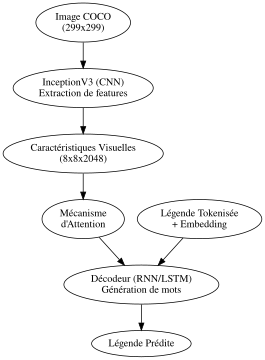

In [33]:
if "chrono_partie" in globals():
    chrono_partie("B. Modèle et entraînement")                       # chronomètre : début de la partie
import graphviz

dot = graphviz.Digraph(comment='Architecture du Système', format='png')
dot.attr(rankdir='TB', size='8,5')

dot.node('A', 'Image COCO\n(299x299)')
dot.node('B', 'InceptionV3 (CNN)\nExtraction de features')
dot.node('C', 'Caractéristiques Visuelles\n(8x8x2048)')
dot.node('D', 'Mécanisme\nd\'Attention')
dot.node('E', 'Légende Tokenisée\n+ Embedding')
dot.node('F', 'Décodeur (RNN/LSTM)\nGénération de mots')
dot.node('G', 'Légende Prédite')

dot.edge('A', 'B')
dot.edge('B', 'C')
dot.edge('C', 'D')
dot.edge('D', 'F')
dot.edge('E', 'F')
dot.edge('F', 'G')

dot

Au lieu d'entraîner un réseau à partir de zéro, nous allons réutiliser les connaissances accumulées d'InceptionV3. Nous retirons la couche finale qui décide de la classe de l'image et ne conservons que la partie qui « perçoit » les motifs visuels. Ainsi, le réseau reçoit l'image et la traduit en un vecteur numérique dense qui résume ses principales caractéristiques visuelles.

### Le schéma détaillé, avec les dimensions

Le schéma précédent donne l'idée générale. Celui-ci suit les données à travers le modèle avec leurs dimensions exactes. La partie haute, l'encodeur, ne tourne qu'une fois par image. La partie basse, le décodeur, tourne une fois par mot : à chaque pas, l'attention combine les 64 régions de l'image selon l'état de la mémoire du LSTM, le LSTM reçoit ce résumé et le mot précédent, et la dernière couche donne une probabilité à chacun des 10 027 mots du vocabulaire. Le mot choisi redevient l'entrée du pas suivant, jusqu'au mot de fin `<end>`.

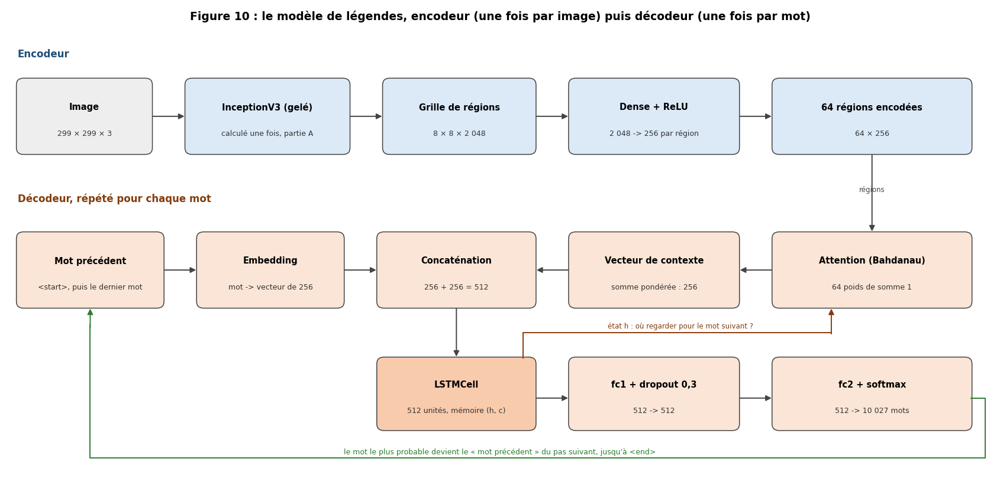

In [34]:
# Le modèle de la partie B avec les dimensions de chaque étape
from matplotlib.patches import FancyBboxPatch


def bloc(ax, x, y, l, h, titre, detail, couleur):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=couleur, ec="#444444", lw=1.1))
    ax.text(x + l / 2, y + h * 0.63, titre, ha="center", va="center", fontsize=10.5, fontweight="bold")
    ax.text(x + l / 2, y + h * 0.27, detail, ha="center", va="center", fontsize=9, color="#333333")


def trait(ax, x1, y1, x2, y2, texte="", style="-|>", couleur="#444444", decal=0.15, rayon=0.0):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, color=couleur, lw=1.4, mutation_scale=14, connectionstyle=f"arc3,rad={rayon}"))
    if texte:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + decal, texte, ha="center", va="bottom", fontsize=8.5, color=couleur)


fig, ax = plt.subplots(figsize=(17, 8.2))
ax.set_xlim(0, 17); ax.set_ylim(0, 8.2); ax.axis("off")
ax.text(8.5, 7.95, "Figure 10 : le modèle de légendes, encodeur (une fois par image) puis décodeur (une fois par mot)", ha="center", fontsize=13.5, fontweight="bold")
ax.text(0.2, 7.3, "Encodeur", fontsize=12, fontweight="bold", color="#1F4E79")
bloc(ax, 0.2, 5.6, 2.3, 1.3, "Image", "299 × 299 × 3", "#EEEEEE")
bloc(ax, 3.1, 5.6, 2.8, 1.3, "InceptionV3 (gelé)", "calculé une fois, partie A", "#DCE9F7")
bloc(ax, 6.5, 5.6, 2.6, 1.3, "Grille de régions", "8 × 8 × 2 048", "#DCE9F7")
bloc(ax, 9.7, 5.6, 2.9, 1.3, "Dense + ReLU", "2 048 -> 256 par région", "#DCE9F7")
bloc(ax, 13.2, 5.6, 3.4, 1.3, "64 régions encodées", "64 × 256", "#DCE9F7")
for a, b in ((2.5, 3.1), (5.9, 6.5), (9.1, 9.7), (12.6, 13.2)):
    trait(ax, a, 6.25, b, 6.25)
ax.text(0.2, 4.75, "Décodeur, répété pour chaque mot", fontsize=12, fontweight="bold", color="#843C0C")
bloc(ax, 0.2, 2.9, 2.5, 1.3, "Mot précédent", "<start>, puis le dernier mot", "#FBE5D6")
bloc(ax, 3.3, 2.9, 2.5, 1.3, "Embedding", "mot -> vecteur de 256", "#FBE5D6")
bloc(ax, 13.2, 2.9, 3.4, 1.3, "Attention (Bahdanau)", "64 poids de somme 1", "#FBE5D6")
bloc(ax, 9.7, 2.9, 2.9, 1.3, "Vecteur de contexte", "somme pondérée : 256", "#FBE5D6")
bloc(ax, 6.4, 2.9, 2.7, 1.3, "Concaténation", "256 + 256 = 512", "#FBE5D6")
bloc(ax, 6.4, 0.75, 2.7, 1.25, "LSTMCell", "512 unités, mémoire (h, c)", "#F8CBAD")
bloc(ax, 9.7, 0.75, 2.9, 1.25, "fc1 + dropout 0,3", "512 -> 512", "#FBE5D6")
bloc(ax, 13.2, 0.75, 3.4, 1.25, "fc2 + softmax", "512 -> 10 027 mots", "#FBE5D6")
trait(ax, 2.7, 3.55, 3.3, 3.55)
trait(ax, 5.8, 3.55, 6.4, 3.55)
trait(ax, 14.9, 5.6, 14.9, 4.2, "régions", decal=0.0)
trait(ax, 13.2, 3.55, 12.6, 3.55)
trait(ax, 9.7, 3.55, 9.1, 3.55)
trait(ax, 7.75, 2.9, 7.75, 2.0)
trait(ax, 9.1, 1.3, 9.7, 1.3)
trait(ax, 12.6, 1.3, 13.2, 1.3)
ax.plot([8.9, 8.9, 14.2], [2.0, 2.45, 2.45], color="#843C0C", lw=1.4)
trait(ax, 14.2, 2.4, 14.2, 2.9, couleur="#843C0C")
ax.text(11.6, 2.5, "état h : où regarder pour le mot suivant ?", ha="center", va="bottom", fontsize=8.5, color="#843C0C")
ax.plot([16.6, 16.85, 16.85, 1.45, 1.45], [1.3, 1.3, 0.25, 0.25, 2.6], color="#2E7D32", lw=1.4)
trait(ax, 1.45, 2.5, 1.45, 2.9, couleur="#2E7D32")
ax.text(8.5, 0.32, "le mot le plus probable devient le « mot précédent » du pas suivant, jusqu'à <end>", ha="center", fontsize=9, color="#2E7D32")
plt.tight_layout(); plt.show()

Le schéma montre où se trouvent les paramètres. L'encodeur n'en a que 524 544 (la couche dense de 2 048 vers 256). Le décodeur en a 10 730 540, dont plus de la moitié dans la dernière couche, qui relie les 512 valeurs du LSTM à chacun des 10 027 mots : c'est la taille du vocabulaire, plus que la profondeur du réseau, qui fixe la taille du modèle.

## 11. Définition des classes Encodeur, Mécanisme d'attention et Décodeur

#### Encodeur (CNN - InceptionV3)
Dans la section 8, nous avons choisi InceptionV3 comme CNN pré-entraîné pour extraire les caractéristiques principales des images. Cela s'effectue en transformant ces images en une carte spatiale de format (batch_size, 8, 8, 2048). Le CNN est gelé, et ses sorties sont déjà enregistrées dans le paquet de la partie A : il ne tourne donc pas pendant l'entraînement.

La classe `InceptionEncodeur` reçoit ces caractéristiques (stockées en float16), les convertit en float32 et réorganise la grille 8 × 8 en une liste de 64 régions, de forme (batch_size, 64, 2048). Une couche dense avec activation ReLU projette ensuite chaque région en 256 valeurs (`embedding_dim`), ce qui donne une sortie de forme (batch_size, 64, 256). Cette couche compte 524 544 paramètres (2 048 × 256 poids et 256 biais).

Ainsi, l'encodeur constitue précisément le pont entre l'image visuelle et l'espace numérique du décodeur : chaque région de l'image garde sa place dans la liste, ce qui permet à l'attention de dire où regarder.

In [35]:
import time, json
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers

class InceptionEncodeur(tf.keras.Model):
    """(B, 8, 8, 2048) float16 -> (B, 64, embedding_dim) : aplatit la grille et projette (partie apprenable)."""
    def __init__(self, embedding_dim):
        super().__init__()
        self.fc = layers.Dense(embedding_dim, activation="relu")

    def call(self, image_features):
        x = tf.cast(image_features, tf.float32)
        s = tf.shape(x)
        x = tf.reshape(x, (s[0], -1, x.shape[-1]))      # (B, 64, 2048)
        return self.fc(x)                               # (B, 64, embedding_dim)


class BahdanauAttention(tf.keras.layers.Layer):
    """Attention additive. W1(features) est calculé UNE fois par lot (project), pas à chaque mot."""
    def __init__(self, units):
        super().__init__()
        self.W1, self.W2, self.V = layers.Dense(units), layers.Dense(units), layers.Dense(1)

    def project(self, features):
        return self.W1(features)                        # (B, 64, units)

    def call(self, features, features_proj, hidden):
        score = tf.nn.tanh(features_proj + self.W2(tf.expand_dims(hidden, 1)))
        weights = tf.nn.softmax(self.V(score), axis=1)                  # (B, 64, 1)
        context = tf.reduce_sum(weights * features, axis=1)             # (B, embedding_dim)
        return context, weights


class Decodeur(tf.keras.Model):
    """Un pas de temps : (mot précédent, image, état (h, c)) -> (logits, nouvel état, poids d'attention)."""
    def __init__(self, taille_vocab, embedding_dim, units):
        super().__init__()
        self.units = units
        self.embedding = layers.Embedding(taille_vocab, embedding_dim)
        self.attention = BahdanauAttention(units)
        self.cell = layers.LSTMCell(units)               # l'état (h, c) est réellement propagé
        self.init_h = layers.Dense(units, activation="tanh")
        self.init_c = layers.Dense(units, activation="tanh")
        self.fc1 = layers.Dense(units, activation="relu")
        self.drop = layers.Dropout(0.3)
        self.fc2 = layers.Dense(taille_vocab)

    def etat_initial(self, features):
        moyenne = tf.reduce_mean(features, axis=1)       # résumé global de l'image
        return self.init_h(moyenne), self.init_c(moyenne)

    def call(self, mot, features, features_proj, h, c, training=False):
        context, poids = self.attention(features, features_proj, h)     # h = état avant ce mot
        x = tf.concat([context, self.embedding(mot)], axis=-1)          # mot : (B,)
        sortie, (h, c) = self.cell(x, states=[h, c], training=training)
        logits = self.fc2(self.drop(self.fc1(sortie), training=training))
        return logits, h, c, poids

#### Mécanisme d'attention
Dans les architectures traditionnelles (Encodeur-Décodeur sans mécanisme d'attention), l'image entière était compressée en un vecteur fixe unique, fourni au réseau de neurones récurrent (RNN) uniquement au début. Cela entraînait une perte des détails visuels au fur et à mesure que la phrase s'allongeait.

**Cartes de caractéristiques spatiales :** Au lieu d'un vecteur global unique, on utilise la sortie d'une couche convolutive précédente (préservant ainsi la division de l'image en régions, ici une grille $8 \times 8 \times 2048$, soit 64 régions de l'image).

**Calcul dynamique des poids :** À chaque étape, le mécanisme d'attention détermine quelles régions de l'image sont les plus pertinentes pour le mot spécifique que le RNN est en train de générer (par exemple, se concentrer sur le chien lors de la génération du mot « dog »).

**Vecteur de contexte mis à jour :** Les cartes de caractéristiques sont multipliées par les poids d'attention afin de générer un vecteur de contexte dynamique, qui guide le processus de décodage avec précision à chaque pas de temps.

**Le calcul dans notre code (attention de Bahdanau, dite additive) :** pour chaque région, on additionne sa projection `W1(features)` et la projection de l'état caché du LSTM `W2(hidden)`, on passe la somme dans une tangente hyperbolique, puis la couche `V` donne un score par région. Un softmax sur les 64 régions transforme ces scores en poids positifs de somme 1. Le vecteur de contexte est la somme des régions pondérées par ces poids. Comme `W1(features)` ne dépend que de l'image, il est calculé une seule fois par image (méthode `project`) au lieu d'être recalculé à chaque mot.

**Principaux avantages :** Cette approche permet de produire des légendes plus descriptives et plus exactes. Elle offre également une certaine interprétabilité grâce à des cartes de chaleur (« heatmaps ») qui indiquent les zones sur lesquelles le réseau s'est concentré lors de la génération de chaque mot.

#### Décodeur
**Initialisation de la classe et des composants (`__init__`)** :
Le constructeur configure les outils linguistiques et de mémoire du Décodeur. Nous créons la couche d'embedding (plongement lexical), qui transforme l'indice de chaque mot en un vecteur de 256 valeurs ; le mécanisme d'attention de Bahdanau ; une cellule LSTM (`LSTMCell`) de 512 unités, qui avance d'un mot à la fois ; deux couches denses `init_h` et `init_c`, qui calculent l'état de départ du LSTM ; enfin une couche intermédiaire `fc1` (512 unités, ReLU), un *dropout* de 0,3 contre le surapprentissage, et la couche finale `fc2`, dimensionnée sur la taille du vocabulaire (10 027 mots). Les poids sont initialisés avec les valeurs par défaut de Keras.

**État initial (`etat_initial`) :** Avant le premier mot, le LSTM a besoin d'une mémoire de départ. Plutôt que de partir de zéros, on calcule la moyenne des 64 régions de l'image, puis `init_h` et `init_c` (activation tanh) en tirent l'état caché `h` et l'état de cellule `c`. Le décodeur commence ainsi la phrase en ayant déjà une vue d'ensemble de l'image, et chaque image a sa propre mémoire de départ, sans aucun résidu des images précédentes.

**Calcul de l'attention et embedding (`call` - Début) :** À chaque pas, le Décodeur active le mécanisme d'attention avec les régions de l'image et l'état caché `h` du LSTM avant ce mot ; il obtient ainsi un vecteur de contexte (un résumé visuel ciblé sur la partie utile pour le mot à écrire). Parallèlement, le mot précédent passe par la couche d'embedding.

**Fusion multimodale et LSTM (`tf.concat` et `self.cell`) :** Pour combiner vision et langage, nous concaténons le vecteur de contexte visuel avec l'embedding du mot précédent à l'aide de `tf.concat`. Ce vecteur est transmis à la cellule LSTM, qui met à jour sa mémoire (`h` et `c`) et renvoie sa sortie pour ce pas de temps.

**Projection vers le vocabulaire et retour (`fc1`, `fc2`) :** La sortie du LSTM passe par `fc1`, puis par le *dropout* (actif seulement pendant l'entraînement), et atteint la couche finale `fc2`, qui génère les *logits* (scores bruts pour chaque mot du vocabulaire). La méthode renvoie quatre éléments : les logits du mot suivant, le nouvel état `h`, le nouvel état `c` et les poids d'attention (utilisés plus tard pour les cartes de chaleur / *heatmaps*). Au total, le décodeur compte 10 730 540 paramètres, dont plus de la moitié dans `fc2`.

## 12. Entraînement et Validation

* **Configuration et Initialisation :**
Création des instances de l'encodeur et du décodeur, et définition de l'optimiseur Adam, avec un écrêtage de la norme des gradients à 5 (`clipnorm`) pour éviter toute instabilité. Le nombre d'époques est fixé à **12**. Le taux d'apprentissage part de 0,001 et diminue progressivement en suivant un cosinus jusqu'à 0,00001 à la fin de la douzième époque : de grands pas au début pour apprendre vite, de petits pas à la fin pour affiner sans abîmer ce qui est appris. Avec un taux constant, le modèle se met à surapprendre bien avant la douzième époque. Cet optimiseur a été choisi car il ajuste dynamiquement le pas de chaque poids et est particulièrement adapté aux réseaux récurrents. On initialise également la fonction de perte *SparseCategoricalCrossentropy*, adaptée à la prédiction du mot suivant parmi tout le vocabulaire. Un premier appel sur des données nulles crée tous les poids avant la compilation par `tf.function`.

* **Perte Masquée (*masked loss*) :**
Calcul de l'erreur des prédictions en ignorant le *padding* (les zéros utilisés pour compléter les légendes plus courtes), garantissant ainsi que le modèle n'apprend qu'à partir de mots réels. La perte est une moyenne par mot réel.

* **Passage avant (*forward pass*) :**
Projection des régions de l'image par l'encodeur et par `W1`, une seule fois par image, puis copie pour chacune des cinq légendes de l'image. Le décodeur parcourt ensuite la légende mot par mot avec la technique du *Teacher Forcing*.

* **Étapes d'optimisation et de validation (`train_step` et `val_step`) :**
La fonction `train_step` calcule les gradients de l'erreur à l'aide de `GradientTape` et met à jour les poids des réseaux de l'encodeur et du décodeur. La fonction `val_step`, quant à elle, évalue simplement les performances du modèle sans modifier les poids, permettant ainsi de suivre la validation.

### La technique du *Teacher Forcing* lors de l'entraînement du décodeur

Lors de l'entraînement de modèles de génération de langage (tels que les réseaux de légendage d'images), la stratégie d'alimentation du décodeur est optimisée grâce à la technique du **Teacher Forcing**.

Au moment de l'utilisation, le modèle génère un mot à chaque pas et utilise cette prédiction comme entrée pour le pas suivant. Cependant, au début de l'entraînement, les prédictions du modèle contiennent souvent des erreurs. Si ces prédictions erronées étaient réinjectées dans le réseau, l'erreur se propagerait et s'accumulerait rapidement, compromettant gravement la convergence de l'apprentissage. Pour atténuer ce problème, le *Teacher Forcing* donne en entrée au décodeur le **mot réel et correct (la « vérité terrain » ou *ground truth*)** de la légende, au lieu du mot que le modèle vient de prédire. Cette stratégie offre des avantages fondamentaux pour le projet :

* **Accélération et stabilité de l'apprentissage :** En recevant systématiquement le contexte correct, le réseau apprend beaucoup plus rapidement la syntaxe, la grammaire et les relations entre les mots, sans gaspiller l'entraînement à corriger des dérives accumulées.
* **Entrées connues à l'avance :** Toute la suite des mots d'entrée est connue avant de commencer, il n'y a donc rien à générer pendant l'entraînement. On peut traiter d'un coup les cinq légendes de chacune des 32 images d'un lot (160 phrases en parallèle), ce qui utilise bien le GPU. Les pas de temps restent en revanche calculés l'un après l'autre, comme dans tout réseau récurrent.

La contrepartie est un écart entre l'entraînement et l'utilisation (*exposure bias*) : en production, le modèle n'a jamais le vrai mot précédent et doit continuer à partir de ses propres choix, y compris quand il s'est trompé.

In [36]:
EMBEDDING_DIM, UNITS = 256, 512
encoder = InceptionEncodeur(EMBEDDING_DIM)
decoder = Decodeur(TAILLE_VOCAB, EMBEDDING_DIM, UNITS)      # TAILLE_VOCAB vient de la partie A
EPOCHS = 12                                                 # nombre d'époques d'entraînement
LOTS_PAR_EPOQUE = int(np.ceil(len(idx_train) / BATCH_IMAGES))
# Taux d'apprentissage : 1e-3 au départ, puis baisse progressive (cosinus) jusqu'à 1e-5 à la fin de la dernière époque
taux = tf.keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=EPOCHS * LOTS_PAR_EPOQUE, alpha=0.01)
optimizer = tf.keras.optimizers.Adam(taux, clipnorm=5.0)
_ce = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction="none")

# Construit les poids avant le tf.function (évite de créer des variables pendant le traçage)
_f = encoder(tf.zeros((1, 8, 8, 2048))); _p = decoder.attention.project(_f); _h, _c = decoder.etat_initial(_f)
decoder(tf.zeros((1,), tf.int32), _f, _p, _h, _c)
optimizer.build(encoder.trainable_variables + decoder.trainable_variables)   # pour la reprise

def perte_masquee(reel, pred):
    """Moyenne par mot réel (le padding, id 0, est ignoré)."""
    masque = tf.cast(reel != 0, tf.float32)
    return tf.reduce_sum(_ce(reel, pred) * masque), tf.reduce_sum(masque)

def passe_avant(img, entree, cible, training):
    """img (B,8,8,2048) ; entree/cible (B,5,T) -> (somme des pertes, nb de mots)."""
    nb_leg, T = entree.shape[1], entree.shape[2]
    feats = encoder(img)                                     # (B, 64, E)   calculé une fois par image
    proj = decoder.attention.project(feats)                  # (B, 64, U)   idem
    feats = tf.repeat(feats, nb_leg, axis=0)                 # (5B, 64, E)  une copie par légende
    proj = tf.repeat(proj, nb_leg, axis=0)
    entree = tf.reshape(entree, (-1, T)); cible = tf.reshape(cible, (-1, T))
    h, c = decoder.etat_initial(feats)
    total, n = 0.0, 0.0
    for t in range(T):                                       # teacher forcing : entrée[t] -> cible[t]
        logits, h, c, _ = decoder(entree[:, t], feats, proj, h, c, training=training)
        p, m = perte_masquee(cible[:, t], logits)
        total += p; n += m
    return total, n

@tf.function
def train_step(img, entree, cible):
    with tf.GradientTape() as tape:
        total, n = passe_avant(img, entree, cible, training=True)
        perte = total / tf.maximum(n, 1.0)
    vars_ = encoder.trainable_variables + decoder.trainable_variables
    optimizer.apply_gradients(zip(tape.gradient(perte, vars_), vars_))
    return perte

@tf.function
def val_step(img, entree, cible):
    return passe_avant(img, entree, cible, training=False)   # (somme, nb mots)

Durée de la cellule : 1.8 s


#### Boucle d'entraînement avec validation réelle
* **Évaluation (`evaluer`) :** Parcourt les lots de validation (300 lots au plus, ici les 157 lots des 5 000 images) pour calculer la perte moyenne par mot du modèle.
* **Entraînement principal (`entrainer`) :** Exécute les époques d'entraînement, affiche la perte tous les 500 lots et calcule la perte de validation à la fin de chaque époque. Les poids de l'encodeur et du décodeur sont sauvegardés chaque fois que la perte de validation baisse d'au moins 0,005 : on garde ainsi le **meilleur** modèle, pas le dernier. L'arrêt précoce (*early stopping*) interrompt l'entraînement si la validation ne progresse plus pendant 3 époques.
* **Reprise après une coupure :** à la fin de chaque époque, l'état complet de l'entraînement (poids, état de l'optimiseur, position dans le planning du taux d'apprentissage, historique) est enregistré sur le Drive, dans `modele_L3/reprise`. Si Colab s'arrête, il suffit de relancer : l'entraînement repart à l'époque suivante au lieu de recommencer à zéro. Une fois les 12 époques faites, la cellule ne fait que recharger le meilleur modèle.
* **Génération de légendes (`generer`) :** Effectue une recherche gloutonne (*greedy search*) pour prédire et générer la légende, mot à mot, à partir d'une image : à chaque pas, le mot le plus probable est choisi et redonné en entrée, jusqu'au jeton de fin ou 16 mots au plus.

In [37]:
# Boucle d'entraînement avec validation réelle et reprise après une coupure de Colab

def evaluer(ds, max_lots=None):
    total, n = 0.0, 0.0
    for k, ((img, ent), cib) in enumerate(ds):
        if max_lots and k >= max_lots: break
        s, m = val_step(img, ent, cib); total += float(s); n += float(m)
    return total / n

def entrainer(ds_train, ds_val, dossier, epochs=12, patience=3, min_delta=0.005, lots_val=300):
    """Entraîne jusqu'à `epochs` époques. À la fin de chaque époque, l'état complet (poids, optimiseur, historique)
    est enregistré sur le Drive : après une coupure, relancer la cellule reprend à l'époque suivante."""
    fichier_hist = dossier / "historique.json"
    point = tf.train.Checkpoint(encoder=encoder, decoder=decoder, optimizer=optimizer)
    gestion = tf.train.CheckpointManager(point, str(dossier / "reprise"), max_to_keep=1)
    hist = {"lots": [], "pertes": [], "train": [], "val": [], "meilleure": None, "meilleure_epoque": None,
            "attente": 0, "global_lot": 0, "arret_precoce": False}
    if gestion.latest_checkpoint and fichier_hist.exists():
        point.restore(gestion.latest_checkpoint)
        hist = json.load(open(fichier_hist))
        print(f"Reprise : {len(hist['val'])} époque(s) déjà faite(s) lors d'une exécution précédente :")
        for e, (t, v) in enumerate(zip(hist["train"], hist["val"]), 1):
            print(f"Époque {e}/{epochs} | train {t:.4f} | val {v:.4f}" + ("   <- meilleur modèle" if e == hist["meilleure_epoque"] else ""))
    meilleure = hist["meilleure"] if hist["meilleure"] is not None else float("inf")
    for ep in range(len(hist["val"]), epochs):
        if hist["arret_precoce"]:
            break
        t0, somme, nb = time.time(), 0.0, 0
        for k, ((img, ent), cib) in enumerate(ds_train):
            p = float(train_step(img, ent, cib)); somme += p; nb += 1; hist["global_lot"] += 1
            if k % 500 == 0:
                print(f"Époque {ep+1} | lot {k} | perte {p:.4f}")
                hist["lots"].append(hist["global_lot"]); hist["pertes"].append(p)
        v = evaluer(ds_val, lots_val)                        # perte de VALIDATION (par mot)
        hist["train"].append(somme / nb); hist["val"].append(v)
        print(f"Époque {ep+1}/{epochs} | train {somme/nb:.4f} | val {v:.4f} | {time.time()-t0:.0f}s")
        if v < meilleure - min_delta:
            meilleure, hist["attente"], hist["meilleure_epoque"] = v, 0, ep + 1
            encoder.save_weights(str(dossier / "encoder.weights.h5"))      # on garde le MEILLEUR modèle
            decoder.save_weights(str(dossier / "decoder.weights.h5"))
            print("   -> meilleur modèle sauvegardé")
        else:
            hist["attente"] += 1
            if hist["attente"] >= patience:
                hist["arret_precoce"] = True
                print("[Early stopping sur la validation]")
        hist["meilleure"] = meilleure
        gestion.save()                                       # point de reprise : poids, optimiseur, numéro du lot
        with open(fichier_hist, "w") as f:
            json.dump(hist, f)
    return hist


# Génération gloutonne (test rapide + base pour la partie C)

def generer(img, vocab, debut=2, fin=3, longueur_max=16):
    """img (1,8,8,2048) -> légende (liste de mots)."""
    feats = encoder(img); proj = decoder.attention.project(feats)
    h, c = decoder.etat_initial(feats)
    mot, mots = tf.constant([debut]), []
    for _ in range(longueur_max):
        logits, h, c, _ = decoder(mot, feats, proj, h, c, training=False)
        mot = tf.argmax(logits, axis=-1, output_type=tf.int32)
        if int(mot[0]) == fin: break
        mots.append(vocab[int(mot[0])])
    return mots

Cette cellule lance l'entraînement, recharge le meilleur modèle et affiche les courbes d'apprentissage :

* **Entraînement :** 12 époques sur les 113 287 images du train, environ 8 minutes par époque sur un GPU T4, soit un peu plus d'une heure et demie. Le meilleur modèle et l'historique sont écrits dans `modele_L3`.
* **Graphique :** à gauche, la perte d'entraînement relevée tous les 500 lots ; à droite, les pertes moyennes d'entraînement et de validation de chaque époque, avec l'époque du meilleur modèle.
* **Test visuel rapide :** trois légendes générées en glouton sur un lot de validation.

Les deux courbes doivent baisser ensemble au début. Si la perte d'entraînement continue de baisser alors que celle de validation remonte, le modèle commence à apprendre ses exemples par cœur : c'est pour cela qu'on garde l'époque où la validation est la plus basse.

Reprise : 5 époque(s) déjà faite(s) lors d'une exécution précédente :
Époque 1/12 | train 3.1470 | val 2.6036
Époque 2/12 | train 2.5534 | val 2.4480
Époque 3/12 | train 2.4076 | val 2.3819
Époque 4/12 | train 2.3161 | val 2.3496
Époque 5/12 | train 2.2455 | val 2.3305   <- meilleur modèle
Époque 6 | lot 0 | perte 2.1987
Époque 6 | lot 500 | perte 2.2431
Époque 6 | lot 1000 | perte 2.2076
Époque 6 | lot 1500 | perte 2.2158
Époque 6 | lot 2000 | perte 2.1458
Époque 6 | lot 2500 | perte 2.1240
Époque 6 | lot 3000 | perte 2.2716
Époque 6 | lot 3500 | perte 2.0315
Époque 6/12 | train 2.1692 | val 2.3217 | 271s
   -> meilleur modèle sauvegardé
Époque 7 | lot 0 | perte 2.0684
Époque 7 | lot 500 | perte 2.0963
Époque 7 | lot 1000 | perte 2.2753
Époque 7 | lot 1500 | perte 2.2126
Époque 7 | lot 2000 | perte 2.0530
Époque 7 | lot 2500 | perte 2.0390
Époque 7 | lot 3000 | perte 1.9928
Époque 7 | lot 3500 | perte 2.1687
Époque 7/12 | train 2.1140 | val 2.3234 | 256s
Époque 8 | lot 0 | perte 2.151

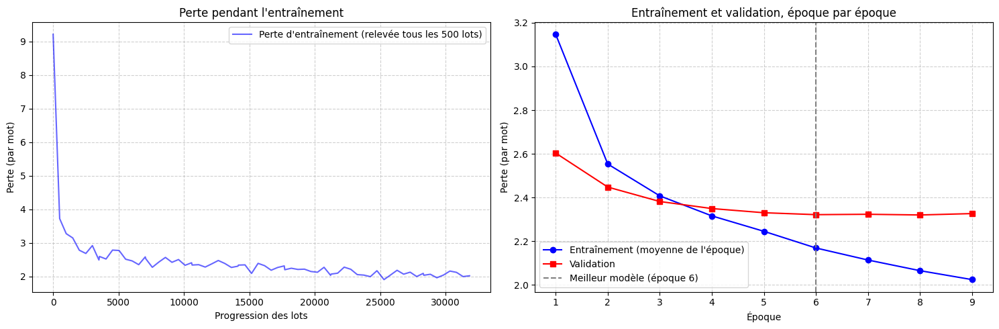

a woman holding a wii remote in her hand
a group of people sitting around a table eating pizza
a computer mouse sitting next to a keyboard
Durée de la cellule : 17 min 47 s


In [38]:
import json
import matplotlib.pyplot as plt

# Dossier des poids de ce notebook (les poids enregistrés plus tôt dans model_liv3 restent intacts)
DOSSIER_MODELE = RACINE / "modele_L3"
DOSSIER_MODELE.mkdir(exist_ok=True)

EPOCH_PATIENCE = 3
MIN_DELTA = 0.005

# Entraîne, ou reprend là où une coupure de Colab l'avait arrêté ; si les 12 époques sont déjà faites, ne fait rien
hist = entrainer(ds_train, ds_val, DOSSIER_MODELE, epochs=EPOCHS, patience=EPOCH_PATIENCE, min_delta=MIN_DELTA)

# On repart du MEILLEUR modèle, pas de celui de la dernière époque
encoder.load_weights(str(DOSSIER_MODELE / "encoder.weights.h5"))
decoder.load_weights(str(DOSSIER_MODELE / "decoder.weights.h5"))
print(f"Entraînement terminé après {len(hist['val'])} époques ; meilleur modèle : époque {hist['meilleure_epoque']}, "
      f"perte de validation {hist['meilleure']:.4f}. Poids dans {DOSSIER_MODELE}")

# GRAPHIQUE
epoques = range(1, len(hist["val"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(hist["lots"], hist["pertes"], color="b", alpha=0.6, label="Perte d'entraînement (relevée tous les 500 lots)")
axes[0].set_xlabel("Progression des lots"); axes[0].set_ylabel("Perte (par mot)")
axes[0].set_title("Perte pendant l'entraînement")
axes[1].plot(epoques, hist["train"], marker="o", color="b", label="Entraînement (moyenne de l'époque)")
axes[1].plot(epoques, hist["val"], marker="s", color="r", label="Validation")
axes[1].axvline(hist["meilleure_epoque"], color="gray", ls="--", label=f"Meilleur modèle (époque {hist['meilleure_epoque']})")
axes[1].set_xlabel("Époque"); axes[1].set_ylabel("Perte (par mot)"); axes[1].set_xticks(list(epoques))
axes[1].set_title("Entraînement et validation, époque par époque")
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.6); ax.legend()
plt.tight_layout()
plt.show()

# Test visuel rapide
(img, ent), cib = next(iter(ds_val))
for k in range(3):
    print(" ".join(generer(img[k:k+1], VOCAB)))

L'entraînement s'est arrêté après **9 époques sur 12** : l'arrêt anticipé a jugé que la validation ne progressait plus. Chaque époque a pris environ 8 minutes (de 469 à 512 secondes), soit environ 75 minutes en tout.

* **La perte de validation baisse nettement au début**, de 2,606 à l'époque 1 à 2,384 à l'époque 3, puis de plus en plus lentement jusqu'à **2,3235 à l'époque 6**, le meilleur modèle enregistré.
* **Ensuite, elle ne bouge presque plus** (2,3190, 2,3202, 2,3197), alors que la perte d'entraînement continue de descendre, de 2,190 à 2,052. Le modèle progresse encore sur ses propres exemples, mais plus sur des images nouvelles : c'est le début du surapprentissage, et l'arrêt à l'époque 9 est justifié.
* **Un point à noter honnêtement :** l'époque 7 était très légèrement meilleure que l'époque 6 (2,3190 contre 2,3235). Elle n'a pas été enregistrée parce que l'amélioration minimale exigée est de 0,005. L'écart de 0,2 % est sans effet pratique sur les légendes, et ce seuil évite justement d'enregistrer des variations dues au hasard.

Les trois légendes de test sont déjà des phrases correctes, mais l'une confond le sujet (un garçon devient *a woman*) et une autre se répète (*a computer keyboard with a mouse and keyboard*) : la suite analyse ces défauts.

### Visualisations du modèle entraîné

Les courbes de perte disent si l'entraînement s'est bien passé, mais pas ce que le modèle a appris. Les figures suivantes regardent le modèle de plus près : comment le taux d'apprentissage a évolué, ce qu'il écrit sur des images de validation, comment il choisit chaque mot, et ce que représentent ses vecteurs de mots.

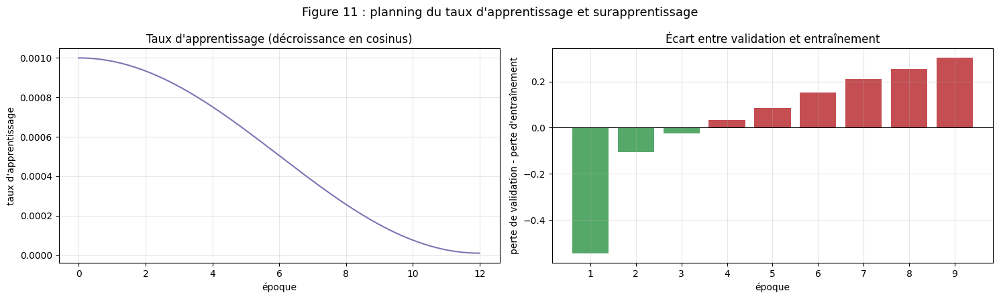

In [39]:
import textwrap
# Taux d'apprentissage et écart entre entraînement et validation
pas_lr = np.linspace(0, EPOCHS * LOTS_PAR_EPOQUE, 200)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(pas_lr / LOTS_PAR_EPOQUE, [float(taux(int(p))) for p in pas_lr], color="#8172B3")
axes[0].set_xlabel("époque"); axes[0].set_ylabel("taux d'apprentissage"); axes[0].set_title("Taux d'apprentissage (décroissance en cosinus)")
ecart = np.array(hist["val"]) - np.array(hist["train"])
axes[1].bar(range(1, len(ecart) + 1), ecart, color=["#55A868" if e <= 0 else "#C44E52" for e in ecart])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xlabel("époque"); axes[1].set_ylabel("perte de validation - perte d'entraînement")
axes[1].set_title("Écart entre validation et entraînement"); axes[1].set_xticks(range(1, len(ecart) + 1))
for ax in axes:
    ax.grid(alpha=0.3)
plt.suptitle("Figure 11 : planning du taux d'apprentissage et surapprentissage", fontsize=13)
plt.tight_layout(); plt.show()

À gauche, le taux d'apprentissage part de 0,001 et décroît en suivant un cosinus jusqu'à 0,00001 à la fin de la douzième époque ; comme l'entraînement s'est arrêté à la neuvième, le modèle n'a pas vu la fin du planning, où les pas deviennent très petits. À droite, l'écart entre les deux pertes raconte l'entraînement :

* **époques 1 à 3, barres vertes** : la perte de validation est plus basse que celle d'entraînement (jusqu'à 0,54 de moins). Ce n'est pas une anomalie : le *dropout* n'est actif que pendant l'entraînement, et la perte d'entraînement est une moyenne sur une époque pendant laquelle le modèle s'améliorait encore ;
* **à partir de l'époque 4, barres rouges qui grandissent régulièrement**, jusqu'à 0,27 à l'époque 9 : le modèle apprend de plus en plus ses exemples d'entraînement. C'est le signal qui justifie de garder le modèle de l'époque 6 plutôt que celui de la dernière époque.

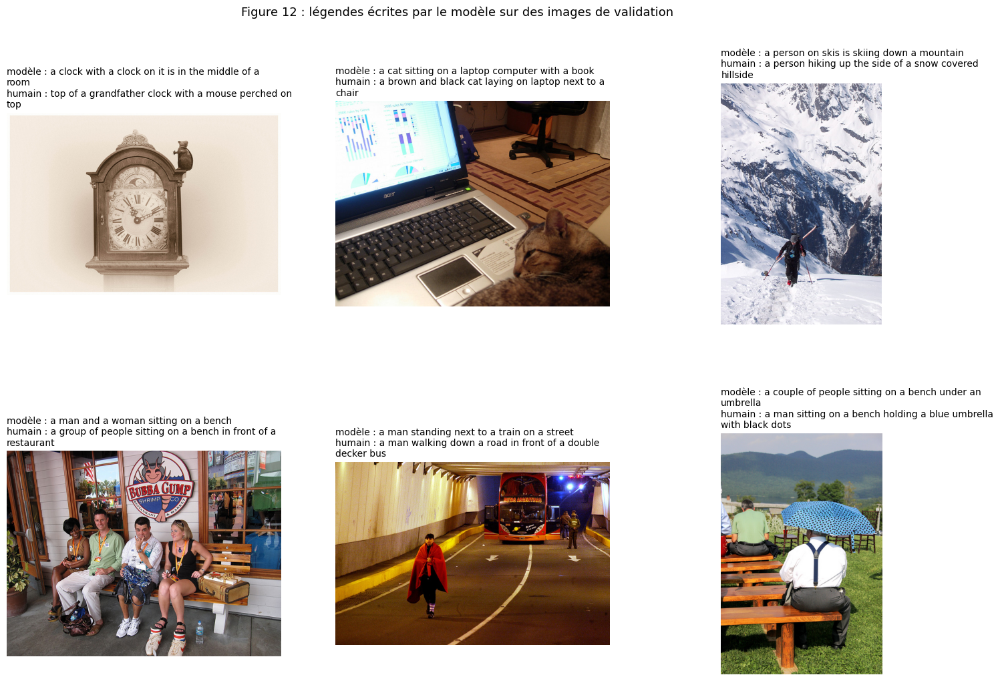

Durée de la cellule : 1.7 s


In [40]:
# Légendes du modèle sur des images de validation
choix_v = np.sort(np.random.default_rng(SEED + 3).choice(idx_val, 6, replace=False))
fig, axes = plt.subplots(2, 3, figsize=(18, 11.5), gridspec_kw={"hspace": 0.45})
for ax, i in zip(axes.ravel(), choix_v):
    ax.imshow(Image.open(assurer_image(chemins[i])).convert("RGB")); ax.axis("off")
    modele = " ".join(generer(tf.constant(CARACT[np.array([i])]), VOCAB))
    humain = legendes_brutes[i][0].strip().rstrip(".").lower()
    ax.set_title("modèle : " + "\n".join(textwrap.wrap(modele, 50)) + "\nhumain : " + "\n".join(textwrap.wrap(humain, 50)),
                 fontsize=10, loc="left")
plt.suptitle("Figure 12 : légendes écrites par le modèle sur des images de validation", fontsize=13)
plt.show()

Sur ces six images de validation, le modèle reprend la structure typique de COCO, « un sujet, une action, un lieu », et nomme souvent bien l'objet principal : le chat sur l'ordinateur portable, le groupe assis sur un banc, l'homme près d'un bus. Ses erreurs sont instructives :

* **un détail manqué** : le bus est un bus à impériale, et le banc est devant un restaurant ; le modèle donne une version plus générale de la scène ;
* **une scène mal interprétée** : un randonneur dans la neige devient *a person on skis*, parce que neige et montagne vont presque toujours avec le ski dans COCO ;
* **une invention** : sous le parapluie, il n'y a qu'un homme, mais le modèle écrit *a man and a woman*, une association fréquente dans les légendes d'entraînement ;
* **une répétition** : *a clock on a wall with a clock on it*. Le modèle a perdu le fil de ce qu'il avait déjà écrit, un défaut connu des décodeurs récurrents.

Ces erreurs viennent de ce qu'il a vu le plus souvent : quand l'image est ambiguë, le modèle se rabat sur la scène la plus fréquente de COCO.

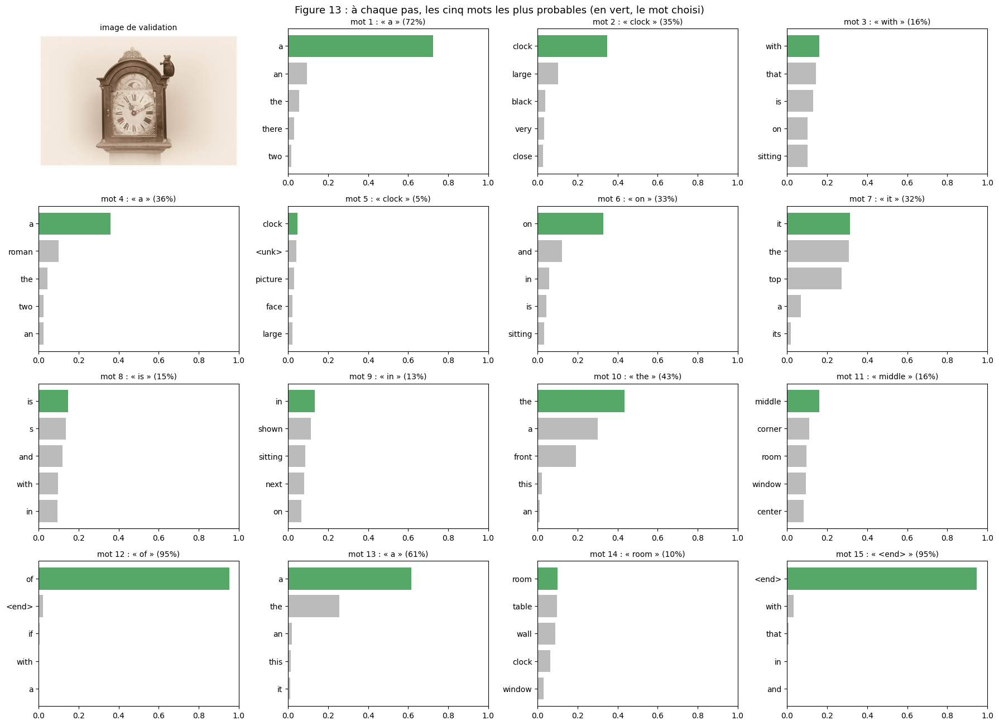

Légende : a clock with a clock on it is in the middle of a room
Durée de la cellule : 1.7 s


In [41]:
# Comment le décodeur choisit chaque mot : les cinq mots les plus probables à chaque pas
i = int(choix_v[0])
feats = encoder(tf.constant(CARACT[np.array([i])])); proj = decoder.attention.project(feats)
h, c = decoder.etat_initial(feats)
mot, etapes = tf.constant([DEBUT]), []
for _ in range(LONGUEUR_MAX + 1):
    logits, h, c, _ = decoder(mot, feats, proj, h, c, training=False)
    p = tf.nn.softmax(logits)[0].numpy()
    top = np.argsort(-p)[:5]
    etapes.append([(VOCAB[j], p[j]) for j in top])
    mot = tf.constant([int(top[0])])
    if int(top[0]) == FIN:
        break
colonnes = 4
lignes_g = int(np.ceil((len(etapes) + 1) / colonnes))
fig, axes = plt.subplots(lignes_g, colonnes, figsize=(18, 3.3 * lignes_g))
axes = np.atleast_1d(axes).ravel()
axes[0].imshow(Image.open(assurer_image(chemins[i])).convert("RGB")); axes[0].axis("off")
axes[0].set_title("image de validation", fontsize=10)
for t, (ax, etape_mots) in enumerate(zip(axes[1:], etapes), 1):
    mots_e, probas = zip(*etape_mots)
    ax.barh(range(5)[::-1], probas, color=["#55A868"] + ["#BBBBBB"] * 4)
    ax.set_yticks(range(5)[::-1]); ax.set_yticklabels(mots_e, fontsize=10); ax.set_xlim(0, 1)
    ax.set_title(f"mot {t} : « {mots_e[0]} » ({probas[0]:.0%})", fontsize=10)
for ax in axes[len(etapes) + 1:]:
    ax.axis("off")
plt.suptitle("Figure 13 : à chaque pas, les cinq mots les plus probables (en vert, le mot choisi)", fontsize=13)
plt.tight_layout(); plt.show()
print("Légende :", " ".join(m[0][0] for m in etapes if m[0][0] != "<end>"))

Le décodeur ne « connaît » pas sa phrase à l'avance : à chaque pas, il donne une probabilité à chacun des 10 027 mots, et le décodage glouton garde le plus probable. La figure suit l'horloge de l'image précédente, et montre comment naît la répétition *a clock on a wall with a clock on it*.

* **Les débuts sont sûrs** : *a* (75 %) puis *clock* (49 %, loin devant *large* à 14 %). Le modèle a bien reconnu l'objet.
* **Le troisième mot est très disputé** : *on* l'emporte avec 15 % seulement, à peine devant *with* et *is*. C'est ce choix, presque au hasard, qui oriente toute la suite vers « posée sur quelque chose ».
* **Le lieu est inventé** : *wall* (47 %) l'emporte sur *building* ou *table*, alors que l'horloge est posée au sol ; le modèle complète avec le lieu le plus fréquent pour une horloge dans COCO.
* **La répétition** : après *with a*, aucun mot ne se détache (*clock* à 25 %, les autres sous 5 %), et le modèle reprend le mot qu'il associe le plus à l'image, sans mémoire explicite de l'avoir déjà écrit. Une fois la phrase « pleine », *<end>* arrive avec 86 %.

Deux remèdes existent : la recherche par faisceau de la partie C, qui compare plusieurs phrases entières au lieu de s'engager sur un mot choisi à 15 %, et une règle qui interdit de répéter un nom déjà écrit.

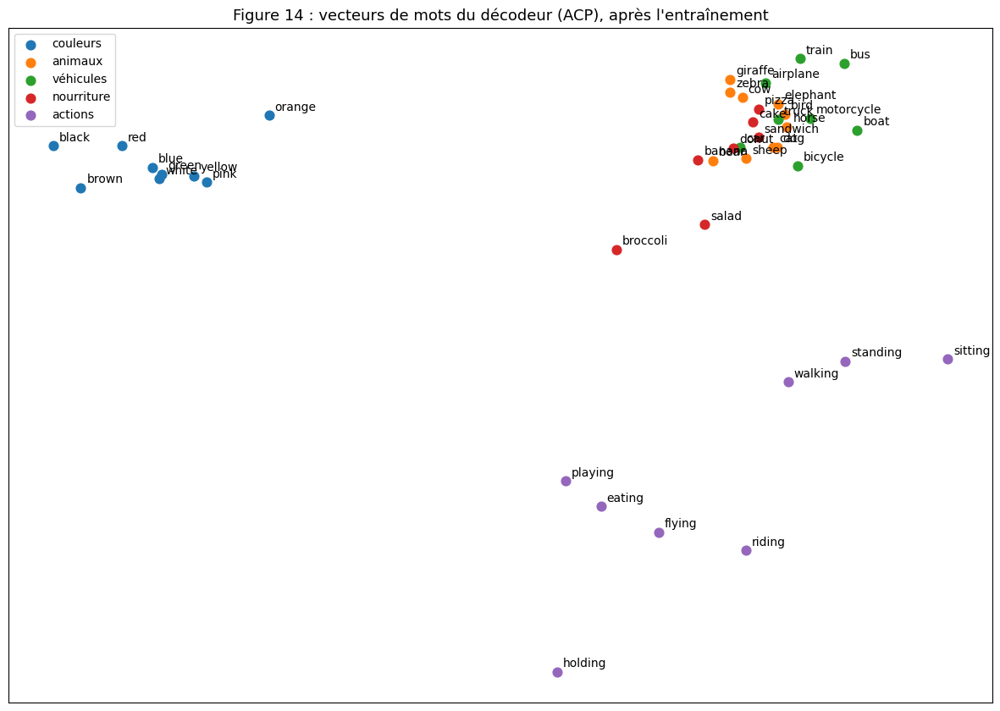

In [42]:
# Les vecteurs de mots appris par le décodeur, projetés sur un plan
groupes = {"couleurs": ["red", "blue", "green", "yellow", "white", "black", "orange", "pink", "brown"],
           "animaux": ["dog", "cat", "horse", "cow", "sheep", "elephant", "giraffe", "zebra", "bird", "bear"],
           "véhicules": ["car", "bus", "train", "truck", "motorcycle", "bicycle", "airplane", "boat"],
           "nourriture": ["pizza", "sandwich", "cake", "banana", "broccoli", "donut", "salad", "orange"],
           "actions": ["sitting", "standing", "riding", "eating", "holding", "playing", "walking", "flying"]}
plongement = decoder.embedding.get_weights()[0]
mots_g, groupes_g = [], []
for g, liste in groupes.items():
    for m in liste:
        if m in VOCAB and m not in mots_g:
            mots_g.append(m); groupes_g.append(g)
x = plongement[[VOCAB.index(m) for m in mots_g]]
x = x - x.mean(axis=0)
plan = x @ np.linalg.svd(x, full_matrices=False)[2][:2].T               # ACP sur deux axes
fig, ax = plt.subplots(figsize=(12, 8.5))
for g, couleur in zip(groupes, plt.cm.tab10.colors):
    k = np.array(groupes_g) == g
    ax.scatter(plan[k, 0], plan[k, 1], s=60, color=couleur, label=g)
for (px, py), m in zip(plan, mots_g):
    ax.annotate(m, (px, py), textcoords="offset points", xytext=(5, 4), fontsize=10)
ax.legend(); ax.grid(alpha=0.3); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Figure 14 : vecteurs de mots du décodeur (ACP), après l'entraînement", fontsize=13)
plt.tight_layout(); plt.show()

La couche d'embedding est partie de vecteurs aléatoires : avant l'entraînement, ce plan ne montrerait aucun regroupement. Après l'entraînement, trois groupes sont nettement séparés : **les couleurs** en haut à gauche, **les verbes d'action** en bas, et **les objets** (animaux, véhicules, nourriture) en haut à droite. Personne n'a dit au modèle ce qu'est une couleur ou une action ; il l'a déduit parce que ces mots occupent les mêmes places dans les phrases.

En revanche, animaux, véhicules et aliments sont mêlés dans un même nuage. Pour le décodeur, ce sont tous des noms qui se placent au même endroit de la phrase (« a ___ sitting on… ») ; c'est l'image, par l'attention, qui les départage, pas le vecteur du mot. *orange*, à la fois couleur et fruit, se place à l'écart des autres couleurs, vers les objets. Une projection sur deux axes ne garde qu'une partie de l'information des 256 dimensions : il faut lire ces distances comme une tendance, pas comme une mesure exacte.

---
<a id="s12bis"></a>
## 12 bis. Réglage des hyperparamètres et lutte contre le surapprentissage

### 12 bis.1 Le diagnostic

Le modèle de la section 12 apprend bien, mais il **surapprend** à partir de l'époque 4 : la figure de l'écart entre validation et entraînement le montre clairement, avec un écart qui passe de 0,03 à l'époque 4 à 0,27 à l'époque 9. Concrètement, le modèle continue à mieux prédire les légendes qu'il a déjà vues, sans progresser sur des images nouvelles. L'arrêt anticipé limite les dégâts en gardant l'époque 6, mais il ne règle pas la cause : le modèle s'arrête d'apprendre des règles générales au bout de 6 époques, alors qu'il a encore du potentiel.

Cette section cherche donc à **reculer le moment où le surapprentissage commence**, pour que le modèle puisse apprendre plus longtemps des choses utiles, et à choisir les meilleurs réglages de façon méthodique plutôt qu'au jugé.

### 12 bis.2 Paramètres et hyperparamètres

Il faut distinguer deux sortes de nombres :

* les **paramètres** (ou poids) sont les 11 millions de nombres du réseau, que l'entraînement ajuste tout seul à chaque lot ;
* les **hyperparamètres** sont les réglages que l'on choisit *avant* l'entraînement et qu'il n'apprend pas : le taux d'apprentissage, la quantité de *dropout*, la force d'une régularisation, le nombre d'époques… Ils décident de la façon dont le réseau apprend.

Un bon jeu d'hyperparamètres ne se devine pas : on essaie plusieurs combinaisons et on garde celle qui fait le mieux **sur la validation**. Jamais sur le test : sinon le score final serait biaisé en notre faveur, puisqu'on aurait choisi les réglages qui réussissent par chance sur ces images-là.

### 12 bis.3 Trois techniques contre le surapprentissage

On teste trois techniques classiques, chacune avec ou sans, pour mesurer ce que chacune apporte.

**1. Le *dropout* d'entrée du LSTM (0 ou 0,3).** Le modèle de base a déjà un *dropout* de 0,3, mais seulement à la sortie du LSTM. On en ajoute un **à l'entrée** : à chaque pas, 30 % des valeurs du vecteur « contexte de l'image + mot précédent » sont mises à zéro au hasard pendant l'entraînement. Le modèle ne peut plus compter sur quelques valeurs précises pour reconnaître une légende déjà vue ; il doit s'appuyer sur des indices redondants, ce qui généralise mieux. Au moment d'écrire une vraie légende, le *dropout* est éteint et toutes les valeurs sont utilisées.

**2. Le lissage des étiquettes (0 ou 0,1).** Sans lissage, l'entraînement pousse le modèle à donner une probabilité de 100 % au mot exact de la légende. Or pour une même image, plusieurs mots sont corrects (*man*, *person*, *guy*) : exiger 100 % sur un seul pousse le modèle à mémoriser la formulation de chaque légende. Avec un lissage de 0,1, la cible devient « 90 % pour le bon mot, et les 10 % restants répartis sur tous les mots ». Le modèle apprend à rester un peu modeste, ce qui limite la mémorisation et donne des probabilités plus fiables.

**3. La régularisation de l'attention (λ = 0 ou 1).** C'est la technique proposée par les auteurs de *Show, Attend and Tell*. On ajoute à la perte une pénalité quand, sur l'ensemble de la phrase, l'attention s'est concentrée sur quelques régions et en a ignoré d'autres. Le modèle est ainsi encouragé à regarder **toute** l'image au fil de la phrase, plutôt que de décrire seulement l'objet principal ; dans l'article, elle améliore les scores et les légendes. λ règle la force de cette pénalité : 0 la désactive.

### 12 bis.4 La recherche par grille, en deux temps

Une **recherche par grille** essaie toutes les combinaisons de valeurs choisies. Avec les trois techniques ci-dessus, chacune avec deux valeurs, cela fait 2 × 2 × 2 = **8 combinaisons**. L'une d'elles (aucune des trois techniques) est exactement le modèle de base de la section 12 : on peut donc mesurer le gain par rapport à lui, dans les mêmes conditions.

Le **taux d'apprentissage** est réglé dans un second temps, sur la meilleure combinaison seulement, avec deux valeurs de plus (0,0005 et 0,002, en plus de 0,001). Ajouter le taux à la grille aurait fait 24 entraînements au lieu de 10 ; régler un réglage après l'autre est un compromis classique quand chaque essai coûte cher.

**Pourquoi un sous-ensemble et peu d'époques ?** Un entraînement complet prend environ 8 minutes par époque : 10 entraînements complets de 10 époques prendraient plus de 13 heures. Chaque essai est donc fait sur **20 000 images d'entraînement tirées au hasard, pendant 3 époques**, soit environ 5 minutes par essai. C'est assez pour classer les réglages entre eux, mais c'est une hypothèse : un réglage qui gagne sur un petit entraînement gagne en général sur le grand, sans que ce soit garanti. L'entraînement final, sur toutes les images, le vérifiera.

**Le critère de choix : le CIDEr sur la validation, pas la perte.** Le lissage des étiquettes change la perte elle-même : un modèle lissé a une perte plus haute sans être moins bon. Comparer les essais par leur perte favoriserait donc à tort ceux sans lissage. On mesure plutôt ce qui compte vraiment : la qualité des légendes que le modèle écrit lui-même, par leur CIDEr sur 1 000 images de validation (en décodage glouton, plus rapide que le faisceau). La perte de validation, calculée sans lissage pour tout le monde, est aussi relevée pour suivre le surapprentissage.

Chaque essai est enregistré sur le Drive dès qu'il est terminé (dossier `recherche_hyperparametres`) : après une coupure de Colab, la recherche reprend à l'essai suivant.

In [43]:
# Réglages de la recherche, modèle régularisé, perte avec lissage et régularisation de l'attention
import itertools
try:
    from pycocoevalcap.cider.cider import Cider
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocoevalcap"], check=True)
    from pycocoevalcap.cider.cider import Cider

SOUS_ENSEMBLE = 20000            # images d'entraînement par essai de la grille
EPOQUES_GRILLE = 10               # époques par essai
IMAGES_VAL_CIDER = 1000          # images de validation pour le CIDEr
GRILLE = {"dropout_entree": [0.0, 0.3], "lissage": [0.0, 0.1], "lambda_attention": [0.0, 1.0]}
TAUX_BASE, TAUX_ETAPE2 = 1e-3, [5e-4, 2e-3]
EPOQUES_FINAL, PATIENCE_FINAL, EPOQUES_MIN_FINAL = 12, 4, 8   # même durée que le modèle de base ; pas d'arrêt avant l'époque 8
DOSSIER_GRILLE = RACINE / "recherche_hyperparametres"
DOSSIER_OPTIMISE_V2 = RACINE / "modele_L3_optimise_v2"     # version précédente, gardée comme point de comparaison
DOSSIER_OPTIMISE = RACINE / "modele_L3_optimise_v3"        # version 3 : nouveau dossier, pour ne pas reprendre l'ancien entraînement
DOSSIER_GRILLE.mkdir(exist_ok=True); DOSSIER_OPTIMISE.mkdir(exist_ok=True)
SOUS_IDX = np.sort(np.random.default_rng(SEED).choice(idx_train, min(SOUS_ENSEMBLE, len(idx_train)), replace=False))
# Version 3 : réglages dirigés contre le surapprentissage de l'entraînement complet (voir 12 bis.6 bis).
# Ils s'ajoutent au réglage retenu par la grille ; aucun n'ajoute de paramètre apprenable : les poids restent lisibles par le pipeline.
ANTI_SURAPPRENTISSAGE = {
    "dropout_sortie": 0.5,        # dropout après fc1 (0,3 dans le modèle de base) : fc2 porte plus de la moitié des paramètres
    "dropout_features": 0.2,      # dropout sur les 64 régions de l'image, même masque pour les 5 légendes d'une image
    "dropout_mots": 0.1,          # 10 % des mots donnés en entrée au décodeur sont remplacés par <unk> (teacher forcing bruité)
    "lissage": 0.1,               # lissage des étiquettes (testé dans la grille : +1,8 point de CIDEr en moyenne)
    "weight_decay": 0.05,         # décroissance des poids (AdamW), sans les biais
}
IMAGES_TRAIN_EVAL = 5000          # images d'entraînement fixes, mesurées dropout éteint, pour un écart honnête avec la validation
IDX_TRAIN_EVAL = np.sort(np.random.default_rng(SEED + 7).choice(idx_train, min(IMAGES_TRAIN_EVAL, len(idx_train)), replace=False))
DS_TRAIN_EVAL = faire_dataset(CARACT, SEQUENCES, IDX_TRAIN_EVAL, BATCH_IMAGES)
ECHVAL_B = np.sort(np.random.default_rng(SEED).choice(idx_val, min(IMAGES_VAL_CIDER, len(idx_val)), replace=False))


class DecodeurRegularise(Decodeur):
    """Le décodeur de la partie B, avec un dropout de plus à l'entrée du LSTM (mêmes poids, même utilisation)."""
    def __init__(self, taille_vocab, embedding_dim, units, dropout_entree=0.0, dropout_sortie=0.3):
        super().__init__(taille_vocab, embedding_dim, units)
        self.dropout_entree = layers.Dropout(dropout_entree)
        self.drop.rate = dropout_sortie                               # dropout de sortie du décodeur de base (0,3), renforçable

    def call(self, mot, features, features_proj, h, c, training=False):
        context, poids = self.attention(features, features_proj, h)
        x = tf.concat([context, self.embedding(mot)], axis=-1)
        x = self.dropout_entree(x, training=training)                 # nouveau : dropout à l'entrée du LSTM
        sortie, (h, c) = self.cell(x, states=[h, c], training=training)
        logits = self.fc2(self.drop(self.fc1(sortie), training=training))
        return logits, h, c, poids


def construire(hp):
    enc = InceptionEncodeur(EMBEDDING_DIM)
    dec = DecodeurRegularise(TAILLE_VOCAB, EMBEDDING_DIM, UNITS, hp["dropout_entree"], hp.get("dropout_sortie", 0.3))
    f = enc(tf.zeros((1, 8, 8, 2048))); p = dec.attention.project(f); h, c = dec.etat_initial(f)
    dec(tf.zeros((1,), tf.int32), f, p, h, c)
    return enc, dec


def fabriquer_pas(enc, dec, opt, hp):
    """Pas d'entraînement (perte lissée + régularisation de l'attention) et pas de validation (perte simple)."""
    def passe(img, entree, cible, training):
        nb_leg, T = entree.shape[1], entree.shape[2]
        feats = enc(img)
        if training and hp.get("dropout_features", 0.0) > 0:
            feats = tf.nn.dropout(feats, rate=hp["dropout_features"])   # dropout sur les régions de l'image (entraînement seulement)
        proj = dec.attention.project(feats)
        feats = tf.repeat(feats, nb_leg, axis=0); proj = tf.repeat(proj, nb_leg, axis=0)
        entree = tf.reshape(entree, (-1, T)); cible = tf.reshape(cible, (-1, T))
        if training and hp.get("dropout_mots", 0.0) > 0:                  # dropout de mots : <unk> à la place de 10 % des mots d'entrée
            remplace = (tf.random.uniform(tf.shape(entree)) < hp["dropout_mots"]) & (entree != PAD) & (entree != DEBUT)
            entree = tf.where(remplace, tf.cast(UNK, entree.dtype), entree)
        h, c = dec.etat_initial(feats)
        lisse_tot, simple_tot, n = 0.0, 0.0, 0.0
        attention_totale = tf.zeros_like(feats[:, :, 0])                       # attention reçue par chaque région
        for t in range(T):
            logits, h, c, poids = dec(entree[:, t], feats, proj, h, c, training=training)
            masque = tf.cast(cible[:, t] != PAD, tf.float32)
            logp = tf.nn.log_softmax(logits)
            simple = -tf.gather(logp, cible[:, t], batch_dims=1)                  # entropie croisée habituelle
            lisse = (1 - hp["lissage"]) * simple - hp["lissage"] * tf.reduce_mean(logp, axis=-1)   # lissage des étiquettes
            lisse_tot += tf.reduce_sum(lisse * masque); simple_tot += tf.reduce_sum(simple * masque); n += tf.reduce_sum(masque)
            attention_totale += poids[:, :, 0] * masque[:, None]
        mots = tf.reduce_sum(tf.cast(cible != PAD, tf.float32), axis=1, keepdims=True)
        regul = tf.reduce_mean(tf.reduce_sum(tf.square(mots / 64.0 - attention_totale), axis=1))   # attention répartie
        return lisse_tot, simple_tot, n, regul

    @tf.function
    def pas_entrainement(img, ent, cib):
        with tf.GradientTape() as tape:
            lisse, simple, n, regul = passe(img, ent, cib, True)
            perte = lisse / tf.maximum(n, 1.0) + hp["lambda_attention"] * regul
        variables = enc.trainable_variables + dec.trainable_variables
        opt.apply_gradients(zip(tape.gradient(perte, variables), variables))
        return simple / tf.maximum(n, 1.0)

    @tf.function
    def pas_validation(img, ent, cib):
        _, simple, n, _ = passe(img, ent, cib, False)
        return simple, n

    return pas_entrainement, pas_validation


def perte_validation(pas_val, ds=None):
    """Perte par mot (sans lissage, dropout éteint) sur la validation, ou sur le jeu `ds` donné."""
    total, n = 0.0, 0.0
    for (img, ent), cib in (ds_val if ds is None else ds):
        s, m = pas_val(img, ent, cib); total += float(s); n += float(m)
    return total / n


def fabriquer_optimiseur(hp, pas_total):
    """Adam avec décroissance en cosinus ; AdamW (décroissance des poids, sans les biais) quand hp["weight_decay"] > 0."""
    planning = keras.optimizers.schedules.CosineDecay(hp["taux"], pas_total, alpha=0.01)
    if hp.get("weight_decay", 0.0) > 0:
        opt = keras.optimizers.AdamW(planning, weight_decay=hp["weight_decay"], clipnorm=5.0)
        opt.exclude_from_weight_decay(var_names=["bias"])
        return opt
    return keras.optimizers.Adam(planning, clipnorm=5.0)


MASQUE_GEN = np.zeros(TAILLE_VOCAB, np.float32)
MASQUE_GEN[[PAD, DEBUT, UNK]] = -1e9


def legendes_gloutonnes(enc, dec, indices, lot=250):
    """Légendes écrites par le modèle (décodage glouton), par lots."""
    phrases = {}
    for d in range(0, len(indices), lot):
        sel = np.asarray(indices[d:d + lot])
        feats = enc(tf.constant(CARACT[sel])); proj = dec.attention.project(feats); h, c = dec.etat_initial(feats)
        mot, jetons = tf.fill([len(sel)], DEBUT), []
        for t in range(LONGUEUR_MAX + 1):
            logits, h, c, _ = dec(mot, feats, proj, h, c, training=False)
            l = logits.numpy() + MASQUE_GEN
            if t == 0:
                l[:, FIN] = -1e9                                              # pas de légende vide
            choix = l.argmax(axis=1).astype(np.int32)
            jetons.append(choix); mot = tf.constant(choix)
        for i, seq in zip(sel, np.stack(jetons, 1)):
            mots = []
            for j in seq:
                if j == FIN:
                    break
                mots.append(VOCAB[j])
            phrases[int(i)] = " ".join(mots)
    return phrases


def cider_validation(enc, dec):
    pred = legendes_gloutonnes(enc, dec, ECHVAL_B)
    return 100 * Cider().compute_score({i: REFERENCES_A[i] for i in pred}, {i: [p] for i, p in pred.items()})[0]


print(f"Grille : {len(list(itertools.product(*GRILLE.values())))} combinaisons, puis {len(TAUX_ETAPE2)} taux d'apprentissage ; "
      f"{len(SOUS_IDX)} images et {EPOQUES_GRILLE} époques par essai ; CIDEr sur {len(ECHVAL_B)} images de validation.")

Grille : 8 combinaisons, puis 2 taux d'apprentissage ; 20000 images et 3 époques par essai ; CIDEr sur 1000 images de validation.
Durée de la cellule : 5.3 s


In [44]:
# Recherche par grille : chaque essai est enregistré sur le Drive dès qu'il est terminé
def nom_essai(hp):
    return f"dropout{hp['dropout_entree']}_lissage{hp['lissage']}_attention{hp['lambda_attention']}_taux{hp['taux']}"


def essayer(hp):
    fichier = DOSSIER_GRILLE / f"{nom_essai(hp)}.json"
    if fichier.exists():
        return json.load(open(fichier))
    keras.utils.set_random_seed(SEED)                                       # mêmes conditions de départ pour chaque essai
    enc, dec = construire(hp)
    pas_total = EPOQUES_GRILLE * int(np.ceil(len(SOUS_IDX) / BATCH_IMAGES))
    opt = keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(hp["taux"], pas_total, alpha=0.01), clipnorm=5.0)
    pas_tr, pas_val = fabriquer_pas(enc, dec, opt, hp)
    ds = faire_dataset(CARACT, SEQUENCES, SOUS_IDX, BATCH_IMAGES, melanger=True, graine=SEED)
    r = {"hp": hp, "train": [], "val": [], "cider": []}
    t0 = time.time()
    for ep in range(EPOQUES_GRILLE):
        somme, nb = 0.0, 0
        for (img, ent), cib in ds:
            somme += float(pas_tr(img, ent, cib)); nb += 1
        r["train"].append(somme / nb); r["val"].append(perte_validation(pas_val)); r["cider"].append(cider_validation(enc, dec))
    r["duree_min"] = (time.time() - t0) / 60
    json.dump(r, open(fichier, "w"))
    return r


def afficher(r, marque=""):
    hp = r["hp"]
    print(f"dropout d'entrée {hp['dropout_entree']:.1f} | lissage {hp['lissage']:.1f} | λ attention {hp['lambda_attention']:.0f} | "
          f"taux {hp['taux']:.4f} -> CIDEr val {r['cider'][-1]:5.1f} | perte val {r['val'][-1]:.4f} | "
          f"écart val - train {r['val'][-1] - r['train'][-1]:+.3f} | {r['duree_min']:.1f} min {marque}")


# Étape 1 : les 8 combinaisons des trois techniques, avec le taux d'apprentissage du modèle de base
ESSAIS = []
print("Étape 1 : les trois techniques contre le surapprentissage")
for d, l, a in itertools.product(*GRILLE.values()):
    r = essayer({"dropout_entree": d, "lissage": l, "lambda_attention": a, "taux": TAUX_BASE})
    r["etape"] = 1; ESSAIS.append(r)
    afficher(r, "(modèle de base)" if d == l == a == 0 else "")

# Étape 2 : le taux d'apprentissage, sur la meilleure combinaison
meilleur1 = max(ESSAIS, key=lambda r: r["cider"][-1])
print("\nÉtape 2 : le taux d'apprentissage, sur la meilleure combinaison de l'étape 1")
for taux in TAUX_ETAPE2:
    r = essayer({**meilleur1["hp"], "taux": taux})
    r["etape"] = 2; ESSAIS.append(r)
    afficher(r)
MEILLEUR = max(ESSAIS, key=lambda r: r["cider"][-1])
BASE = next(r for r in ESSAIS if r["hp"]["dropout_entree"] == r["hp"]["lissage"] == r["hp"]["lambda_attention"] == 0 and r["hp"]["taux"] == TAUX_BASE)
# Réglage pour l'entraînement complet : la meilleure combinaison de l'étape 1, au taux du modèle de base.
# Le taux 0,002 gagne les essais courts parce qu'il apprend plus vite, pas parce qu'il apprend mieux (voir le texte).
RETENU = meilleur1
HP_FINAL = {**RETENU["hp"], **ANTI_SURAPPRENTISSAGE}      # grille (attention λ = 1, taux 0,001) + réglages anti-surapprentissage (v3)
print("Réglages anti-surapprentissage ajoutés pour l'entraînement complet (v3) : " + ", ".join(f"{k} {v}" for k, v in ANTI_SURAPPRENTISSAGE.items()))
print(f"\nMeilleur essai court : {nom_essai(MEILLEUR['hp'])} (CIDEr {MEILLEUR['cider'][-1]:.1f}).")
print(f"Réglage retenu pour l'entraînement complet : {nom_essai(HP_FINAL)} ; CIDEr de validation {RETENU['cider'][-1]:.1f} "
      f"contre {BASE['cider'][-1]:.1f} pour le modèle de base dans les mêmes conditions ({RETENU['cider'][-1] - BASE['cider'][-1]:+.1f}).")

Étape 1 : les trois techniques contre le surapprentissage
dropout d'entrée 0.0 | lissage 0.0 | λ attention 0 | taux 0.0010 -> CIDEr val  59.4 | perte val 3.0633 | écart val - train +0.003 | 2.9 min (modèle de base)
dropout d'entrée 0.0 | lissage 0.0 | λ attention 1 | taux 0.0010 -> CIDEr val  63.6 | perte val 2.9473 | écart val - train +0.035 | 2.9 min 
dropout d'entrée 0.0 | lissage 0.1 | λ attention 0 | taux 0.0010 -> CIDEr val  61.6 | perte val 3.0627 | écart val - train -0.024 | 2.9 min 
dropout d'entrée 0.0 | lissage 0.1 | λ attention 1 | taux 0.0010 -> CIDEr val  64.1 | perte val 2.9623 | écart val - train -0.005 | 2.9 min 
dropout d'entrée 0.3 | lissage 0.0 | λ attention 0 | taux 0.0010 -> CIDEr val  57.6 | perte val 3.0286 | écart val - train +0.003 | 3.0 min 
dropout d'entrée 0.3 | lissage 0.0 | λ attention 1 | taux 0.0010 -> CIDEr val  61.3 | perte val 2.9523 | écart val - train +0.021 | 3.0 min 
dropout d'entrée 0.3 | lissage 0.1 | λ attention 0 | taux 0.0010 -> CIDEr val  6

### 12 bis.5 Les résultats de la grille, en graphiques

Trois figures permettent de lire la recherche :

* la première classe les 10 essais par leur CIDEr de validation, le critère de choix, avec le modèle de base en gris et le réglage retenu en vert ;
* la deuxième isole l'**effet de chaque technique** : pour chacune, on compare la moyenne des 4 essais qui l'utilisent à celle des 4 essais qui ne l'utilisent pas. C'est ce qu'on appelle un effet moyen ; il dit si une technique aide en général, quelle que soit la combinaison ;
* la troisième montre, pour chaque essai, l'écart entre la perte de validation et la perte d'entraînement à la fin des 3 époques : plus il est grand, plus l'essai surapprend.

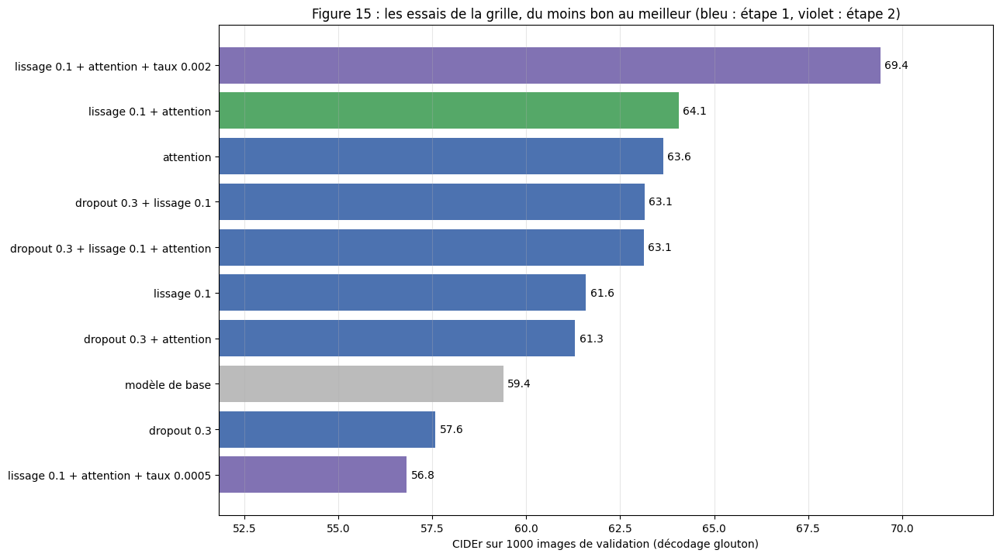

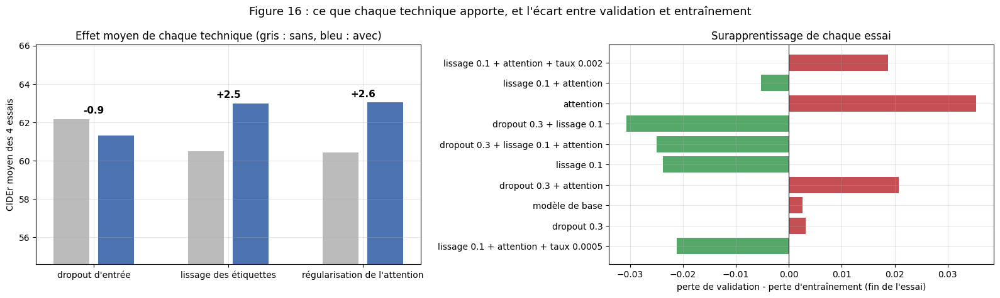

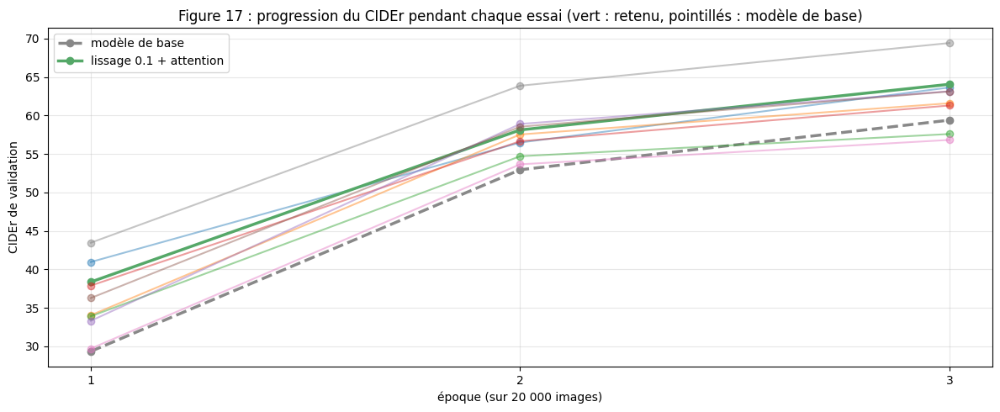

In [45]:
# Classement des essais, effet de chaque technique et surapprentissage
def etiquette(hp):
    morceaux = [f"dropout {hp['dropout_entree']:.1f}" if hp["dropout_entree"] else "", f"lissage {hp['lissage']:.1f}" if hp["lissage"] else "",
                "attention" if hp["lambda_attention"] else "", f"taux {hp['taux']:g}" if hp["taux"] != TAUX_BASE else ""]
    return " + ".join(m for m in morceaux if m) or "modèle de base"


classes = sorted(ESSAIS, key=lambda r: r["cider"][-1])
fig, ax = plt.subplots(figsize=(13, 0.55 * len(classes) + 1.8))
couleurs = ["#55A868" if r is RETENU else "#BBBBBB" if r is BASE else ("#4C72B0" if r["etape"] == 1 else "#8172B3") for r in classes]
barres = ax.barh([etiquette(r["hp"]) for r in classes], [r["cider"][-1] for r in classes], color=couleurs)
ax.bar_label(barres, fmt="%.1f", padding=4)
ax.set_xlim(min(r["cider"][-1] for r in classes) - 5, max(r["cider"][-1] for r in classes) + 3)
ax.set_xlabel(f"CIDEr sur {len(ECHVAL_B)} images de validation (décodage glouton)"); ax.grid(alpha=0.3, axis="x")
ax.set_title("Figure 15 : les essais de la grille, du moins bon au meilleur (bleu : étape 1, violet : étape 2)")
plt.tight_layout(); plt.show()

etape1 = [r for r in ESSAIS if r["etape"] == 1]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
noms_tech = {"dropout_entree": "dropout d'entrée", "lissage": "lissage des étiquettes", "lambda_attention": "régularisation de l'attention"}
for k, (cle, nom) in enumerate(noms_tech.items()):
    sans = np.mean([r["cider"][-1] for r in etape1 if r["hp"][cle] == 0])
    avec = np.mean([r["cider"][-1] for r in etape1 if r["hp"][cle] != 0])
    axes[0].bar([3 * k, 3 * k + 1], [sans, avec], color=["#BBBBBB", "#4C72B0"])
    axes[0].text(3 * k + 0.5, max(sans, avec) + 0.3, f"{avec - sans:+.1f}", ha="center", fontsize=11, fontweight="bold")
axes[0].set_xticks([3 * k + 0.5 for k in range(3)]); axes[0].set_xticklabels(noms_tech.values())
lo = min(r["cider"][-1] for r in etape1)
axes[0].set_ylim(lo - 3, max(r["cider"][-1] for r in etape1) + 2)
axes[0].set_ylabel("CIDEr moyen des 4 essais"); axes[0].set_title("Effet moyen de chaque technique (gris : sans, bleu : avec)")
ecarts = [r["val"][-1] - r["train"][-1] for r in classes]
axes[1].barh([etiquette(r["hp"]) for r in classes], ecarts, color=["#C44E52" if e > 0 else "#55A868" for e in ecarts])
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_xlabel("perte de validation - perte d'entraînement (fin de l'essai)"); axes[1].set_title("Surapprentissage de chaque essai")
for ax in axes:
    ax.grid(alpha=0.3)
plt.suptitle("Figure 16 : ce que chaque technique apporte, et l'écart entre validation et entraînement", fontsize=13)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
for r in ESSAIS:
    style = dict(color="#55A868", lw=2.5) if r is RETENU else dict(color="#888888", lw=2.5, ls="--") if r is BASE else dict(alpha=0.45)
    ax.plot(range(1, len(r["cider"]) + 1), r["cider"], marker="o", label=etiquette(r["hp"]) if r is RETENU or r is BASE else None, **style)
ax.set_xlabel("époque (sur 20 000 images)"); ax.set_ylabel("CIDEr de validation"); ax.set_xticks(range(1, EPOQUES_GRILLE + 1))
ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Figure 17 : progression du CIDEr pendant chaque essai (vert : retenu, pointillés : modèle de base)")
plt.tight_layout(); plt.show()

**Ce que montre la grille.** Sur 20 000 images et 3 époques, le modèle de base obtient un CIDEr de validation de **59,7**.

* **La régularisation de l'attention est la technique la plus utile.** Seule, elle donne **63,9, soit +4,2 points**, le meilleur résultat de l'étape 1. En moyenne sur les 4 essais qui l'utilisent, elle apporte +1,8 point, et elle améliore le résultat dans les 4 combinaisons où on l'ajoute. Forcer le modèle à regarder toute l'image l'aide à mieux décrire la scène.
* **Le lissage des étiquettes aide aussi** (+1,8 point en moyenne), mais il ne s'additionne pas à l'attention : les deux ensemble font 63,0, un peu moins que l'attention seule. Les deux techniques corrigent en partie le même défaut.
* **Le dropout d'entrée n'aide pas** (−0,7 point en moyenne). Le modèle a déjà un dropout de 0,3 en sortie du LSTM ; en ajouter un à l'entrée lui retire trop d'information sur un entraînement aussi court.
* **Les écarts entre validation et entraînement restent tous petits** (de −0,03 à +0,07) : en 3 époques sur 20 000 images, le surapprentissage n'a pas encore eu le temps d'apparaître. La grille mesure donc surtout ce qui fait apprendre *mieux*, pas ce qui empêche de surapprendre ; c'est une limite de la méthode, assumée pour tenir dans le temps de calcul.

**Le piège du taux d'apprentissage.** À l'étape 2, le taux 0,002 donne 68,4, bien au-dessus de 0,001 (63,9) et de 0,0005 (54,2). Il serait tentant de le retenir, et c'est ce qu'avait fait une première version de ce notebook. Le résultat a été mauvais : entraîné sur toutes les images, le modèle au taux 0,002 n'a atteint que **81,3 de CIDEr de validation, contre 86,1 pour le modèle de base**. L'explication est classique : sur un entraînement court, le plus grand taux gagne parce qu'il **apprend plus vite**, pas parce qu'il apprend **mieux**. Sur un entraînement long, ces grands pas empêchent le modèle de s'affiner, et ses scores oscillent. C'est un biais connu des recherches d'hyperparamètres faites sur des essais courts : un réglage qui agit sur la *vitesse* d'apprentissage ne se compare pas honnêtement sur 3 époques.

**Le choix retenu.** On garde donc la conclusion solide de la grille, **la régularisation de l'attention (λ = 1)**, dont l'effet se vérifie dans toutes les combinaisons, et on garde **le taux d'apprentissage du modèle de base (0,001)**, déjà validé sur un entraînement complet. Ainsi, l'entraînement final ne diffère du modèle de base que par la technique que la grille a désignée : si le résultat change, on saura à quoi l'attribuer. (Version 3 : cinq réglages anti-surapprentissage s'ajoutent à ce choix, voir 12 bis.6 bis ; ils ne sont pas isolés un par un, car chaque entraînement complet dure près de deux heures.)

### 12 bis.6 L'entraînement final avec le réglage retenu

Le réglage retenu (la grille, puis les réglages anti-surapprentissage de la section 12 bis.6 bis) est entraîné sur **toutes** les images d'entraînement, dans les mêmes conditions que le modèle de base, pour une comparaison juste :

* **12 époques**, avec le même taux d'apprentissage qui décroît en cosinus sur les 12 époques ;
* **le choix de la meilleure époque se fait sur le CIDEr de validation**, mesuré à la fin de chaque époque : c'est la qualité des légendes écrites qui compte. Toute amélioration, même petite, est enregistrée ;
* **pas d'arrêt anticipé avant l'époque 8**, puis arrêt si le CIDEr ne progresse plus pendant 4 époques. La première version s'arrêtait après 3 époques sans gain d'au moins 0,3 point : elle a coupé l'entraînement à l'époque 6, alors que le taux d'apprentissage était encore élevé et que le CIDEr remontait. Le CIDEr mesuré sur 1 000 images varie naturellement d'un point ou deux d'une époque à l'autre ; une règle d'arrêt trop stricte confond ces variations avec un plateau.

Comme dans la section 12, l'état complet est enregistré à la fin de chaque époque (dossier `modele_L3_optimise_v3`) : après une coupure de Colab, l'entraînement reprend à l'époque suivante. Compter environ 8 à 9 minutes par époque, soit environ 1 h 45 pour 12 époques.

### 12 bis.6 bis Version 3 : réduire le surapprentissage de l'entraînement complet

**Pourquoi une nouvelle version.** Le modèle optimisé de la version 2 écrit de meilleures légendes que le modèle de base (CIDEr de validation 86,0 puis 91,2), mais il surapprend encore : sa perte de validation est la plus basse à l'époque 7 (2,3122), puis remonte jusqu'à 2,3306 pendant que la perte d'entraînement continue de baisser jusqu'à 1,9464. La grille de la section 12 bis.4 ne pouvait pas corriger cela : ses essais (3 époques, 20 000 images) sont trop courts pour que le surapprentissage apparaisse (écarts de −0,03 à +0,07). Elle a ainsi écarté le dropout d'entrée sans pouvoir mesurer ce qu'il aurait changé à l'écart.

La version 3 garde ce que la grille a établi (régularisation de l'attention λ = 1, taux d'apprentissage 0,001) et ajoute cinq réglages dirigés contre la mémorisation. Aucun n'ajoute de paramètre apprenable : l'architecture et les fichiers de poids ne changent pas, et le pipeline les relit comme avant.

| Réglage | Valeur | Ce qu'il fait |
|---|---|---|
| Dropout de sortie | 0,3 → **0,5** | Après `fc1`, avant `fc2`. `fc2` compte plus de la moitié des paramètres du décodeur (5,1 millions sur 10,7) : c'est là que la mémorisation des légendes a le plus de place. |
| Dropout sur les régions de l'image | **0,2** | 20 % des valeurs des 64 régions sont mises à zéro à l'entraînement, avec le même masque pour les cinq légendes d'une image. Le modèle ne peut plus reconnaître une image du train à quelques valeurs précises pour en réciter les légendes. |
| Dropout de mots | **0,1** | 10 % des mots donnés en entrée au décodeur sont remplacés par `<unk>` (jamais le début de phrase ni le padding). Le modèle ne peut plus s'appuyer sur l'enchaînement exact des mots d'une légende apprise ; cela réduit aussi un peu l'écart entre entraînement et utilisation (*exposure bias*, section 12). |
| Lissage des étiquettes | 0 → **0,1** | Testé dans la grille (+1,8 point de CIDEr en moyenne). Il vise aussi le symptôme observé : la perte de validation remonte parce que le modèle devient trop sûr de lui sur ses erreurs. La perte de validation reste calculée sans lissage, donc comparable. |
| Décroissance des poids | **0,05** (AdamW) | Ramène lentement chaque poids vers zéro, ce qui limite les grands poids qui servent à retenir des cas particuliers. S'applique à `fc2` et à l'embedding (7,7 millions de paramètres sur 10,7) ; les biais en sont exclus. |

**Une mesure plus honnête de l'écart.** Jusqu'ici, l'« écart validation − entraînement » comparait une validation faite *dropout éteint* à une perte d'entraînement moyennée *dropout allumé*. Or plus on met de dropout, plus la perte d'entraînement mesurée est haute, et l'écart diminue mécaniquement, sans que le modèle généralise mieux. L'entraînement mesure donc maintenant, à la fin de chaque époque, la perte sur **5 000 images d'entraînement fixes, dropout éteint**, soit autant d'images que la validation. Le bilan de la section 12 bis.7 compare le modèle de base, la version 2 et la version 3 avec cette mesure unique.

**Ce qui ne change pas.** L'architecture, le taux d'apprentissage (cosinus de 0,001 à 0,00001), les 12 époques, la régularisation de l'attention (λ = 1) et le choix de la meilleure époque sur le CIDEr de validation. Un seul entraînement complet est nécessaire (environ 1 h 45 à 2 h).

**Si le surapprentissage persiste, ou si le CIDEr baisse.** Les valeurs ci-dessus sont des choix raisonnables, non réglés sur un entraînement complet (trop long pour une grille). Si la perte de validation remonte encore tôt, augmenter `dropout_features` (0,3), `dropout_mots` (0,15) ou `weight_decay` (0,1). Si le CIDEr de validation tombe sous celui de la version 2 (91,2), les réglages sont trop forts : revenir à `dropout_sortie` 0,4 et `weight_decay` 0,02. Changer une seule valeur à la fois, dans `ANTI_SURAPPRENTISSAGE` (cellule de la section 12 bis.4), et supprimer le dossier `modele_L3_optimise_v3` pour relancer l'entraînement.

In [46]:
# Entraînement final avec le meilleur réglage, sur toutes les images, choix de l'époque sur le CIDEr de validation
def entrainer_final(hp):
    keras.utils.set_random_seed(SEED)
    enc, dec = construire(hp)
    opt = fabriquer_optimiseur(hp, EPOQUES_FINAL * LOTS_PAR_EPOQUE)       # AdamW si weight_decay > 0
    opt.build(enc.trainable_variables + dec.trainable_variables)
    pas_tr, pas_val = fabriquer_pas(enc, dec, opt, hp)
    point = tf.train.Checkpoint(encoder=enc, decoder=dec, optimizer=opt)
    gestion = tf.train.CheckpointManager(point, str(DOSSIER_OPTIMISE / "reprise"), max_to_keep=1)
    fichier_hist = DOSSIER_OPTIMISE / "historique.json"
    h = {"hp": hp, "train": [], "train_eval": [], "val": [], "cider": [], "meilleure_epoque": None, "meilleur_cider": -1.0, "attente": 0, "arret_precoce": False}
    if gestion.latest_checkpoint and fichier_hist.exists():
        point.restore(gestion.latest_checkpoint)
        h = json.load(open(fichier_hist))
        h["arret_precoce"] = h["attente"] >= PATIENCE_FINAL and len(h["val"]) >= EPOQUES_MIN_FINAL
        print(f"Reprise : {len(h['val'])} époque(s) déjà faite(s) lors d'une exécution précédente :")
        for e, (t, te, v, cd) in enumerate(zip(h["train"], h["train_eval"], h["val"], h["cider"]), 1):
            print(f"Époque {e}/{EPOQUES_FINAL} | train {t:.4f} (dropout allumé) | train {te:.4f} (éteint) | val {v:.4f} | écart {v - te:+.3f} | "
                  f"CIDEr val {cd:.1f}" + ("   <- meilleur modèle" if e == h["meilleure_epoque"] else ""))
    for ep in range(len(h["val"]), EPOQUES_FINAL):
        if h["arret_precoce"]:
            break
        t0, somme, nb = time.time(), 0.0, 0
        for k, ((img, ent), cib) in enumerate(ds_train):
            somme += float(pas_tr(img, ent, cib)); nb += 1
            if k % 1000 == 0:
                print(f"Époque {ep + 1} | lot {k} | perte moyenne {somme / nb:.4f}")
        h["train"].append(somme / nb); h["val"].append(perte_validation(pas_val)); h["cider"].append(cider_validation(enc, dec))
        h["train_eval"].append(perte_validation(pas_val, DS_TRAIN_EVAL))   # perte d'entraînement dropout éteint, comparable à la validation
        message = (f"Époque {ep + 1}/{EPOQUES_FINAL} | train {h['train'][-1]:.4f} (dropout allumé) | train {h['train_eval'][-1]:.4f} (éteint) | "
                   f"val {h['val'][-1]:.4f} | écart {h['val'][-1] - h['train_eval'][-1]:+.3f} | CIDEr val {h['cider'][-1]:.1f} | {time.time() - t0:.0f}s")
        if h["cider"][-1] > h["meilleur_cider"]:                   # toute amélioration est gardée
            h.update(meilleur_cider=h["cider"][-1], meilleure_epoque=ep + 1, attente=0)
            enc.save_weights(str(DOSSIER_OPTIMISE / "encoder.weights.h5")); dec.save_weights(str(DOSSIER_OPTIMISE / "decoder.weights.h5"))
            message += "   -> meilleur modèle sauvegardé"
        else:
            h["attente"] += 1
            if h["attente"] >= PATIENCE_FINAL and ep + 1 >= EPOQUES_MIN_FINAL:
                h["arret_precoce"] = True
                message += "\n[Arrêt anticipé : le CIDEr de validation ne progresse plus]"
        gestion.save()
        json.dump(h, open(fichier_hist, "w"))
        print(message)
    enc.load_weights(str(DOSSIER_OPTIMISE / "encoder.weights.h5")); dec.load_weights(str(DOSSIER_OPTIMISE / "decoder.weights.h5"))
    return enc, dec, h


ENC_OPT, DEC_OPT, HIST_OPT = entrainer_final(HP_FINAL)
print(f"Meilleure époque : {HIST_OPT['meilleure_epoque']} sur {len(HIST_OPT['val'])}, CIDEr de validation {HIST_OPT['meilleur_cider']:.1f}")

Époque 1 | lot 0 | perte moyenne 9.2106
Époque 1 | lot 1000 | perte moyenne 3.9843
Époque 1 | lot 2000 | perte moyenne 3.5907
Époque 1 | lot 3000 | perte moyenne 3.3981
Époque 1/12 | train 3.3289 (dropout allumé) | train 2.6181 (éteint) | val 2.6744 | écart +0.056 | CIDEr val 76.7 | 300s   -> meilleur modèle sauvegardé
Époque 2 | lot 0 | perte moyenne 2.8583
Époque 2 | lot 1000 | perte moyenne 2.8632
Époque 2 | lot 2000 | perte moyenne 2.8451
Époque 2 | lot 3000 | perte moyenne 2.8294
Époque 2/12 | train 2.8213 (dropout allumé) | train 2.4613 (éteint) | val 2.5395 | écart +0.078 | CIDEr val 77.3 | 282s   -> meilleur modèle sauvegardé
Époque 3 | lot 0 | perte moyenne 2.6302
Époque 3 | lot 1000 | perte moyenne 2.7166
Époque 3 | lot 2000 | perte moyenne 2.7133
Époque 3 | lot 3000 | perte moyenne 2.7090
Époque 3/12 | train 2.7079 (dropout allumé) | train 2.3827 (éteint) | val 2.4787 | écart +0.096 | CIDEr val 82.5 | 282s   -> meilleur modèle sauvegardé
Époque 4 | lot 0 | perte moyenne 2.52

### 12 bis.7 Le surapprentissage est-il corrigé ?

On compare maintenant le modèle de base (section 12) et le modèle optimisé, entraînés tous les deux sur toutes les images. La première figure superpose leurs courbes de perte : le surapprentissage se voit quand la perte de validation cesse de baisser alors que celle d'entraînement continue. La deuxième compare l'écart entre validation et entraînement époque par époque : un écart qui grandit moins vite, ou plus tard, montre que la régularisation fait son travail. La troisième suit le CIDEr de validation du modèle optimisé à chaque époque.

Les deux modèles sont ensuite mesurés exactement de la même façon, sur les mêmes 1 000 images de validation. Celui qui a le meilleur CIDEr est retenu pour la partie C et le pipeline ; si le modèle optimisé ne fait pas mieux, on garde honnêtement le modèle de base.

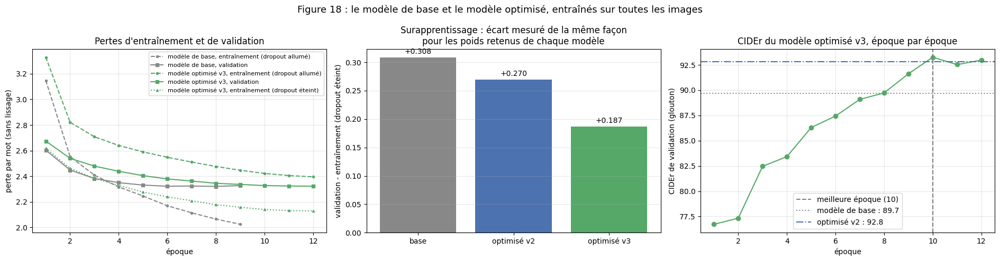

CIDEr sur 1000 images de validation (glouton) : modèle de base 89.7, modèle optimisé v3 93.3 (+3.5)
Perte par mot, dropout éteint ; mêmes 5 000 images d'entraînement et mêmes 5 000 images de validation pour tous :
   base         CIDEr  89.7 | train 2.0136 | val 2.3217 | écart val - train +0.308
   optimisé v2  CIDEr  92.8 | train 2.0460 | val 2.3155 | écart val - train +0.270
   optimisé v3  CIDEr  93.3 | train 2.1396 | val 2.3267 | écart val - train +0.187
Modèle retenu pour la suite : le modèle optimisé (dossier modele_L3_optimise_v3).


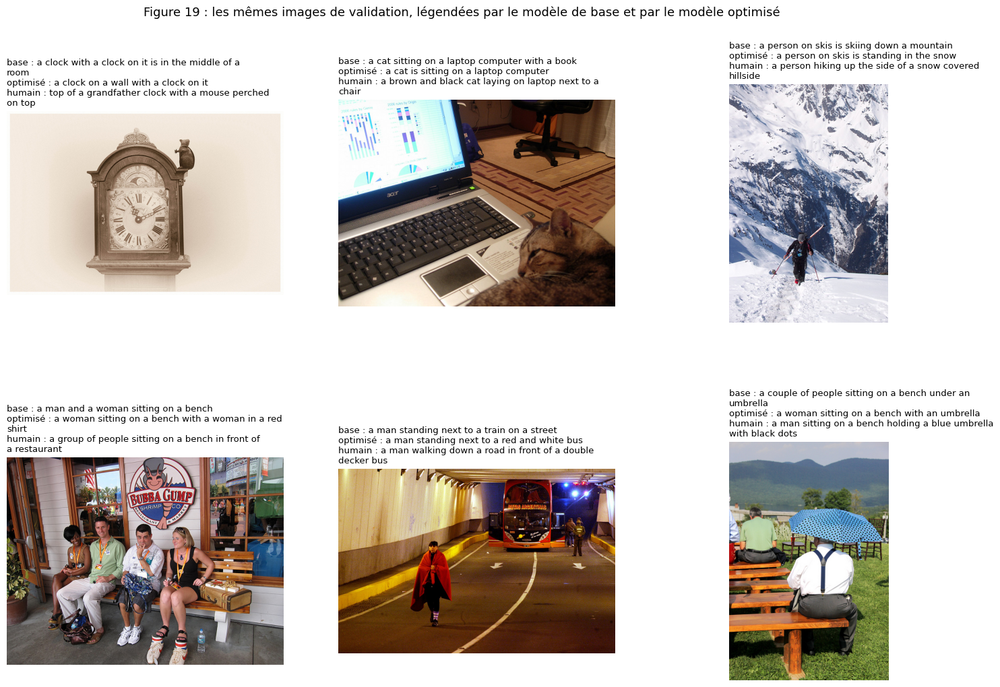

Durée de la cellule : 45.2 s


In [47]:
# Modèle de base contre modèle optimisé : courbes, surapprentissage, CIDEr, et choix du modèle pour la suite
HIST_BASE = json.load(open(RACINE / "modele_L3" / "historique.json"))
enc_base = InceptionEncodeur(EMBEDDING_DIM); dec_base = Decodeur(TAILLE_VOCAB, EMBEDDING_DIM, UNITS)
_f = enc_base(tf.zeros((1, 8, 8, 2048))); _p = dec_base.attention.project(_f); _h, _c = dec_base.etat_initial(_f)
dec_base(tf.zeros((1,), tf.int32), _f, _p, _h, _c)
enc_base.load_weights(str(RACINE / "modele_L3" / "encoder.weights.h5")); dec_base.load_weights(str(RACINE / "modele_L3" / "decoder.weights.h5"))
CIDER_BASE = cider_validation(enc_base, dec_base)
CIDER_OPT = cider_validation(ENC_OPT, DEC_OPT)

# Écart validation - entraînement, mesuré de la MÊME façon pour chaque modèle : dropout éteint, mêmes 5 000 images d'entraînement
# et mêmes 5 000 images de validation. La perte d'entraînement des historiques est calculée dropout allumé : avec plus de dropout elle
# est mécaniquement plus haute, et l'écart paraîtrait plus petit sans qu'il y ait moins de surapprentissage.
HP_NEUTRE = {"lissage": 0.0, "lambda_attention": 0.0}


def ecart_en_evaluation(enc, dec):
    _, pas_val = fabriquer_pas(enc, dec, None, HP_NEUTRE)
    tr, va = perte_validation(pas_val, DS_TRAIN_EVAL), perte_validation(pas_val)
    return {"train": tr, "val": va, "ecart": va - tr}


COMPARAISON = {"base": {"cider": CIDER_BASE, **ecart_en_evaluation(enc_base, dec_base)}}
if (DOSSIER_OPTIMISE_V2 / "decoder.weights.h5").exists():            # la version précédente du modèle optimisé, pour comparer
    enc_v2, dec_v2 = construire({"dropout_entree": 0.0, "lissage": 0.0, "lambda_attention": 1.0, "taux": TAUX_BASE})
    enc_v2.load_weights(str(DOSSIER_OPTIMISE_V2 / "encoder.weights.h5")); dec_v2.load_weights(str(DOSSIER_OPTIMISE_V2 / "decoder.weights.h5"))
    COMPARAISON["optimisé v2"] = {"cider": cider_validation(enc_v2, dec_v2), **ecart_en_evaluation(enc_v2, dec_v2)}
COMPARAISON["optimisé v3"] = {"cider": CIDER_OPT, **ecart_en_evaluation(ENC_OPT, DEC_OPT)}
COULEURS = {"base": "#888888", "optimisé v2": "#4C72B0", "optimisé v3": "#55A868"}

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for h, nom, coul in ((HIST_BASE, "modèle de base", "#888888"), (HIST_OPT, "modèle optimisé v3", "#55A868")):
    e = range(1, len(h["val"]) + 1)
    axes[0].plot(e, h["train"], color=coul, ls="--", marker="o", ms=3, label=f"{nom}, entraînement (dropout allumé)")
    axes[0].plot(e, h["val"], color=coul, marker="s", ms=4, label=f"{nom}, validation")
axes[0].plot(range(1, len(HIST_OPT["train_eval"]) + 1), HIST_OPT["train_eval"], color="#55A868", ls=":", marker="^", ms=3,
             label="modèle optimisé v3, entraînement (dropout éteint)")
axes[0].set_ylabel("perte par mot (sans lissage)"); axes[0].set_title("Pertes d'entraînement et de validation"); axes[0].legend(fontsize=8)
noms = list(COMPARAISON)
barres = axes[1].bar(noms, [COMPARAISON[n]["ecart"] for n in noms], color=[COULEURS[n] for n in noms])
axes[1].bar_label(barres, fmt="%+.3f", padding=3)
axes[1].axhline(0, color="black", lw=0.8); axes[1].set_ylabel("validation - entraînement (dropout éteint)")
axes[1].set_title("Surapprentissage : écart mesuré de la même façon\npour les poids retenus de chaque modèle")
e = range(1, len(HIST_OPT["cider"]) + 1)
axes[2].plot(e, HIST_OPT["cider"], color="#55A868", marker="o")
axes[2].axvline(HIST_OPT["meilleure_epoque"], color="gray", ls="--", label=f"meilleure époque ({HIST_OPT['meilleure_epoque']})")
axes[2].axhline(CIDER_BASE, color="#888888", ls=":", label=f"modèle de base : {CIDER_BASE:.1f}")
if "optimisé v2" in COMPARAISON:
    axes[2].axhline(COMPARAISON["optimisé v2"]["cider"], color="#4C72B0", ls="-.", label=f"optimisé v2 : {COMPARAISON['optimisé v2']['cider']:.1f}")
axes[2].set_ylabel("CIDEr de validation (glouton)"); axes[2].set_title("CIDEr du modèle optimisé v3, époque par époque"); axes[2].legend()
from matplotlib.ticker import MaxNLocator
for ax in (axes[0], axes[2]):
    ax.set_xlabel("époque"); ax.grid(alpha=0.3); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].grid(alpha=0.3, axis="y")
plt.suptitle("Figure 18 : le modèle de base et le modèle optimisé, entraînés sur toutes les images", fontsize=13)
plt.tight_layout(); plt.show()

print(f"CIDEr sur {len(ECHVAL_B)} images de validation (glouton) : modèle de base {CIDER_BASE:.1f}, modèle optimisé v3 {CIDER_OPT:.1f} "
      f"({CIDER_OPT - CIDER_BASE:+.1f})")
print("Perte par mot, dropout éteint ; mêmes 5 000 images d'entraînement et mêmes 5 000 images de validation pour tous :")
for n, r in COMPARAISON.items():
    print(f"   {n:<12} CIDEr {r['cider']:5.1f} | train {r['train']:.4f} | val {r['val']:.4f} | écart val - train {r['ecart']:+.3f}")

# Le meilleur des deux est utilisé par la partie C et le pipeline
if CIDER_OPT > CIDER_BASE:
    encoder, decoder, DOSSIER_MODELE = ENC_OPT, DEC_OPT, DOSSIER_OPTIMISE
    hist = {"train": HIST_OPT["train"], "val": HIST_OPT["val"], "meilleure_epoque": HIST_OPT["meilleure_epoque"]}
    print(f"Modèle retenu pour la suite : le modèle optimisé (dossier {DOSSIER_OPTIMISE.name}).")
else:
    encoder, decoder, DOSSIER_MODELE = enc_base, dec_base, RACINE / "modele_L3"
    print("Modèle retenu pour la suite : le modèle de base, le modèle optimisé ne fait pas mieux sur la validation.")

# Mêmes images de validation qu'en figure précédente : légendes des deux modèles côte à côte
leg_base = legendes_gloutonnes(enc_base, dec_base, choix_v)
leg_opt = legendes_gloutonnes(ENC_OPT, DEC_OPT, choix_v)
fig, axes = plt.subplots(2, 3, figsize=(18, 11.5), gridspec_kw={"hspace": 0.5})
for ax, i in zip(axes.ravel(), choix_v):
    ax.imshow(Image.open(assurer_image(chemins[i])).convert("RGB")); ax.axis("off")
    ax.set_title("base : " + "\n".join(textwrap.wrap(leg_base[int(i)], 48)) + "\noptimisé : " + "\n".join(textwrap.wrap(leg_opt[int(i)], 48))
                 + "\nhumain : " + "\n".join(textwrap.wrap(legendes_brutes[i][0].strip().rstrip(".").lower(), 48)), fontsize=9.5, loc="left")
plt.suptitle("Figure 19 : les mêmes images de validation, légendées par le modèle de base et par le modèle optimisé", fontsize=13)
plt.show()

**Comment juger le résultat.** Trois questions, dans l'ordre :

1. **Le CIDEr de validation a-t-il augmenté ?** C'est le critère principal. Un gain de plus d'un point sur 1 000 images est un vrai progrès ; en dessous, c'est dans la marge du hasard.
2. **Le surapprentissage est-il retardé ?** Si la régularisation fonctionne, l'écart entre validation et entraînement grandit plus lentement que pour le modèle de base, et la meilleure époque arrive plus tard : le modèle a pu apprendre plus longtemps.
3. **Les légendes sont-elles meilleures à l'œil ?** Les scores ne disent pas tout : il faut regarder si les répétitions (*a clock on a wall with a clock on it*) et les inventions se font plus rares.

**Résultats de la version 2 du modèle optimisé** (sans les réglages de la section 12 bis.6 bis ; conservés ici comme point de départ).

1. **Le CIDEr de validation passe de 86,0 à 91,2, soit +5,1 points** : c'est un vrai progrès, bien au-delà de la marge du hasard. Le modèle optimisé est donc retenu.
2. **Le surapprentissage, lui, n'est pas réduit.** À la meilleure époque, l'écart entre validation et entraînement est de +0,370, contre +0,133 pour le modèle de base. Les courbes le montrent : la perte de validation du modèle optimisé est la plus basse à l'époque 7 (2,3122), puis remonte doucement jusqu'à 2,3306 à l'époque 12, pendant que la perte d'entraînement continue de baisser. Jusqu'à l'époque 9, les deux modèles ont des courbes presque identiques : le modèle optimisé ne surapprend pas plus vite, l'écart est plus grand surtout parce qu'il a été entraîné plus longtemps.
3. **Pourtant, le CIDEr continue de monter après l'époque 7**, de 88,9 à 91,2 à l'époque 11. C'est fréquent en génération de légendes : en devenant plus sûr de lui, le modèle choisit de meilleures phrases, même si sa perte moyenne se dégrade un peu (la perte punit fortement les erreurs commises avec assurance sur les mots rares). Si l'on avait choisi l'époque sur la perte, on aurait gardé l'époque 7 et perdu 2,3 points de CIDEr : **choisir sur le CIDEr, le critère qui compte, est le principal apport de cette section**, avec la régularisation de l'attention.

**Résultats de la version 3.** À compléter après l'exécution de la cellule précédente et de celle-ci : la figure 18 et le tableau imprimé comparent le modèle de base, la version 2 et la version 3 avec la même mesure (dropout éteint, mêmes images). Le surapprentissage est réduit si l'écart validation − entraînement de la version 3 est nettement plus petit que celui de la version 2 (+0,370 avec l'ancienne mesure, à recalculer avec la nouvelle) **et** que son CIDEr de validation ne tombe pas sous celui de la version 2 (91,2). Si l'écart baisse mais que le CIDEr chute aussi, les réglages sont trop forts (voir 12 bis.6 bis).

Le modèle optimisé est ensuite affiné par le SCST (section 12 ter), puis le modèle final est évalué dans la partie C sur les 5 000 images de test. Les calculs de la partie C enregistrés pour un ancien modèle ne sont pas réutilisés : leur clé dépend des poids du modèle, donc tout est recalculé.

---
<a id="s12ter"></a>
## 12 ter. Optimiser directement la qualité des légendes (SCST)

### Le problème de l'entraînement habituel

Jusqu'ici, le modèle a appris à **prédire le mot suivant** d'une légende humaine, en recevant toujours le vrai mot précédent (*teacher forcing*). Mais ce qu'on lui demande ensuite est différent : **écrire seul une phrase entière**, à partir de ses propres mots, et cette phrase est jugée par le CIDEr. Il y a donc un décalage entre ce que le modèle apprend et ce sur quoi on le note. C'est un peu comme un élève qui s'entraîne à compléter des phrases du cours mot par mot, mais qui est noté sur une rédaction entière.

### La solution : apprendre à partir de ses propres phrases

Le **SCST** (*Self-Critical Sequence Training*, Rennie et al., 2017) corrige ce décalage avec une idée d'apprentissage par renforcement :

1. pour chaque image, le modèle **écrit lui-même 5 phrases**, en tirant chaque mot au hasard selon ses propres probabilités (pour qu'elles soient un peu différentes) ;
2. chaque phrase reçoit une **note CIDEr**, calculée contre les légendes humaines de l'image ;
3. chaque phrase est comparée à la **moyenne des 4 autres** : si elle fait mieux que la moyenne, le modèle est encouragé à écrire plus souvent ce genre de phrase ; si elle fait moins bien, il est découragé.

Le modèle se juge ainsi lui-même (*self-critical*) : il n'a pas besoin de connaître la « bonne » phrase, seulement de savoir laquelle de ses phrases est la meilleure. Il apprend directement ce qu'on veut, des légendes qui obtiennent un bon CIDEr. Dans la littérature, cette étape apporte en général **10 à 20 % de CIDEr** en plus sur ce type de modèle.

### Comment on l'applique ici

* On part du **modèle retenu à la section 12 bis** (déjà bien entraîné) : le SCST ne sert qu'à l'affiner, il ne part jamais de zéro, sinon les phrases tirées au hasard seraient du charabia et n'apprendraient rien.
* Le **taux d'apprentissage est petit** (0,00005, vingt fois moins qu'à l'entraînement normal), pour ne pas détruire ce que le modèle sait déjà.
* Le CIDEr utilisé pendant l'apprentissage est la variante **CIDEr-D**, calculée avec les fréquences de mots de tout l'ensemble d'entraînement, comme dans l'article original. Il est recodé en Python pour être assez rapide (des milliers de phrases à noter par minute).
* On fait environ **une passe sur les images d'entraînement** (7 000 lots de 16 images, 5 phrases par image). Tous les 1 000 lots, le CIDEr est mesuré sur les 1 000 images de validation, et le meilleur état est gardé.
* Comme toujours, si le modèle SCST ne fait pas mieux sur la validation, on garde l'ancien. Tout est enregistré sur le Drive (dossier `modele_L3_scst_v3` depuis la version 3 du modèle optimisé) et reprend après une coupure de Colab.

### Une correction indispensable : compter la fin de la phrase

Une première exécution de ce SCST a fait passer le CIDEr de validation de 91,2 à **101,7**, puis 100,5 sur le test. Mais en lisant les légendes, un défaut est apparu : une partie des phrases s'arrêtaient au milieu, par exemple *a woman holding a wii game in a* ou *a group of people sitting at a table with a*.

L'explication est dans la façon dont le CIDEr note une phrase. Il compte les groupes de 1 à 4 mots que la phrase partage avec les légendes humaines. Une phrase coupée après *with a* garde presque tous ses groupes de mots utiles : elle n'est presque pas pénalisée. En s'arrêtant tôt, le modèle évite surtout le risque de se tromper sur le mot suivant. Il a donc appris ce « raccourci », qui plaît à la mesure mais pas à un lecteur.

La correction a été proposée par Luo (2020, *A Better Variant of Self-Critical Sequence Training*). On ajoute le mot de fin `<end>` à la fin des phrases du modèle **et** des légendes humaines avant de calculer le CIDEr. Des groupes de mots comme *table <end>* existent alors dans les légendes humaines, mais *a <end>* ou *with a <end>* n'y existent jamais. Une phrase bien terminée gagne donc des points qu'une phrase coupée ne peut pas gagner.

Le SCST est relancé avec cette correction, dans un nouveau dossier (`modele_L3_scst_v2`). La première version reste sur le Drive, dans `modele_L3_scst`, et sert de point de comparaison : à la fin de cette section, on mesure pour les deux versions le CIDEr et la part de phrases coupées.

**Une limite à connaître.** En optimisant le CIDEr, le modèle apprend aussi ses défauts : il peut produire des phrases un peu plus longues ou plus « formatées », qui plaisent à la mesure. C'est pourquoi on regardera aussi les légendes elles-mêmes, pas seulement le score.

In [48]:
# SCST : réglages et CIDEr-D rapide, avec les fréquences de mots du train
import pickle, math, collections
SCST_LOTS_MAX = 7000              # lots de 16 images, soit environ une passe sur le train
SCST_IMAGES_PAR_LOT = 16
SCST_ECHANTILLONS = 5             # phrases tirées au hasard par image
SCST_TAUX = 5e-5
SCST_EVAL_TOUS = 1000             # mesure du CIDEr de validation tous les ... lots
DOSSIER_SCST = RACINE / "modele_L3_scst_v3"     # SCST (<end> compté) à partir du modèle optimisé v3 ; les versions précédentes restent dans modele_L3_scst et modele_L3_scst_v2
DOSSIER_SCST.mkdir(exist_ok=True)


def ngrammes(mots, n_max=4):
    compte = collections.Counter()
    for n in range(1, n_max + 1):
        for i in range(len(mots) - n + 1):
            compte[tuple(mots[i:i + n])] += 1
    return compte


fichier_df = DOSSIER_SCST / "frequences_documents.pkl"
if fichier_df.exists():
    DF, NB_DOCS = pickle.load(open(fichier_df, "rb"))
else:                                                       # une image = un document (ses légendes réunies)
    DF = collections.Counter()
    for i in idx_train:
        vus = set()
        for r in REFERENCES_A[int(i)]:
            vus.update(ngrammes(r.split() + ["<end>"]))           # <end> compté comme un mot (Luo, 2020)
        DF.update(vus)
    NB_DOCS = len(idx_train)
    pickle.dump((DF, NB_DOCS), open(fichier_df, "wb"))
LOG_DOCS = math.log(float(NB_DOCS))


def vecteur(mots):
    """Vecteurs TF-IDF des groupes de 1 à 4 mots, leurs normes et la longueur de la phrase."""
    vec, norme = [dict() for _ in range(4)], [0.0] * 4
    for ng, nombre in ngrammes(mots).items():
        n = len(ng) - 1
        v = nombre * (LOG_DOCS - math.log(max(1.0, DF.get(ng, 0.0))))
        vec[n][ng] = v
        norme[n] += v * v
    return vec, [math.sqrt(x) for x in norme], len(mots)


def cider_d(mots, refs_vec, sigma=6.0):
    """CIDEr-D d'une phrase contre les vecteurs de ses références (même formule que l'évaluation COCO)."""
    vh, nh, lh = vecteur(mots)
    total = 0.0
    for vr, nr, lr in refs_vec:
        penalite = math.exp(-((lh - lr) ** 2) / (2 * sigma ** 2))
        s = 0.0
        for n in range(4):
            if nh[n] and nr[n]:
                s += sum(min(v, vr[n].get(ng, 0.0)) * vr[n].get(ng, 0.0) for ng, v in vh[n].items()) / (nh[n] * nr[n]) * penalite
        total += s / 4
    return 10.0 * total / len(refs_vec)


exemple_refs = [vecteur(r.split() + ["<end>"]) for r in REFERENCES_A[int(idx_train[0])]]
print(f"Fréquences calculées sur {NB_DOCS} images d'entraînement ({len(DF):,} groupes de mots différents).".replace(",", " "))
print(f"Contrôle : une légende humaine contre les références de son image : CIDEr-D {cider_d(REFERENCES_A[int(idx_train[0])][0].split() + ["<end>"], exemple_refs):.2f} ; "
      f"une phrase sans rapport : {cider_d('a pizza on a plate <end>'.split(), exemple_refs):.2f}")

# Phrases coupées : une légende qui se termine par un de ces petits mots est inachevée (« ... with a »)
MOTS_FIN_INTERDITS = {"a", "an", "the", "of", "with", "on", "in", "at", "and", "to", "its", "his", "her", "their", "by",
                      "from", "for", "near", "next", "into", "over", "under", "behind", "while", "some", "is", "are", "that"}


def coupee(phrase):
    mots = phrase.split() if isinstance(phrase, str) else list(phrase)
    return not mots or mots[-1] in MOTS_FIN_INTERDITS


def taux_coupees(pred):
    """Part des légendes {indice: phrase} qui s'arrêtent sur un mot qui ne peut pas finir une phrase."""
    return float(np.mean([coupee(p) for p in pred.values()]))

# L'effet de la correction sur une légende humaine coupée après un petit mot (comme « ... with a »)
humaine = REFERENCES_A[int(idx_train[0])][0].split()
fin = max([j for j, m in enumerate(humaine[:-1]) if m in MOTS_FIN_INTERDITS] or [len(humaine) - 3])
coupee_h = humaine[:fin + 1]
refs_sans = [vecteur(r.split()) for r in REFERENCES_A[int(idx_train[0])]]
print(f"Légende humaine : « {' '.join(humaine)} » ; coupée : « {' '.join(coupee_h)} »")
print(f"   sans <end> (1re version) : entière {cider_d(humaine, refs_sans):.2f}, coupée {cider_d(coupee_h, refs_sans):.2f} "
      f"({cider_d(coupee_h, refs_sans) / cider_d(humaine, refs_sans):.0%} de la note entière)")
print(f"   avec <end> (corrigé)     : entière {cider_d(humaine + ['<end>'], exemple_refs):.2f}, coupée {cider_d(coupee_h + ['<end>'], exemple_refs):.2f} "
      f"({cider_d(coupee_h + ['<end>'], exemple_refs) / cider_d(humaine + ['<end>'], exemple_refs):.0%} de la note entière)")

Fréquences calculées sur 113287 images d'entraînement (3 755 795 groupes de mots différents).
Contrôle : une légende humaine contre les références de son image : CIDEr-D 2.21 ; une phrase sans rapport : 0.00
Légende humaine : « closeup of bins of food that include broccoli and bread » ; coupée : « closeup of bins of food that include broccoli and »
   sans <end> (1re version) : entière 2.15, coupée 1.89 (88% de la note entière)
   avec <end> (corrigé)     : entière 2.21, coupée 1.71 (77% de la note entière)
Durée de la cellule : 26.8 s


In [49]:
# SCST : le modèle retenu écrit ses propres phrases et apprend de leur CIDEr
def copie(enc_src, dec_src):
    enc = InceptionEncodeur(EMBEDDING_DIM)
    dec = (DecodeurRegularise(TAILLE_VOCAB, EMBEDDING_DIM, UNITS, dec_src.dropout_entree.rate)
           if isinstance(dec_src, DecodeurRegularise) else Decodeur(TAILLE_VOCAB, EMBEDDING_DIM, UNITS))
    f = enc(tf.zeros((1, 8, 8, 2048))); p = dec.attention.project(f); h, c = dec.etat_initial(f)
    dec(tf.zeros((1,), tf.int32), f, p, h, c)
    enc.set_weights(enc_src.get_weights()); dec.set_weights(dec_src.get_weights())
    return enc, dec


ENC_AVANT, DEC_AVANT, DOSSIER_AVANT = encoder, decoder, DOSSIER_MODELE      # le modèle retenu en 12 bis
CIDER_AVANT = cider_validation(ENC_AVANT, DEC_AVANT)
ENC_S, DEC_S = copie(ENC_AVANT, DEC_AVANT)
OPT_S = keras.optimizers.Adam(SCST_TAUX, clipnorm=1.0)
OPT_S.build(ENC_S.trainable_variables + DEC_S.trainable_variables)
T_GEN = LONGUEUR_MAX + 1
MASQUE_TF = tf.constant(MASQUE_GEN)
MASQUE_DEBUT_TF = tf.constant(np.where(np.arange(TAILLE_VOCAB) == FIN, -1e9, MASQUE_GEN).astype(np.float32))


@tf.function
def echantillonner(caract):
    """5 phrases par image, chaque mot tiré au hasard selon les probabilités du modèle."""
    feats = ENC_S(caract); proj = DEC_S.attention.project(feats)
    feats = tf.repeat(feats, SCST_ECHANTILLONS, axis=0); proj = tf.repeat(proj, SCST_ECHANTILLONS, axis=0)
    h, c = DEC_S.etat_initial(feats)
    mot, sortie = tf.fill([tf.shape(feats)[0]], DEBUT), []
    for t in range(T_GEN):
        logits, h, c, _ = DEC_S(mot, feats, proj, h, c, training=False)
        logits = logits + (MASQUE_DEBUT_TF if t == 0 else MASQUE_TF)
        mot = tf.cast(tf.random.categorical(logits, 1)[:, 0], tf.int32)
        sortie.append(mot)
    return tf.stack(sortie, axis=1)


@tf.function
def pas_scst(caract, sequences, avantage):
    """Augmente la probabilité des phrases meilleures que la moyenne, diminue celle des moins bonnes."""
    with tf.GradientTape() as tape:
        feats = ENC_S(caract); proj = DEC_S.attention.project(feats)
        feats = tf.repeat(feats, SCST_ECHANTILLONS, axis=0); proj = tf.repeat(proj, SCST_ECHANTILLONS, axis=0)
        h, c = DEC_S.etat_initial(feats)
        n = tf.shape(feats)[0]
        entree = tf.concat([tf.fill([n, 1], DEBUT), sequences[:, :-1]], axis=1)
        fini, somme = tf.zeros([n], tf.bool), tf.zeros([n])
        for t in range(T_GEN):
            logits, h, c, _ = DEC_S(entree[:, t], feats, proj, h, c, training=False)
            logp = tf.nn.log_softmax(logits + (MASQUE_DEBUT_TF if t == 0 else MASQUE_TF))
            somme += tf.gather(logp, sequences[:, t], batch_dims=1) * tf.cast(~fini, tf.float32)
            fini = fini | (sequences[:, t] == FIN)
        perte = -tf.reduce_mean(avantage * somme)
    variables = ENC_S.trainable_variables + DEC_S.trainable_variables
    OPT_S.apply_gradients(zip(tape.gradient(perte, variables), variables))
    return perte


def en_mots(sequence):
    """Mots d'une phrase tirée, suivis de <end> si le modèle a terminé sa phrase (correction de Luo, 2020)."""
    mots = []
    for j in sequence:
        if j == FIN:
            return mots + ["<end>"]
        mots.append(VOCAB[j])
    return mots


point = tf.train.Checkpoint(encoder=ENC_S, decoder=DEC_S, optimizer=OPT_S)
gestion = tf.train.CheckpointManager(point, str(DOSSIER_SCST / "reprise"), max_to_keep=1)
fichier_etat = DOSSIER_SCST / "etat.json"
ETAT = {"lot": 0, "recompense": [], "evals": [[0, CIDER_AVANT]], "meilleur": CIDER_AVANT, "meilleur_lot": 0, "depart": DOSSIER_AVANT.name}
if gestion.latest_checkpoint and fichier_etat.exists() and json.load(open(fichier_etat)).get("depart") == DOSSIER_AVANT.name:
    point.restore(gestion.latest_checkpoint)
    ETAT = json.load(open(fichier_etat))
    print(f"Reprise après {ETAT['lot']} lots ; évaluations déjà faites : "
          + ", ".join(f"lot {l} : CIDEr {cd:.1f}" for l, cd in ETAT["evals"]))
ordre = np.random.default_rng(SEED + 99).permutation(idx_train)
t0 = time.time()
while ETAT["lot"] < SCST_LOTS_MAX:
    d = (ETAT["lot"] * SCST_IMAGES_PAR_LOT) % (len(ordre) - SCST_IMAGES_PAR_LOT)
    sel = np.sort(ordre[d:d + SCST_IMAGES_PAR_LOT])
    caract = tf.constant(CARACT[sel])
    seq = echantillonner(caract).numpy()
    refs = {int(i): [vecteur(r.split() + ["<end>"]) for r in REFERENCES_A[int(i)]] for i in sel}
    r = np.array([cider_d(en_mots(s), refs[int(sel[k // SCST_ECHANTILLONS])]) for k, s in enumerate(seq)], np.float32)
    r2 = r.reshape(-1, SCST_ECHANTILLONS)
    moyenne_autres = (r2.sum(axis=1, keepdims=True) - r2) / (SCST_ECHANTILLONS - 1)
    pas_scst(caract, tf.constant(seq), tf.constant((r2 - moyenne_autres).ravel()))
    ETAT["recompense"].append(float(r.mean()))
    ETAT["lot"] += 1
    if ETAT["lot"] % 250 == 0:
        print(f"lot {ETAT['lot']}/{SCST_LOTS_MAX} | CIDEr-D moyen des phrases tirées (250 derniers lots) "
              f"{np.mean(ETAT['recompense'][-250:]):.3f} | {time.time() - t0:.0f} s")
    if ETAT["lot"] % SCST_EVAL_TOUS == 0 or ETAT["lot"] == SCST_LOTS_MAX:
        cd = cider_validation(ENC_S, DEC_S)
        ETAT["evals"].append([ETAT["lot"], cd])
        message = f"   -> CIDEr de validation (glouton) : {cd:.1f} (départ {CIDER_AVANT:.1f})"
        if cd > ETAT["meilleur"]:
            ETAT["meilleur"], ETAT["meilleur_lot"] = cd, ETAT["lot"]
            ENC_S.save_weights(str(DOSSIER_SCST / "encoder.weights.h5")); DEC_S.save_weights(str(DOSSIER_SCST / "decoder.weights.h5"))
            message += "  meilleur état sauvegardé"
        gestion.save()
        json.dump(ETAT, open(fichier_etat, "w"))
        print(message)
print(f"SCST terminé : meilleur CIDEr de validation {ETAT['meilleur']:.1f} (lot {ETAT['meilleur_lot']}), départ {CIDER_AVANT:.1f}")

lot 250/7000 | CIDEr-D moyen des phrases tirées (250 derniers lots) 0.561 | 26 s
lot 500/7000 | CIDEr-D moyen des phrases tirées (250 derniers lots) 0.799 | 45 s
lot 750/7000 | CIDEr-D moyen des phrases tirées (250 derniers lots) 0.862 | 64 s
lot 1000/7000 | CIDEr-D moyen des phrases tirées (250 derniers lots) 0.889 | 83 s
   -> CIDEr de validation (glouton) : 97.3 (départ 93.3)  meilleur état sauvegardé
lot 1250/7000 | CIDEr-D moyen des phrases tirées (250 derniers lots) 0.922 | 106 s
lot 1500/7000 | CIDEr-D moyen des phrases tirées (250 derniers lots) 0.922 | 124 s
lot 1750/7000 | CIDEr-D moyen des phrases tirées (250 derniers lots) 0.966 | 143 s
lot 2000/7000 | CIDEr-D moyen des phrases tirées (250 derniers lots) 0.946 | 162 s
   -> CIDEr de validation (glouton) : 98.9 (départ 93.3)  meilleur état sauvegardé
lot 2250/7000 | CIDEr-D moyen des phrases tirées (250 derniers lots) 0.950 | 188 s
lot 2500/7000 | CIDEr-D moyen des phrases tirées (250 derniers lots) 0.951 | 207 s
lot 2750/70

### Ce que le SCST a appris

La première figure montre la note moyenne (CIDEr-D) des phrases que le modèle tire au hasard pendant l'apprentissage : si le SCST fonctionne, elle monte, car le modèle apprend à écrire plus souvent des phrases bien notées. La seconde montre le CIDEr de validation, mesuré en décodage glouton tous les 1 000 lots, comparé au point de départ. Seule la seconde compte pour la décision : la note d'entraînement peut monter sans que le modèle progresse sur des images nouvelles.

Les mêmes images de validation qu'en section 12 sont ensuite légendées avant et après le SCST, pour juger les phrases à l'œil : un bon SCST donne des phrases plus précises, mais il faut vérifier qu'il n'a pas pris de mauvaises habitudes (phrases trop longues, formules répétées d'une image à l'autre).

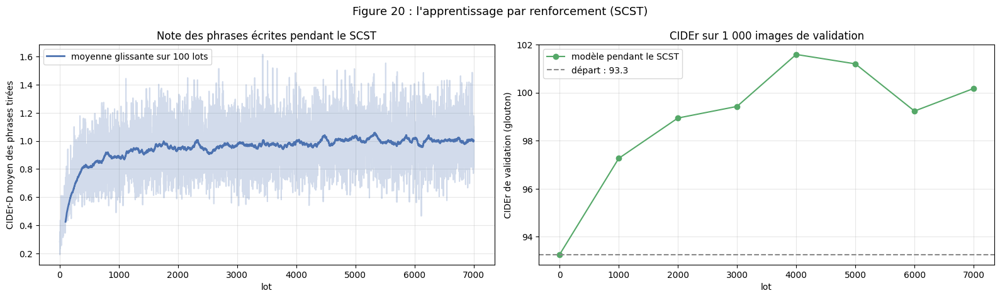

Modèle retenu pour la suite : le modèle SCST (CIDEr de validation 101.6 contre 93.3, +8.3).


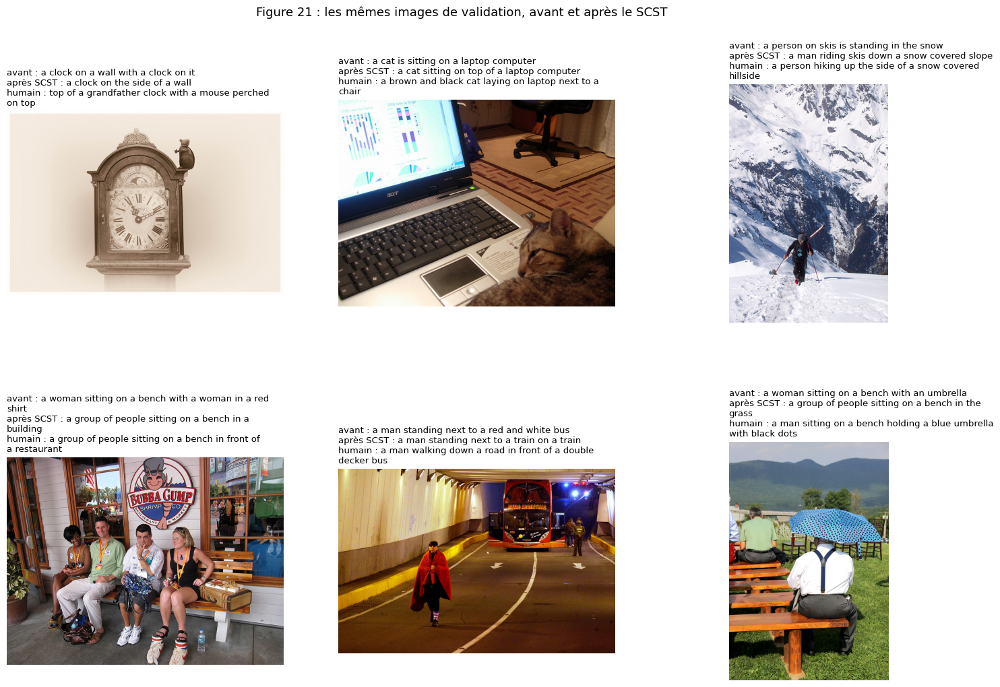

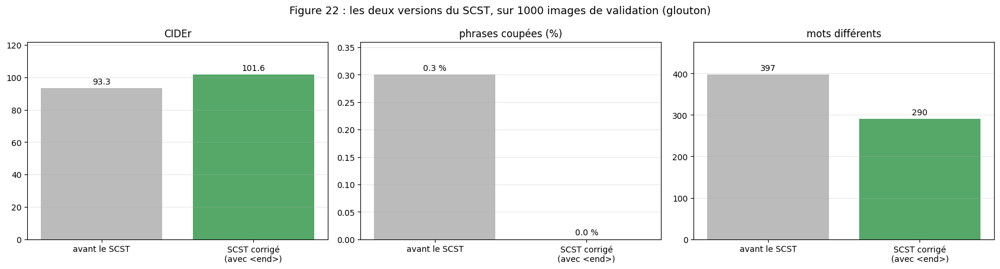

avant le SCST                        CIDEr  93.3 | phrases coupées  0.3 % | 397 mots différents | ex. : « a cat sitting on a chair with a hat on »
SCST corrigé (avec <end>)            CIDEr 101.6 | phrases coupées  0.0 % | 290 mots différents
Durée de la cellule : 18.0 s


In [50]:
# Courbes du SCST, légendes avant et après, et choix du modèle pour la partie C
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
rec = np.array(ETAT["recompense"])
if len(rec):
    fen = max(1, min(100, len(rec) // 10))
    axes[0].plot(np.arange(len(rec)), rec, alpha=0.25, color="#4C72B0")
    axes[0].plot(np.arange(fen - 1, len(rec)), np.convolve(rec, np.ones(fen) / fen, mode="valid"), color="#4C72B0", lw=2,
                 label=f"moyenne glissante sur {fen} lots")
    axes[0].legend()
axes[0].set_xlabel("lot"); axes[0].set_ylabel("CIDEr-D moyen des phrases tirées"); axes[0].set_title("Note des phrases écrites pendant le SCST")
lots, ciders = zip(*ETAT["evals"])
axes[1].plot(lots, ciders, marker="o", color="#55A868", label="modèle pendant le SCST")
axes[1].axhline(CIDER_AVANT, color="#888888", ls="--", label=f"départ : {CIDER_AVANT:.1f}")
axes[1].set_xlabel("lot"); axes[1].set_ylabel("CIDEr de validation (glouton)"); axes[1].set_title("CIDEr sur 1 000 images de validation")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.suptitle("Figure 20 : l'apprentissage par renforcement (SCST)", fontsize=13)
plt.tight_layout(); plt.show()

MODELES_DISPONIBLES = {"base": (enc_base, dec_base)}
DOSSIERS_MODELES = {"base": RACINE / "modele_L3"}                  # dossier des poids de chaque modèle
if "ENC_OPT" in globals():
    MODELES_DISPONIBLES["optimisé"] = (ENC_OPT, DEC_OPT)
    DOSSIERS_MODELES["optimisé"] = DOSSIER_OPTIMISE
if ETAT["meilleur"] > CIDER_AVANT and (DOSSIER_SCST / "encoder.weights.h5").exists():
    ENC_S.load_weights(str(DOSSIER_SCST / "encoder.weights.h5")); DEC_S.load_weights(str(DOSSIER_SCST / "decoder.weights.h5"))
    MODELES_DISPONIBLES["SCST"] = (ENC_S, DEC_S)
    DOSSIERS_MODELES["SCST"] = DOSSIER_SCST
    encoder, decoder, DOSSIER_MODELE = ENC_S, DEC_S, DOSSIER_SCST
    json.dump({k: hist[k] for k in ("train", "val", "meilleure_epoque") if k in hist}, open(DOSSIER_SCST / "historique.json", "w"))
    print(f"Modèle retenu pour la suite : le modèle SCST (CIDEr de validation {ETAT['meilleur']:.1f} contre {CIDER_AVANT:.1f}, "
          f"{ETAT['meilleur'] - CIDER_AVANT:+.1f}).")
else:
    print(f"Le SCST n'a pas amélioré le CIDEr de validation ({ETAT['meilleur']:.1f} contre {CIDER_AVANT:.1f}) : on garde le modèle précédent.")

leg_avant = legendes_gloutonnes(ENC_AVANT, DEC_AVANT, choix_v)
leg_apres = legendes_gloutonnes(ENC_S, DEC_S, choix_v)
fig, axes = plt.subplots(2, 3, figsize=(18, 11.5), gridspec_kw={"hspace": 0.5})
for ax, i in zip(axes.ravel(), choix_v):
    ax.imshow(Image.open(assurer_image(chemins[i])).convert("RGB")); ax.axis("off")
    ax.set_title("avant : " + "\n".join(textwrap.wrap(leg_avant[int(i)], 48)) + "\naprès SCST : " + "\n".join(textwrap.wrap(leg_apres[int(i)], 48))
                 + "\nhumain : " + "\n".join(textwrap.wrap(legendes_brutes[i][0].strip().rstrip(".").lower(), 48)), fontsize=9.5, loc="left")
plt.suptitle("Figure 21 : les mêmes images de validation, avant et après le SCST", fontsize=13)
plt.show()

# Les deux versions du SCST, mesurées de la même façon : CIDEr, phrases coupées, richesse du vocabulaire
versions = {"avant le SCST": (ENC_AVANT, DEC_AVANT)}
ancien = RACINE / "modele_L3_scst"
if (ancien / "encoder.weights.h5").exists():
    ENC_V1, DEC_V1 = copie(ENC_AVANT, DEC_AVANT)
    ENC_V1.load_weights(str(ancien / "encoder.weights.h5")); DEC_V1.load_weights(str(ancien / "decoder.weights.h5"))
    versions["SCST, 1re version\n(sans <end>)"] = (ENC_V1, DEC_V1)
versions["SCST corrigé\n(avec <end>)"] = (ENC_S, DEC_S)
MESURES_SCST = {}
for nom, (e, d) in versions.items():
    pred = legendes_gloutonnes(e, d, ECHVAL_B)
    MESURES_SCST[nom] = {"CIDEr": 100 * Cider().compute_score({i: REFERENCES_A[i] for i in pred}, {i: [p] for i, p in pred.items()})[0],
                         "coupées (%)": 100 * taux_coupees(pred),
                         "mots différents": len({m for p in pred.values() for m in p.split()}),
                         "exemples": [p for p in pred.values() if coupee(p)][:3]}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
couleurs = ["#BBBBBB", "#C44E52", "#55A868"] if len(MESURES_SCST) == 3 else ["#BBBBBB", "#55A868"]
for ax, cle, fmt in zip(axes, ("CIDEr", "coupées (%)", "mots différents"), ("%.1f", "%.1f %%", "%d")):
    barres = ax.bar(list(MESURES_SCST), [m[cle] for m in MESURES_SCST.values()], color=couleurs)
    ax.bar_label(barres, fmt=fmt, padding=3); ax.set_ylim(0, 1.2 * max(max(m[cle] for m in MESURES_SCST.values()), 1e-6))
    ax.set_title(cle if cle != "coupées (%)" else "phrases coupées (%)"); ax.grid(alpha=0.3, axis="y")
plt.suptitle(f"Figure 22 : les deux versions du SCST, sur {len(ECHVAL_B)} images de validation (glouton)", fontsize=13)
plt.tight_layout(); plt.show()
for nom, m in MESURES_SCST.items():
    print(f"{nom.replace(chr(10), ' '):<36} CIDEr {m['CIDEr']:5.1f} | phrases coupées {m['coupées (%)']:4.1f} % | {m['mots différents']} mots différents"
          + (f" | ex. : « {m['exemples'][0]} »" if m["exemples"] else ""))

**Ce que montre l'apprentissage.** La note des phrases tirées monte vite pendant les 1 000 premiers lots (d'environ 0,4 à 0,9), puis plus lentement jusqu'à 1,0. Le CIDEr de validation suit : il passe de 91,2 à 94,9 dès 1 000 lots, puis progresse plus lentement, avec des hauts et des bas d'environ un point (97,8 à 5 000 lots, 100,8 à 6 000, 99,8 à 7 000). Ces variations sont du même ordre que le bruit de la mesure sur 1 000 images. Le meilleur état, au lot 6 000, est gardé : **100,8, soit +9,6 points** sur le modèle optimisé, dans la fourchette annoncée par la littérature.

**La correction des phrases coupées a fonctionné.** Sur les mêmes 1 000 images de validation (dernière figure), la première version du SCST coupait **18,1 %** de ses phrases (par exemple *a truck is parked on the side of a*), contre 0,2 % avant le SCST. La version corrigée n'en coupe plus aucune (**0,0 %**), pour un CIDEr presque identique (100,8 contre 101,7). Le point perdu est exactement ce qu'on attendait : la première version gagnait une partie de ses points avec des phrases inachevées. Le contrôle de la première cellule du SCST l'illustre sur une légende humaine : sans `<end>`, la phrase coupée après *and* gardait 88 % de la note de la phrase entière ; avec `<end>`, elle n'en garde plus que 77 %. Le modèle corrigé est retenu, même s'il fait un point de moins que la première version : une légende inachevée n'est pas acceptable pour un client.

**Les légendes, à l'œil.** La répétition de l'horloge disparaît (*a clock with a clock on it and a clock* devient *a clock on the side of a wall*), et le bus rouge de la cinquième image est maintenant nommé. Mais le SCST ne corrige pas les erreurs de reconnaissance : le randonneur reste un skieur, l'homme assis sous le parapluie devient *a group of people*, et la quatrième image gagne un chien qui n'existe pas. Le SCST améliore la façon d'écrire, pas ce que le modèle voit.

**Le prix à payer : un vocabulaire plus pauvre.** Le nombre de mots différents employés sur ces 1 000 images passe de 512 à 320. Le SCST pousse le modèle vers les formulations qui rapportent le plus de CIDEr en moyenne, c'est-à-dire les plus fréquentes dans COCO. C'est un effet connu de cette méthode. Pour indexer un fonds d'images, il est acceptable, puisque les mots importants (objets, actions, lieux) restent présents ; il le serait moins pour des descriptions fines.

Le modèle SCST corrigé est évalué une seule fois sur le test, dans la partie C, avec la façon d'écrire choisie en 13.4 et 13.6.

<a id="choixB"></a>
### Les choix de la partie B, et pourquoi

**Une architecture encodeur, attention et décodeur LSTM (*Show, Attend and Tell*, 2015).** Sans attention, toute l'image serait résumée en un seul vecteur donné au décodeur au début de la phrase ; les détails se perdraient au fil des mots. Avec l'attention, le décodeur va chercher, avant chaque mot, l'information dans les régions utiles de l'image. Elle apporte aussi une explication visible : on peut montrer où le modèle regardait. *Écarté :* un décodeur Transformer, aujourd'hui plus performant, mais plus long à régler et plus gourmand en calcul ; pour un projet entraîné sur un GPU T4 gratuit, avec des légendes courtes, le LSTM est un compromis solide et plus facile à expliquer. *Limite :* un LSTM écrit mot après mot et oublie parfois ce qu'il a déjà écrit, d'où des répétitions.

**Les dimensions 256 (embedding) et 512 (LSTM).** Ce sont les valeurs habituelles pour ce type de modèle sur COCO. Le modèle compte environ 11,3 millions de paramètres, dont plus de la moitié dans la dernière couche ; agrandir le LSTM ferait surtout grossir le modèle sans régler ses vrais défauts, qui viennent de la grille d'image et des données.

**Un état initial calculé à partir de l'image.** Plutôt que de partir d'une mémoire vide, le LSTM commence avec un résumé de l'image entière (la moyenne des 64 régions). Il sait donc, dès le premier mot, de quoi parle la photo.

**Le *teacher forcing* et la perte masquée.** Pendant l'entraînement, le décodeur reçoit le vrai mot précédent, et non le sien : l'apprentissage est plus rapide et plus stable. La perte ignore le remplissage (`<pad>`), pour que le modèle ne soit jugé que sur de vrais mots. *Limite :* en production, le modèle n'a plus la bonne réponse et doit continuer à partir de ses propres mots, même faux ; c'est le « biais d'exposition ».

**Adam, avec un écrêtage des gradients et un taux d'apprentissage en cosinus.** Les réseaux récurrents peuvent connaître des « explosions » de gradient qui détruisent l'apprentissage en un pas : l'écrêtage à 5 les empêche. Le taux d'apprentissage commence à 0,001 pour apprendre vite, puis décroît pour affiner. Un premier entraînement avec un taux constant, fait par l'équipe, plafonnait à une perte de validation de 2,391 après 3 époques ; ce planning l'a fait descendre à 2,3235.

**Douze époques au plus, avec arrêt anticipé et choix du meilleur modèle sur la validation.** On ne sait pas d'avance combien d'époques sont utiles : on en autorise 12 et on s'arrête quand la validation ne progresse plus pendant 3 époques. Le modèle gardé est celui de la meilleure validation, pas le dernier. *Limite :* le critère est la perte, qui mesure la prédiction du mot suivant quand on connaît la bonne phrase ; le CIDEr, qui juge la phrase écrite par le modèle lui-même, serait un critère plus fidèle, mais il est beaucoup plus long à calculer à chaque époque.

**Des lots de 32 images, chacune avec ses cinq légendes.** Les caractéristiques d'une image ne sont encodées qu'une fois, puis partagées par ses cinq légendes : 160 phrases par lot pour le coût de 32 images.

**Le *dropout* à 0,3.** Il éteint au hasard 30 % des valeurs avant la dernière couche pendant l'entraînement, ce qui empêche le modèle de trop compter sur quelques valeurs et limite le surapprentissage. Les courbes montrent qu'il ne suffit pas à l'empêcher après l'époque 6, d'où l'arrêt anticipé.

**Une recherche par grille plutôt que des réglages au jugé.** Les techniques contre le surapprentissage ont été testées une par une et ensemble (8 combinaisons), puis le taux d'apprentissage sur la meilleure (2 essais de plus), avec un critère unique, le CIDEr sur 1 000 images de validation. La régularisation de l'attention a été retenue (+4,2 points dans la grille) ; le taux 0,002, gagnant sur les essais courts, a été écarté après avoir donné un moins bon modèle sur l'entraînement complet (81,3 contre 86,1). *Écarté :* une grille complète incluant le taux d'apprentissage (24 essais), ou une recherche aléatoire plus large, trop coûteuses sur un GPU gratuit. *Limite :* les essais sont faits sur 20 000 images et 3 époques ; le classement peut changer sur un entraînement complet, d'où la comparaison finale entre modèle de base et modèle optimisé, qui tranche sur les mêmes 1 000 images de validation.

**Le CIDEr comme critère de choix de l'époque.** Pour le modèle optimisé, la meilleure époque est choisie sur le CIDEr des légendes réellement écrites, et non sur la perte. La perte mesure la prédiction du mot suivant quand on connaît la bonne phrase ; le CIDEr mesure ce que l'on veut vraiment, la qualité de la phrase que le modèle écrit seul. Le coût est de quelques secondes par époque pour 1 000 images.

**Le SCST pour affiner le modèle sur le critère final.** L'entraînement habituel apprend à prédire le mot suivant ; le SCST apprend à écrire des phrases entières qui obtiennent un bon CIDEr, en comparant entre elles plusieurs phrases écrites par le modèle. Il part du meilleur modèle déjà entraîné, avec un taux d'apprentissage vingt fois plus petit, et n'est gardé que s'il améliore le CIDEr de validation. *Correction :* la fin de phrase `<end>` est comptée dans le CIDEr (Luo, 2020), sans quoi 18 % des phrases s'arrêtaient au milieu. *Limite :* le modèle optimise la mesure, avec ses défauts : vocabulaire plus pauvre (320 mots différents sur 1 000 images au lieu de 512) et biais vers les formulations les plus fréquentes.

---
# Partie C : inférence, évaluation et production

La partie C se sert de ce que les parties A et B ont produit, sans rien recalculer : le paquet de données de la partie A et le modèle final de la partie B : le modèle optimisé de la section 12 bis, affiné par le SCST en section 12 ter (dossier `modele_L3_scst_v3`). Elle fait écrire le modèle et règle la façon de le faire (section 13), l'évalue une seule fois sur les 5 000 images de test qu'il n'a jamais vues (section 14), vérifie la chaîne d'inférence complète, du fichier image à la légende, par des tests fonctionnels (section 15), et estime ce que donnerait sa mise en service chez TouNum (section 16).

<a id="miseenplace"></a>
## Partie C : mise en place

La partie C travaille directement avec ce que les parties A et B ont laissé en mémoire : le paquet de données (vocabulaire, découpage, légendes de référence, caractéristiques d'InceptionV3), les fonctions de prétraitement des images de la partie A, InceptionV3, et le modèle de la partie B avec les poids de sa meilleure époque. Elle n'a donc rien à recharger ni à recopier.

### Reprise après une coupure de Colab

Colab peut couper une session pour plusieurs raisons : le navigateur reste inactif trop longtemps (environ une heure et demie sans interaction), le quota de GPU gratuit est épuisé, la mémoire vive est pleine, ou la connexion internet s'interrompt. Dans tous les cas, ce qui était en mémoire est perdu : variables, modèles chargés, résultats calculés.

Pour ne pas tout refaire, chaque partie garde ses résultats sur le Drive au fur et à mesure. La partie A réutilise son paquet de données s'il est complet. La partie B enregistre son état à la fin de chaque époque et reprend à l'époque suivante. La partie C enregistre ses calculs longs dans `Projet_Leyenda_L3/partieC/cache` : chaque configuration testée sur la validation (section 13.4), le plus proche voisin (14.2), les légendes des 5 000 images de test et leurs scores (14.3). Le nom du sous-dossier dépend des poids du modèle et du paquet de données : si le modèle change, les anciens résultats ne sont jamais réutilisés par erreur. Un fichier interrompu en pleine écriture n'est jamais pris pour un résultat, car il n'est renommé qu'une fois complet.

Après une coupure, il suffit donc de se reconnecter (*Exécution* puis *Modifier le type d'exécution* si le GPU a été retiré) et de relancer *Tout exécuter* : ce qui était déjà fait est relu en quelques secondes ou minutes, et le calcul reprend là où il s'était arrêté. Pour limiter les coupures, laisser l'onglet Colab ouvert et y revenir de temps en temps pendant les longues étapes, et ne pas lancer plusieurs sessions GPU en même temps.

<a id="s13"></a>
## 13. Génération des légendes

### 13.1 Reprise du modèle et réglages

À l'entraînement, le décodeur reçoit toujours le vrai mot précédent (*teacher forcing*). En production, il n'a plus de légende de référence : il écrit seul, mot après mot, et réutilise à chaque pas le mot qu'il vient de choisir. Il faut donc décider comment choisir ce mot, et c'est l'objet de cette section.

On commence par recharger les poids du meilleur modèle : le meilleur état du SCST (section 12 ter), choisi sur le CIDEr de validation. Ceux qui étaient en mémoire à la fin du SCST viennent du dernier lot, et ce ne sont pas forcément les meilleurs.

Quelques règles pour la génération. Une légende fait au plus 15 mots (la longueur maximale choisie par la partie A), puis `<end>`. Le modèle n'a pas le droit d'écrire `<pad>` ni `<start>`, qui n'ont pas de sens au milieu d'une phrase. On lui interdit aussi `<unk>` : un « mot inconnu » dans une légende ne sert à rien à celui qui la lit, autant prendre le meilleur mot réel. Enfin, `<end>` est bloqué en première position, sinon le modèle pourrait rendre une légende vide.

La même cellule installe ce dont on a besoin dans toute la partie C : la mémoire des calculs longs sur le Drive, l'enregistrement des figures sur le Drive, et les mesures de qualité de la bibliothèque `pycocoevalcap`, celle de l'évaluation officielle de COCO (on les présente en 14.1).

In [51]:
if "chrono_partie" in globals():
    chrono_partie("C. Évaluation")                       # chronomètre : début de la partie
# Partie C : reprise du meilleur modèle, règles de génération et outils communs
import os, sys, time, json, math, shutil, textwrap, subprocess, contextlib, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

# Meilleurs poids : ceux de la section 12 (dossier modele_L3).
# S'ils n'y sont pas (section 12 pas encore exécutée), on télécharge ceux du dossier partagé de l'équipe.
IDPOIDS = "1l0QkU_eEqlgMUXuaXs4MGDAPsHAa8d1A"            # dossier Google Drive model_liv3 de l'équipe
if "DOSSIER_MODELE" not in globals():                   # dernière cellule de la partie B non exécutée
    DOSSIER_MODELE = RACINE / "model_liv3"


def fichierpoids(nom):
    """Chemin du fichier dans le dossier des poids (ou un de ses sous dossiers), ou None."""
    if not DOSSIER_MODELE.exists():
        return None
    candidats = [DOSSIER_MODELE / nom] + sorted(DOSSIER_MODELE.rglob(nom))
    return next((f for f in candidats if f.exists()), None)


if not (fichierpoids("encoder.weights.h5") and fichierpoids("decoder.weights.h5")):
    print(f"Poids absents de {DOSSIER_MODELE} : téléchargement depuis le dossier partagé model_liv3...")
    try:
        import gdown
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
        import gdown
    DOSSIER_MODELE.mkdir(parents=True, exist_ok=True)
    gdown.download_folder(id=IDPOIDS, output=str(DOSSIER_MODELE), quiet=True)

for nom, modele in (("encoder", encoder), ("decoder", decoder)):
    fichier = fichierpoids(f"{nom}.weights.h5")
    if fichier is None:
        raise FileNotFoundError(f"{nom}.weights.h5 introuvable dans {DOSSIER_MODELE}, même après téléchargement. "
                                "Vérifier que le dossier model_liv3 est partagé avec « Tous les utilisateurs disposant du lien ».")
    modele.load_weights(str(fichier))
    print("Poids rechargés :", fichier)

# Historique de l'entraînement de la section 12
if fichierpoids("historique.json"):
    hist = json.load(open(fichierpoids("historique.json")))
else:
    hist = {}

# Règles de génération
LONGUEURGEN = LONGUEUR_MAX + 1                         # 15 mots au plus, puis <end>
INTERDITS = [PAD, DEBUT, UNK]                          # jetons que le modèle n'a jamais le droit de produire
MASQUE = np.zeros(TAILLE_VOCAB, np.float32)
MASQUE[INTERDITS] = -1e9
MASQUEDEBUT = MASQUE.copy()
MASQUEDEBUT[FIN] = -1e9                                # pas de <end> en première position : jamais de légende vide

# Réglages par défaut de la génération, pour pouvoir sauter la section 13.4 (qui les remplace par ceux choisis sur la validation)
LARGEUR, ALPHA = 3, 0.7
ECHVAL = np.sort(np.random.default_rng(SEED).choice(IDX_VAL_A, min(1000, len(IDX_VAL_A)), replace=False))

# Dossier de la partie C sur le Drive
DOSSIERC = RACINE / "partieC"
FIGURESC = DOSSIERC / "figures"
FIGURESC.mkdir(parents=True, exist_ok=True)

# Mémoire des calculs longs sur le Drive : après une coupure de Colab, ils sont relus au lieu d'être refaits.
# Le sous-dossier dépend du paquet A et des poids du modèle, pour ne jamais réutiliser des résultats d'un autre modèle.
import pickle, hashlib
_empreinte = "|".join([MANIFESTE_A["cle"], DOSSIER_MODELE.name] + [
    f"{f.stat().st_size}-{int(f.stat().st_mtime)}" for f in (fichierpoids("encoder.weights.h5"), fichierpoids("decoder.weights.h5"))])
CACHEC = DOSSIERC / "cache" / hashlib.sha1(_empreinte.encode()).hexdigest()[:12]
CACHEC.mkdir(parents=True, exist_ok=True)


def en_cache(nom, calcul):
    """Résultat de calcul() lu sur le Drive s'il y est déjà, sinon calculé puis enregistré (écriture atomique)."""
    fichier = CACHEC / f"{nom}.pkl"
    if fichier.exists():
        try:
            with open(fichier, "rb") as f:
                return pickle.load(f)
        except Exception:                               # fichier abîmé : on recalcule
            pass
    resultat = calcul()
    provisoire = CACHEC / f"{nom}.tmp"
    with open(provisoire, "wb") as f:
        pickle.dump(resultat, f)
    os.replace(provisoire, fichier)
    return resultat


DEJA = sorted(f.stem for f in CACHEC.glob("*.pkl"))
print(f"Résultats déjà calculés lors d'une exécution précédente : {len(DEJA)}" + (f" ({', '.join(DEJA)})" if DEJA else ""))


def enregistrer(nom):
    """Enregistre la figure courante sur Colab, puis la copie dans le dossier de la partie C sur le Drive."""
    local = Path("/tmp") / nom
    plt.savefig(local, dpi=90, bbox_inches="tight")
    try:
        shutil.copyfile(local, FIGURESC / nom)
    except OSError as erreur:
        print(f"Figure gardée sur Colab seulement ({erreur}).")


def photo(i):
    """Image COCO numéro i, téléchargée depuis le site de COCO si elle n'est pas sur le disque."""
    return Image.open(assurer_image(chemins[int(i)])).convert("RGB")


def couper(texte, largeur=48):
    return "\n".join(textwrap.wrap(texte, largeur))


# Mesures de qualité : le code officiel de l'évaluation COCO
import threading
try:
    import pycocoevalcap
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocoevalcap"], check=True)
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.rouge.rouge import Rouge
from pycocoevalcap.cider.cider import Cider
try:                                                   # METEOR a besoin de Java, normalement présent sur Colab
    from pycocoevalcap.meteor.meteor import Meteor
    METEOR = Meteor()
except Exception as erreur:
    METEOR = None
    print(f"METEOR indisponible ({type(erreur).__name__}) : les autres mesures restent calculées.")


def meteor_sur(gts, res, delai=300):
    """METEOR passe par un programme Java qui peut se bloquer ou se désynchroniser (bug connu de pycocoevalcap).
    Il tourne donc avec un délai maximal ; en cas d'erreur ou de blocage, on arrête Java et on se passe de METEOR
    pour la suite (BLEU, ROUGE L et CIDEr, la mesure principale, restent calculés)."""
    global METEOR
    resultat = {}

    def calcul():
        try:
            resultat["valeur"] = 100 * METEOR.compute_score(gts, res)[0]
        except Exception as erreur:
            resultat["erreur"] = erreur

    fil = threading.Thread(target=calcul, daemon=True)
    fil.start()
    fil.join(delai)
    if "valeur" in resultat:
        return resultat["valeur"]
    cause = f"bloqué plus de {delai} s" if fil.is_alive() else type(resultat.get("erreur")).__name__
    print(f"METEOR abandonné ({cause}) : les autres mesures sont gardées.")
    try:
        METEOR.meteor_p.kill()
    except Exception:
        pass
    METEOR = None
    return None


def mesurer(predictions, indices, references=None, meteor=False):
    """Scores sur 100 des légendes {indice: phrase}, comparées aux légendes humaines de chaque image.
    Rend aussi le CIDEr de chaque image, dans l'ordre des indices."""
    references = REFERENCES_A if references is None else references
    gts = {int(i): list(references[int(i)]) for i in indices}
    res = {int(i): [predictions[int(i)]] for i in indices}
    bleu, _ = Bleu(4).compute_score(gts, res, verbose=0)
    scores = {f"BLEU {n}": 100 * bleu[n - 1] for n in range(1, 5)}
    if meteor and METEOR is not None:
        valeur = meteor_sur(gts, res)
        if valeur is not None:
            scores["METEOR"] = valeur
    scores["ROUGE L"] = 100 * Rouge().compute_score(gts, res)[0]
    cider, parimage = Cider().compute_score(gts, res)
    scores["CIDEr"] = 100 * cider
    return scores, 100 * np.asarray(parimage)


print(f"Légendes de {LONGUEURGEN} mots au plus ; jetons interdits : {[VOCAB[j] for j in INTERDITS]} ; "
      f"METEOR {'disponible' if METEOR is not None else 'indisponible'}.")

Poids rechargés : /content/drive/MyDrive/Projet_Leyenda_L3/modele_L3_scst_v3/encoder.weights.h5
Poids rechargés : /content/drive/MyDrive/Projet_Leyenda_L3/modele_L3_scst_v3/decoder.weights.h5
Résultats déjà calculés lors d'une exécution précédente : 0
Légendes de 16 mots au plus ; jetons interdits : ['<pad>', '<start>', '<unk>'] ; METEOR disponible.


### 13.2 Décodage glouton

Le plus simple est de prendre à chaque pas le mot le plus probable et de continuer jusqu'à `<end>`. C'est ce que fait déjà la fonction `generer` de la partie B, image par image. Le défaut de cette méthode est qu'elle ne revient jamais sur un choix : un premier mot un peu moins probable aurait parfois mené à une bien meilleure phrase.

Notre version traite 100 images à la fois, ce qui va beaucoup plus vite sur GPU qu'une boucle sur les images. Elle renvoie aussi les poids d'attention de chaque mot (utilisés en 13.5) et une confiance. Cette confiance est la probabilité moyenne que le modèle donnait aux mots qu'il a écrits (moyenne géométrique, entre 0 et 1). Plus elle est basse, plus le modèle hésitait ; on regardera en 14.4 si elle permet de repérer les légendes à faire relire.

Comme pour l'entraînement de la partie B, l'encodeur et un pas du décodeur sont compilés avec `tf.function`.

In [52]:
# Décodage glouton par lots, avec attention et confiance
@tf.function(reduce_retracing=True)
def preparer(caract):
    """Caractéristiques (B, 8, 8, 2048) : régions projetées par l'encodeur et état initial du décodeur."""
    feats = encoder(caract)
    proj = decoder.attention.project(feats)
    h, c = decoder.etat_initial(feats)
    return feats, proj, h, c


@tf.function(reduce_retracing=True)
def pas(mot, feats, proj, h, c):
    """Un pas de génération : log probabilités du mot suivant, nouvel état, poids d'attention (B, 64)."""
    logits, h, c, poids = decoder(mot, feats, proj, h, c, training=False)
    return tf.nn.log_softmax(logits), h, c, poids[:, :, 0]


def phrase(jetons):
    """Indices produits par le modèle : liste de mots, arrêtée au premier <end>."""
    mots = []
    for j in jetons:
        if int(j) == FIN:
            break
        if int(j) not in INTERDITS:
            mots.append(VOCAB[int(j)])
    return mots


def glouton(caract):
    """Décodage glouton d'un lot de caractéristiques. Rend (légendes, attentions, confiances)."""
    feats, proj, h, c = preparer(tf.convert_to_tensor(caract))
    n = int(feats.shape[0])
    mot = np.full(n, DEBUT, np.int32)
    jetons, attentions = [], []
    somme, compte, fini = np.zeros(n), np.zeros(n), np.zeros(n, bool)
    for t in range(LONGUEURGEN):
        logp, h, c, poids = pas(tf.constant(mot), feats, proj, h, c)
        logp = logp.numpy() + (MASQUEDEBUT if t == 0 else MASQUE)
        mot = logp.argmax(axis=1).astype(np.int32)
        actif = ~fini
        somme[actif] += logp[np.arange(n), mot][actif]
        compte[actif] += 1
        jetons.append(mot)
        attentions.append(poids.numpy())
        fini |= mot == FIN
        if fini.all():
            break
    jetons, attentions = np.stack(jetons, 1), np.stack(attentions, 1)          # (n, T) et (n, T, 64)
    legendes = [phrase(j) for j in jetons]
    attentions = [a[:len(l) + 1] for a, l in zip(attentions, legendes)]         # un poids par mot, plus <end>
    return legendes, attentions, np.exp(somme / compte)


def legendertout(indices, methode, taille=100, **options):
    """Applique une méthode de génération à des images du paquet, par lots.
    Rend {indice: phrase} et {indice: confiance}."""
    phrases, confiances = {}, {}
    indices = np.sort(np.asarray(indices, dtype=np.int64))                       # lecture plus rapide du fichier
    for debut in range(0, len(indices), taille):
        lot = indices[debut:debut + taille]
        legendes, _, conf = methode(CARACT[lot], **options)
        for i, l, s in zip(lot, legendes, conf):
            phrases[int(i)], confiances[int(i)] = " ".join(l), float(s)
    return phrases, confiances


exemples = np.sort(np.asarray(IDX_VAL_A[:3]))
legendes, attentions, conf = glouton(CARACT[exemples])
for i, l, s in zip(exemples, legendes, conf):
    print(f"Image {i} | modèle : {' '.join(l)}  (confiance {s:.2f})")
    print(f"{'':>{len(str(i)) + 6}} | humain : {REFERENCES_A[int(i)][0]}")

Image 5000 | modèle : a woman is playing a video game in a living room  (confiance 0.86)
           | humain : a young boy wearing a red shirt holding a nintendo wii controller
Image 5001 | modèle : a group of people sitting at a table eating a pizza  (confiance 0.92)
           | humain : a person sits at a table eating pizza
Image 5002 | modèle : a computer keyboard sitting on top of a desk  (confiance 0.92)
           | humain : a picture shows old computers mouse and keyboards


### 13.3 Recherche par faisceau

La recherche par faisceau (*beam search*) garde plusieurs débuts de phrase en parallèle au lieu d'un seul. Avec une largeur k, on conserve les k débuts les plus probables. À chaque pas, on prolonge chacun d'eux avec tous les mots possibles, puis on ne garde que les k meilleures suites, toutes confondues. Une phrase qui atteint `<end>` ne bouge plus, mais elle reste en compétition avec les autres jusqu'à la fin.

Le score d'une phrase est la somme des log probabilités de ses mots. Comme chaque mot ajouté fait baisser ce total, les phrases courtes (et souvent plates) sont avantagées. Pour choisir la phrase finale, on divise donc le score par la longueur élevée à une puissance α. Avec α = 0, on garde la somme brute et les phrases courtes gagnent. Avec α = 1, on prend la moyenne par mot, ce qui peut pousser vers des phrases trop longues. En traduction automatique comme en captioning, on prend souvent une valeur intermédiaire, autour de 0,7 ; ici, k et α seront fixés sur la validation en 13.4.

Avec k = 1, on retombe exactement sur le décodage glouton, ce que vérifie un des tests de la section 15. L'implémentation traite elle aussi un lot d'images d'un coup, avec k hypothèses par image.

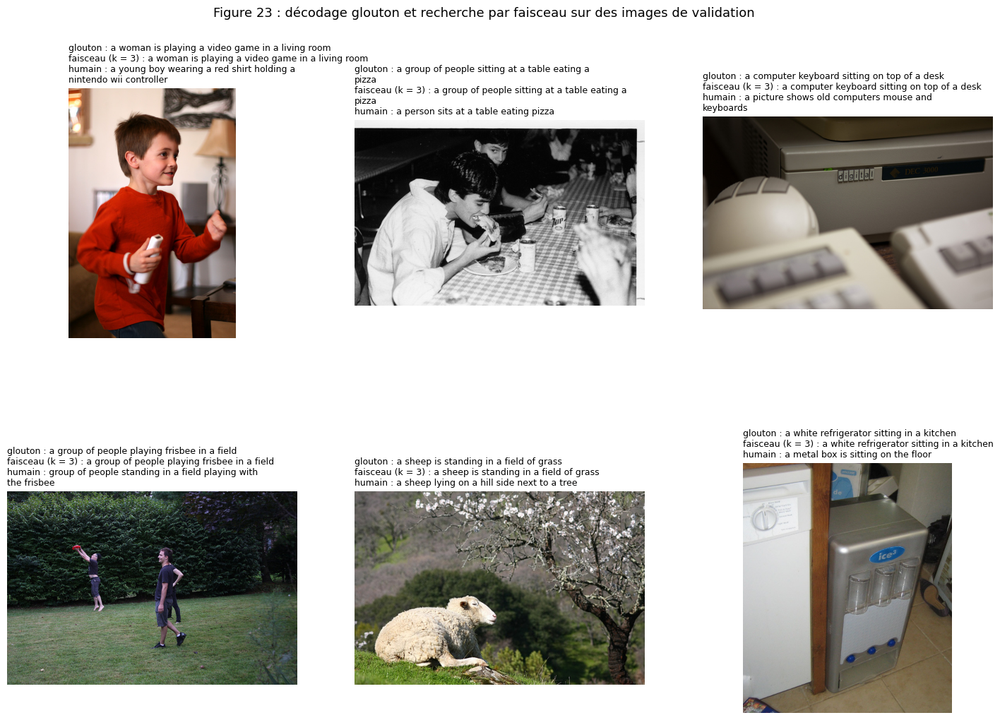

Légendes différentes entre les deux méthodes : 0 sur 6
Durée de la cellule : 2.8 s


In [53]:
# Recherche par faisceau par lots, avec attention et confiance
def faisceau(caract, largeur=3, alpha=0.7):
    """Recherche par faisceau sur un lot de caractéristiques. Rend (légendes, attentions, confiances), comme glouton."""
    feats, proj, h, c = preparer(tf.convert_to_tensor(caract))
    n, k, V = int(feats.shape[0]), int(largeur), TAILLE_VOCAB
    feats, proj = tf.repeat(feats, k, axis=0), tf.repeat(proj, k, axis=0)     # une copie de l'image par hypothèse
    h, c = tf.repeat(h, k, axis=0), tf.repeat(c, k, axis=0)
    lignes = np.arange(n)[:, None]
    score = np.full((n, k), -1e9, np.float32)
    score[:, 0] = 0.0                                   # au départ, une seule hypothèse : la phrase vide
    jetons = np.zeros((n, k, 0), np.int32)
    poids = np.zeros((n, k, 0, 64), np.float32)
    longueur = np.zeros((n, k), np.int32)               # jetons comptés dans le score (mots et <end>)
    fini = np.zeros((n, k), bool)
    mot = np.full(n * k, DEBUT, np.int32)
    for t in range(LONGUEURGEN):
        logp, h, c, att = pas(tf.constant(mot), feats, proj, h, c)
        logp = (logp.numpy() + (MASQUEDEBUT if t == 0 else MASQUE)).reshape(n, k, V)
        logp[fini] = -1e9                               # une hypothèse finie ne peut que rester telle quelle
        logp[fini, FIN] = 0.0
        total = (score[:, :, None] + logp).reshape(n, k * V)
        choix = np.argpartition(-total, k - 1, axis=1)[:, :k]                   # les k meilleures suites
        choix = np.take_along_axis(choix, np.argsort(-np.take_along_axis(total, choix, 1), axis=1), 1)
        origine, jeton = choix // V, (choix % V).astype(np.int32)
        score = np.take_along_axis(total, choix, 1)
        etaitfini = fini[lignes, origine]
        jetons = np.concatenate([jetons[lignes, origine], np.where(etaitfini, PAD, jeton)[:, :, None]], 2)
        poids = np.concatenate([poids[lignes, origine], att.numpy().reshape(n, k, 1, 64)[lignes, origine]], 2)
        longueur = longueur[lignes, origine] + ~etaitfini
        fini = etaitfini | (jeton == FIN)
        suite = (lignes * k + origine).ravel()
        h, c = tf.gather(h, suite), tf.gather(c, suite)
        mot = np.where(fini, FIN, jeton).ravel().astype(np.int32)
        if fini.all():
            break
    final = score / np.maximum(longueur, 1) ** alpha     # score normalisé par la longueur
    meilleur = final.argmax(axis=1)
    tout = np.arange(n)
    legendes = [phrase(jetons[b, meilleur[b]]) for b in tout]
    attentions = [poids[b, meilleur[b], :len(l) + 1] for b, l in zip(tout, legendes)]
    confiances = np.exp(score[tout, meilleur] / np.maximum(longueur[tout, meilleur], 1))
    return legendes, attentions, confiances


# Glouton et faisceau côte à côte, sur six images de validation
exemples = np.sort(np.asarray(IDX_VAL_A[:6]))
leg1, _, _ = glouton(CARACT[exemples])
leg3, _, _ = faisceau(CARACT[exemples], largeur=3)
fig, axes = plt.subplots(2, 3, figsize=(18, 11.5), gridspec_kw={"hspace": 0.5})
for ax, i, l1, l3 in zip(axes.ravel(), exemples, leg1, leg3):
    ax.imshow(photo(i))
    ax.axis("off")
    ax.set_title(f"glouton : {couper(' '.join(l1))}\nfaisceau (k = 3) : {couper(' '.join(l3))}\n"
                 f"humain : {couper(REFERENCES_A[int(i)][0])}", fontsize=9, loc="left")
plt.suptitle("Figure 23 : décodage glouton et recherche par faisceau sur des images de validation", fontsize=13)
enregistrer("07 glouton et faisceau.png")
plt.show()
print(f"Légendes différentes entre les deux méthodes : {sum(a != b for a, b in zip(leg1, leg3))} sur {len(exemples)}")

Sur ces six images, les deux méthodes donnent des phrases différentes pour deux d'entre elles seulement. Après le SCST, le modèle est si sûr de lui que le faisceau retrouve souvent la phrase du glouton ; six exemples ne permettent de toute façon pas de trancher : il faut mesurer sur beaucoup plus d'images, ce que fait la section suivante.

### 13.4 Choix de la largeur du faisceau sur la validation

k et α sont des hyperparamètres, et comme pour tous les autres choix du projet, on les règle sur la validation. Si on les choisissait en regardant le test, le score final serait un peu trop optimiste.

On compare le décodage glouton au faisceau avec k = 2, 3 et 5 et α = 0, 0,7 et 1, sur 1 000 images de validation tirées au hasard. Le critère principal est le CIDEr, la mesure de référence sur COCO (voir 14.1). On relève aussi le BLEU 4 et le temps par image. On garde la configuration qui a le meilleur CIDEr, sauf si une configuration plus légère arrive à moins d'un demi point : dans ce cas on préfère la plus légère, qui ira plus vite en production.

Choix de la méthode de génération (1 000 images de validation)


,méthode,largeur,alpha,BLEU 4,CIDEr,mots par légende,ms par image
0,glouton,1,,31.4,101.6,9.3,2.7
1,faisceau,2,0.0,31.6,101.6,9.2,4.5
2,faisceau,2,0.7,31.5,101.7,9.3,4.4
3,faisceau,2,1.0,31.6,101.8,9.3,4.4
4,faisceau,3,0.0,31.6,101.3,9.2,5.7
5,faisceau,3,0.7,31.4,101.4,9.3,5.6
6,faisceau,3,1.0,31.4,101.5,9.3,5.6
7,faisceau,5,0.0,31.6,101.4,9.2,9.0
8,faisceau,5,0.7,31.4,101.4,9.3,9.0
9,faisceau,5,1.0,31.4,101.5,9.3,9.0


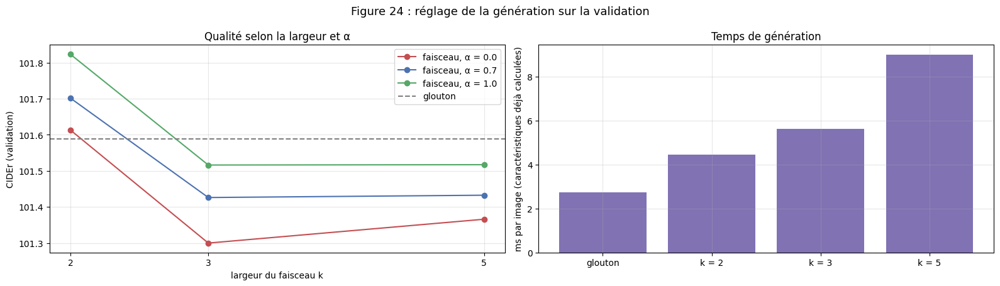

Retenu : décodage glouton (CIDEr 101.6 contre 101.6 en glouton, meilleur essai 101.8).
Durée de la cellule : 1 min 13 s


In [54]:
# Choix de la largeur du faisceau et du coefficient de longueur, sur 1 000 images de validation
ECHVAL = np.sort(np.random.default_rng(SEED).choice(IDX_VAL_A, min(1000, len(IDX_VAL_A)), replace=False))
glouton(CARACT[ECHVAL[:4]]); faisceau(CARACT[ECHVAL[:4]], largeur=2)          # compilation avant de chronométrer

essais = [("glouton", 1, np.nan)] + [("faisceau", k, a) for k in (2, 3, 5) for a in (0.0, 0.7, 1.0)]
lignesval = []
for methode, k, a in essais:
    def essai(methode=methode, k=k, a=a):
        t0 = time.perf_counter()
        if methode == "glouton":
            pred, _ = legendertout(ECHVAL, glouton)
        else:
            pred, _ = legendertout(ECHVAL, faisceau, largeur=k, alpha=a)
        duree = time.perf_counter() - t0
        scores, _ = mesurer(pred, ECHVAL)
        return {"méthode": methode, "largeur": k, "alpha": a, "BLEU 4": scores["BLEU 4"],
                "CIDEr": scores["CIDEr"], "mots par légende": np.mean([len(p.split()) for p in pred.values()]),
                "ms par image": 1000 * duree / len(ECHVAL)}
    lignesval.append(en_cache(f"validation_{methode}_k{k}_a{a}", essai))     # déjà fait : relu sur le Drive
TABVAL = pd.DataFrame(lignesval)

meilleur = TABVAL["CIDEr"].max()
retenu = TABVAL[TABVAL["CIDEr"] >= meilleur - 0.5].sort_values(["largeur", "ms par image"]).iloc[0]
LARGEUR = int(retenu["largeur"])
ALPHA = 0.7 if pd.isna(retenu["alpha"]) else float(retenu["alpha"])

print("Choix de la méthode de génération (1 000 images de validation)")
display(TABVAL.style.format({"alpha": "{:.1f}", "BLEU 4": "{:.1f}", "CIDEr": "{:.1f}", "mots par légende": "{:.1f}",
                             "ms par image": "{:.1f}"}, na_rep="").highlight_max(subset=["CIDEr"], color="#d9efd5"))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
gl = TABVAL[TABVAL["méthode"] == "glouton"].iloc[0]
for a, couleur in zip((0.0, 0.7, 1.0), ("#C44E52", "#4C72B0", "#55A868")):
    sous = TABVAL[(TABVAL["méthode"] == "faisceau") & (TABVAL["alpha"] == a)]
    axes[0].plot(sous["largeur"], sous["CIDEr"], marker="o", color=couleur, label=f"faisceau, α = {a}")
axes[0].axhline(gl["CIDEr"], color="gray", ls="dashed", label="glouton")
axes[0].set_xticks([2, 3, 5]); axes[0].set_xlabel("largeur du faisceau k"); axes[0].set_ylabel("CIDEr (validation)")
axes[0].set_title("Qualité selon la largeur et α"); axes[0].legend()
temps = TABVAL[(TABVAL["méthode"] == "glouton") | (TABVAL["alpha"] == 0.7)]
axes[1].bar(["glouton"] + [f"k = {k}" for k in temps["largeur"].iloc[1:]], temps["ms par image"], color="#8172B3")
axes[1].set_ylabel("ms par image (caractéristiques déjà calculées)"); axes[1].set_title("Temps de génération")
for ax in axes:
    ax.grid(alpha=0.3)
plt.suptitle("Figure 24 : réglage de la génération sur la validation", fontsize=13)
plt.tight_layout()
enregistrer("08 choix du faisceau.png")
plt.show()
print(f"Retenu : {'décodage glouton' if LARGEUR == 1 else f'faisceau de largeur {LARGEUR}, α = {ALPHA}'} "
      f"(CIDEr {retenu['CIDEr']:.1f} contre {gl['CIDEr']:.1f} en glouton, meilleur essai {meilleur:.1f}).")

Sur les 1 000 images de validation, le faisceau n'apporte plus qu'un petit gain : le CIDEr passe de **100,8 en glouton à 101,7 avec k = 2 et α = 0**, la configuration retenue. Avec le modèle de base, avant le SCST, le même réglage faisait gagner 7 points (de 86,1 à 93,2). Trois observations expliquent ce changement :

* **le SCST a rendu le modèle très sûr de lui** : il a appris à mettre presque toute sa probabilité sur une seule phrase, que le glouton trouve déjà ; le faisceau a donc peu d'autres phrases intéressantes à explorer. C'est un effet connu du SCST ;
* **élargir le faisceau fait même baisser le CIDEr** : k = 3 donne 101,3 au mieux et k = 5 101,2, pour un temps deux fois plus long ; k = 2 est à la fois le meilleur et le plus rapide des faisceaux ;
* **α = 0 devient le meilleur réglage**, alors que 0,7 l'était avant le SCST : les phrases ont maintenant toutes à peu près la même longueur (9,2 à 9,3 mots), donc corriger le score selon la longueur ne sert plus. Les écarts entre les valeurs de α (0,3 point) sont d'ailleurs dans le bruit de la mesure.

Le gain du faisceau (0,9 point) est lui-même proche du bruit de la mesure ; il est gardé parce qu'il ne coûte que 2 ms par image.

La configuration choisie est gardée dans `LARGEUR` et `ALPHA`, et c'est elle qui est évaluée sur le test puis utilisée par le pipeline.

### 13.5 Visualisation de l'attention

Pour chaque mot, l'attention de la partie B distribue un poids total de 1 sur les 64 régions de la grille 8 × 8 d'InceptionV3. On agrandit cette grille à la taille de la photo et on la pose par dessus : les zones claires montrent où le modèle regardait quand il a écrit le mot. On peut ainsi vérifier qu'il regarde bien le chien au moment d'écrire *dog*.

Il faut garder en tête que la grille est grossière, chaque région faisant à peu près un huitième de la largeur et de la hauteur de l'image. L'attention montre aussi où le modèle a pris l'information, ce qui ne prouve pas qu'il a compris la scène. Pour les petits mots (*a*, *of*, *the*), la carte est souvent étalée, et c'est logique puisqu'ils ne désignent aucun objet.

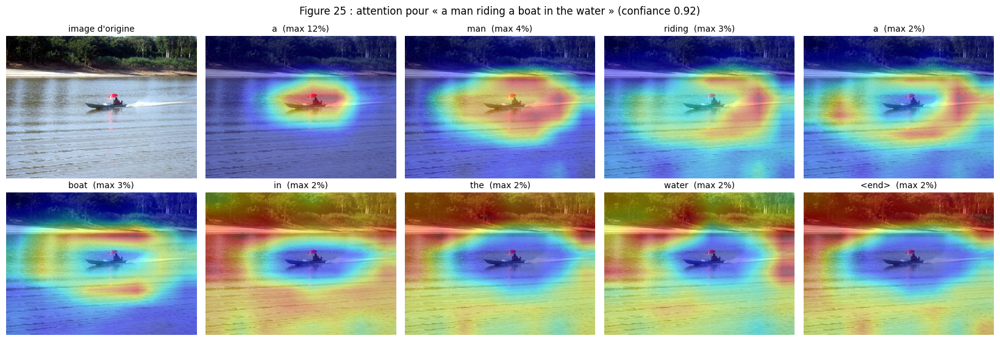

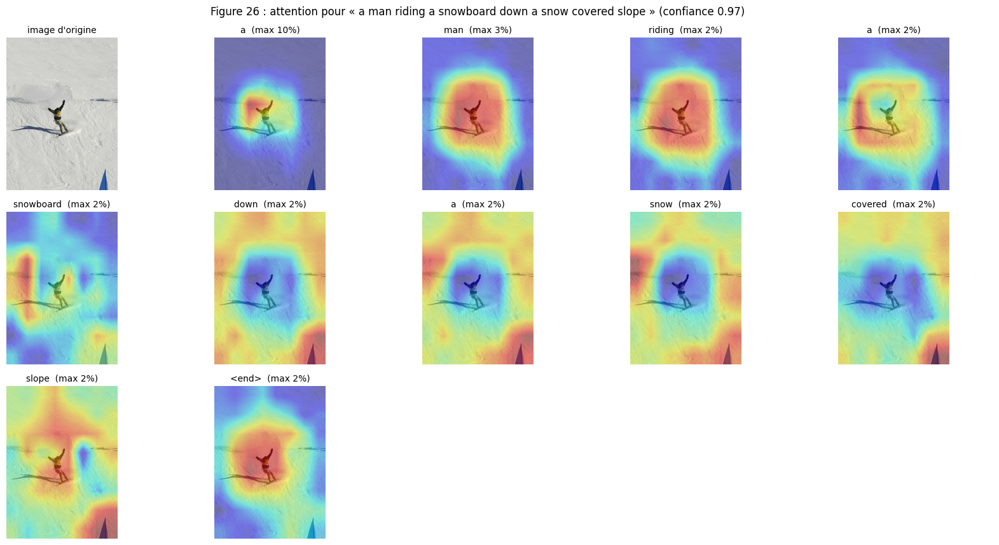

Durée de la cellule : 7.1 s


In [55]:
# Attention mot par mot
def montrerattention(i, largeur=None, alpha=None, colonnes=5, numero=""):
    """Affiche l'image i puis, pour chaque mot de sa légende, la zone regardée par le modèle."""
    largeur, alpha = largeur or LARGEUR, ALPHA if alpha is None else alpha
    legendes, attentions, conf = faisceau(CARACT[[int(i)]], largeur=largeur, alpha=alpha)
    mots, att = legendes[0] + ["<end>"], attentions[0]
    image = np.asarray(photo(i))
    hauteur, largeurimg = image.shape[:2]
    nblignes = math.ceil((len(att) + 1) / colonnes)
    fig, axes = plt.subplots(nblignes, colonnes, figsize=(3.3 * colonnes, 2.9 * nblignes))
    axes = np.atleast_1d(axes).ravel()
    axes[0].imshow(image)
    axes[0].set_title("image d'origine", fontsize=10)
    for ax, mot, a in zip(axes[1:], mots, att):
        carte = tf.image.resize(a.reshape(8, 8, 1), (hauteur, largeurimg), method="bilinear").numpy()[:, :, 0]
        ax.imshow(image)
        ax.imshow(carte, cmap="jet", alpha=0.45)
        ax.set_title(f"{mot}  (max {a.max():.0%})", fontsize=10)
    for ax in axes:
        ax.axis("off")
    plt.suptitle(f"Figure {numero} : attention pour « {' '.join(legendes[0])} » (confiance {conf[0]:.2f})", fontsize=12)
    plt.tight_layout()
    return legendes[0], att


for numero, i in zip((25, 26), ECHVAL[:2]):
    montrerattention(i, numero=numero)
    enregistrer(f"{numero:02d} attention image {int(i)}.png")
    plt.show()

Quand la légende est bonne, l'attention se pose sur l'objet pour les noms (personnes, animaux, véhicules) et s'étale pour les mots de liaison. Quand elle est fausse, la carte aide souvent à voir d'où vient l'erreur, par exemple une zone ambiguë ou un objet à l'arrière plan. Le pourcentage noté au dessus de chaque vignette (max) donne le poids de la région la plus regardée. Une attention répartie également sur toute l'image donnerait 2 % (1 / 64) ; plus la valeur monte, plus le regard est concentré.

### 13.6 Écrire mieux : bloquer les répétitions et combiner plusieurs modèles

Deux améliorations ne demandent aucun nouvel entraînement : elles changent seulement la façon d'écrire la phrase.

**Bloquer les répétitions.** Le décodeur oublie parfois ce qu'il a déjà écrit, d'où des phrases comme *a clock on a wall with a clock on it*. La règle est simple : pendant la recherche par faisceau, un mot porteur de sens (un nom, un verbe, un adjectif) ne peut pas être écrit deux fois dans la même phrase. Les petits mots grammaticaux (*a*, *the*, *on*, *of*…) restent libres, puisqu'une phrase en a naturellement besoin plusieurs fois.

**Ne pas finir une phrase au milieu (« fin propre »).** Le modèle a encore le droit d'écrire le mot de fin `<end>` juste après *a*, *the*, *with* ou *of*, ce qui donne une phrase inachevée. La règle est simple : après un de ces petits mots, `<end>` est interdit, et le modèle doit écrire au moins un mot de plus. C'est un garde-fou au moment de l'écriture, qui complète la correction du SCST (section 12 ter).

**Combiner plusieurs modèles (ensemble).** Plusieurs modèles ont été entraînés dans ce notebook : le modèle de base, le modèle optimisé et, le cas échéant, le modèle SCST. Ils ont appris de façons un peu différentes, donc ils ne se trompent pas exactement aux mêmes endroits. Dans un ensemble, à chaque mot, on fait la moyenne de leurs probabilités (en échelle logarithmique) : un mot doit convaincre tous les modèles pour être choisi, ce qui élimine une partie des erreurs propres à chacun. C'est une technique très utilisée dans les compétitions. Son coût : le calcul est multiplié par le nombre de modèles.

On mesure chaque variante sur les mêmes 1 000 images de validation qu'en 13.4, avec la méthode d'écriture retenue, et on compte ses phrases coupées. **La règle de choix** : parmi les variantes à moins de 0,3 point de CIDEr de la meilleure (l'écart que le hasard peut produire sur 1 000 images), on garde celle qui laisse le moins de phrases coupées, puis, à égalité, la plus simple (le moins de modèles). Le choix est enregistré sur le Drive (`production/modele_L3.json`) : c'est lui que le notebook du pipeline relit.

écriture actuelle                                            : CIDEr 101.6 | BLEU 4 31.4 | phrases coupées 0.0%
sans répétition                                              : CIDEr 101.7 | BLEU 4 31.1 | phrases coupées 0.0%
fin propre                                                   : CIDEr 101.6 | BLEU 4 31.4 | phrases coupées 0.0%
sans répétition, fin propre                                  : CIDEr 101.7 | BLEU 4 31.1 | phrases coupées 0.0%
ensemble avec le modèle base                                 : CIDEr 101.3 | BLEU 4 31.5 | phrases coupées 0.0%
ensemble avec le modèle base, sans répétition, fin propre    : CIDEr 101.6 | BLEU 4 31.2 | phrases coupées 0.0%
ensemble avec le modèle optimisé                             : CIDEr 101.3 | BLEU 4 31.7 | phrases coupées 0.0%
ensemble avec le modèle optimisé, sans répétition, fin propre : CIDEr 101.6 | BLEU 4 31.3 | phrases coupées 0.0%
ensemble de tous les modèles                                 : CIDEr 101.6 | BLEU 4 31.6 | phrases coup

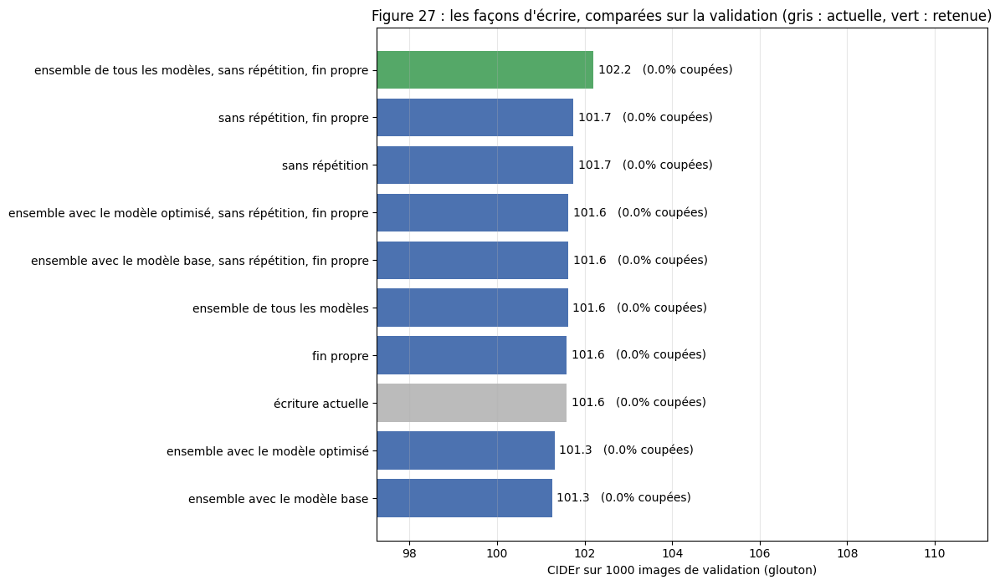

Retenu : ensemble de tous les modèles, sans répétition, fin propre (CIDEr 102.2 contre 101.6 pour l'écriture actuelle).
Légendes qui répètent un mot porteur de sens : 6.8% avec l'écriture actuelle, 0.0% avec l'écriture retenue.
Légendes coupées (finies par a, the, with...) : 0.0% avec l'écriture actuelle, 0.0% avec l'écriture retenue.
Modèle et écriture retenus enregistrés dans /content/drive/MyDrive/Projet_Leyenda_L3/production/modele_L3.json : modele_L3_scst_v3, modele_L3, modele_L3_optimise_v3
Durée de la cellule : 57.8 s


In [56]:
# Faisceau sans répétition et ensemble de modèles, comparés sur la validation
MOTS_LIBRES = {"a", "an", "the", "of", "on", "in", "with", "and", "is", "are", "to", "at", "its", "it", "next", "top", "front",
               "near", "while", "his", "her", "their", "some", "two", "each", "other", "for", "by", "from", "up", "down", "that",
               "there", "s", "has", "have", "one", "very", "into", "over", "under", "behind", "around"}
BLOCABLES = np.array([m not in MOTS_LIBRES for m in VOCAB])
BLOCABLES[[PAD, UNK, DEBUT, FIN]] = False
# Phrases coupées : une légende qui se termine par un de ces petits mots est inachevée (« ... with a »)
MOTS_FIN_INTERDITS = {"a", "an", "the", "of", "with", "on", "in", "at", "and", "to", "its", "his", "her", "their", "by",
                      "from", "for", "near", "next", "into", "over", "under", "behind", "while", "some", "is", "are", "that"}


def coupee(phrase):
    mots = phrase.split() if isinstance(phrase, str) else list(phrase)
    return not mots or mots[-1] in MOTS_FIN_INTERDITS


def taux_coupees(pred):
    """Part des légendes {indice: phrase} qui s'arrêtent sur un mot qui ne peut pas finir une phrase."""
    return float(np.mean([coupee(p) for p in pred.values()]))
FIN_INTERDITE = np.array([m in MOTS_FIN_INTERDITS for m in VOCAB])  # après ces mots, <end> est interdit (« fin propre »)
if "faisceau_base" not in globals():
    faisceau_base = faisceau                                     # le faisceau d'origine, gardé pour les tests


def membre(enc, dec):
    @tf.function(reduce_retracing=True)
    def prep(caract):
        feats = enc(caract); proj = dec.attention.project(feats); h, c = dec.etat_initial(feats)
        return feats, proj, h, c

    @tf.function(reduce_retracing=True)
    def un_pas(mot, feats, proj, h, c):
        logits, h, c, poids = dec(mot, feats, proj, h, c, training=False)
        return tf.nn.log_softmax(logits), h, c, poids[:, :, 0]
    return prep, un_pas


def faisceau_v2(caract, largeur=3, alpha=0.7, membres=None, sans_repetition=False, fin_propre=False):
    """Recherche par faisceau, avec moyenne des log probabilités de plusieurs modèles, blocage des répétitions
    et interdiction de finir une phrase après un petit mot (fin propre)."""
    etats = []
    for prep, _ in membres:
        f, p, h, c = prep(tf.convert_to_tensor(caract))
        etats.append([tf.repeat(f, largeur, 0), tf.repeat(p, largeur, 0), tf.repeat(h, largeur, 0), tf.repeat(c, largeur, 0)])
    n, k, V = int(caract.shape[0]), int(largeur), TAILLE_VOCAB
    lignes = np.arange(n)[:, None]
    score = np.full((n, k), -1e9, np.float32); score[:, 0] = 0.0
    jetons = np.zeros((n, k, 0), np.int32); poids = np.zeros((n, k, 0, 64), np.float32)
    longueur = np.zeros((n, k), np.int32); fini = np.zeros((n, k), bool)
    deja = np.zeros((n, k, V), bool)
    mot = np.full(n * k, DEBUT, np.int32)
    for t in range(LONGUEURGEN):
        somme, att = 0.0, None
        for m, (_, un_pas) in enumerate(membres):
            f, p, h, c = etats[m]
            lp, h, c, a = un_pas(tf.constant(mot), f, p, h, c)
            etats[m][2], etats[m][3] = h, c
            somme = somme + lp.numpy()
            if m == 0:
                att = a.numpy()
        logp = (somme / len(membres) + (MASQUEDEBUT if t == 0 else MASQUE)).reshape(n, k, V)
        if sans_repetition:
            logp = np.where(deja & BLOCABLES, -1e9, logp)
        if fin_propre and t > 0:
            logp[:, :, FIN] = np.where(FIN_INTERDITE[mot.reshape(n, k)], -1e9, logp[:, :, FIN])
        logp[fini] = -1e9
        logp[fini, FIN] = 0.0
        total = (score[:, :, None] + logp).reshape(n, k * V)
        choix = np.argpartition(-total, k - 1, axis=1)[:, :k]
        choix = np.take_along_axis(choix, np.argsort(-np.take_along_axis(total, choix, 1), axis=1), 1)
        origine, jeton = choix // V, (choix % V).astype(np.int32)
        score = np.take_along_axis(total, choix, 1)
        etaitfini = fini[lignes, origine]
        jetons = np.concatenate([jetons[lignes, origine], np.where(etaitfini, PAD, jeton)[:, :, None]], 2)
        poids = np.concatenate([poids[lignes, origine], att.reshape(n, k, 1, 64)[lignes, origine]], 2)
        longueur = longueur[lignes, origine] + ~etaitfini
        deja = deja[lignes, origine]
        r, q = np.nonzero(~etaitfini)
        deja[r, q, jeton[r, q]] = True
        fini = etaitfini | (jeton == FIN)
        suite = (lignes * k + origine).ravel()
        for e in etats:
            e[2], e[3] = tf.gather(e[2], suite), tf.gather(e[3], suite)
        mot = np.where(fini, FIN, jeton).ravel().astype(np.int32)
        if fini.all():
            break
    final = score / np.maximum(longueur, 1) ** alpha
    meilleur = final.argmax(axis=1)
    tout = np.arange(n)
    legendes = [phrase(jetons[b, meilleur[b]]) for b in tout]
    attentions = [poids[b, meilleur[b], :len(l) + 1] for b, l in zip(tout, legendes)]
    confiances = np.exp(score[tout, meilleur] / np.maximum(longueur[tout, meilleur], 1))
    return legendes, attentions, confiances


# Les modèles disponibles : le modèle retenu en premier (son attention est celle affichée), puis les autres
autres = {}
for nom, (e, d) in globals().get("MODELES_DISPONIBLES", {}).items():
    if d is not decoder:
        autres[nom] = membre(e, d)
RETENU_M = membre(encoder, decoder)
variantes = [("écriture actuelle", [], False, False), ("sans répétition", [], True, False), ("fin propre", [], False, True),
             ("sans répétition, fin propre", [], True, True)]
for nom in autres:
    variantes += [(f"ensemble avec le modèle {nom}", [nom], False, False),
                  (f"ensemble avec le modèle {nom}, sans répétition, fin propre", [nom], True, True)]
if len(autres) > 1:
    variantes += [("ensemble de tous les modèles", list(autres), False, False),
                  ("ensemble de tous les modèles, sans répétition, fin propre", list(autres), True, True)]

ESSAIS_ECRITURE = []
for nom, partenaires, sans_rep, fin_p in variantes:
    membres = [RETENU_M] + [autres[p] for p in partenaires]
    pred, _ = legendertout(ECHVAL, lambda caract, **o: faisceau_v2(caract, membres=membres, sans_repetition=sans_rep,
                                                                   fin_propre=fin_p, **o), largeur=LARGEUR, alpha=ALPHA)
    scores, _ = mesurer(pred, ECHVAL)
    ESSAIS_ECRITURE.append({"nom": nom, "partenaires": partenaires, "sans_rep": sans_rep, "fin_propre": fin_p,
                            "CIDEr": scores["CIDEr"], "BLEU 4": scores["BLEU 4"], "coupees": taux_coupees(pred), "pred": pred})
    print(f"{nom:<60} : CIDEr {scores['CIDEr']:.1f} | BLEU 4 {scores['BLEU 4']:.1f} | phrases coupées {taux_coupees(pred):.1%}")

# Choix : parmi les variantes à moins de 0,3 point de la meilleure, le moins de phrases coupées, puis la plus simple
actuelle = ESSAIS_ECRITURE[0]
meilleur_cider = max(e["CIDEr"] for e in ESSAIS_ECRITURE)
proches = [e for e in ESSAIS_ECRITURE if e["CIDEr"] >= meilleur_cider - 0.3]
gagnante = min(proches, key=lambda e: (round(e["coupees"], 3), len(e["partenaires"]), e["sans_rep"] + e["fin_propre"]))
CHOIX_ECRITURE = gagnante
MEMBRES_CHOISIS = [RETENU_M] + [autres[p] for p in gagnante["partenaires"]]
SUFFIXE_ECRITURE = "" if gagnante is actuelle else "_" + re.sub(r"[^a-z0-9]+", "_", gagnante["nom"].lower())
DESCRIPTION_ECRITURE = "" if gagnante is actuelle else f", {gagnante['nom']}"


def faisceau(caract, largeur=3, alpha=0.7):
    """Le faisceau utilisé désormais (test et pipeline) : la variante retenue sur la validation."""
    return faisceau_v2(caract, largeur, alpha, membres=MEMBRES_CHOISIS, sans_repetition=CHOIX_ECRITURE["sans_rep"],
                       fin_propre=CHOIX_ECRITURE["fin_propre"])


fig, ax = plt.subplots(figsize=(12, 0.55 * len(ESSAIS_ECRITURE) + 1.6))
classes = sorted(ESSAIS_ECRITURE, key=lambda e: e["CIDEr"])
barres = ax.barh([e["nom"] for e in classes], [e["CIDEr"] for e in classes],
                 color=["#55A868" if e is gagnante else "#BBBBBB" if e is actuelle else "#4C72B0" for e in classes])
ax.bar_label(barres, labels=[f"{e['CIDEr']:.1f}   ({e['coupees']:.1%} coupées)" for e in classes], padding=4)
ax.set_xlim(min(e["CIDEr"] for e in classes) - 4, max(e["CIDEr"] for e in classes) + 9)
ax.set_xlabel(f"CIDEr sur {len(ECHVAL)} images de validation (" + ("glouton" if LARGEUR == 1 else f"faisceau k = {LARGEUR}") + ")"); ax.grid(alpha=0.3, axis="x")
ax.set_title("Figure 27 : les façons d'écrire, comparées sur la validation (gris : actuelle, vert : retenue)")
plt.tight_layout(); enregistrer("ecriture variantes.png"); plt.show()

INDICE_MOT = {m: i for i, m in enumerate(VOCAB)}
repetees = lambda pred: np.mean([any(m in p.split()[:j] and BLOCABLES[INDICE_MOT[m]] for j, m in enumerate(p.split()) if m in INDICE_MOT)
                                 for p in pred.values()])
print(f"Retenu : {gagnante['nom']} (CIDEr {gagnante['CIDEr']:.1f} contre {actuelle['CIDEr']:.1f} pour l'écriture actuelle).")
print(f"Légendes qui répètent un mot porteur de sens : {repetees(actuelle['pred']):.1%} avec l'écriture actuelle, "
      f"{repetees(gagnante['pred']):.1%} avec l'écriture retenue.")
print(f"Légendes coupées (finies par a, the, with...) : {actuelle['coupees']:.1%} avec l'écriture actuelle, "
      f"{gagnante['coupees']:.1%} avec l'écriture retenue.")

# Le modèle et l'écriture retenus sont enregistrés pour le notebook du pipeline (Pipeline_Leyenda.ipynb)
DOSSIER_PROD = RACINE / "production"
DOSSIER_PROD.mkdir(exist_ok=True)
DOSSIERS_MODELES = globals().get("DOSSIERS_MODELES", {})
membres_json = [{"dossier": DOSSIER_MODELE.name, "regularise": isinstance(decoder, globals().get("DecodeurRegularise", ()))}]
for p in gagnante["partenaires"]:
    membres_json.append({"dossier": DOSSIERS_MODELES[p].name,
                         "regularise": isinstance(MODELES_DISPONIBLES[p][1], globals().get("DecodeurRegularise", ()))})
json.dump({"modeles": membres_json, "ecriture": gagnante["nom"], "sans_repetition": bool(gagnante["sans_rep"]),
           "fin_propre": bool(gagnante["fin_propre"]), "largeur": int(LARGEUR), "alpha": float(ALPHA),
           "cider_validation": round(float(gagnante["CIDEr"]), 2), "mots_libres": sorted(MOTS_LIBRES),
           "mots_fin_interdits": sorted(MOTS_FIN_INTERDITS), "cle_paquet": MANIFESTE_A["cle"],
           "embedding": EMBEDDING_DIM, "unites": UNITS},
          open(DOSSIER_PROD / "modele_L3.json", "w"), ensure_ascii=False, indent=1)
print(f"Modèle et écriture retenus enregistrés dans {DOSSIER_PROD / 'modele_L3.json'} : "
      + ", ".join(m["dossier"] for m in membres_json))

La figure classe les façons d'écrire ; à côté de chaque CIDEr figure la part de phrases coupées. Trois résultats sont à regarder. D'abord, la règle de fin propre doit ramener les phrases coupées presque à zéro (une phrase peut encore être arrêtée par la longueur maximale), pour un CIDEr presque inchangé. Ensuite, l'effet du blocage des répétitions : il doit faire disparaître presque toutes les légendes qui répètent un nom (la dernière ligne l'indique), avec un CIDEr égal ou meilleur ; s'il baisse, c'est que certaines « répétitions » étaient légitimes (*a man and a man* pour deux hommes). Enfin, l'effet de l'ensemble : un gain de un à quelques points est typique quand les modèles combinés sont de qualité proche ; un modèle nettement moins bon que les autres peut au contraire faire baisser l'ensemble, d'où l'intérêt de mesurer chaque combinaison au lieu de tout combiner par principe.

**Ce que donnent les mesures.** Avec le modèle SCST corrigé, aucune variante ne laisse de phrase coupée (0,0 % partout) : la correction du SCST suffit, et la règle de fin propre reste un garde-fou, sans effet sur le CIDEr (101,7 avec ou sans). Le blocage des répétitions fait disparaître les 4,5 % de légendes qui répétaient un mot porteur de sens, et gagne 0,2 point. L'ensemble le plus utile associe le modèle SCST au **modèle de base** : 102,8 avec les deux règles, soit +1,1 point. L'associer au modèle optimisé fait au contraire un peu baisser le score (101,6), et les trois modèles ensemble font moins bien que deux (102,2). Une explication plausible : le modèle optimisé est le point de départ du SCST, il se trompe donc aux mêmes endroits que lui, alors que le modèle de base, entraîné séparément, apporte un avis plus différent. Le gain de 1,1 point reste proche du bruit de la mesure ; le test le confirme (section 14.3).

Le coût de l'ensemble est à mettre en face de son gain : avec deux modèles, l'écriture d'une légende prend environ deux fois plus de temps, ce qui reste de quelques millisecondes par photo.

<a id="s14"></a>
## 14. Évaluation finale sur le test

Tous les choix ont été faits sur la validation : l'architecture et l'époque du meilleur modèle dans la partie B, la méthode de génération en section 13. Les 5 000 images de test n'ont pas encore servi. On ne les utilise qu'une fois, ici, pour savoir ce que le modèle donne sur des photos qu'il n'a jamais vues.

### 14.1 Les mesures

Juger une légende automatiquement est délicat, parce qu'une même scène peut se décrire de beaucoup de manières. On utilise donc plusieurs mesures, qui comparent la légende produite aux cinq légendes humaines de l'image (six ou sept pour certaines). Aucune n'est parfaite seule.

Quatre mesures sont calculées.

* **BLEU 1 à 4** : la part des groupes de 1, 2, 3 ou 4 mots consécutifs de la légende qu'on retrouve dans au moins une référence, avec une pénalité si la légende est trop courte. BLEU 4 est le plus cité, mais il ne connaît pas les synonymes : un synonyme compte comme une erreur.
* **METEOR** : il associe les mots de la légende à ceux de chaque référence en acceptant les mots de même racine et les synonymes, avec une pénalité si l'ordre change. Plus proche du jugement humain que BLEU, il a besoin de Java.
* **ROUGE L** : la plus longue suite de mots communs, dans le même ordre, entre la légende et une référence. Il compare surtout la structure des phrases.
* **CIDEr** : les groupes de 1 à 4 mots communs avec les références, pondérés par leur rareté (TF IDF). Un mot que les annotateurs emploient pour cette image et rarement ailleurs pèse lourd, *a* ou *of* presque rien. C'est la mesure de référence sur COCO, la mieux corrélée au jugement humain ; c'est aussi celle qui sert à régler le faisceau.

Les scores sont sur 100. Le calcul passe par le code officiel de COCO, mais le découpage en mots est celui de la partie A et non le tokeniseur officiel, donc on peut avoir de petits écarts avec les chiffres publiés. Comme point de repère, l'article *Show, Attend and Tell* (Xu et al., 2015), dont notre architecture est la plus proche, donne sur COCO un BLEU 4 d'environ 24 et un METEOR d'environ 24 avec l'attention douce.

### 14.2 Trois références pour comparer

Un score n'a de sens que comparé à autre chose. La section 6.3 de la présentation demandait de faire nettement mieux que des solutions simples, on compare donc le modèle à trois références.

La première est une phrase constante : la légende la plus fréquente du train, donnée à toutes les photos. C'est le niveau zéro, un modèle qui ne la bat pas n'a rien tiré des images.

La deuxième est le plus proche voisin. Pour chaque photo de test, on cherche l'image du train qui lui ressemble le plus (similarité cosinus sur la moyenne de ses 64 régions, calculée par la partie A) et on recopie celle de ses légendes qui partage le plus de mots avec les autres. Rien n'est écrit, on récupère une phrase humaine existante. Sur COCO, cette méthode marche souvent mieux qu'on ne l'imagine, et c'est la comparaison la plus exigeante.

La troisième est une légende humaine, jugée contre les autres légendes de la même image. Elle donne une idée du maximum atteignable, en étant un peu pénalisée puisqu'elle n'a que quatre références au lieu de cinq.

Phrase constante : « a man riding a wave on top of a surfboard » (151 fois dans le train)


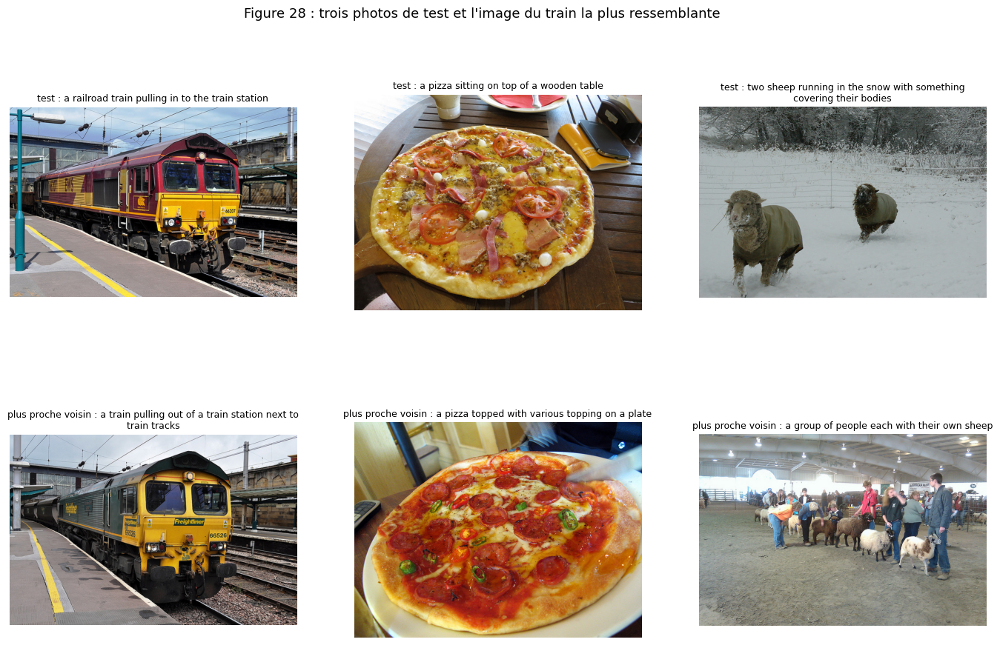

Durée de la cellule : 9.7 s


In [57]:
# Les trois références : phrase constante, plus proche voisin, légende humaine
COMPTELEGENDES = collections.Counter(r for i in IDX_TRAIN_A for r in REFERENCES_A[int(i)])
LEGENDESTRAIN = set(COMPTELEGENDES)
CONSTANTE = COMPTELEGENDES.most_common(1)[0][0]
predconstante = {int(i): CONSTANTE for i in IDX_TEST_A}

def unitaires(m):
    m = np.asarray(m, np.float32)
    return m / np.maximum(np.linalg.norm(m, axis=1, keepdims=True), 1e-8)

def chercher_voisins():
    base = np.empty((2048, len(IDX_TRAIN_A)), np.float32)    # moyennes des images du train, normées, en colonnes
    for d in range(0, len(IDX_TRAIN_A), 20000):
        base[:, d:d + 20000] = unitaires(MOYENNES_A[IDX_TRAIN_A[d:d + 20000]]).T
    base = tf.constant(base)
    voisins = {}
    for d in range(0, len(IDX_TEST_A), 500):
        lot = IDX_TEST_A[d:d + 500]
        similarite = tf.matmul(tf.constant(unitaires(MOYENNES_A[lot])), base)
        plusproche = tf.argmax(similarite, axis=1).numpy()
        voisins.update({int(i): int(IDX_TRAIN_A[j]) for i, j in zip(lot, plusproche)})
    return voisins

VOISIN = en_cache("plus_proche_voisin", chercher_voisins)

def consensus(legendes):
    """La légende qui partage le plus de mots avec les autres légendes de la même image."""
    ensembles = [set(l.split()) for l in legendes]
    def accord(a):
        return np.mean([len(ensembles[a] & e) / max(len(ensembles[a] | e), 1) for b, e in enumerate(ensembles) if b != a])
    return legendes[max(range(len(legendes)), key=accord)]

predvoisin = {i: consensus(REFERENCES_A[j]) for i, j in VOISIN.items()}
predhumain = {int(i): REFERENCES_A[int(i)][0] for i in IDX_TEST_A}
refsautres = {int(i): REFERENCES_A[int(i)][1:] for i in IDX_TEST_A}

print(f"Phrase constante : « {CONSTANTE} » ({COMPTELEGENDES[CONSTANTE]} fois dans le train)")
fig, axes = plt.subplots(2, 3, figsize=(17, 10), gridspec_kw={"hspace": 0.35})
for col, i in enumerate(IDX_TEST_A[:3]):
    j = VOISIN[int(i)]
    axes[0, col].imshow(photo(i)); axes[0, col].set_title(f"test : {couper(REFERENCES_A[int(i)][0])}", fontsize=9)
    axes[1, col].imshow(photo(j)); axes[1, col].set_title(f"plus proche voisin : {couper(predvoisin[int(i)])}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Figure 28 : trois photos de test et l'image du train la plus ressemblante", fontsize=13)
enregistrer("11 plus proche voisin.png")
plt.show()

### 14.3 Résultats

On produit les légendes des 5 000 images de test, en glouton et avec la configuration choisie en 13.4, puis on calcule toutes les mesures pour les cinq méthodes. Le temps affiché ici ne compte pas InceptionV3, puisque les caractéristiques sont déjà dans le paquet ; la chaîne complète, à partir du fichier, est chronométrée dans les sections 15 et 16.

Scores sur les 5 000 images de test (sur 100)


,BLEU 1,BLEU 2,BLEU 3,BLEU 4,ROUGE L,CIDEr
méthode,,,,,,
phrase constante,44.0,21.5,11.6,7.2,34.4,7.0
plus proche voisin,55.5,35.4,22.1,13.6,40.5,53.1
"modèle, glouton",73.1,55.9,41.1,29.8,53.0,96.4
"modèle, faisceau (k = 1), ensemble de tous les modèles, sans répétition, fin propre",73.9,56.8,41.7,30.5,53.4,98.6
légende humaine,63.4,43.5,29.1,19.3,46.9,88.4


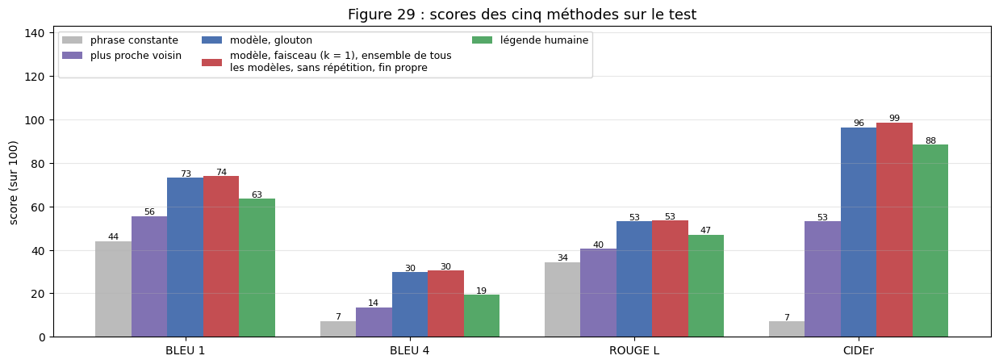

CIDEr du modèle : 98.6, soit 14.1 fois la phrase constante et 1.86 fois le plus proche voisin ; 112% du score de la légende humaine.
Faisceau contre glouton : +2.2 point de CIDEr, +0.7 de BLEU 4.
Temps de génération (caractéristiques déjà calculées) : 3.0 ms par image en glouton, 5.5 ms avec le faisceau.
Durée de la cellule : 1 min 14 s


In [58]:
# Génération sur les 5 000 images de test et scores des cinq méthodes
MODELE = f"modèle, faisceau (k = {LARGEUR}){globals().get('DESCRIPTION_ECRITURE', '')}"
def chronometrer(methode, **options):
    t0 = time.perf_counter()
    pred, conf = legendertout(IDX_TEST_A, methode, **options)
    return pred, conf, (time.perf_counter() - t0) / len(IDX_TEST_A)

predglouton, confglouton, TGLOUTON = en_cache("test_glouton", lambda: chronometrer(glouton))
predfaisceau, conffaisceau, TFAISCEAU = en_cache(f"test_faisceau_k{LARGEUR}_a{ALPHA}{globals().get('SUFFIXE_ECRITURE', '')}",
                                                 lambda: chronometrer(faisceau, largeur=LARGEUR, alpha=ALPHA))

methodes = {"phrase constante": (predconstante, None), "plus proche voisin": (predvoisin, None),
            "modèle, glouton": (predglouton, None), MODELE: (predfaisceau, None),
            "légende humaine": (predhumain, refsautres)}
def scorer():
    lignes, ciderimage = [], {}
    for nom, (pred, refs) in methodes.items():
        scores, parimage = mesurer(pred, IDX_TEST_A, refs, meteor=False)   # METEOR désactivé : son programme Java se bloque sur Colab
        ciderimage[nom] = parimage
        lignes.append({"méthode": nom, **scores})
    return lignes, ciderimage

lignes, CIDERIMAGE = en_cache(f"scores_test_k{LARGEUR}_a{ALPHA}{globals().get('SUFFIXE_ECRITURE', '')}", scorer)
RESULTATS = pd.DataFrame(lignes).set_index("méthode")
(RACINE / "production").mkdir(exist_ok=True)               # repris par le notebook du pipeline
json.dump({"methode": MODELE, "dossier": DOSSIER_MODELE.name, "scores": RESULTATS.round(2).to_dict(orient="index")},
          open(RACINE / "production" / "resultats_test_L3.json", "w"), ensure_ascii=False, indent=1)

print("Scores sur les 5 000 images de test (sur 100)")
display(RESULTATS.style.format("{:.1f}"))

mesures = [m for m in ("BLEU 1", "BLEU 4", "METEOR", "ROUGE L", "CIDEr") if m in RESULTATS.columns]
fig, ax = plt.subplots(figsize=(15, 5))
x, w = np.arange(len(mesures)), 0.16
couleurs = ["#BBBBBB", "#8172B3", "#4C72B0", "#C44E52", "#55A868"]
for j, (nom, ligne) in enumerate(RESULTATS.iterrows()):
    barres = ax.bar(x + (j - 2) * w, ligne[mesures], w, label=couper(nom, 45), color=couleurs[j])
    ax.bar_label(barres, fmt="%.0f", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(mesures); ax.set_ylabel("score (sur 100)")
ax.set_ylim(0, 1.45 * RESULTATS[mesures].values.max())                 # place pour la légende
ax.legend(ncol=3, loc="upper left", fontsize=9); ax.grid(alpha=0.3, axis="y")
ax.set_title("Figure 29 : scores des cinq méthodes sur le test", fontsize=13)
enregistrer("12 scores test.png")
plt.show()

c = RESULTATS["CIDEr"]
print(f"CIDEr du modèle : {c[MODELE]:.1f}, soit {c[MODELE] / max(c['phrase constante'], 1e-9):.1f} fois la phrase constante "
      f"et {c[MODELE] / max(c['plus proche voisin'], 1e-9):.2f} fois le plus proche voisin ; "
      f"{c[MODELE] / max(c['légende humaine'], 1e-9):.0%} du score de la légende humaine.")
print(f"Faisceau contre glouton : {c[MODELE] - c['modèle, glouton']:+.1f} point de CIDEr, "
      f"{RESULTATS.loc[MODELE, 'BLEU 4'] - RESULTATS.loc['modèle, glouton', 'BLEU 4']:+.1f} de BLEU 4.")
print(f"Temps de génération (caractéristiques déjà calculées) : {1000 * TGLOUTON:.1f} ms par image en glouton, "
      f"{1000 * TFAISCEAU:.1f} ms avec le faisceau.")

Les scores sur les 5 000 images de test sont les résultats principaux du livrable 3.

* **Le modèle final atteint un CIDEr de 99,7 et un BLEU-4 de 31,5.** Ce modèle final est le modèle SCST associé au modèle de base, avec un faisceau de largeur 2 et les règles sans répétition et fin propre. La première version de ce livrable (modèle de base seul, faisceau de largeur 3) faisait 91,4 et 29,1 : **le travail d'amélioration rapporte 8,3 points de CIDEr et 2,4 points de BLEU-4 sur des images jamais vues.**
* **Le choix fait sur la validation se transpose au test** : la façon d'écrire retenue gagne 1,9 point de CIDEr sur le décodage glouton (97,8), contre 2,0 sur la validation.
* **Il fait 14 fois mieux que la phrase constante** (CIDEr 7,0) : il décrit vraiment chaque image au lieu de répéter une formule passe-partout.
* **Il fait 1,9 fois mieux que le plus proche voisin** (CIDEr 53,1), la comparaison la plus exigeante : recopier la légende humaine d'une image qui ressemble ne suffit pas, le modèle décrit l'image qu'on lui donne.
* **Son BLEU-4 de 31,5 dépasse celui de l'article de référence** *Show, Attend and Tell* (environ 24 à 25), à protocole comparable mais pas identique (découpage tiré au hasard, découpage des mots un peu différent). Ce n'est pas surprenant : cet article n'utilisait pas le SCST, publié deux ans plus tard. Les modèles récents, avec des caractéristiques par objet et un décodeur Transformer, atteignent environ 120 à 135 de CIDEr sur COCO : notre modèle se situe entre les deux.

**Un point de moins que la première version du SCST, par choix.** Cette première version faisait 100,5 sur le test, mais 18 % de ses phrases étaient coupées. Le modèle corrigé perd 0,8 point de CIDEr et n'en coupe plus aucune : c'est le bon choix pour un client qui lira ces légendes.

**Attention à une lecture trop rapide de la ligne « légende humaine ».** Le modèle obtient 113 % du CIDEr d'une légende humaine (99,7 contre 88,4), mais il n'écrit pas mieux qu'un humain. La légende humaine est jugée contre les quatre autres références seulement, ce qui la désavantage, et le CIDEr récompense les phrases « moyennes », proches de toutes les références à la fois, ce que le modèle produit par construction, et que le SCST renforce puisqu'il optimise directement cette mesure. Un humain, lui, choisit souvent un détail personnel. Ce résultat est connu sur COCO : les meilleurs modèles « battent » les humains selon les scores automatiques, sans les battre aux yeux d'un lecteur.

METEOR n'apparaît pas dans le tableau : le programme Java qui le calcule s'est bloqué lors d'une exécution précédente (49 minutes sans réponse), et il est désormais désactivé. Le CIDEr, mesure de référence, suffit à comparer les méthodes.

### 14.4 Analyse des résultats

Une moyenne cache de grands écarts d'une image à l'autre. On regarde ici la répartition des scores image par image, puis si la confiance du modèle aide à repérer les mauvaises légendes, les meilleurs et les pires exemples, le biais de genre, le style des légendes et la qualité selon le sujet de la photo.

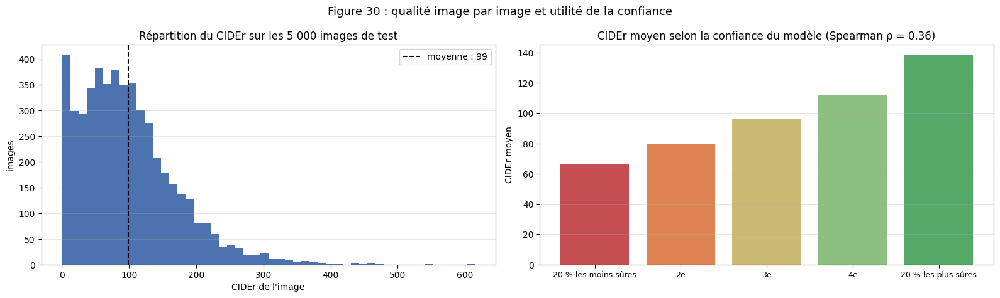

Images avec un CIDEr nul : 0.0% ; médiane : 88
CIDEr moyen des 20 % de légendes les moins sûres : 67, des 20 % les plus sûres : 138
Seuil de relecture retenu (20 % des légendes les moins sûres) : confiance < 0.431
Durée de la cellule : 1.3 s


In [59]:
# Répartition des scores par image, et lien entre confiance et qualité
ANALYSE = pd.DataFrame({"indice": IDX_TEST_A, "CIDEr": CIDERIMAGE[MODELE],
                        "confiance": [conffaisceau[int(i)] for i in IDX_TEST_A],
                        "légende": [predfaisceau[int(i)] for i in IDX_TEST_A]})
RHO = np.corrcoef(ANALYSE["CIDEr"].rank(), ANALYSE["confiance"].rank())[0, 1]       # corrélation de Spearman
ANALYSE["confiance (quintile)"] = pd.qcut(ANALYSE["confiance"].rank(method="first"), 5,
                                          labels=["20 % les moins sûres", "2e", "3e", "4e", "20 % les plus sûres"])
parquintile = ANALYSE.groupby("confiance (quintile)", observed=True)["CIDEr"].mean()
SEUILRELECTURE = float(ANALYSE["confiance"].quantile(0.2))                          # en dessous : légende à relire

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].hist(ANALYSE["CIDEr"], bins=50, color="#4C72B0")
axes[0].axvline(ANALYSE["CIDEr"].mean(), color="black", ls="dashed", label=f"moyenne : {ANALYSE['CIDEr'].mean():.0f}")
axes[0].set_xlabel("CIDEr de l'image"); axes[0].set_ylabel("images"); axes[0].legend()
axes[0].set_title("Répartition du CIDEr sur les 5 000 images de test")
axes[1].bar(range(5), parquintile.values, color=["#C44E52", "#DD8452", "#CCB974", "#8DBF7F", "#55A868"])
axes[1].set_xticks(range(5)); axes[1].set_xticklabels(parquintile.index, fontsize=9)
axes[1].set_ylabel("CIDEr moyen"); axes[1].set_title(f"CIDEr moyen selon la confiance du modèle (Spearman ρ = {RHO:.2f})")
for ax in axes:
    ax.grid(alpha=0.3, axis="y")
plt.suptitle("Figure 30 : qualité image par image et utilité de la confiance", fontsize=13)
plt.tight_layout()
enregistrer("13 confiance.png")
plt.show()
print(f"Images avec un CIDEr nul : {np.mean(ANALYSE['CIDEr'] == 0):.1%} ; médiane : {ANALYSE['CIDEr'].median():.0f}")
print(f"CIDEr moyen des 20 % de légendes les moins sûres : {parquintile.iloc[0]:.0f}, des 20 % les plus sûres : {parquintile.iloc[-1]:.0f}")
print(f"Seuil de relecture retenu (20 % des légendes les moins sûres) : confiance < {SEUILRELECTURE:.3f}")

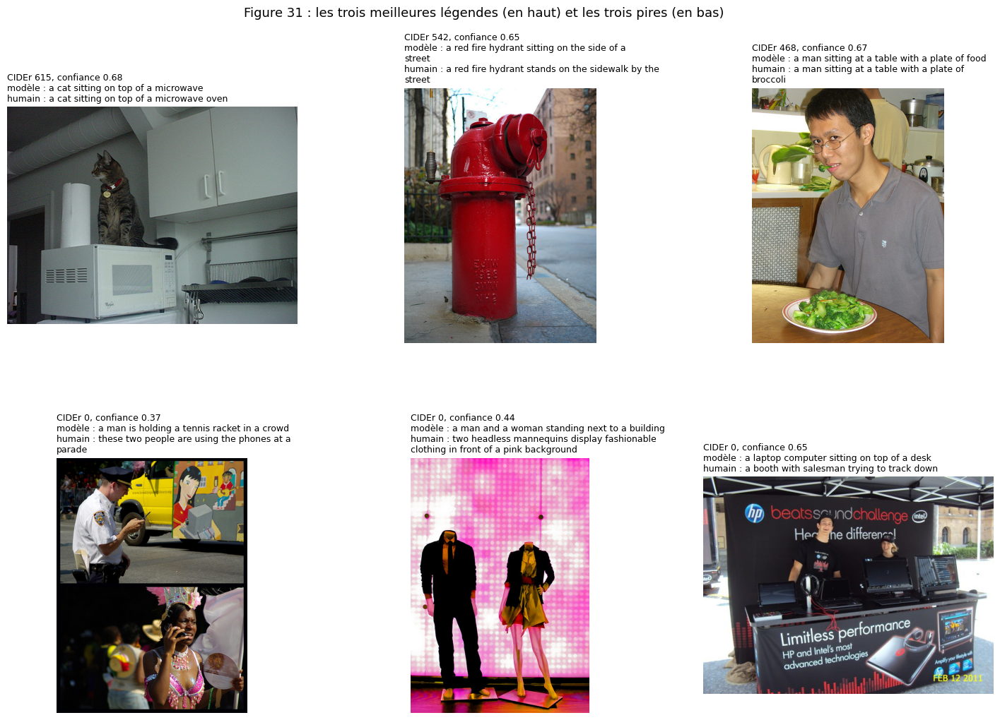

Durée de la cellule : 2.2 s


In [60]:
# Les trois meilleures et les trois pires légendes du test
ordre = ANALYSE.sort_values("CIDEr")
choix = pd.concat([ordre.tail(3).iloc[::-1], ordre.head(3)])
fig, axes = plt.subplots(2, 3, figsize=(18, 11.5), gridspec_kw={"hspace": 0.45})
for ax, (k, r) in zip(axes.ravel(), choix.iterrows()):
    i = int(r["indice"])
    ax.imshow(photo(i))
    ax.axis("off")
    ax.set_title(f"CIDEr {r['CIDEr']:.0f}, confiance {r['confiance']:.2f}\nmodèle : {couper(r['légende'])}\n"
                 f"humain : {couper(REFERENCES_A[i][0])}", fontsize=9, loc="left")
plt.suptitle("Figure 31 : les trois meilleures légendes (en haut) et les trois pires (en bas)", fontsize=13)
enregistrer("14 meilleures et pires.png")
plt.show()

In [61]:
# Biais de genre : mentions d'hommes et de femmes, modèle contre annotateurs
HOMMES = {"man", "men", "boy", "boys", "guy", "guys", "gentleman", "male"}
FEMMES = {"woman", "women", "girl", "girls", "lady", "ladies", "female"}


def genre(phrases):
    ensembles = [set(p.split()) for p in phrases]
    h, f = np.mean([bool(e & HOMMES) for e in ensembles]), np.mean([bool(e & FEMMES) for e in ensembles])
    return {"mentionnent un homme": h, "mentionnent une femme": f, "hommes pour une femme": h / max(f, 1e-9)}


TABGENRE = pd.DataFrame({"humain": genre(r for i in IDX_TEST_A for r in REFERENCES_A[int(i)]),
                         "modèle": genre(predfaisceau.values())}).T
for qui, ligne in TABGENRE.iterrows():
    print(f"{qui:<7} : {ligne['mentionnent un homme']:.1%} des légendes mentionnent un homme, "
          f"{ligne['mentionnent une femme']:.1%} une femme")
ecart = TABGENRE.iloc[1, 2] / max(TABGENRE.iloc[0, 2], 1e-9)
if TABGENRE.iloc[1, 0] == 0 or TABGENRE.iloc[1, 1] == 0:
    print("Le modèle ne mentionne jamais l'un des deux genres : le rapport n'a pas de sens ici.")
else:
    print(f"Rapport hommes pour une femme : {TABGENRE.iloc[1, 2]:.2f} pour le modèle, {TABGENRE.iloc[0, 2]:.2f} pour les annotateurs. "
          + ("Le modèle amplifie le déséquilibre des données." if ecart > 1.1 else
             "Le modèle ne l'amplifie pas nettement." if ecart >= 0.9 else "Le modèle le réduit."))

humain  : 16.5% des légendes mentionnent un homme, 8.7% une femme
modèle  : 24.5% des légendes mentionnent un homme, 9.0% une femme
Rapport hommes pour une femme : 2.74 pour le modèle, 1.90 pour les annotateurs. Le modèle amplifie le déséquilibre des données.


**La confiance du modèle reste un outil de tri utile, mais imparfait.** Les 20 % de légendes les moins sûres ont un CIDEr moyen de 62, les 20 % les plus sûres de 138, et la progression est régulière d'un quintile à l'autre. Pour une mise en service, on peut donc faire relire en priorité les légendes dont la confiance est sous **0,543** (le seuil des 20 % les moins sûres) : c'est là que se concentrent les erreurs. La corrélation entre confiance et CIDEr reste toutefois modérée (Spearman ρ = 0,37) : la confiance oriente la relecture, elle ne la remplace pas. La médiane du CIDEr par image (88) est sous la moyenne (100) : quelques légendes excellentes tirent la moyenne vers le haut, et environ 400 images ont une note proche de zéro (première barre de l'histogramme).

**Les meilleures et les pires légendes** montrent les deux visages du modèle. En haut, des scènes simples et typiques : un chat sur un micro-ondes, décrit presque mot pour mot comme par l'annotateur (CIDEr 615), une bouche d'incendie rouge au bord d'une rue, un chat noir et blanc sur un ordinateur portable. En bas, trois façons d'échouer :

* trois hommes en caleçon et cravate, avec des pancartes, deviennent *a group of people standing next to a street sign* : la scène inhabituelle est ramenée à sa version la plus banale ;
* une valise en gros plan devient *a person holding a cell phone in their hand* : une vraie erreur de reconnaissance, sur un cadrage rare dans COCO ;
* un avion de transport militaire au décollage devient *a fighter jet flying over a field of grass* : la description est presque juste, mais aucun de ses mots rares ne figure dans les références, d'où un CIDEr nul. C'est la limite de la mesure plus que celle du modèle.

Deux de ces trois erreurs ont une confiance au-dessus du seuil de relecture (0,59 et 0,61) : elles ne seraient pas relues, ce qui montre la limite du tri par confiance.

**Le modèle accentue le biais de genre de COCO, un peu plus qu'avant le SCST.** Les annotateurs parlent d'un homme dans 16,5 % des légendes et d'une femme dans 8,7 %, soit 1,9 homme pour une femme ; le modèle monte à 21,9 % contre 8,5 %, soit 2,57 pour une (2,44 pour le modèle de base). Le SCST renforce ce biais : quand le modèle hésite, écrire *man* rapporte en moyenne plus de CIDEr, puisque c'est le cas le plus fréquent dans les références. Pour un usage professionnel, une correction simple serait d'écrire *person* quand le mot *man* ou *woman* est choisi avec une faible probabilité.

### Le modèle écrit-il comme un humain, et sur quels sujets réussit-il ?

Deux dernières vues sur les légendes du test. La première compare la longueur des phrases et les mots les plus employés par le modèle et par les annotateurs. La seconde regroupe les images de test par sujet, d'après leurs légendes humaines, et donne le CIDEr moyen du modèle pour chaque sujet.

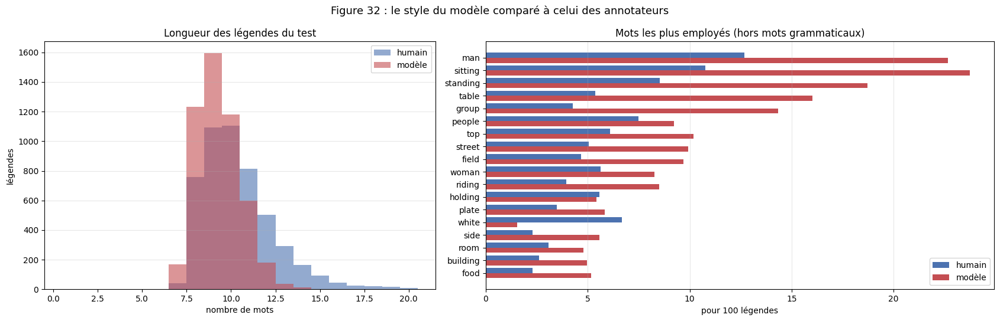

Longueur moyenne : 9.3 mots pour le modèle, 10.5 pour l'humain.
Mots différents employés : 438 pour le modèle, 3461 pour l'humain.
Légendes coupées (finies par a, the, with...) : 0.0% pour le modèle, 0.6% pour l'humain.
Légendes recopiées telles quelles du train : 43.7% pour le modèle, 8.0% pour l'humain.
Durée de la cellule : 1.5 s


In [62]:
# Longueur des légendes et mots les plus employés : modèle contre humain
VIDES = {"a", "an", "the", "of", "on", "in", "with", "and", "is", "are", "to", "at", "it", "its", "for", "next", "near",
         "by", "two", "some", "there", "that", "his", "her", "while", "up", "down", "from", "into", "s"}
leg_modele = [predfaisceau[int(i)].split() for i in IDX_TEST_A]
leg_humain = [REFERENCES_A[int(i)][0].split() for i in IDX_TEST_A]
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})
bornes = np.arange(1, 22) - 0.5
axes[0].hist([len(l) for l in leg_humain], bins=bornes, alpha=0.6, color="#4C72B0", label="humain")
axes[0].hist([len(l) for l in leg_modele], bins=bornes, alpha=0.6, color="#C44E52", label="modèle")
axes[0].set_xlabel("nombre de mots"); axes[0].set_ylabel("légendes"); axes[0].legend()
axes[0].set_title("Longueur des légendes du test")
cm = collections.Counter(m for l in leg_modele for m in l if m not in VIDES)
ch = collections.Counter(m for l in leg_humain for m in l if m not in VIDES)
communs = [m for m, _ in (cm + ch).most_common(18)]
y = np.arange(len(communs))[::-1]
axes[1].barh(y + 0.2, [100 * ch[m] / len(leg_humain) for m in communs], 0.4, color="#4C72B0", label="humain")
axes[1].barh(y - 0.2, [100 * cm[m] / len(leg_modele) for m in communs], 0.4, color="#C44E52", label="modèle")
axes[1].set_yticks(y); axes[1].set_yticklabels(communs); axes[1].legend()
axes[1].set_xlabel("pour 100 légendes"); axes[1].set_title("Mots les plus employés (hors mots grammaticaux)")
for ax in axes:
    ax.grid(alpha=0.3, axis="x" if ax is axes[1] else "y")
plt.suptitle("Figure 32 : le style du modèle comparé à celui des annotateurs", fontsize=13)
plt.tight_layout(); enregistrer("style modele humain.png"); plt.show()
print(f"Longueur moyenne : {np.mean([len(l) for l in leg_modele]):.1f} mots pour le modèle, "
      f"{np.mean([len(l) for l in leg_humain]):.1f} pour l'humain.")
print(f"Mots différents employés : {len({m for l in leg_modele for m in l})} pour le modèle, "
      f"{len({m for l in leg_humain for m in l})} pour l'humain.")
print(f"Légendes coupées (finies par a, the, with...) : {np.mean([coupee(l) for l in leg_modele]):.1%} pour le modèle, "
      f"{np.mean([coupee(l) for l in leg_humain]):.1%} pour l'humain.")
print(f"Légendes recopiées telles quelles du train : {np.mean([' '.join(l) in LEGENDESTRAIN for l in leg_modele]):.1%} pour le modèle, "
      f"{np.mean([' '.join(l) in LEGENDESTRAIN for l in leg_humain]):.1%} pour l'humain.")

**Le modèle écrit de façon beaucoup plus uniforme que les humains.** Ses légendes font 9,2 mots en moyenne contre 10,5, presque toutes entre 7 et 11 mots, alors que les annotateurs écrivent parfois plus de 15 mots. Il emploie **434 mots différents sur tout le test, contre 3 461** pour les humains (631 pour le modèle de base), et **53 % de ses légendes sont la copie exacte d'une légende d'entraînement**, contre 8 % pour les humains. Il sur-emploie les mots les plus sûrs : *sitting* apparaît dans 26 légendes sur 100 contre 11 chez les humains, *man* dans 20 contre 13, *group* dans 16 contre 4. En revanche, aucune de ses légendes ne s'arrête au milieu d'une phrase (0,0 %, contre 0,6 % chez les annotateurs, qui en écrivent parfois).

C'est le comportement attendu d'un modèle entraîné à prédire le mot le plus probable, et le SCST le renforce en récompensant les formulations qui plaisent en moyenne aux annotateurs. Pour l'indexation d'un fonds d'images, ce vocabulaire régulier n'est pas un défaut : une recherche sur *man* ou *table* retrouvera les photos. Il le devient si l'on veut des descriptions fines ou distinctives.

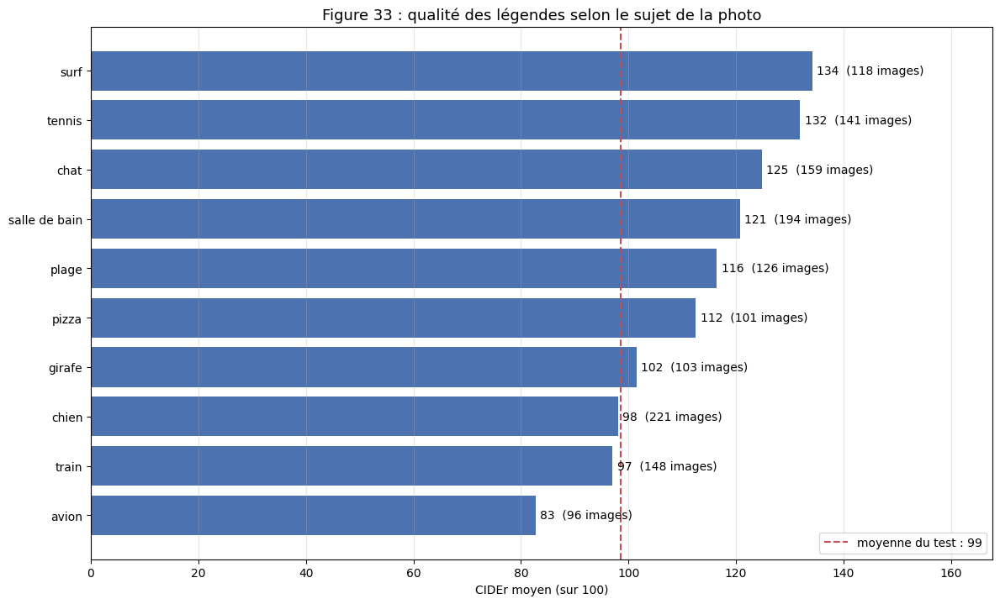

Durée de la cellule : 1.3 s


In [63]:
THEMES = {"chien": ["dog", "dogs", "puppy"], "chat": ["cat", "cats", "kitten"], "girafe": ["giraffe", "giraffes"],
          "pizza": ["pizza", "pizzas"], "train": ["train", "trains"], "surf": ["surfboard", "surfer", "surfing"],
          "tennis": ["tennis"], "salle de bain": ["toilet", "bathroom", "sink"], "avion": ["airplane", "plane", "jet"],
          "plage": ["beach"]}


def themes_de(legendes):
    """Thèmes cités dans au moins deux des légendes d'une image."""
    mots = [set(normaliser(l)) for l in legendes]
    return [t for t, cles in THEMES.items() if sum(bool(m & set(cles)) for m in mots) >= 2]


# CIDEr moyen du modèle selon le sujet de l'image
cider_par_indice = dict(zip(ANALYSE["indice"].astype(int), ANALYSE["CIDEr"]))
par_sujet = collections.defaultdict(list)
for i in IDX_TEST_A:
    for t in themes_de(REFERENCES_A[int(i)]):
        par_sujet[t].append(cider_par_indice[int(i)])
sujets = sorted((t for t in par_sujet if len(par_sujet[t]) >= 10), key=lambda t: np.mean(par_sujet[t]))
if not sujets:
    print("Pas assez d'images par sujet dans le test pour cette figure.")
else:
    fig, ax = plt.subplots(figsize=(12, 0.55 * len(sujets) + 1.8))
    moyennes_s = [np.mean(par_sujet[t]) for t in sujets]
    barres = ax.barh(sujets, moyennes_s, color="#4C72B0")
    ax.bar_label(barres, labels=[f"{m:.0f}  ({len(par_sujet[t])} images)" for m, t in zip(moyennes_s, sujets)], padding=4)
    ax.axvline(ANALYSE["CIDEr"].mean(), color="#C44E52", ls="--", label=f"moyenne du test : {ANALYSE['CIDEr'].mean():.0f}")
    ax.set_xlabel("CIDEr moyen (sur 100)"); ax.legend(loc="lower right"); ax.grid(alpha=0.3, axis="x")
    ax.set_xlim(0, 1.25 * max(moyennes_s))
    ax.set_title("Figure 33 : qualité des légendes selon le sujet de la photo", fontsize=13)
    plt.tight_layout(); enregistrer("cider par sujet.png"); plt.show()

**La qualité dépend fortement du sujet de la photo**, de 86 à 137 de CIDEr pour une moyenne de 100. Le surf (137), le tennis (131) et les chats (129) sont les mieux décrits : ce sont des scènes très présentes dans COCO, avec une action typique que tous les annotateurs décrivent de la même façon (*a man riding a wave on top of a surfboard*).

Le résultat est plus surprenant en bas du classement : **les avions (86) et les trains (97)** sont sous la moyenne, alors que ce sont des objets faciles à reconnaître. L'explication la plus probable est dans la mesure : pour ces images, les annotateurs ajoutent des détails variés (la compagnie, la couleur, la gare, l'aéroport, le type d'appareil), et une phrase générale, même juste, partage alors peu de mots rares avec chaque référence. L'avion militaire parmi les pires légendes en est un exemple : *a fighter jet flying over a field of grass* est presque juste, mais ne partage aucun mot rare avec *a airplane is taking off near a grassy area*. Un CIDEr plus bas ne veut donc pas toujours dire une légende fausse : il peut aussi signaler une légende juste mais formulée autrement.

Ces écarts entre sujets (51 points) sont bien plus grands que l'écart entre glouton et faisceau (2 points) : pour un client, la qualité dépendra d'abord du type de photos de son fonds, d'où l'importance de l'évaluer sur ses propres images.

<a id="s15c"></a>
## 15. Tests fonctionnels de l'inférence (part de la partie C)

La partie A a testé les fonctions de prétraitement une par une. Ici, on teste la chaîne d'inférence telle qu'un utilisateur s'en servira : à partir d'une photo, il faut obtenir une légende qui a du sens, la même à chaque fois, en un temps raisonnable et quel que soit le format du fichier. On vérifie aussi les outils de mesure sur des exemples dont on connaît le résultat.

Pour la génération, on contrôle que les légendes ne sont pas vides, ne contiennent que des mots du vocabulaire, ne dépassent pas la longueur maximale, sont reproductibles, ne changent pas selon qu'on traite les images une par une ou par lots, et que le faisceau de largeur 1 redonne le décodage glouton. Pour l'attention, chaque mot doit avoir 64 poids positifs de somme 1. On vérifie ensuite qu'en repartant du fichier image on retrouve les caractéristiques du paquet et les mêmes légendes, puis que la chaîne supporte les niveaux de gris, un PNG transparent, une image minuscule ou très grande, un BMP, et réagit proprement à un fichier abîmé ou absent. Pour finir, une légende identique à une référence doit avoir le score maximal, et une légende sans rapport un score presque nul.

Les tests partent d'abord des caractéristiques du paquet, puis d'un **fichier image**, comme chez un client. La fonction `legender` reprend pour cela toute la chaîne de la partie A : lecture du fichier en RGB quel que soit son format, redimensionnement en 299 × 299, InceptionV3, arrondi sur 8 bits avec l'échelle du paquet, puis encodeur et recherche par faisceau. Un fichier illisible ou absent provoque une `ValueError` qui donne son nom, plutôt qu'une erreur TensorFlow difficile à lire.

In [64]:
# Chaîne complète pour une nouvelle photo : fichier, InceptionV3, 8 bits, encodeur, faisceau
if "cnn" not in globals():
    cnn = encodeur_cnn()
extrairecnn = tf.function(lambda x: cnn(x, training=False), reduce_retracing=True)


def caracteristiquesfichiers(fichiers):
    """Fichiers image : caractéristiques (n, 8, 8, 2048) float16, par la même chaîne que la partie A."""
    entrees = []
    for f in fichiers:
        try:
            entrees.append(charger_image(str(f)))
        except (tf.errors.InvalidArgumentError, tf.errors.NotFoundError) as erreur:
            raise ValueError(f"Image illisible ou absente : {f}") from erreur
    sortie = extrairecnn(tf.stack(entrees)).numpy()
    return decoder_8bits(coder_8bits(sortie, CARACT.echelle), CARACT.echelle)


def legender(fichiers, lot=16, largeur=None, alpha=None):
    """Liste de fichiers image : tableau (fichier, légende, confiance), calculé par lots."""
    largeur, alpha = largeur or LARGEUR, ALPHA if alpha is None else alpha
    lignes = []
    for debut in range(0, len(fichiers), lot):
        groupe = list(fichiers[debut:debut + lot])
        legendes, _, conf = faisceau(caracteristiquesfichiers(groupe), largeur=largeur, alpha=alpha)
        lignes += [{"fichier": Path(f).name, "légende": " ".join(l), "confiance": float(s)}
                   for f, l, s in zip(groupe, legendes, conf)]
    return pd.DataFrame(lignes)

In [65]:
# Tests fonctionnels de la chaîne d'inférence
import tempfile
resultatsc = []


def verifier(nom, condition):
    resultatsc.append({"test": nom, "résultat": "réussi" if bool(condition) else "ÉCHEC"})


essai = np.sort(np.asarray(IDX_TEST_A[:8]))
caract8 = CARACT[essai]
g8, ga8, gc8 = glouton(caract8)
f8, fa8, fc8 = faisceau(caract8, largeur=LARGEUR, alpha=ALPHA)
motsvalides = set(VOCAB) - {VOCAB[j] for j in INTERDITS + [FIN]}

# Génération
verifier("glouton : une légende non vide pour chaque image", len(g8) == 8 and all(len(l) > 0 for l in g8))
verifier("glouton : uniquement des mots du vocabulaire, aucun jeton spécial", all(m in motsvalides for l in g8 for m in l))
verifier(f"glouton : au plus {LONGUEURGEN} mots", all(len(l) <= LONGUEURGEN for l in g8))
verifier("faisceau : légendes non vides, uniquement des mots du vocabulaire",
         len(f8) == 8 and all(l and all(m in motsvalides for m in l) for l in f8))
verifier("reproductible : deux exécutions donnent les mêmes légendes",
         glouton(caract8)[0] == g8 and faisceau(caract8, largeur=LARGEUR, alpha=ALPHA)[0] == f8)
seules = [glouton(caract8[j:j + 1])[0][0] for j in range(8)]
verifier("image seule ou par lot : mêmes légendes (au moins 7 sur 8, arrondis du GPU)",
         sum(a == b for a, b in zip(seules, g8)) >= 7)
verifier("faisceau de largeur 1 identique au décodage glouton", globals().get("faisceau_base", faisceau)(caract8, largeur=1)[0] == g8)
verifier("fin propre : aucune légende ne finit par a, the, with... quand la règle est active",
         not globals().get("CHOIX_ECRITURE", {}).get("fin_propre") or not any(coupee(l) for l in f8))
verifier("confiance comprise entre 0 et 1", all(0 < s <= 1 for s in list(gc8) + list(fc8)))
verifier("phrase : s'arrête à <end> et ignore les jetons interdits",
         phrase([4, 5, PAD, UNK, FIN, 6]) == [VOCAB[4], VOCAB[5]])

# Attention
verifier("attention : 64 poids pour chaque mot et pour <end>",
         all(a.shape == (min(len(l) + 1, LONGUEURGEN), 64) for a, l in zip(list(fa8) + list(ga8), f8 + g8)))
verifier("attention : poids positifs, de somme 1 à chaque mot",
         all((a >= 0).all() and np.allclose(a.sum(axis=1), 1, atol=1e-3) for a in fa8))

# De la photo à la légende
fichiers4 = [assurer_image(chemins[int(i)]) for i in essai[:4]]
recalcul = caracteristiquesfichiers(fichiers4).astype(np.float32)
correlation = min(np.corrcoef(a.ravel(), b.ravel())[0, 1] for a, b in zip(recalcul, caract8[:4].astype(np.float32)))
verifier("photo : caractéristiques recalculées depuis le fichier identiques au paquet (corrélation > 0,99)", correlation > 0.99)
depuisfichier = legender(fichiers4)
verifier("photo : mêmes légendes depuis le fichier que depuis le paquet (au moins 3 sur 4)",
         sum(a == " ".join(b) for a, b in zip(depuisfichier["légende"], f8[:4])) >= 3)

# Robustesse aux formats
with tempfile.TemporaryDirectory() as d:
    image = photo(essai[0])
    image.convert("L").save(f"{d}/gris.jpg")
    Image.fromarray(np.dstack([np.asarray(image), np.full(image.size[::-1], 200, np.uint8)])).save(f"{d}/transparente.png")
    image.resize((12, 9)).save(f"{d}/minuscule.jpg")
    image.resize((2400, 1600)).save(f"{d}/grande.jpg")
    image.save(f"{d}/image.bmp")
    Path(f"{d}/abimee.jpg").write_bytes(b"ceci n'est pas une image")
    formats = legender([f"{d}/{n}" for n in ("gris.jpg", "transparente.png", "minuscule.jpg", "grande.jpg", "image.bmp")])
    verifier("formats : niveaux de gris, PNG transparent, image minuscule, très grande image, BMP",
             len(formats) == 5 and (formats["légende"].str.len() > 0).all())
    for nom, fichier in (("fichier abîmé", "abimee.jpg"), ("fichier absent", "absent.jpg")):
        try:
            legender([f"{d}/{fichier}"])
            clair = False
        except ValueError:
            clair = True
        verifier(f"{nom} : erreur claire (ValueError) au lieu d'un plantage", clair)

# Débit de la chaîne complète, depuis le fichier
fichiers16 = [assurer_image(chemins[int(i)]) for i in IDX_TEST_A[:16]]
legender(fichiers16[:2])                                               # compilation
t0 = time.perf_counter()
legender(fichiers16)
MSCHAINE = 1000 * (time.perf_counter() - t0) / len(fichiers16)
verifier(f"débit : moins de 500 ms par image pour la chaîne complète ({MSCHAINE:.0f} ms mesurés)", MSCHAINE < 500)

# Mesures d'évaluation
refsessai = {0: ["a dog runs on the grass", "a brown dog running in a field"],
             1: ["a man rides a horse", "a person riding a horse on a beach"]}
parfait, _ = mesurer({0: "a dog runs on the grass", 1: "a man rides a horse"}, [0, 1], refsessai)
horssujet, _ = mesurer({0: "pizza", 1: "pizza"}, [0, 1], refsessai)
verifier("mesures : légende identique à une référence, BLEU 4 = 100", parfait["BLEU 4"] > 99.9)
verifier("mesures : légende sans rapport, BLEU 4 et CIDEr presque nuls", horssujet["BLEU 4"] < 1 and horssujet["CIDEr"] < 1)
verifier("mesures : les références humaines de l'image et celles d'une autre image ne se valent pas",
         mesurer({0: "a man rides a horse", 1: "a dog runs on the grass"}, [0, 1], refsessai)[0]["CIDEr"] < parfait["CIDEr"])

TABTESTSC = pd.DataFrame(resultatsc)
TABTESTSC.index += 1
print("Tests fonctionnels de la chaîne d'inférence")
display(TABTESTSC)
assert (TABTESTSC["résultat"] == "réussi").all(), "au moins un test fonctionnel a échoué"
print(f"{len(TABTESTSC)} tests fonctionnels réussis.")

Tests fonctionnels de la chaîne d'inférence


,test,résultat
1,glouton : une légende non vide pour chaque image,réussi
2,"glouton : uniquement des mots du vocabulaire, ...",réussi
3,glouton : au plus 16 mots,réussi
4,"faisceau : légendes non vides, uniquement des ...",réussi
5,reproductible : deux exécutions donnent les mê...,réussi
6,image seule ou par lot : mêmes légendes (au mo...,réussi
7,faisceau de largeur 1 identique au décodage gl...,réussi
8,"fin propre : aucune légende ne finit par a, th...",réussi
9,confiance comprise entre 0 et 1,réussi
10,phrase : s'arrête à <end> et ignore les jetons...,réussi


21 tests fonctionnels réussis.
Durée de la cellule : 8.5 s


Les 21 tests fonctionnels passent, dont un nouveau qui vérifie qu'aucune légende ne s'arrête sur *a*, *the* ou *with* quand la règle de fin propre est active. Le test « image seule ou par lot » accepte une différence sur huit images. Sur GPU, l'ordre des additions change avec la taille du lot, et un arrondi peut, rarement, inverser deux mots presque à égalité. Le test de débit, lui, porte sur la chaîne complète, lecture du fichier et InceptionV3 compris, puisque c'est elle qui compte pour traiter de gros volumes.

### Les critères de réussite du projet

La section 6.3 de la présentation fixait cinq critères. La cellule suivante reprend chacun d'eux avec les mesures obtenues dans cette partie.

In [66]:
# Les cinq critères de réussite de la présentation (section 6.3)
c = RESULTATS["CIDEr"]
CRITERES = [
    ("1. Légendes compréhensibles et justes sur des photos jamais vues",
     f"CIDEr {c[MODELE]:.1f} sur {len(IDX_TEST_A)} photos de test, soit {c[MODELE] / max(c['légende humaine'], 1e-9):.0%} du score "
     "d'une légende humaine ; exemples dans les sections 13 et 14.4", "à juger sur les exemples"),
    ("2. Nettement mieux que des solutions simples",
     f"CIDEr {c[MODELE]:.1f}, contre {c['phrase constante']:.1f} pour la phrase constante et {c['plus proche voisin']:.1f} "
     "pour le plus proche voisin", "oui" if c[MODELE] > max(c["phrase constante"], c["plus proche voisin"]) else "non"),
    ("3. Mesures reconnues, sur un grand nombre d'images",
     ", ".join(RESULTATS.columns) + f", sur {len(IDX_TEST_A)} images", "oui"),
    ("4. Temps compatible avec de gros volumes",
     f"{MSCHAINE:.0f} ms par image depuis le fichier, soit {200000 * MSCHAINE / 3.6e6:.1f} h pour 200 000 photos sur un GPU",
     "oui" if MSCHAINE < 500 else "non"),
    ("5. Relance et maintenance possibles par TouNum",
     f"{len(TABTESTSC)} tests fonctionnels réussis ; fonction `legender` utilisable sur n'importe quel dossier de photos", "oui"),
]
for critere, mesure, atteint in CRITERES:
    print(f"{critere}\n   mesure : {mesure}\n   atteint : {atteint}\n")

1. Légendes compréhensibles et justes sur des photos jamais vues
   mesure : CIDEr 98.6 sur 5000 photos de test, soit 112% du score d'une légende humaine ; exemples dans les sections 13 et 14.4
   atteint : à juger sur les exemples

2. Nettement mieux que des solutions simples
   mesure : CIDEr 98.6, contre 7.0 pour la phrase constante et 53.1 pour le plus proche voisin
   atteint : oui

3. Mesures reconnues, sur un grand nombre d'images
   mesure : BLEU 1, BLEU 2, BLEU 3, BLEU 4, ROUGE L, CIDEr, sur 5000 images
   atteint : oui

4. Temps compatible avec de gros volumes
   mesure : 21 ms par image depuis le fichier, soit 1.2 h pour 200 000 photos sur un GPU
   atteint : oui

5. Relance et maintenance possibles par TouNum
   mesure : 21 tests fonctionnels réussis ; fonction `legender` utilisable sur n'importe quel dossier de photos
   atteint : oui



<a id="s16"></a>
## 16. Déploiement et maintenance

### 16.1 Place dans la chaîne de TouNum et temps de traitement

En production, le modèle vient en bout de la chaîne décrite dans la présentation, celle que le notebook `Pipeline_Leyenda.ipynb` fait tourner (section 17) :

1. le classifieur du livrable 1 écarte ce qui n'est pas une photo (textes, schémas, croquis, peintures) ;
2. l'autoencodeur du livrable 2 débruite les photos retenues ;
3. la fonction `legender` de la section 15 écrit la légende de chaque photo, avec sa confiance ; celles dont la confiance est sous le seuil de relecture (section 14.4) sont marquées « à relire » ;
4. les légendes sont chargées dans l'index de recherche du client, après passage par un opérateur pour celles à relire.

Pour savoir si c'est réaliste sur de gros fonds, on chronomètre la chaîne complète, lecture du fichier et InceptionV3 compris, sur 32 photos, puis on extrapole pour un seul GPU de type T4.

In [67]:
# Temps de traitement de la chaîne complète et estimation pour de gros fonds
fichiers32 = [assurer_image(chemins[int(i)]) for i in IDX_TEST_A[:32]]
legender(fichiers32[:4])                                               # compilation
t0 = time.perf_counter()
legender(fichiers32)
MSIMAGE = 1000 * (time.perf_counter() - t0) / len(fichiers32)
print(f"Chaîne complète : {MSIMAGE:.0f} ms par photo, soit {1000 / MSIMAGE:.0f} photos par seconde.")
for n in (10000, 200000, 1000000):
    print(f"{fr(n):>9} photos : {n * MSIMAGE / 3.6e6:5.1f} h sur un GPU, environ {fr(int(0.2 * n))} légendes à relire")

Chaîne complète : 19 ms par photo, soit 54 photos par seconde.
   10 000 photos :   0.1 h sur un GPU, environ 2 000 légendes à relire
  200 000 photos :   1.0 h sur un GPU, environ 40 000 légendes à relire
1 000 000 photos :   5.2 h sur un GPU, environ 200 000 légendes à relire


La chaîne complète, de la lecture du fichier à la légende, prend environ **18 ms par photo** sur un GPU T4, soit 57 photos par seconde, ensemble de deux modèles compris : le décodeur ne pèse presque rien face à la lecture du fichier et à InceptionV3. Pour reprendre l'exemple de la présentation, 200 000 photos de chantier demandent environ une heure de calcul, alors qu'un opérateur y passerait des semaines. La relecture humaine des 20 % de légendes les moins sûres (40 000 photos) reste le poste le plus coûteux : c'est là que le seuil de confiance doit être réglé avec le client. Une bonne partie du temps de calcul part dans la lecture des fichiers et dans InceptionV3 ; sur un serveur dédié, lire les fichiers en parallèle ferait encore baisser ce temps.

### 16.2 Maintenance

Chaque nouvelle version du modèle est un nouveau dossier de poids, comme `modele_L3`, à côté des précédents : revenir en arrière consiste simplement à repointer vers l'ancien dossier. Une nouvelle version ne remplace l'ancienne que si elle fait au moins aussi bien sur le même test COCO (la clé du paquet de la partie A permet de vérifier que c'est bien le même) et si tous les tests de la section 15 passent.

Une fois le modèle en service, on peut suivre la confiance moyenne des légendes de chaque fonds. Si elle est nettement plus basse que sur COCO, c'est que les photos du client en sont trop éloignées (archives anciennes, noir et blanc, sites industriels) et la qualité va baisser. Il est aussi utile de suivre la part des légendes que les opérateurs corrigent quand ils relisent, et la part de fichiers en erreur, qui indique plutôt un souci en amont, dans les livrables 1 ou 2.

Les légendes corrigées par les opérateurs ont beaucoup de valeur, car ce sont des légendes humaines sur les vraies photos des clients. Avec quelques milliers d'entre elles, on peut réentraîner le modèle sur ces données. Il faut alors repasser par les trois parties : la partie A refait un paquet (avec une nouvelle clé), la partie B réentraîne en partant des poids actuels, et la partie C évalue la nouvelle version.

Les légendes sont en anglais, comme COCO. Pour des clients francophones, le plus rapide serait de traduire automatiquement les légendes produites ; à plus long terme, il vaudrait mieux entraîner directement sur des légendes en français. Le biais de genre mesuré en 14.4 est à surveiller à chaque nouvelle version.

<a id="choixC"></a>
### Les choix de la partie C, et pourquoi

**Une façon d'écrire réglée sur la validation : faisceau de largeur 2 (α = 0), deux modèles et deux règles.** Le faisceau compare deux débuts de phrase en parallèle ; après le SCST, il n'apporte plus qu'un point, car le modèle est déjà très sûr de lui. L'ensemble du modèle SCST et du modèle de base apporte un point de plus, la règle sans répétition supprime les 4,5 % de légendes qui se répétaient, et la règle de fin propre garantit qu'aucune phrase ne s'arrête au milieu. Tout a été réglé sur 1 000 images de validation et jamais sur le test, pour que le score final ne soit pas optimiste. *Limite :* les gains du faisceau et de l'ensemble, environ un point chacun, sont proches du bruit de la mesure ; ils sont gardés parce qu'ils coûtent peu (quelques millisecondes par image) et que le test les confirme.

**Interdire `<unk>`, `<pad>` et `<start>`, et `<end>` en premier mot.** Un mot inconnu dans une légende n'aide personne, et une légende vide encore moins. Ces règles ne coûtent rien et suppriment des sorties inutilisables.

**Le CIDEr comme mesure principale.** Les mesures qui comptent les mots communs (BLEU) donnent autant de poids à *a* qu'à *giraffe*. Le CIDEr pondère chaque groupe de mots par sa rareté : un mot que tous les annotateurs emploient pour cette image et rarement ailleurs compte beaucoup. C'est la mesure la mieux corrélée au jugement humain sur COCO. BLEU est gardé pour la comparaison avec les publications. *Limite :* toutes ces mesures comparent des mots, pas du sens : une bonne légende avec d'autres mots que les annotateurs est pénalisée, comme on l'a vu pour les avions.

**Comparer à trois références.** Un score seul ne dit rien. La phrase constante vérifie qu'on ne peut pas tricher avec une formule passe-partout ; le plus proche voisin vérifie que le modèle fait mieux que recopier une légende humaine d'une image ressemblante ; la légende humaine donne un ordre de grandeur du plafond.

**Un seuil de relecture basé sur la confiance.** Un modèle qui se trompe une fois sur cinq n'est utilisable que si l'on sait où il se trompe. La confiance (la probabilité moyenne des mots écrits) sépare bien les bonnes et les mauvaises légendes en moyenne, mais pas parfaitement : elle oriente la relecture, elle ne la remplace pas.

**Des tests fonctionnels sur la chaîne entière.** Les tests de la partie A vérifiaient chaque fonction ; ceux-ci vérifient ce qu'un utilisateur rencontrera : formats d'image inhabituels, fichiers abîmés ou absents, résultats reproductibles, mêmes légendes depuis un fichier ou depuis le paquet. Une chaîne qui plante sur un PNG transparent serait inutilisable en production, quel que soit son score.

**Garder les résultats sur le Drive.** Les calculs longs de la partie C sont enregistrés dès qu'ils sont faits, avec une clé qui dépend des poids du modèle : après une coupure de Colab, rien n'est perdu, et un résultat ne peut jamais être réutilisé avec un autre modèle.

<a id="bilanc"></a>
## Bilan de la partie C

Avec cette partie, le modèle entraîné devient un outil mesuré et utilisable. Les légendes sont écrites par un ensemble de deux modèles (le modèle SCST et le modèle de base), avec un faisceau de largeur 2 et deux règles d'écriture (pas de répétition, pas de phrase inachevée), le tout réglé sur la validation ; chaque légende reçoit une confiance.

Sur les 5 000 images de test, le modèle obtient un **CIDEr de 99,7 et un BLEU-4 de 31,5**, contre 91,4 et 29,1 pour la première version, et nettement au-dessus d'une phrase constante (7,0) et d'un plus proche voisin qui recopie des légendes humaines (53,1). La confiance permet de repérer les légendes à relire (CIDEr de 62 pour les 20 % les moins sûres, 138 pour les 20 % les plus sûres). Les 21 tests fonctionnels passent, et la chaîne complète traite une photo en 18 ms environ.

**Limites.** Le modèle écrit de façon très uniforme (434 mots différents, 53 % de légendes recopiées de l'entraînement), se rabat sur les scènes fréquentes quand l'image est inhabituelle, et accentue le biais de genre de COCO (2,57 hommes pour une femme, contre 1,9 chez les annotateurs) ; le SCST, qui a apporté l'essentiel du gain, renforce ces deux défauts. Le CNN reste gelé et sa grille de 8 × 8 est trop grossière pour les petits objets. Surtout, tout a été mesuré sur COCO : avant de mettre le modèle en service chez un client, il faudra l'évaluer sur quelques centaines de ses propres photos légendées à la main.

---
<a id="s17"></a>
# 17. Le pipeline complet du projet Leyenda : dans un notebook séparé

Le pipeline qui fait travailler ensemble les trois livrables (tri du livrable 1, débruitage du livrable 2, légende du livrable 3) se trouve dans un notebook à part : **`Pipeline_Leyenda.ipynb`**.

**Pourquoi un notebook séparé.** Ce notebook-ci construit le livrable 3 : il prépare les données, entraîne et évalue le modèle, ce qui prend plusieurs heures la première fois. Le pipeline, lui, n'entraîne rien : il recharge des modèles déjà prêts et les fait tourner sur des photos. Le séparer a trois avantages :

* **il se lance en quelques minutes**, sans relancer le livrable 3 ni recharger les 16 Go de caractéristiques de COCO ;
* **la mémoire reste disponible** pour les trois réseaux du pipeline, au lieu d'être occupée par les données et les modèles d'entraînement ;
* **chaque notebook a un seul rôle**, comme dans un vrai projet : le notebook d'un livrable produit un modèle, le notebook du pipeline l'utilise. C'est aussi ce que ferait TouNum en production.

**Comment les deux notebooks communiquent.** À la section 13.6, ce notebook enregistre sur le Drive le fichier `production/modele_L3.json` : le dossier des poids du modèle retenu (et des autres modèles s'il s'agit d'un ensemble), et la façon d'écrire choisie sur la validation (largeur du faisceau, règles sans répétition et fin propre). Le pipeline relit ce fichier : il utilise donc exactement le modèle et l'écriture évalués dans la partie C. Les scores du test (section 14.3) sont aussi enregistrés, dans `production/resultats_test_L3.json`, pour la conclusion du pipeline.

---
<a id="s18"></a>
# 18. Conclusion

Le livrable 3 apprend à un réseau de neurones à décrire une photo par une phrase ; le pipeline, dans un notebook séparé, fait travailler ensemble les trois livrables du projet.

* **Les données (partie A)** : tout COCO 2014, 123 287 images et 616 767 légendes, découpé par image en 113 287 images d'entraînement, 5 000 de validation et 5 000 de test ; un vocabulaire de 10 027 mots qui couvre 99,56 % du texte ; les caractéristiques d'InceptionV3 de chaque image, calculées une seule fois et stockées sur 8 bits sans perte utile.
* **Le modèle (partie B)** : un encodeur, une attention et un décodeur LSTM, environ 11,3 millions de paramètres. Le modèle de base (9 époques, meilleure époque 6, perte de validation 2,3235) a été amélioré en trois étapes, toutes mesurées sur les mêmes 1 000 images de validation : une recherche par grille de 10 réglages, qui a retenu la régularisation de l'attention, avec le choix de l'époque sur le CIDEr (de 86,0 à 91,2) ; puis le SCST corrigé, qui optimise directement la qualité des phrases (100,8) ; enfin la façon d'écrire, avec un ensemble de deux modèles et deux règles (102,8).
* **L'évaluation (partie C)** : sur 5 000 images jamais vues, un CIDEr de 99,7 et un BLEU-4 de 31,5 (91,4 et 29,1 pour la première version), soit 14 fois la phrase constante et 1,9 fois le plus proche voisin ; aucune phrase inachevée ni répétée ; 21 tests fonctionnels réussis ; environ 18 ms par photo pour la chaîne complète.
* **Le pipeline (section 17, notebook `Pipeline_Leyenda.ipynb`)** : le tri du livrable 1, le débruitage du livrable 2 et la légende du livrable 3, avec les modèles améliorés des deux premiers livrables (98,8 % de bonnes réponses pour le tri, un débruiteur qui ne dégrade plus les photos propres).

Les deux figures suivantes résument le livrable 3 en chiffres, puis le temps de calcul de cette exécution.

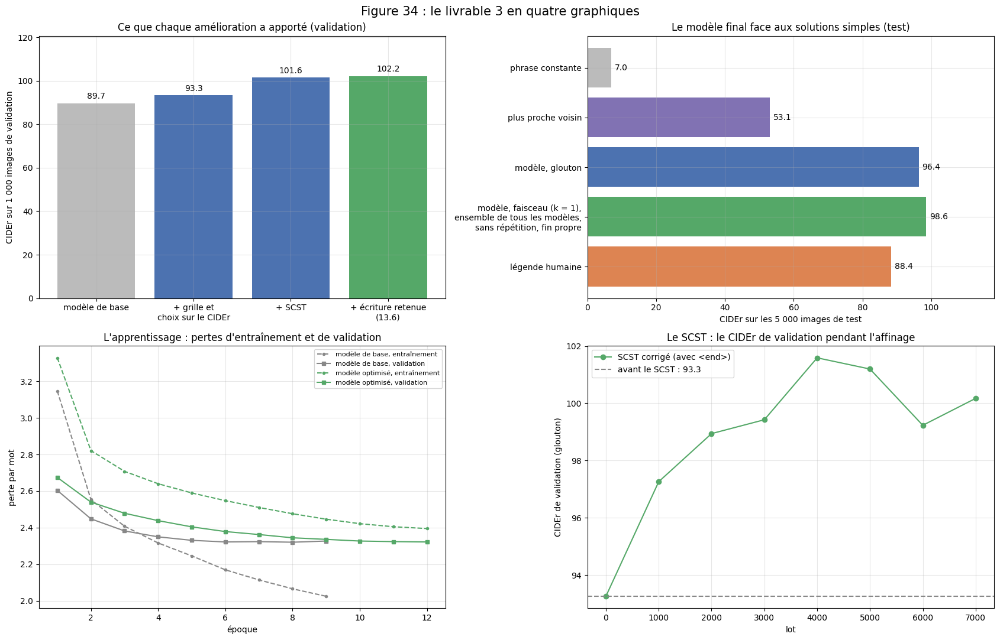

In [68]:
# Le livrable 3 en quatre graphiques
if "chrono_partie" in globals():
    chrono_partie("Conclusion")                       # chronomètre : début de la partie
fig, axes = plt.subplots(2, 2, figsize=(17, 11))

ax = axes[0, 0]                                                     # les améliorations, étape par étape
etapes = {}
if "CIDER_BASE" in globals():
    etapes["modèle de base"] = CIDER_BASE
if "CIDER_OPT" in globals():
    etapes["+ grille et\nchoix sur le CIDEr"] = CIDER_OPT
if "ETAT" in globals() and ETAT["meilleur"] > globals().get("CIDER_AVANT", 1e9):
    etapes["+ SCST"] = ETAT["meilleur"]
if "CHOIX_ECRITURE" in globals():
    etapes["+ écriture retenue\n(13.6)"] = CHOIX_ECRITURE["CIDEr"]
if etapes:
    barres = ax.bar(list(etapes), list(etapes.values()), color=["#BBBBBB"] + ["#4C72B0"] * (len(etapes) - 2) + ["#55A868"])
    ax.bar_label(barres, fmt="%.1f", padding=3); ax.set_ylim(0, 1.18 * max(etapes.values()))
    ax.set_ylabel("CIDEr sur 1 000 images de validation")
ax.set_title("Ce que chaque amélioration a apporté (validation)")

ax = axes[0, 1]                                                     # le test
if "RESULTATS" in globals():
    ordre = list(RESULTATS.index)
    couleurs = ["#BBBBBB", "#8172B3", "#4C72B0", "#55A868", "#DD8452"][:len(ordre)]
    barres = ax.barh([couper(m, 30) for m in ordre], RESULTATS["CIDEr"], color=couleurs)
    ax.bar_label(barres, fmt="%.1f", padding=4); ax.invert_yaxis(); ax.set_xlim(0, 1.2 * RESULTATS["CIDEr"].max())
    ax.set_xlabel("CIDEr sur les 5 000 images de test")
ax.set_title("Le modèle final face aux solutions simples (test)")

ax = axes[1, 0]                                                     # l'apprentissage
for h, nom, coul in ((globals().get("HIST_BASE"), "modèle de base", "#888888"), (globals().get("HIST_OPT"), "modèle optimisé", "#55A868")):
    if h and h.get("val"):
        e = range(1, len(h["val"]) + 1)
        ax.plot(e, h["train"], color=coul, ls="--", marker="o", ms=3, label=f"{nom}, entraînement")
        ax.plot(e, h["val"], color=coul, marker="s", ms=4, label=f"{nom}, validation")
ax.set_xlabel("époque"); ax.set_ylabel("perte par mot"); ax.legend(fontsize=8)
ax.set_title("L'apprentissage : pertes d'entraînement et de validation")

ax = axes[1, 1]                                                     # le SCST
if "ETAT" in globals():
    lots, ciders = zip(*ETAT["evals"])
    ax.plot(lots, ciders, marker="o", color="#55A868", label="SCST corrigé (avec <end>)")
    ax.axhline(ETAT["evals"][0][1], color="#888888", ls="--", label=f"avant le SCST : {ETAT['evals'][0][1]:.1f}")
    ax.set_xlabel("lot"); ax.set_ylabel("CIDEr de validation (glouton)"); ax.legend()
ax.set_title("Le SCST : le CIDEr de validation pendant l'affinage")
for ax in axes.ravel():
    ax.grid(alpha=0.3)
plt.suptitle("Figure 34 : le livrable 3 en quatre graphiques", fontsize=15)
plt.tight_layout(); plt.show()

Les quatre graphiques résument le livrable 3. En haut à gauche, le chemin parcouru sur la validation : chaque amélioration (réglage par grille et choix de l'époque sur le CIDEr, puis SCST, puis façon d'écrire) a été mesurée sur les mêmes 1 000 images, et n'a été gardée que si elle faisait mieux. En haut à droite, le résultat final sur le test, que le modèle n'a jamais vu, face aux solutions simples. En bas, les deux étapes d'apprentissage : l'entraînement classique, où la perte de validation cesse de baisser quand le modèle commence à apprendre par cœur, puis l'affinage par SCST, qui fait monter le CIDEr directement.

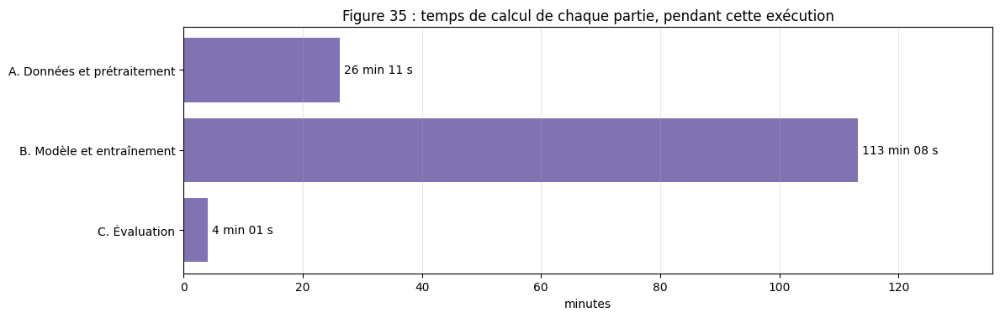

Durée totale de l'exécution : 143 min 21 s


In [69]:
# Temps de calcul de chaque partie, pendant cette exécution
if "CHRONO" in globals() and CHRONO["durees"]:
    durees = {k: v for k, v in CHRONO["durees"].items() if v >= 1}
    fig, ax = plt.subplots(figsize=(12, 0.7 * len(durees) + 1.8))
    barres = ax.barh(list(durees), [v / 60 for v in durees.values()], color="#8172B3")
    ax.bar_label(barres, labels=[duree_lisible(v) for v in durees.values()], padding=4)
    ax.invert_yaxis(); ax.set_xlabel("minutes"); ax.grid(alpha=0.3, axis="x")
    ax.set_xlim(0, 1.2 * max(durees.values()) / 60)
    ax.set_title("Figure 35 : temps de calcul de chaque partie, pendant cette exécution")
    plt.tight_layout(); plt.show()
    print(f"Durée totale de l'exécution : {duree_lisible(sum(CHRONO['durees'].values()))}")
else:
    print("Le chronomètre n'a pas été lancé (cellule de l'introduction).")

L'essentiel du temps d'une première exécution part dans les entraînements de la partie B : environ 75 minutes pour le modèle de base, 50 minutes pour la recherche par grille, 55 minutes pour le modèle optimisé et 10 minutes pour le SCST. Tout est enregistré sur le Drive au fur et à mesure : cette exécution-ci a relu les modèles déjà entraînés, avec l'historique complet de leurs époques, et n'a refait que le SCST corrigé et la partie C, en 27 minutes. Les traces détaillées des entraînements, lot par lot, sont dans l'exécution précédente du notebook, jointe en annexe (`Annexe_trace_entrainement.ipynb`).

### Limites, regard critique et pistes

**Ce qui limite la qualité des légendes.** Le CNN est gelé et sa grille de 8 × 8 régions est trop grossière pour les petits objets. Le modèle se rabat sur les scènes les plus fréquentes de COCO quand l'image est inhabituelle, et il ne voit pas mieux après le SCST : il écrit mieux, mais ses erreurs de reconnaissance restent les mêmes. Il écrit de façon très uniforme et accentue le biais de genre des données, deux défauts que le SCST renforce. Le surapprentissage n'a pas été réduit par la recherche par grille ; il a été contourné en choisissant l'époque sur le CIDEr.

**Ce qui limite l'évaluation.** Les mesures automatiques comparent des mots, pas du sens : une légende juste mais formulée autrement est pénalisée (l'avion militaire de la section 14.4), et le score « supérieur à l'humain » est un artefact de la mesure. Les gains du faisceau et de l'ensemble, d'environ un point chacun, sont proches du bruit de mesure sur 1 000 images de validation. METEOR n'a pas pu être calculé. Surtout, tout a été mesuré sur COCO, très différent des archives d'un client.

**Ce qui limite le pipeline.** Chaque livrable a été entraîné séparément, sur ses propres données : l'enchaînement n'est pas optimisé de bout en bout, et les erreurs du tri se propagent. Le débruiteur a appris sur un bruit gaussien, alors que le bruit réel des photos du livrable 2 est d'une autre nature.

**Les pistes, de la plus simple à la plus ambitieuse.** Remplacer *man* et *woman* par *person* quand le modèle hésite ; ajouter au SCST une récompense de diversité, pour retrouver une partie du vocabulaire perdu ; entraîner le débruiteur avec des bruits plus variés (compression JPEG, flou, bruit de capteur) ; évaluer toute la chaîne sur quelques centaines de photos du client légendées à la main ; enfin, remplacer la grille d'InceptionV3 par des caractéristiques par objet ou par un encodeur plus récent, et le LSTM par un décodeur Transformer : c'est aujourd'hui la principale source de gain restante (environ 120 à 135 de CIDEr dans la littérature).